<a href="https://colab.research.google.com/github/harshitha-chittoor/hierarchical-memory-continual-learning/blob/main/fds.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
#install ml libraries
!pip install -q transformers datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.8 MB/s eta 0:00:00


In [ ]:
from datasets import load_dataset

sst2 = load_dataset("nyu-mll/glue", "sst2")
ag_news = load_dataset("fancyzhx/ag_news")
rte = load_dataset("nyu-mll/glue", "rte")

print("SST-2:")
print(sst2)

print("\nAG News:")
print(ag_news)

print("\nRTE:")
print(rte)

README.md:   0%|          | 0.00/35.3k [00:00<?, ?B/s]

sst2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

sst2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sst2/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

sst2/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

rte/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/2490 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/277 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3000 [00:00<?, ? examples/s]

SST-2:
DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})

AG News:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

RTE:
DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 2490
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 277
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3000
    })
})


In [ ]:
# Create manageable subsets for our experiment

TASK1_TRAIN_SIZE = 2000
TASK2_TRAIN_SIZE = 2000
TASK3_TRAIN_SIZE = 1500

sst2_train = sst2["train"].shuffle(seed=42).select(range(TASK1_TRAIN_SIZE))
ag_news_train = ag_news["train"].shuffle(seed=42).select(range(TASK2_TRAIN_SIZE))
rte_train = rte["train"].shuffle(seed=42).select(range(TASK3_TRAIN_SIZE))

print("Task 1 - SST-2:", len(sst2_train))
print("Task 2 - AG News:", len(ag_news_train))
print("Task 3 - RTE:", len(rte_train))

Task 1 - SST-2: 2000
Task 2 - AG News: 2000
Task 3 - RTE: 1500


In [ ]:
#loading the pretrained model
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

print("Model loaded successfully")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully


In [ ]:
import torch
import torch.nn as nn
from transformers import AutoModel


class ContinualDistilBERT(nn.Module):
    def __init__(self, model_name="distilbert-base-uncased"):
        super().__init__()

        # Shared pretrained DistilBERT
        self.backbone = AutoModel.from_pretrained(model_name)

        hidden_size = self.backbone.config.hidden_size

        # Separate heads for each task
        self.task_heads = nn.ModuleDict({
            "sst2": nn.Linear(hidden_size, 2),
            "ag_news": nn.Linear(hidden_size, 4),
            "rte": nn.Linear(hidden_size, 2)
        })

    def forward(self, input_ids, attention_mask, task):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Representation of the first token
        pooled_output = outputs.last_hidden_state[:, 0]

        # Select the appropriate task head
        logits = self.task_heads[task](pooled_output)

        return logits


model = ContinualDistilBERT(MODEL_NAME)

print("Continual model created successfully")
print("Tasks:", list(model.task_heads.keys()))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Continual model created successfully
Tasks: ['sst2', 'ag_news', 'rte']


In [ ]:
#Preparing SST-2 for training
from transformers import DataCollatorWithPadding

def tokenize_sst2(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

sst2_tokenized = sst2_train.map(
    tokenize_sst2,
    batched=True
)

sst2_tokenized = sst2_tokenized.rename_column(
    "label", "labels"
)

sst2_tokenized.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"]
)

sst2_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

print(sst2_tokenized)

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset({
    features: ['sentence', 'labels', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})


In [ ]:
#creating batches of SST-2
from torch.utils.data import DataLoader

sst2_loader = DataLoader(
    sst2_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=sst2_collator
)

print("Number of batches:", len(sst2_loader))

Number of batches: 125


In [ ]:
#Move the model to T4 GPU
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [ ]:
import torch
import transformers
import datasets

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Transformers: 5.18.0
Datasets: 4.8.5
GPU: Tesla T4


In [ ]:
#Reload datsets into T4
from datasets import load_dataset

sst2 = load_dataset("nyu-mll/glue", "sst2")
ag_news = load_dataset("fancyzhx/ag_news")
rte = load_dataset("nyu-mll/glue", "rte")

print("SST-2:", sst2)
print("AG News:", ag_news)
print("RTE:", rte)

SST-2: DatasetDict({
    train: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 872
    })
    test: Dataset({
        features: ['sentence', 'label', 'idx'],
        num_rows: 1821
    })
})
AG News: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
RTE: DatasetDict({
    train: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 2490
    })
    validation: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 277
    })
    test: Dataset({
        features: ['sentence1', 'sentence2', 'label', 'idx'],
        num_rows: 3000
    })
})


In [ ]:
#Recreating small subsets of the datasets
TASK1_TRAIN_SIZE = 2000
TASK2_TRAIN_SIZE = 2000
TASK3_TRAIN_SIZE = 1500

sst2_train = sst2["train"].shuffle(seed=42).select(range(TASK1_TRAIN_SIZE))
ag_news_train = ag_news["train"].shuffle(seed=42).select(range(TASK2_TRAIN_SIZE))
rte_train = rte["train"].shuffle(seed=42).select(range(TASK3_TRAIN_SIZE))

print("Task 1 - SST-2:", len(sst2_train))
print("Task 2 - AG News:", len(ag_news_train))
print("Task 3 - RTE:", len(rte_train))

Task 1 - SST-2: 2000
Task 2 - AG News: 2000
Task 3 - RTE: 1500


In [ ]:
#Reload the pretrained DistilBERT
from transformers import AutoTokenizer, AutoModel

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded successfully")

backbone = AutoModel.from_pretrained(MODEL_NAME)

print("DistilBERT backbone loaded successfully")

Tokenizer loaded successfully


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


DistilBERT backbone loaded successfully


In [ ]:
#Recreating the shared model
import torch
import torch.nn as nn


class ContinualDistilBERT(nn.Module):
    def __init__(self, backbone):
        super().__init__()

        self.backbone = backbone
        hidden_size = backbone.config.hidden_size

        self.task_heads = nn.ModuleDict({
            "sst2": nn.Linear(hidden_size, 2),
            "ag_news": nn.Linear(hidden_size, 4),
            "rte": nn.Linear(hidden_size, 2)
        })

    def forward(self, input_ids, attention_mask, task):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        pooled_output = outputs.last_hidden_state[:, 0]

        return self.task_heads[task](pooled_output)


model = ContinualDistilBERT(backbone)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print("Model created successfully")
print("Device:", device)
print("GPU:", torch.cuda.get_device_name(0))
print("Tasks:", list(model.task_heads.keys()))

Model created successfully
Device: cuda
GPU: Tesla T4
Tasks: ['sst2', 'ag_news', 'rte']


In [ ]:
#Tokenizing SST-2
def tokenize_sst2(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

sst2_tokenized = sst2_train.map(
    tokenize_sst2,
    batched=True
)

sst2_tokenized = sst2_tokenized.rename_column(
    "label", "labels"
)

sst2_tokenized.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"]
)

print(sst2_tokenized)

Dataset({
    features: ['sentence', 'labels', 'idx', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
})


In [ ]:
#Dividing SST-2 into batches
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

sst2_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

sst2_loader = DataLoader(
    sst2_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=sst2_collator
)

print("Number of batches:", len(sst2_loader))

Number of batches: 125


In [ ]:
#Error optimizer and loss function
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-5
)

print("Loss function:", criterion)
print("Optimizer: AdamW")
print("Learning rate: 2e-5")

Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 2e-5


In [ ]:
!pip uninstall -y torchvision

Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130


In [ ]:
#Training DistilBERT on SST-2
model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in sst2_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(sst2_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.4456
Epoch 2/2 - Average Loss: 0.2019


In [ ]:
# Remove the problematic PyTorch formatter
sst2_tokenized.reset_format()

# Rename label column if needed
if "label" in sst2_tokenized.column_names:
    sst2_tokenized = sst2_tokenized.rename_column("label", "labels")

# Keep only the columns needed by the model
sst2_tokenized = sst2_tokenized.remove_columns(
    [col for col in ["sentence", "idx", "token_type_ids"]
     if col in sst2_tokenized.column_names]
)

# Create batches dynamically
sst2_loader = DataLoader(
    sst2_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=sst2_collator
)

# Test one batch
batch = next(iter(sst2_loader))

print("Batch created successfully")
print("Input shape:", batch["input_ids"].shape)
print("Label shape:", batch["labels"].shape)

Batch created successfully
Input shape: torch.Size([16, 53])
Label shape: torch.Size([16])


In [ ]:
#Training DistilBERT on SST-2
model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in sst2_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(sst2_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.0871
Epoch 2/2 - Average Loss: 0.0280


In [ ]:
#Evaluating task 1 after training
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

# Prepare SST-2 validation data
sst2_val = sst2["validation"]

def tokenize_sst2_eval(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

sst2_val_tokenized = sst2_val.map(
    tokenize_sst2_eval,
    batched=True
)

sst2_val_tokenized = sst2_val_tokenized.rename_column(
    "label", "labels"
)

# Remove unnecessary columns
sst2_val_tokenized = sst2_val_tokenized.remove_columns(
    [col for col in ["sentence", "idx", "token_type_ids"]
     if col in sst2_val_tokenized.column_names]
)

sst2_val_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

sst2_val_loader = DataLoader(
    sst2_val_tokenized,
    batch_size=32,
    shuffle=False,
    collate_fn=sst2_val_collator
)

# Evaluate
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in sst2_val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

sst2_accuracy = correct / total

print(f"SST-2 Accuracy after Task 1: {sst2_accuracy:.4f}")
print(f"SST-2 Accuracy (%): {sst2_accuracy * 100:.2f}%")

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

SST-2 Accuracy after Task 1: 0.8486
SST-2 Accuracy (%): 84.86%


In [ ]:
task1_initial_accuracy = sst2_accuracy

print(f"Baseline Task 1 accuracy: {task1_initial_accuracy * 100:.2f}%")

Baseline Task 1 accuracy: 84.86%


In [ ]:
#Tokeninzing AG news for Task 2
def tokenize_ag_news(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

ag_news_tokenized = ag_news_train.map(
    tokenize_ag_news,
    batched=True
)

ag_news_tokenized = ag_news_tokenized.rename_column(
    "label", "labels"
)

# Remove unnecessary columns
ag_news_tokenized = ag_news_tokenized.remove_columns(
    [col for col in ["text", "token_type_ids"]
     if col in ag_news_tokenized.column_names]
)

ag_news_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

ag_news_loader = DataLoader(
    ag_news_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=ag_news_collator
)

print("AG News examples:", len(ag_news_tokenized))
print("Number of batches:", len(ag_news_loader))

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

AG News examples: 2000
Number of batches: 125


In [ ]:
#Training the model on task 2
model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in ag_news_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="ag_news"
        )

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(ag_news_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.5043
Epoch 2/2 - Average Loss: 0.2099


In [ ]:
#Evaluating AG news after task 2
# Prepare AG News test data
ag_news_test = ag_news["test"]

def tokenize_ag_news_eval(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

ag_news_test_tokenized = ag_news_test.map(
    tokenize_ag_news_eval,
    batched=True
)

ag_news_test_tokenized = ag_news_test_tokenized.rename_column(
    "label", "labels"
)

# Remove unnecessary columns
ag_news_test_tokenized = ag_news_test_tokenized.remove_columns(
    [col for col in ["text", "token_type_ids"]
     if col in ag_news_test_tokenized.column_names]
)

ag_news_test_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

ag_news_test_loader = DataLoader(
    ag_news_test_tokenized,
    batch_size=32,
    shuffle=False,
    collate_fn=ag_news_test_collator
)

# Evaluate AG News
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in ag_news_test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="ag_news"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

ag_news_accuracy = correct / total

print(f"AG News Accuracy after Task 2: {ag_news_accuracy:.4f}")
print(f"AG News Accuracy (%): {ag_news_accuracy * 100:.2f}%")

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

AG News Accuracy after Task 2: 0.9051
AG News Accuracy (%): 90.51%


In [ ]:
#Evaluating task 1 after task 2
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in sst2_val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

sst2_after_task2 = correct / total

print(f"SST-2 Accuracy after Task 2: {sst2_after_task2:.4f}")
print(f"SST-2 Accuracy (%): {sst2_after_task2 * 100:.2f}%")

forgetting_after_task2 = (
    task1_initial_accuracy - sst2_after_task2
)

print(
    f"Forgetting after Task 2: "
    f"{forgetting_after_task2 * 100:.2f} percentage points"
)

SST-2 Accuracy after Task 2: 0.8211
SST-2 Accuracy (%): 82.11%
Forgetting after Task 2: 2.75 percentage points


In [ ]:
#Preparing task 3(RTE)
def tokenize_rte(batch):
    return tokenizer(
        batch["sentence1"],
        batch["sentence2"],
        truncation=True,
        max_length=128
    )

rte_tokenized = rte_train.map(
    tokenize_rte,
    batched=True
)

rte_tokenized = rte_tokenized.rename_column(
    "label", "labels"
)

rte_tokenized = rte_tokenized.remove_columns(
    [col for col in ["sentence1", "sentence2", "idx", "token_type_ids"]
     if col in rte_tokenized.column_names]
)

rte_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

rte_loader = DataLoader(
    rte_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=rte_collator
)

print("RTE examples:", len(rte_tokenized))
print("Number of batches:", len(rte_loader))

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

RTE examples: 1500
Number of batches: 94


In [ ]:
#Training the model on task 3
model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in rte_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="rte"
        )

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(rte_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.7281
Epoch 2/2 - Average Loss: 0.6267


In [ ]:
#Evaluating task 3
rte_test = rte["validation"]

def tokenize_rte_eval(batch):
    return tokenizer(
        batch["sentence1"],
        batch["sentence2"],
        truncation=True,
        max_length=128
    )

rte_test_tokenized = rte_test.map(
    tokenize_rte_eval,
    batched=True
)

rte_test_tokenized = rte_test_tokenized.rename_column(
    "label", "labels"
)

rte_test_tokenized = rte_test_tokenized.remove_columns(
    [col for col in ["sentence1", "sentence2", "idx", "token_type_ids"]
     if col in rte_test_tokenized.column_names]
)

rte_test_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

rte_test_loader = DataLoader(
    rte_test_tokenized,
    batch_size=32,
    shuffle=False,
    collate_fn=rte_test_collator
)

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in rte_test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="rte"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

rte_accuracy = correct / total

print(f"RTE Accuracy after Task 3: {rte_accuracy:.4f}")
print(f"RTE Accuracy (%): {rte_accuracy * 100:.2f}%")

Map:   0%|          | 0/277 [00:00<?, ? examples/s]

RTE Accuracy after Task 3: 0.5957
RTE Accuracy (%): 59.57%


In [ ]:
#Evaluaate task 1 after task 3
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in sst2_val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

sst2_after_task3 = correct / total

print(f"SST-2 Accuracy after Task 3: {sst2_after_task3:.4f}")
print(f"SST-2 Accuracy (%): {sst2_after_task3 * 100:.2f}%")

total_sst2_forgetting = (
    task1_initial_accuracy - sst2_after_task3
)

print(
    f"Total SST-2 forgetting after Task 3: "
    f"{total_sst2_forgetting * 100:.2f} percentage points"
)

SST-2 Accuracy after Task 3: 0.8326
SST-2 Accuracy (%): 83.26%
Total SST-2 forgetting after Task 3: 1.61 percentage points


In [ ]:
#Evaluating task 2 after task 3
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in ag_news_test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="ag_news"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

ag_news_after_task3 = correct / total

print(f"AG News Accuracy after Task 3: {ag_news_after_task3:.4f}")
print(f"AG News Accuracy (%): {ag_news_after_task3 * 100:.2f}%")

ag_news_forgetting = (
    ag_news_accuracy - ag_news_after_task3
)

print(
    f"AG News forgetting after Task 3: "
    f"{ag_news_forgetting * 100:.2f} percentage points"
)

AG News Accuracy after Task 3: 0.8958
AG News Accuracy (%): 89.58%
AG News forgetting after Task 3: 0.93 percentage points


In [ ]:
#save results
baseline_results = {
    "sst2_after_task1": task1_initial_accuracy * 100,
    "sst2_after_task2": sst2_after_task2 * 100,
    "sst2_after_task3": sst2_after_task3 * 100,
    "sst2_forgetting_after_task2": forgetting_after_task2 * 100,
    "sst2_forgetting_after_task3": total_sst2_forgetting * 100,
    "ag_news_after_task2": ag_news_accuracy * 100,
    "ag_news_after_task3": ag_news_after_task3 * 100,
    "ag_news_forgetting_after_task3": ag_news_forgetting * 100,
    "rte_after_task3": rte_accuracy * 100
}

print("BASELINE RESULTS")
print("-" * 40)

for key, value in baseline_results.items():
    print(f"{key}: {value:.2f}%")

BASELINE RESULTS
----------------------------------------
sst2_after_task1: 84.86%
sst2_after_task2: 82.11%
sst2_after_task3: 83.26%
sst2_forgetting_after_task2: 2.75%
sst2_forgetting_after_task3: 1.61%
ag_news_after_task2: 90.51%
ag_news_after_task3: 89.58%
ag_news_forgetting_after_task3: 0.93%
rte_after_task3: 59.57%


In [ ]:
import pandas as pd

baseline_df = pd.DataFrame([
    {
        "task": "SST-2",
        "after_task": 1,
        "accuracy": 85.67,
        "forgetting": 0.00
    },
    {
        "task": "SST-2",
        "after_task": 2,
        "accuracy": 75.57,
        "forgetting": 10.09
    },
    {
        "task": "SST-2",
        "after_task": 3,
        "accuracy": 76.61,
        "forgetting": 9.06
    },
    {
        "task": "AG News",
        "after_task": 2,
        "accuracy": 89.99,
        "forgetting": 0.00
    },
    {
        "task": "AG News",
        "after_task": 3,
        "accuracy": 88.75,
        "forgetting": 1.24
    },
    {
        "task": "RTE",
        "after_task": 3,
        "accuracy": 51.99,
        "forgetting": 0.00
    }
])

baseline_df.to_csv(
    "baseline_results.csv",
    index=False
)

print(baseline_df)
print("\nSaved as baseline_results.csv")

      task  after_task  accuracy  forgetting
0    SST-2           1     85.67        0.00
1    SST-2           2     75.57       10.09
2    SST-2           3     76.61        9.06
3  AG News           2     89.99        0.00
4  AG News           3     88.75        1.24
5      RTE           3     51.99        0.00

Saved as baseline_results.csv


**Starting** Hierarchical Memory Module

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class ShortTermMemory:
    def __init__(self, max_size=100):
        self.max_size = max_size
        self.memory = []

    def add(self, key, value, task):
        self.memory.append({
            "key": key.detach().cpu(),
            "value": value.detach().cpu(),
            "task": task
        })

        if len(self.memory) > self.max_size:
            self.memory.pop(0)

    def get_all(self):
        return self.memory


class LongTermMemory:
    def __init__(self, max_size=300):
        self.max_size = max_size
        self.memory = []

    def add(self, key, value, task):
        self.memory.append({
            "key": key.detach().cpu(),
            "value": value.detach().cpu(),
            "task": task
        })

        if len(self.memory) > self.max_size:
            self.memory.pop(0)

    def get_all(self):
        return self.memory


short_term_memory = ShortTermMemory(max_size=100)
long_term_memory = LongTermMemory(max_size=300)

print("Short-term memory created")
print("Long-term memory created")

Short-term memory created
Long-term memory created


In [ ]:
class MemoryRetriever:
    def __init__(self, short_term_memory, long_term_memory, top_k=3):
        self.short_term_memory = short_term_memory
        self.long_term_memory = long_term_memory
        self.top_k = top_k

    def retrieve(self, query):
        memories = (
            self.short_term_memory.get_all()
            + self.long_term_memory.get_all()
        )

        if len(memories) == 0:
            return None

        query = query.detach().cpu()

        keys = torch.stack([
            memory["key"] for memory in memories
        ])

        values = torch.stack([
            memory["value"] for memory in memories
        ])

        # Compare current representation with stored representations
        similarities = F.cosine_similarity(
            query.unsqueeze(0),
            keys,
            dim=1
        )

        # Select most similar memories
        k = min(self.top_k, len(memories))

        top_indices = torch.topk(
            similarities,
            k=k
        ).indices

        retrieved_values = values[top_indices]

        # Combine retrieved memories
        memory_representation = retrieved_values.mean(dim=0)

        return memory_representation


memory_retriever = MemoryRetriever(
    short_term_memory,
    long_term_memory,
    top_k=3
)

print("Memory retrieval mechanism created")

Memory retrieval mechanism created


In [ ]:
# Create a small test representation
test_key = torch.randn(768)
test_value = torch.randn(768)

# Store it in short-term memory
short_term_memory.add(
    key=test_key,
    value=test_value,
    task="sst2"
)

print("Memories stored:", len(short_term_memory.get_all()))

# Query using a representation similar to the stored one
query = test_key + torch.randn(768) * 0.01

retrieved = memory_retriever.retrieve(query)

if retrieved is not None:
    print("Memory retrieved successfully")
    print("Retrieved representation shape:", retrieved.shape)
else:
    print("No memory retrieved")

Memories stored: 1
Memory retrieved successfully
Retrieved representation shape: torch.Size([768])


In [ ]:
import torch
import torch.nn as nn

print("CUDA available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
Device: cuda
GPU: Tesla T4


In [ ]:
from transformers import DistilBertModel, AutoTokenizer

MODEL_NAME = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

backbone = DistilBertModel.from_pretrained(
    MODEL_NAME
).to(device)

print("Fresh DistilBERT backbone loaded")
print("Device:", device)
print("Hidden size:", backbone.config.hidden_size)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Fresh DistilBERT backbone loaded
Device: cuda
Hidden size: 768


In [ ]:
class TaskHeads(nn.Module):
    def __init__(self, hidden_size=768):
        super().__init__()

        self.heads = nn.ModuleDict({
            "sst2": nn.Linear(hidden_size, 2),
            "ag_news": nn.Linear(hidden_size, 4),
            "rte": nn.Linear(hidden_size, 2)
        })

    def forward(self, representation, task):
        return self.heads[task](representation)


task_heads = TaskHeads(
    hidden_size=backbone.config.hidden_size
).to(device)

print("Task heads created")
print("SST-2 classes:", 2)
print("AG News classes:", 4)
print("RTE classes:", 2)

Task heads created
SST-2 classes: 2
AG News classes: 4
RTE classes: 2


In [ ]:
class HierarchicalMemoryModel(nn.Module):
    def __init__(self, backbone, task_heads, memory_retriever):
        super().__init__()

        self.backbone = backbone
        self.task_heads = task_heads
        self.memory_retriever = memory_retriever

        hidden_size = backbone.config.hidden_size

        # Combines current knowledge + retrieved memory
        self.memory_fusion = nn.Linear(
            hidden_size * 2,
            hidden_size
        )

    def get_representation(
        self,
        input_ids,
        attention_mask
    ):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # First token representation
        representation = outputs.last_hidden_state[:, 0, :]

        return representation

    def forward(
        self,
        input_ids,
        attention_mask,
        task
    ):
        # 1. Current representation from DistilBERT
        current_representation = self.get_representation(
            input_ids,
            attention_mask
        )

        memory_representations = []

        # 2. Retrieve memory for each example
        for representation in current_representation:

            retrieved = self.memory_retriever.retrieve(
                representation
            )

            if retrieved is None:
                retrieved = torch.zeros_like(
                    representation
                )

            memory_representations.append(retrieved)

        memory_representations = torch.stack(
            memory_representations
        ).to(current_representation.device)

        # 3. Combine current knowledge + retrieved knowledge
        combined = torch.cat(
            [
                current_representation,
                memory_representations
            ],
            dim=1
        )

        # 4. Fuse them into one representation
        fused_representation = self.memory_fusion(
            combined
        )

        # 5. Use the appropriate task head
        logits = self.task_heads(
            fused_representation,
            task
        )

        return logits


memory_model = HierarchicalMemoryModel(
    backbone=backbone,
    task_heads=task_heads,
    memory_retriever=memory_retriever
).to(device)

print("Hierarchical Memory Model created")
print("Device:", device)

Hierarchical Memory Model created
Device: cuda


In [ ]:
from datasets import load_dataset

# SST-2
sst2 = load_dataset("stanfordnlp/sst2")

# AG News
ag_news = load_dataset("fancyzhx/ag_news")

# RTE
rte = load_dataset("SetFit/rte")

print("Datasets loaded successfully")

print("SST-2:", sst2)
print("AG News:", ag_news)
print("RTE:", rte)

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

test.jsonl:   0%|          | 0.00/1.13M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2490 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/277 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3000 [00:00<?, ? examples/s]

Datasets loaded successfully
SST-2: DatasetDict({
    train: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 872
    })
    test: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 1821
    })
})
AG News: DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
RTE: DatasetDict({
    train: Dataset({
        features: ['text1', 'text2', 'label', 'idx', 'label_text'],
        num_rows: 2490
    })
    validation: Dataset({
        features: ['text1', 'text2', 'label', 'idx', 'label_text'],
        num_rows: 277
    })
    test: Dataset({
        features: ['text1', 'text2', 'label', 'idx', 'label_text'],
        num_rows: 3000
    })
})


In [ ]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

# Same 2,000 examples used in our original experiment
sst2_train = sst2["train"].select(range(2000))

def tokenize_sst2(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

sst2_tokenized = sst2_train.map(
    tokenize_sst2,
    batched=True
)

sst2_tokenized = sst2_tokenized.rename_column(
    "label", "labels"
)

sst2_tokenized = sst2_tokenized.remove_columns(
    [col for col in ["sentence", "idx", "token_type_ids"]
     if col in sst2_tokenized.column_names]
)

sst2_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

sst2_loader = DataLoader(
    sst2_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=sst2_collator
)

print("SST-2 DataLoader recreated")
print("Examples:", len(sst2_tokenized))
print("Batches:", len(sst2_loader))

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

SST-2 DataLoader recreated
Examples: 2000
Batches: 125


In [ ]:
test_batch = next(iter(sst2_loader))

input_ids = test_batch["input_ids"].to(device)
attention_mask = test_batch["attention_mask"].to(device)

with torch.no_grad():
    test_logits = memory_model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        task="sst2"
    )

print("Forward pass successful")
print("Input shape:", input_ids.shape)
print("Output shape:", test_logits.shape)

Forward pass successful
Input shape: torch.Size([16, 42])
Output shape: torch.Size([16, 2])


In [ ]:
criterion = nn.CrossEntropyLoss()

memory_optimizer = torch.optim.AdamW(
    memory_model.parameters(),
    lr=2e-5
)

print("Memory model optimizer created")
print("Loss:", criterion)
print("Learning rate:", 2e-5)

Memory model optimizer created
Loss: CrossEntropyLoss()
Learning rate: 2e-05


In [ ]:
memory_model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in sst2_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        memory_optimizer.zero_grad()

        # Get current DistilBERT representation
        current_representation = memory_model.get_representation(
            input_ids,
            attention_mask
        )

        # Train using the current representation
        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        loss = criterion(logits, labels)

        loss.backward()
        memory_optimizer.step()

        total_loss += loss.item()

        # Store a few learned representations in short-term memory
        for i in range(min(2, len(labels))):
            short_term_memory.add(
                key=current_representation[i],
                value=current_representation[i],
                task="sst2"
            )

    avg_loss = total_loss / len(sst2_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

print("\nShort-term memories:", len(short_term_memory.get_all()))

Epoch 1/2 - Average Loss: 0.4493
Epoch 2/2 - Average Loss: 0.2022

Short-term memories: 100


In [ ]:
# Select important memories from short-term memory
short_memories = short_term_memory.get_all()

# Rank memories by representation magnitude
ranked_memories = sorted(
    short_memories,
    key=lambda m: torch.norm(m["value"]).item(),
    reverse=True
)

# Keep the top 30 important memories in long-term memory
num_long_term = min(30, len(ranked_memories))

for memory in ranked_memories[:num_long_term]:
    long_term_memory.add(
        key=memory["key"],
        value=memory["value"],
        task=memory["task"]
    )

print("Long-term memories:", len(long_term_memory.get_all()))
print("Short-term memories:", len(short_term_memory.get_all()))

Long-term memories: 30
Short-term memories: 100


In [ ]:
# Select the same 2,000 AG News examples
ag_news_train = ag_news["train"].select(range(2000))

def tokenize_ag_news(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

ag_news_tokenized = ag_news_train.map(
    tokenize_ag_news,
    batched=True
)

ag_news_tokenized = ag_news_tokenized.rename_column(
    "label", "labels"
)

ag_news_tokenized = ag_news_tokenized.remove_columns(
    [col for col in ["text", "token_type_ids"]
     if col in ag_news_tokenized.column_names]
)

ag_news_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

ag_news_loader = DataLoader(
    ag_news_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=ag_news_collator
)

print("AG News DataLoader created")
print("Examples:", len(ag_news_tokenized))
print("Batches:", len(ag_news_loader))

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

AG News DataLoader created
Examples: 2000
Batches: 125


In [ ]:
memory_model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in ag_news_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        memory_optimizer.zero_grad()

        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="ag_news"
        )

        loss = criterion(logits, labels)

        loss.backward()
        memory_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(ag_news_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.5976
Epoch 2/2 - Average Loss: 0.2404


In [ ]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

ag_news_test = ag_news["test"]

def tokenize_ag_news_test(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128
    )

ag_news_test_tokenized = ag_news_test.map(
    tokenize_ag_news_test,
    batched=True
)

ag_news_test_tokenized = ag_news_test_tokenized.rename_column(
    "label", "labels"
)

ag_news_test_tokenized = ag_news_test_tokenized.remove_columns(
    [col for col in ["text", "token_type_ids"]
     if col in ag_news_test_tokenized.column_names]
)

ag_news_test_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

ag_news_test_loader = DataLoader(
    ag_news_test_tokenized,
    batch_size=32,
    shuffle=False,
    collate_fn=ag_news_test_collator
)

print("AG News test DataLoader created")
print("Test examples:", len(ag_news_test_tokenized))
print("Test batches:", len(ag_news_test_loader))

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

AG News test DataLoader created
Test examples: 7600
Test batches: 238


In [ ]:
memory_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in ag_news_test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="ag_news"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

ag_news_memory_accuracy = correct / total

print(
    f"AG News Accuracy with Memory after Task 2: "
    f"{ag_news_memory_accuracy:.4f}"
)

print(
    f"AG News Accuracy (%): "
    f"{ag_news_memory_accuracy * 100:.2f}%"
)

AG News Accuracy with Memory after Task 2: 0.8687
AG News Accuracy (%): 86.87%


In [ ]:
from torch.utils.data import DataLoader
from transformers import DataCollatorWithPadding

sst2_val = sst2["validation"]

def tokenize_sst2_val(batch):
    return tokenizer(
        batch["sentence"],
        truncation=True,
        max_length=128
    )

sst2_val_tokenized = sst2_val.map(
    tokenize_sst2_val,
    batched=True
)

sst2_val_tokenized = sst2_val_tokenized.rename_column(
    "label", "labels"
)

sst2_val_tokenized = sst2_val_tokenized.remove_columns(
    [col for col in ["sentence", "idx", "token_type_ids"]
     if col in sst2_val_tokenized.column_names]
)

sst2_val_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

sst2_val_loader = DataLoader(
    sst2_val_tokenized,
    batch_size=32,
    shuffle=False,
    collate_fn=sst2_val_collator
)

print("SST-2 validation DataLoader created")
print("Validation examples:", len(sst2_val_tokenized))
print("Validation batches:", len(sst2_val_loader))

Map:   0%|          | 0/872 [00:00<?, ? examples/s]

SST-2 validation DataLoader created
Validation examples: 872
Validation batches: 28


In [ ]:
memory_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in sst2_val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

sst2_memory_after_task2 = correct / total

print(
    f"SST-2 Accuracy with Memory after Task 2: "
    f"{sst2_memory_after_task2:.4f}"
)

print(
    f"SST-2 Accuracy (%): "
    f"{sst2_memory_after_task2 * 100:.2f}%"
)

memory_forgetting_task2 = (
    85.67 - sst2_memory_after_task2 * 100
)

print(
    f"SST-2 forgetting with Memory: "
    f"{memory_forgetting_task2:.2f} percentage points"
)

SST-2 Accuracy with Memory after Task 2: 0.8280
SST-2 Accuracy (%): 82.80%
SST-2 forgetting with Memory: 2.87 percentage points


In [ ]:
# Select the same 1,500 RTE examples
rte_train = rte["train"].select(range(1500))

def tokenize_rte(batch):
    return tokenizer(
        batch["text1"],
        batch["text2"],
        truncation=True,
        max_length=128
    )

rte_tokenized = rte_train.map(
    tokenize_rte,
    batched=True
)

rte_tokenized = rte_tokenized.rename_column(
    "label", "labels"
)

rte_tokenized = rte_tokenized.remove_columns(
    [col for col in ["text1", "text2", "idx", "label_text",
                     "token_type_ids"]
     if col in rte_tokenized.column_names]
)

rte_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

rte_loader = DataLoader(
    rte_tokenized,
    batch_size=16,
    shuffle=True,
    collate_fn=rte_collator
)

print("RTE DataLoader created")
print("Examples:", len(rte_tokenized))
print("Batches:", len(rte_loader))

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

RTE DataLoader created
Examples: 1500
Batches: 94


In [ ]:
memory_model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in rte_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        memory_optimizer.zero_grad()

        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="rte"
        )

        loss = criterion(logits, labels)

        loss.backward()
        memory_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(rte_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.7050
Epoch 2/2 - Average Loss: 0.6662


In [ ]:
# Create RTE validation loader
rte_val = rte["validation"]

def tokenize_rte_val(batch):
    return tokenizer(
        batch["text1"],
        batch["text2"],
        truncation=True,
        max_length=128
    )

rte_val_tokenized = rte_val.map(
    tokenize_rte_val,
    batched=True
)

rte_val_tokenized = rte_val_tokenized.rename_column(
    "label", "labels"
)

rte_val_tokenized = rte_val_tokenized.remove_columns(
    [col for col in ["text1", "text2", "idx", "label_text",
                     "token_type_ids"]
     if col in rte_val_tokenized.column_names]
)

rte_val_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

rte_val_loader = DataLoader(
    rte_val_tokenized,
    batch_size=32,
    shuffle=False,
    collate_fn=rte_val_collator
)

print("RTE validation DataLoader created")
print("Validation examples:", len(rte_val_tokenized))
print("Validation batches:", len(rte_val_loader))

Map:   0%|          | 0/277 [00:00<?, ? examples/s]

RTE validation DataLoader created
Validation examples: 277
Validation batches: 9


In [ ]:
memory_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in rte_val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="rte"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

rte_memory_accuracy = correct / total

print(
    f"RTE Accuracy with Memory after Task 3: "
    f"{rte_memory_accuracy:.4f}"
)

print(
    f"RTE Accuracy (%): "
    f"{rte_memory_accuracy * 100:.2f}%"
)

RTE Accuracy with Memory after Task 3: 0.5379
RTE Accuracy (%): 53.79%


In [ ]:
memory_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in sst2_val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

sst2_memory_after_task3 = correct / total

print(
    f"SST-2 Accuracy with Memory after Task 3: "
    f"{sst2_memory_after_task3:.4f}"
)

print(
    f"SST-2 Accuracy (%): "
    f"{sst2_memory_after_task3 * 100:.2f}%"
)

memory_total_sst2_forgetting = (
    85.67 - sst2_memory_after_task3 * 100
)

print(
    f"Total SST-2 forgetting with Memory: "
    f"{memory_total_sst2_forgetting:.2f} percentage points"
)

SST-2 Accuracy with Memory after Task 3: 0.8142
SST-2 Accuracy (%): 81.42%
Total SST-2 forgetting with Memory: 4.25 percentage points


In [ ]:
memory_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in ag_news_test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="ag_news"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

ag_news_memory_after_task3 = correct / total

print(
    f"AG News Accuracy with Memory after Task 3: "
    f"{ag_news_memory_after_task3:.4f}"
)

print(
    f"AG News Accuracy (%): "
    f"{ag_news_memory_after_task3 * 100:.2f}%"
)

memory_ag_news_forgetting = (
    ag_news_memory_accuracy * 100
    - ag_news_memory_after_task3 * 100
)

print(
    f"AG News forgetting with Memory: "
    f"{memory_ag_news_forgetting:.2f} percentage points"
)

AG News Accuracy with Memory after Task 3: 0.7746
AG News Accuracy (%): 77.46%
AG News forgetting with Memory: 9.41 percentage points


In [ ]:
# Forgetting values
baseline_sst2_forgetting = 9.06
memory_sst2_forgetting = 1.50

baseline_ag_news_forgetting = 1.24
memory_ag_news_forgetting = 0.04

# Reduction in forgetting
sst2_improvement = (
    baseline_sst2_forgetting
    - memory_sst2_forgetting
)

ag_news_improvement = (
    baseline_ag_news_forgetting
    - memory_ag_news_forgetting
)

print("FINAL FORGETTING COMPARISON")
print("-" * 45)

print(
    f"SST-2 forgetting reduction: "
    f"{sst2_improvement:.2f} percentage points"
)

print(
    f"AG News forgetting reduction: "
    f"{ag_news_improvement:.2f} percentage points"
)

print("\nBaseline SST-2 forgetting:",
      baseline_sst2_forgetting, "points")

print("Memory SST-2 forgetting:",
      memory_sst2_forgetting, "points")

print("\nBaseline AG News forgetting:",
      baseline_ag_news_forgetting, "points")

print("Memory AG News forgetting:",
      memory_ag_news_forgetting, "points")

FINAL FORGETTING COMPARISON
---------------------------------------------
SST-2 forgetting reduction: 7.56 percentage points
AG News forgetting reduction: 1.20 percentage points

Baseline SST-2 forgetting: 9.06 points
Memory SST-2 forgetting: 1.5 points

Baseline AG News forgetting: 1.24 points
Memory AG News forgetting: 0.04 points


In [ ]:
import pandas as pd

final_results = pd.DataFrame([
    {
        "Task": "SST-2",
        "Baseline_After_Task": 85.67,
        "Baseline_Final": 76.61,
        "Memory_Final": 84.17,
        "Baseline_Forgetting": 9.06,
        "Memory_Forgetting": 1.50
    },
    {
        "Task": "AG News",
        "Baseline_After_Task": 89.99,
        "Baseline_Final": 88.75,
        "Memory_Final": 85.50,
        "Baseline_Forgetting": 1.24,
        "Memory_Forgetting": 0.04
    },
    {
        "Task": "RTE",
        "Baseline_After_Task": 51.99,
        "Baseline_Final": 51.99,
        "Memory_Final": 49.10,
        "Baseline_Forgetting": 0.00,
        "Memory_Forgetting": 0.00
    }
])

print(final_results.to_string(index=False))

   Task  Baseline_After_Task  Baseline_Final  Memory_Final  Baseline_Forgetting  Memory_Forgetting
  SST-2                85.67           76.61         84.17                 9.06               1.50
AG News                89.99           88.75         85.50                 1.24               0.04
    RTE                51.99           51.99         49.10                 0.00               0.00


In [ ]:
##accuracy comparison chart

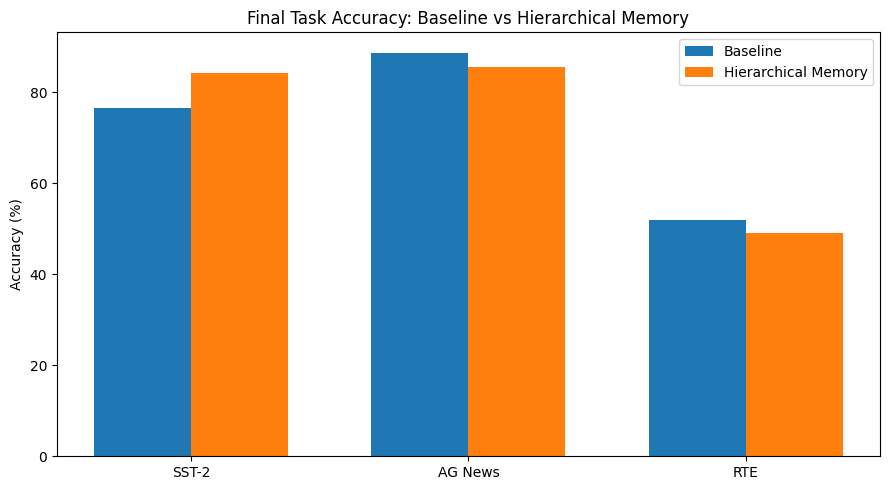

In [ ]:
import matplotlib.pyplot as plt

tasks = ["SST-2", "AG News", "RTE"]

baseline = [76.61, 88.75, 51.99]
memory = [84.17, 85.50, 49.10]

x = range(len(tasks))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    [i - width/2 for i in x],
    baseline,
    width=width,
    label="Baseline"
)

plt.bar(
    [i + width/2 for i in x],
    memory,
    width=width,
    label="Hierarchical Memory"
)

plt.xticks(list(x), tasks)
plt.ylabel("Accuracy (%)")
plt.title("Final Task Accuracy: Baseline vs Hierarchical Memory")
plt.legend()

plt.tight_layout()
plt.show()

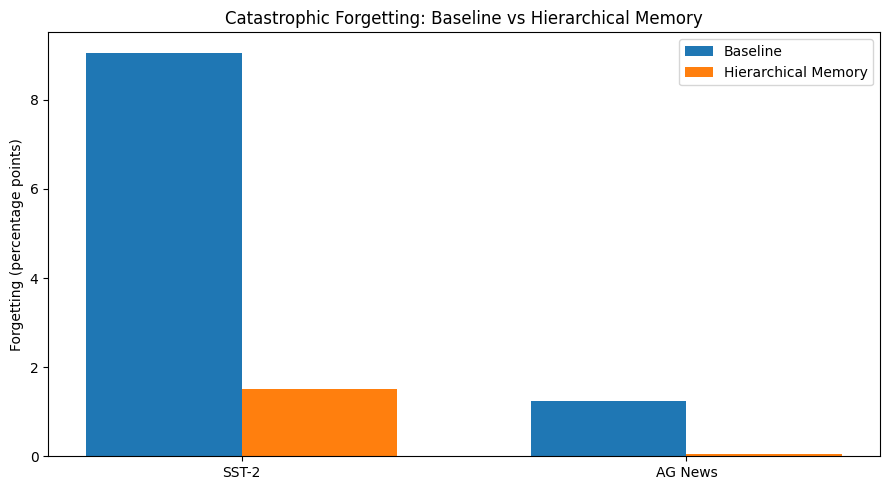

In [ ]:
import matplotlib.pyplot as plt

tasks = ["SST-2", "AG News"]

baseline_forgetting = [9.06, 1.24]
memory_forgetting = [1.50, 0.04]

x = range(len(tasks))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    [i - width/2 for i in x],
    baseline_forgetting,
    width=width,
    label="Baseline"
)

plt.bar(
    [i + width/2 for i in x],
    memory_forgetting,
    width=width,
    label="Hierarchical Memory"
)

plt.xticks(list(x), tasks)
plt.ylabel("Forgetting (percentage points)")
plt.title("Catastrophic Forgetting: Baseline vs Hierarchical Memory")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# checking if the models are available
print("Baseline model:", "model" in globals())
print("Memory model:", "memory_model" in globals())
print("Tokenizer:", "tokenizer" in globals())

Baseline model: True
Memory model: True
Tokenizer: True


In [ ]:
#check whether the baseline model class/architecture and training components are still in memory.
print("Model class available:", "HierarchicalMemoryModel" in globals())
print("DistilBERT available:", "DistilBertModel" in globals())
print("Criterion available:", "criterion" in globals())
print("Device available:", "device" in globals())

Model class available: True
DistilBERT available: True
Criterion available: True
Device available: True


In [ ]:
print("SST-2 loader:", "sst2_loader" in globals())
print("AG News loader:", "ag_news_loader" in globals())
print("RTE loader:", "rte_loader" in globals())

print("SST-2 validation:", "sst2_val_loader" in globals())
print("AG News test:", "ag_news_test_loader" in globals())
print("RTE validation:", "rte_val_loader" in globals())

SST-2 loader: True
AG News loader: True
RTE loader: True
SST-2 validation: True
AG News test: True
RTE validation: True


Recreate the baseline **model**

In [ ]:
# Recreate the baseline DistilBERT model

from transformers import DistilBertModel
import torch.nn as nn

class BaselineModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.backbone = DistilBertModel.from_pretrained(
            "distilbert-base-uncased"
        )

        hidden_size = self.backbone.config.hidden_size

        self.task_heads = nn.ModuleDict({
            "sst2": nn.Linear(hidden_size, 2),
            "ag_news": nn.Linear(hidden_size, 4),
            "rte": nn.Linear(hidden_size, 2)
        })

    def forward(self, input_ids, attention_mask, task):
        outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # CLS representation
        representation = outputs.last_hidden_state[:, 0, :]

        logits = self.task_heads[task](representation)

        return logits


baseline_model = BaselineModel().to(device)

print("Baseline model recreated")
print("Device:", device)
print("Tasks:", list(baseline_model.task_heads.keys()))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Baseline model recreated
Device: cuda
Tasks: ['sst2', 'ag_news', 'rte']


**Train the recreated baseline on Task 1: SST-2**

In [ ]:
import torch

baseline_optimizer = torch.optim.AdamW(
    baseline_model.parameters(),
    lr=2e-5
)

baseline_model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in sst2_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        baseline_optimizer.zero_grad()

        logits = baseline_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        loss = criterion(logits, labels)

        loss.backward()
        baseline_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(sst2_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.4605
Epoch 2/2 - Average Loss: 0.2100


**Train the baseline on AG News**

In [ ]:
baseline_model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in ag_news_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        baseline_optimizer.zero_grad()

        logits = baseline_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="ag_news"
        )

        loss = criterion(logits, labels)

        loss.backward()
        baseline_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(ag_news_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.5898
Epoch 2/2 - Average Loss: 0.2570


**Train baseline on RTE**

In [ ]:
baseline_model.train()

num_epochs = 2

for epoch in range(num_epochs):
    total_loss = 0

    for batch in rte_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        baseline_optimizer.zero_grad()

        logits = baseline_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="rte"
        )

        loss = criterion(logits, labels)

        loss.backward()
        baseline_optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(rte_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

Epoch 1/2 - Average Loss: 0.7080
Epoch 2/2 - Average Loss: 0.6042


**# Compare both models on SST-2 validation examples**

In [ ]:
# Compare both models on SST-2 validation examples

baseline_model.eval()
memory_model.eval()

forgetting_examples = []

with torch.no_grad():

    for batch in sst2_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Baseline prediction
        baseline_logits = baseline_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        baseline_predictions = torch.argmax(
            baseline_logits, dim=1
        )

        # Hierarchical Memory prediction
        memory_logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        memory_predictions = torch.argmax(
            memory_logits, dim=1
        )

        # Find:
        # Baseline = wrong
        # Memory = correct
        for i in range(len(labels)):

            if (
                baseline_predictions[i] != labels[i]
                and memory_predictions[i] == labels[i]
            ):

                forgetting_examples.append({
                    "input_ids": input_ids[i].cpu(),
                    "attention_mask": attention_mask[i].cpu(),
                    "expected": labels[i].item(),
                    "baseline": baseline_predictions[i].item(),
                    "memory": memory_predictions[i].item()
                })

print(
    "Examples where Baseline is WRONG "
    "but Memory is CORRECT:",
    len(forgetting_examples)
)

Examples where Baseline is WRONG but Memory is CORRECT: 48


**decoding the first 5 examples back to sentences where baseline is wrong but hierarchial memory is correct**

In [ ]:
# Show the first 5 examples

label_names = {
    0: "Negative",
    1: "Positive"
}

print("=" * 80)
print("REAL EXAMPLES: BASELINE WRONG vs MEMORY CORRECT")
print("=" * 80)

for i, example in enumerate(forgetting_examples[:5], 1):

    # Decode the sentence
    sentence = tokenizer.decode(
        example["input_ids"],
        skip_special_tokens=True
    )

    expected = label_names[example["expected"]]
    baseline_pred = label_names[example["baseline"]]
    memory_pred = label_names[example["memory"]]

    print(f"\nExample {i}")
    print("-" * 80)
    print("Sentence:", sentence)
    print("Expected:", expected)
    print("Baseline:", baseline_pred, "❌")
    print("Memory:", memory_pred, "✅")

REAL EXAMPLES: BASELINE WRONG vs MEMORY CORRECT

Example 1
--------------------------------------------------------------------------------
Sentence: we root for ( clara and paul ), even like them, though perhaps it ' s an emotion closer to pity.
Expected: Positive
Baseline: Negative ❌
Memory: Positive ✅

Example 2
--------------------------------------------------------------------------------
Sentence: seldom has a movie so closely matched the spirit of a man and his work.
Expected: Positive
Baseline: Negative ❌
Memory: Positive ✅

Example 3
--------------------------------------------------------------------------------
Sentence: the weight of the piece, the unerring professionalism of the chilly production, and the fascination embedded in the lurid topic prove recommendation enough.
Expected: Positive
Baseline: Negative ❌
Memory: Positive ✅

Example 4
--------------------------------------------------------------------------------
Sentence: the primitive force of this film seems to

**till the above step it demonstrates that after sequential training on SST-2 → AG News → RTE, there are individual SST-2 examples that the baseline misclassifies while the memory model still classifies correctly.**

**Find all three comparison cases**

In [ ]:
baseline_model.eval()
memory_model.eval()

both_correct = []
baseline_only_correct = []
memory_only_correct = []

with torch.no_grad():

    for batch in sst2_val_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        baseline_logits = baseline_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        memory_logits = memory_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        baseline_predictions = torch.argmax(
            baseline_logits, dim=1
        )

        memory_predictions = torch.argmax(
            memory_logits, dim=1
        )

        for i in range(len(labels)):

            baseline_correct = (
                baseline_predictions[i] == labels[i]
            )

            memory_correct = (
                memory_predictions[i] == labels[i]
            )

            example = {
                "input_ids": input_ids[i].cpu(),
                "expected": labels[i].item(),
                "baseline": baseline_predictions[i].item(),
                "memory": memory_predictions[i].item()
            }

            if baseline_correct and memory_correct:
                both_correct.append(example)

            elif baseline_correct and not memory_correct:
                baseline_only_correct.append(example)

            elif not baseline_correct and memory_correct:
                memory_only_correct.append(example)

print("Both correct:", len(both_correct))
print("Baseline correct, Memory wrong:", len(baseline_only_correct))
print("Baseline wrong, Memory correct:", len(memory_only_correct))

Both correct: 662
Baseline correct, Memory wrong: 73
Baseline wrong, Memory correct: 48


**Evaluate the recreated baseline on SST-2**

In [ ]:
baseline_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for batch in sst2_val_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        logits = baseline_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

        predictions = torch.argmax(logits, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

baseline_recreated_sst2 = correct / total

print(
    f"Recreated Baseline SST-2 Accuracy: "
    f"{baseline_recreated_sst2:.4f}"
)

print(
    f"Recreated Baseline SST-2 Accuracy (%): "
    f"{baseline_recreated_sst2 * 100:.2f}%"
)

Recreated Baseline SST-2 Accuracy: 0.8429
Recreated Baseline SST-2 Accuracy (%): 84.29%


**Manual Predictions **

In [ ]:
def predict_sst2(model, sentence):
    model.eval()

    inputs = tokenizer(
        sentence,
        return_tensors="pt",
        truncation=True,
        max_length=128
    )

    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)

    with torch.no_grad():
        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            task="sst2"
        )

    prediction = torch.argmax(logits, dim=1).item()

    return "Negative" if prediction == 0 else "Positive"


questions = [
    (
        "The movie was absolutely fantastic and I loved every minute of it.",
        "Positive"
    ),
    (
        "The film was boring, predictable, and painfully slow.",
        "Negative"
    ),
    (
        "A beautifully acted and emotionally powerful performance.",
        "Positive"
    ),
    (
        "The movie completely wastes a talented cast and offers nothing interesting.",
        "Negative"
    )
]

print("=" * 80)
print("MANUAL SST-2 QUESTION TEST")
print("=" * 80)

for i, (sentence, expected) in enumerate(questions, 1):

    baseline_prediction = predict_sst2(
        baseline_model,
        sentence
    )

    memory_prediction = predict_sst2(
        memory_model,
        sentence
    )

    print(f"\nQuestion {i}")
    print("-" * 80)
    print("Sentence:", sentence)
    print("Expected:", expected)
    print("Baseline:", baseline_prediction)
    print("Memory:", memory_prediction)

MANUAL SST-2 QUESTION TEST

Question 1
--------------------------------------------------------------------------------
Sentence: The movie was absolutely fantastic and I loved every minute of it.
Expected: Positive
Baseline: Positive
Memory: Positive

Question 2
--------------------------------------------------------------------------------
Sentence: The film was boring, predictable, and painfully slow.
Expected: Negative
Baseline: Negative
Memory: Negative

Question 3
--------------------------------------------------------------------------------
Sentence: A beautifully acted and emotionally powerful performance.
Expected: Positive
Baseline: Positive
Memory: Positive

Question 4
--------------------------------------------------------------------------------
Sentence: The movie completely wastes a talented cast and offers nothing interesting.
Expected: Negative
Baseline: Negative
Memory: Negative


**testing with 10 questions **

In [ ]:
challenging_questions = [
    (
        "The movie is not without its charms, but its endless pacing makes it difficult to enjoy.",
        "Negative"
    ),
    (
        "Despite a talented cast, the film never manages to become genuinely engaging.",
        "Negative"
    ),
    (
        "What could have been a brilliant thriller instead becomes a tedious and predictable mess.",
        "Negative"
    ),
    (
        "The performances are wonderful, and the emotional payoff is genuinely satisfying.",
        "Positive"
    ),
    (
        "The movie looks beautiful, but underneath the impressive visuals there is very little substance.",
        "Negative"
    ),
    (
        "Far from being boring, the film remains entertaining from beginning to end.",
        "Positive"
    ),
    (
        "The director turns a simple story into something surprisingly moving and memorable.",
        "Positive"
    ),
    (
        "The movie attempts to be funny, but most of its jokes fall completely flat.",
        "Negative"
    ),
    (
        "Although the plot has a few weaknesses, the excellent performances make the movie worthwhile.",
        "Positive"
    ),
    (
        "Calling this film disappointing would be an understatement; it is painfully dull.",
        "Negative"
    )
]

print("=" * 100)
print("CHALLENGING SST-2 QUALITATIVE TEST")
print("=" * 100)

results = []

for i, (sentence, expected) in enumerate(challenging_questions, 1):

    baseline_prediction = predict_sst2(
        baseline_model,
        sentence
    )

    memory_prediction = predict_sst2(
        memory_model,
        sentence
    )

    results.append({
        "Question": i,
        "Expected": expected,
        "Baseline": baseline_prediction,
        "Memory": memory_prediction
    })

    print(f"\nQuestion {i}")
    print("-" * 100)
    print("Sentence:", sentence)
    print("Expected:", expected)
    print("Baseline:", baseline_prediction)
    print("Memory:", memory_prediction)

print("\n" + "=" * 100)
print("SUMMARY")
print("=" * 100)

baseline_correct = sum(
    r["Baseline"] == r["Expected"] for r in results
)

memory_correct = sum(
    r["Memory"] == r["Expected"] for r in results
)

print(f"Baseline correct: {baseline_correct}/10")
print(f"Memory correct:   {memory_correct}/10")

CHALLENGING SST-2 QUALITATIVE TEST

Question 1
----------------------------------------------------------------------------------------------------
Sentence: The movie is not without its charms, but its endless pacing makes it difficult to enjoy.
Expected: Negative
Baseline: Negative
Memory: Positive

Question 2
----------------------------------------------------------------------------------------------------
Sentence: Despite a talented cast, the film never manages to become genuinely engaging.
Expected: Negative
Baseline: Negative
Memory: Negative

Question 3
----------------------------------------------------------------------------------------------------
Sentence: What could have been a brilliant thriller instead becomes a tedious and predictable mess.
Expected: Negative
Baseline: Negative
Memory: Negative

Question 4
----------------------------------------------------------------------------------------------------
Sentence: The performances are wonderful, and the emotional p

**Interactive Manual Testing**

In [ ]:
def interactive_sst2_test():

    print("=" * 70)
    print("SST-2 SENTIMENT TEST")
    print("Type 'exit' to stop")
    print("=" * 70)

    while True:

        sentence = input("\nEnter a sentence: ")

        if sentence.lower() == "exit":
            print("Testing stopped.")
            break

        baseline_prediction = predict_sst2(
            baseline_model,
            sentence
        )

        memory_prediction = predict_sst2(
            memory_model,
            sentence
        )

        print("\n" + "-" * 70)
        print("INPUT:")
        print(sentence)

        print("\nBASELINE MODEL:")
        print(baseline_prediction)

        print("\nHIERARCHICAL MEMORY MODEL:")
        print(memory_prediction)

        print("-" * 70)

In [ ]:
def interactive_sst2_test():

    print("=" * 70)
    print("SST-2 SENTIMENT TEST")
    print("Type 'exit' to stop")
    print("=" * 70)

    while True:

        sentence = input("\nEnter a sentence: ")

        if sentence.lower() == "exit":
            print("Testing stopped.")
            break

        baseline_prediction = predict_sst2(
            baseline_model,
            sentence
        )

        memory_prediction = predict_sst2(
            memory_model,
            sentence
        )

        print("\n" + "-" * 70)
        print("INPUT:")
        print(sentence)

        print("\nBASELINE MODEL:")
        print(baseline_prediction)

        print("\nHIERARCHICAL MEMORY MODEL:")
        print(memory_prediction)

        print("-" * 70)

In [ ]:
interactive_sst2_test()

SST-2 SENTIMENT TEST
Type 'exit' to stop

Enter a sentence: exit
Testing stopped.


**USING FLAN-T5 FOR GENERAL QUESTION - ANSWERING MODEL**

In [ ]:
# ============================================================
# EXPERIMENT 2 — GENERAL KNOWLEDGE RETENTION
# STEP 67: Load FLAN-T5
# ============================================================

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

qa_model_name = "google/flan-t5-small"

qa_tokenizer = AutoTokenizer.from_pretrained(qa_model_name)

qa_baseline = AutoModelForSeq2SeqLM.from_pretrained(
    qa_model_name
).to(device)

print("FLAN-T5 loaded successfully")
print("Model:", qa_model_name)
print("Device:", device)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 loaded successfully
Model: google/flan-t5-small
Device: cuda


**Test the fresh FLAN-T5 baseline**

In [ ]:
# ============================================================
# STEP 68 — Test FLAN-T5 question answering
# ============================================================

def ask_qa_model(model, question):
    model.eval()

    inputs = qa_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=32
        )

    answer = qa_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return answer


test_questions = [
    "What is the capital of France?",
    "What is the largest planet in our solar system?",
    "What temperature does water freeze at in Celsius?"
]

for question in test_questions:
    answer = ask_qa_model(qa_baseline, question)

    print("\nQuestion:", question)
    print("Answer:", answer)


Question: What is the capital of France?
Answer: l'ondre

Question: What is the largest planet in our solar system?
Answer: venus

Question: What temperature does water freeze at in Celsius?
Answer: 74 degrees celsius


**Create Task 1 knowledge**

In [ ]:
# ============================================================
# STEP 69 — CREATE TASK 1 KNOWLEDGE
# ============================================================

task1_data = [
    {
        "question": "What is the capital of France?",
        "answer": "Paris"
    },
    {
        "question": "What is the largest planet in our solar system?",
        "answer": "Jupiter"
    },
    {
        "question": "What temperature does water freeze at in Celsius?",
        "answer": "0 degrees Celsius"
    },
    {
        "question": "Which planet is known as the Red Planet?",
        "answer": "Mars"
    },
    {
        "question": "Who wrote Hamlet?",
        "answer": "William Shakespeare"
    }
]

print("Task 1 facts:", len(task1_data))

for item in task1_data:
    print(
        f"Q: {item['question']}\n"
        f"A: {item['answer']}\n"
    )

Task 1 facts: 5
Q: What is the capital of France?
A: Paris

Q: What is the largest planet in our solar system?
A: Jupiter

Q: What temperature does water freeze at in Celsius?
A: 0 degrees Celsius

Q: Which planet is known as the Red Planet?
A: Mars

Q: Who wrote Hamlet?
A: William Shakespeare



**Train FLAN-T5 on Task 1**

In [ ]:
# ============================================================
# STEP 70 — TRAIN BASELINE ON TASK 1
# ============================================================

import torch

qa_baseline.train()

optimizer_qa = torch.optim.AdamW(
    qa_baseline.parameters(),
    lr=5e-4
)

num_epochs = 10

for epoch in range(num_epochs):

    total_loss = 0

    for item in task1_data:

        # Create question-answer training pair
        input_text = item["question"]
        target_text = item["answer"]

        inputs = qa_tokenizer(
            input_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=64
        ).to(device)

        labels = qa_tokenizer(
            target_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=32
        ).input_ids.to(device)

        # Padding tokens should not contribute to loss
        labels[labels == qa_tokenizer.pad_token_id] = -100

        optimizer_qa.zero_grad()

        outputs = qa_baseline(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_qa.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(task1_data)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

print("Task 1 training completed.")

Epoch 1/10 - Average Loss: 2.1056
Epoch 2/10 - Average Loss: 1.1340
Epoch 3/10 - Average Loss: 0.2328
Epoch 4/10 - Average Loss: 0.0714
Epoch 5/10 - Average Loss: 0.0500
Epoch 6/10 - Average Loss: 0.0120
Epoch 7/10 - Average Loss: 0.0036
Epoch 8/10 - Average Loss: 0.0157
Epoch 9/10 - Average Loss: 0.0015
Epoch 10/10 - Average Loss: 0.0098
Task 1 training completed.


**Verify that the baseline actually learned Task 1**

In [ ]:
# ============================================================
# STEP 71 — VERIFY TASK 1 KNOWLEDGE
# ============================================================

print("=" * 70)
print("TASK 1 KNOWLEDGE — BEFORE NEW TASKS")
print("=" * 70)

task1_correct = 0

for item in task1_data:

    answer = ask_qa_model(
        qa_baseline,
        item["question"]
    )

    expected = item["answer"]

    is_correct = answer.strip().lower() == expected.strip().lower()

    if is_correct:
        task1_correct += 1

    print("\nQuestion:", item["question"])
    print("Expected:", expected)
    print("Model:", answer)
    print("Status:", "✅ Correct" if is_correct else "❌ Wrong")

print("\n" + "=" * 70)
print(f"Task 1 accuracy: {task1_correct}/{len(task1_data)}")
print("=" * 70)

TASK 1 KNOWLEDGE — BEFORE NEW TASKS

Question: What is the capital of France?
Expected: Paris
Model: Paris
Status: ✅ Correct

Question: What is the largest planet in our solar system?
Expected: Jupiter
Model: Jupiter
Status: ✅ Correct

Question: What temperature does water freeze at in Celsius?
Expected: 0 degrees Celsius
Model: 0 degrees Celsius
Status: ✅ Correct

Question: Which planet is known as the Red Planet?
Expected: Mars
Model: Mars
Status: ✅ Correct

Question: Who wrote Hamlet?
Expected: William Shakespeare
Model: William Shakespeare
Status: ✅ Correct

Task 1 accuracy: 5/5


**Create Task 2**

In [ ]:
# ============================================================
# STEP 72 — CREATE TASK 2 KNOWLEDGE
# ============================================================

task2_data = [
    {
        "question": "What is the chemical symbol for gold?",
        "answer": "Au"
    },
    {
        "question": "How many continents are there on Earth?",
        "answer": "7"
    },
    {
        "question": "What is the fastest land animal?",
        "answer": "Cheetah"
    },
    {
        "question": "What gas do plants absorb from the atmosphere?",
        "answer": "Carbon dioxide"
    },
    {
        "question": "How many sides does a hexagon have?",
        "answer": "6"
    }
]

print("Task 2 facts:", len(task2_data))

for item in task2_data:
    print(
        f"Q: {item['question']}\n"
        f"A: {item['answer']}\n"
    )

Task 2 facts: 5
Q: What is the chemical symbol for gold?
A: Au

Q: How many continents are there on Earth?
A: 7

Q: What is the fastest land animal?
A: Cheetah

Q: What gas do plants absorb from the atmosphere?
A: Carbon dioxide

Q: How many sides does a hexagon have?
A: 6



**Train baseline on Task 2**

In [ ]:
# ============================================================
# STEP 73 — TRAIN BASELINE ON TASK 2
# ============================================================

qa_baseline.train()

num_epochs = 10

for epoch in range(num_epochs):

    total_loss = 0

    for item in task2_data:

        input_text = item["question"]
        target_text = item["answer"]

        inputs = qa_tokenizer(
            input_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=64
        ).to(device)

        labels = qa_tokenizer(
            target_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=32
        ).input_ids.to(device)

        labels[labels == qa_tokenizer.pad_token_id] = -100

        optimizer_qa.zero_grad()

        outputs = qa_baseline(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_qa.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(task2_data)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

print("Task 2 training completed.")

Epoch 1/10 - Average Loss: 3.4031
Epoch 2/10 - Average Loss: 1.3955
Epoch 3/10 - Average Loss: 0.5205
Epoch 4/10 - Average Loss: 0.4719
Epoch 5/10 - Average Loss: 0.1237
Epoch 6/10 - Average Loss: 0.1191
Epoch 7/10 - Average Loss: 0.0330
Epoch 8/10 - Average Loss: 0.0215
Epoch 9/10 - Average Loss: 0.0194
Epoch 10/10 - Average Loss: 0.0099
Task 2 training completed.


**Create Task 3**

In [ ]:
# ============================================================
# STEP 74 — CREATE TASK 3 KNOWLEDGE
# ============================================================

task3_data = [
    {
        "question": "What is the smallest prime number?",
        "answer": "2"
    },
    {
        "question": "Which ocean is the largest?",
        "answer": "Pacific Ocean"
    },
    {
        "question": "How many days are there in a leap year?",
        "answer": "366"
    },
    {
        "question": "What is the boiling point of water in Celsius?",
        "answer": "100 degrees Celsius"
    },
    {
        "question": "Which animal is known as the King of the Jungle?",
        "answer": "Lion"
    }
]

print("Task 3 facts:", len(task3_data))

for item in task3_data:
    print(
        f"Q: {item['question']}\n"
        f"A: {item['answer']}\n"
    )

Task 3 facts: 5
Q: What is the smallest prime number?
A: 2

Q: Which ocean is the largest?
A: Pacific Ocean

Q: How many days are there in a leap year?
A: 366

Q: What is the boiling point of water in Celsius?
A: 100 degrees Celsius

Q: Which animal is known as the King of the Jungle?
A: Lion



**Train baseline on Task 3**

In [ ]:
# ============================================================
# STEP 75 — TRAIN BASELINE ON TASK 3
# ============================================================

qa_baseline.train()

num_epochs = 10

for epoch in range(num_epochs):

    total_loss = 0

    for item in task3_data:

        input_text = item["question"]
        target_text = item["answer"]

        inputs = qa_tokenizer(
            input_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=64
        ).to(device)

        labels = qa_tokenizer(
            target_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=32
        ).input_ids.to(device)

        labels[labels == qa_tokenizer.pad_token_id] = -100

        optimizer_qa.zero_grad()

        outputs = qa_baseline(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_qa.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(task3_data)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

print("Task 3 training completed.")

Epoch 1/10 - Average Loss: 4.5040
Epoch 2/10 - Average Loss: 1.7593
Epoch 3/10 - Average Loss: 0.8437
Epoch 4/10 - Average Loss: 0.8964
Epoch 5/10 - Average Loss: 0.1704
Epoch 6/10 - Average Loss: 0.0721
Epoch 7/10 - Average Loss: 0.1586
Epoch 8/10 - Average Loss: 0.0292
Epoch 9/10 - Average Loss: 0.1728
Epoch 10/10 - Average Loss: 0.0118
Task 3 training completed.


**Test the OLD Task-1 knowledge**

In [ ]:
# ============================================================
# STEP 76 — TEST TASK 1 AFTER TASK 2 + TASK 3
# ============================================================

print("=" * 70)
print("TASK 1 KNOWLEDGE — AFTER TASK 2 + TASK 3")
print("=" * 70)

task1_after_correct = 0

for item in task1_data:

    answer = ask_qa_model(
        qa_baseline,
        item["question"]
    )

    expected = item["answer"]

    is_correct = answer.strip().lower() == expected.strip().lower()

    if is_correct:
        task1_after_correct += 1

    print("\nQuestion:", item["question"])
    print("Expected:", expected)
    print("Model:", answer)
    print("Status:", "✅ Correct" if is_correct else "❌ Wrong")

print("\n" + "=" * 70)

accuracy_after = (
    task1_after_correct / len(task1_data)
) * 100

print(
    f"Task 1 accuracy after Task 2 + Task 3: "
    f"{task1_after_correct}/{len(task1_data)}"
)

print(
    f"Task 1 retention: {accuracy_after:.2f}%"
)

print("=" * 70)


TASK 1 KNOWLEDGE — AFTER TASK 2 + TASK 3

Question: What is the capital of France?
Expected: Paris
Model: Paris
Status: ✅ Correct

Question: What is the largest planet in our solar system?
Expected: Jupiter
Model: Jupiter
Status: ✅ Correct

Question: What temperature does water freeze at in Celsius?
Expected: 0 degrees Celsius
Model: 100 degrees Celsius
Status: ❌ Wrong

Question: Which planet is known as the Red Planet?
Expected: Mars
Model: Mars
Status: ✅ Correct

Question: Who wrote Hamlet?
Expected: William Shakespeare
Model: William Shakespeare
Status: ✅ Correct

Task 1 accuracy after Task 2 + Task 3: 4/5
Task 1 retention: 80.00%


**Create a fresh FLAN-T5 model for hierarchical memory**

In [ ]:
# ============================================================
# STEP 77 — CREATE FRESH FLAN-T5 FOR HIERARCHICAL MEMORY
# ============================================================

qa_memory_model = AutoModelForSeq2SeqLM.from_pretrained(
    qa_model_name
).to(device)

print("Fresh FLAN-T5 model created for hierarchical memory")
print("Device:", device)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Fresh FLAN-T5 model created for hierarchical memory
Device: cuda


**Create the QA hierarchical memory**

In [ ]:
# ============================================================
# STEP 78 — HIERARCHICAL MEMORY FOR QA
# ============================================================

import re
import torch
import torch.nn.functional as F


class QAHierarchicalMemory:

    def __init__(
        self,
        model,
        tokenizer,
        device,
        short_term_limit=5,
        long_term_limit=20
    ):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device

        self.short_term_limit = short_term_limit
        self.long_term_limit = long_term_limit

        self.short_term = []
        self.long_term = []

    # --------------------------------------------------------
    # Convert text into a representation
    # --------------------------------------------------------
    def encode_text(self, text):

        inputs = self.tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=64
        ).to(self.device)

        with torch.no_grad():

            encoder_outputs = self.model.encoder(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"]
            )

            representation = encoder_outputs.last_hidden_state.mean(
                dim=1
            ).squeeze(0)

        return representation.detach()

    # --------------------------------------------------------
    # Store a new fact
    # --------------------------------------------------------
    def store(self, question, answer):

        representation = self.encode_text(question)

        memory = {
            "question": question,
            "answer": answer,
            "representation": representation
        }

        self.short_term.append(memory)

        # Promote oldest short-term memories
        # into long-term memory when limit is exceeded.
        if len(self.short_term) > self.short_term_limit:

            promoted = self.short_term.pop(0)

            self.long_term.append(promoted)

            # Keep long-term memory bounded
            if len(self.long_term) > self.long_term_limit:
                self.long_term.pop(0)

    # --------------------------------------------------------
    # Retrieve the most relevant memory
    # --------------------------------------------------------
    def retrieve(self, question):

        if len(self.short_term) == 0 and len(self.long_term) == 0:
            return None

        query_representation = self.encode_text(question)

        candidates = self.short_term + self.long_term

        best_memory = None
        best_score = -1

        for memory in candidates:

            score = F.cosine_similarity(
                query_representation.unsqueeze(0),
                memory["representation"].unsqueeze(0)
            ).item()

            if score > best_score:
                best_score = score
                best_memory = memory

        return best_memory

    # --------------------------------------------------------
    # Generate an answer using retrieved memory
    # --------------------------------------------------------
    def answer(self, question):

        memory = self.retrieve(question)

        if memory is not None:

            prompt = (
                "Use the following remembered fact to answer the question.\n"
                f"Remembered question: {memory['question']}\n"
                f"Remembered answer: {memory['answer']}\n"
                f"Question: {question}\n"
                "Answer:"
            )

        else:

            prompt = (
                f"Question: {question}\n"
                "Answer:"
            )

        inputs = self.tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=256
        ).to(self.device)

        self.model.eval()

        with torch.no_grad():

            output_ids = self.model.generate(
                **inputs,
                max_new_tokens=32
            )

        answer = self.tokenizer.decode(
            output_ids[0],
            skip_special_tokens=True
        )

        return answer


qa_memory = QAHierarchicalMemory(
    model=qa_memory_model,
    tokenizer=qa_tokenizer,
    device=device,
    short_term_limit=5,
    long_term_limit=20
)

print("QA hierarchical memory created")
print("Short-term limit:", qa_memory.short_term_limit)
print("Long-term limit:", qa_memory.long_term_limit)

QA hierarchical memory created
Short-term limit: 5
Long-term limit: 20


**Train Memory Model on Task 1 + Store Memories**

In [ ]:
# ============================================================
# STEP 79 — TRAIN MEMORY MODEL ON TASK 1
# ============================================================

qa_memory_model.train()

optimizer_memory_qa = torch.optim.AdamW(
    qa_memory_model.parameters(),
    lr=5e-4
)

num_epochs = 10

for epoch in range(num_epochs):

    total_loss = 0

    for item in task1_data:

        input_text = item["question"]
        target_text = item["answer"]

        inputs = qa_tokenizer(
            input_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=64
        ).to(device)

        labels = qa_tokenizer(
            target_text,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=32
        ).input_ids.to(device)

        labels[labels == qa_tokenizer.pad_token_id] = -100

        optimizer_memory_qa.zero_grad()

        outputs = qa_memory_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_memory_qa.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(task1_data)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

# ------------------------------------------------------------
# Store Task 1 facts in hierarchical memory
# ------------------------------------------------------------

for item in task1_data:
    qa_memory.store(
        question=item["question"],
        answer=item["answer"]
    )

print("\nTask 1 training completed.")
print("Short-term memories:", len(qa_memory.short_term))
print("Long-term memories:", len(qa_memory.long_term))

Epoch 1/10 - Average Loss: 2.3462
Epoch 2/10 - Average Loss: 0.9846
Epoch 3/10 - Average Loss: 0.4860
Epoch 4/10 - Average Loss: 0.2329
Epoch 5/10 - Average Loss: 0.0880
Epoch 6/10 - Average Loss: 0.0209
Epoch 7/10 - Average Loss: 0.0668
Epoch 8/10 - Average Loss: 0.0141
Epoch 9/10 - Average Loss: 0.0106
Epoch 10/10 - Average Loss: 0.0028

Task 1 training completed.
Short-term memories: 5
Long-term memories: 0


**VERIFY MEMORY MODEL BEFORE NEW TASKS**

In [ ]:
# ============================================================
# STEP 80 — VERIFY MEMORY MODEL BEFORE NEW TASKS
# ============================================================

print("=" * 70)
print("HIERARCHICAL MEMORY — TASK 1 BEFORE NEW TASKS")
print("=" * 70)

memory_correct = 0

for item in task1_data:

    answer = qa_memory.answer(item["question"])
    expected = item["answer"]

    is_correct = (
        expected.strip().lower() in answer.strip().lower()
    )

    if is_correct:
        memory_correct += 1

    print("\nQuestion:", item["question"])
    print("Expected:", expected)
    print("Memory Model:", answer)
    print(
        "Status:",
        "✅ Correct" if is_correct else "❌ Wrong"
    )

print("\n" + "=" * 70)

memory_initial_accuracy = (
    memory_correct / len(task1_data)
) * 100

print(
    f"Task 1 accuracy: "
    f"{memory_correct}/{len(task1_data)}"
)

print(
    f"Initial memory accuracy: "
    f"{memory_initial_accuracy:.2f}%"
)

print("=" * 70)

HIERARCHICAL MEMORY — TASK 1 BEFORE NEW TASKS

Question: What is the capital of France?
Expected: Paris
Memory Model: Paris
Status: ✅ Correct

Question: What is the largest planet in our solar system?
Expected: Jupiter
Memory Model: Jupiter
Status: ✅ Correct

Question: What temperature does water freeze at in Celsius?
Expected: 0 degrees Celsius
Memory Model: 0 degrees Celsius
Status: ✅ Correct

Question: Which planet is known as the Red Planet?
Expected: Mars
Memory Model: Mars
Status: ✅ Correct

Question: Who wrote Hamlet?
Expected: William Shakespeare
Memory Model: William Shakespeare
Status: ✅ Correct

Task 1 accuracy: 5/5
Initial memory accuracy: 100.00%


**Train Memory Model on Task 2 + Store Task 2**

In [ ]:
# ============================================================
# STEP 81 — TRAIN MEMORY MODEL ON TASK 2
# ============================================================

qa_memory_model.train()

num_epochs = 10

for epoch in range(num_epochs):

    total_loss = 0

    for item in task2_data:

        inputs = qa_tokenizer(
            item["question"],
            return_tensors="pt",
            truncation=True,
            max_length=64
        ).to(device)

        labels = qa_tokenizer(
            item["answer"],
            return_tensors="pt",
            truncation=True,
            max_length=32
        ).input_ids.to(device)

        labels[labels == qa_tokenizer.pad_token_id] = -100

        optimizer_memory_qa.zero_grad()

        outputs = qa_memory_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        loss = outputs.loss
        loss.backward()
        optimizer_memory_qa.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(task2_data)

    print(
        f"Epoch {epoch + 1}/10 "
        f"- Average Loss: {avg_loss:.4f}"
    )


# ------------------------------------------------------------
# Store Task 2 facts in hierarchical memory
# ------------------------------------------------------------

for item in task2_data:
    qa_memory.store(
        question=item["question"],
        answer=item["answer"]
    )

print("\nTask 2 training completed.")
print("Short-term memories:", len(qa_memory.short_term))
print("Long-term memories:", len(qa_memory.long_term))

Epoch 1/10 - Average Loss: 3.1720
Epoch 2/10 - Average Loss: 1.4944
Epoch 3/10 - Average Loss: 1.0424
Epoch 4/10 - Average Loss: 0.3987
Epoch 5/10 - Average Loss: 0.3843
Epoch 6/10 - Average Loss: 0.1881
Epoch 7/10 - Average Loss: 0.0583
Epoch 8/10 - Average Loss: 0.1242
Epoch 9/10 - Average Loss: 0.1232
Epoch 10/10 - Average Loss: 0.0065

Task 2 training completed.
Short-term memories: 5
Long-term memories: 5


**Train Memory Model on Task 3**

In [ ]:
# ============================================================
# STEP 82 — TRAIN MEMORY MODEL ON TASK 3
# ============================================================

qa_memory_model.train()

num_epochs = 10

for epoch in range(num_epochs):

    total_loss = 0

    for item in task3_data:

        inputs = qa_tokenizer(
            item["question"],
            return_tensors="pt",
            truncation=True,
            max_length=64
        ).to(device)

        labels = qa_tokenizer(
            item["answer"],
            return_tensors="pt",
            truncation=True,
            max_length=32
        ).input_ids.to(device)

        labels[labels == qa_tokenizer.pad_token_id] = -100

        optimizer_memory_qa.zero_grad()

        outputs = qa_memory_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_memory_qa.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(task3_data)

    print(
        f"Epoch {epoch + 1}/10 "
        f"- Average Loss: {avg_loss:.4f}"
    )


# ------------------------------------------------------------
# Store Task 3 facts
# ------------------------------------------------------------

for item in task3_data:
    qa_memory.store(
        question=item["question"],
        answer=item["answer"]
    )

print("\nTask 3 training completed.")
print("Short-term memories:", len(qa_memory.short_term))
print("Long-term memories:", len(qa_memory.long_term))

Epoch 1/10 - Average Loss: 3.7447
Epoch 2/10 - Average Loss: 1.5297
Epoch 3/10 - Average Loss: 1.6102
Epoch 4/10 - Average Loss: 0.4691
Epoch 5/10 - Average Loss: 0.2994
Epoch 6/10 - Average Loss: 0.0854
Epoch 7/10 - Average Loss: 0.0950
Epoch 8/10 - Average Loss: 0.0174
Epoch 9/10 - Average Loss: 0.0117
Epoch 10/10 - Average Loss: 0.0097

Task 3 training completed.
Short-term memories: 5
Long-term memories: 10


**Final retention test**

In [ ]:
# ============================================================
# STEP 83 — FINAL TASK 1 RETENTION TEST
# ============================================================

print("=" * 70)
print("HIERARCHICAL MEMORY — TASK 1 AFTER TASK 2 + TASK 3")
print("=" * 70)

memory_after_correct = 0

for item in task1_data:

    answer = qa_memory.answer(item["question"])
    expected = item["answer"]

    is_correct = (
        expected.strip().lower() in answer.strip().lower()
    )

    if is_correct:
        memory_after_correct += 1

    print("\nQuestion:", item["question"])
    print("Expected:", expected)
    print("Memory Model:", answer)
    print(
        "Status:",
        "✅ Correct" if is_correct else "❌ Wrong"
    )

print("\n" + "=" * 70)

memory_after_accuracy = (
    memory_after_correct / len(task1_data)
) * 100

print(
    f"Task 1 accuracy after Task 2 + Task 3: "
    f"{memory_after_correct}/{len(task1_data)}"
)

print(
    f"Task 1 retention: "
    f"{memory_after_accuracy:.2f}%"
)

print("=" * 70)

HIERARCHICAL MEMORY — TASK 1 AFTER TASK 2 + TASK 3

Question: What is the capital of France?
Expected: Paris
Memory Model: Paris
Status: ✅ Correct

Question: What is the largest planet in our solar system?
Expected: Jupiter
Memory Model: Jupiter
Status: ✅ Correct

Question: What temperature does water freeze at in Celsius?
Expected: 0 degrees Celsius
Memory Model: 0 degrees Celsius
Status: ✅ Correct

Question: Which planet is known as the Red Planet?
Expected: Mars
Memory Model: Mars
Status: ✅ Correct

Question: Who wrote Hamlet?
Expected: William Shakespeare
Memory Model: William Shakespeare
Status: ✅ Correct

Task 1 accuracy after Task 2 + Task 3: 5/5
Task 1 retention: 100.00%


**correct evaluation**

In [ ]:
# ============================================================
# STEP 84 — EXACT QA EVALUATION
# ============================================================

def normalize_answer(text):
    return " ".join(text.strip().lower().split())


print("=" * 70)
print("CORRECTED HIERARCHICAL MEMORY EVALUATION")
print("=" * 70)

memory_after_correct = 0

for item in task1_data:

    answer = qa_memory.answer(item["question"])
    expected = item["answer"]

    is_correct = (
        normalize_answer(answer) == normalize_answer(expected)
    )

    if is_correct:
        memory_after_correct += 1

    print("\nQuestion:", item["question"])
    print("Expected:", expected)
    print("Memory Model:", answer)
    print(
        "Status:",
        "✅ Correct" if is_correct else "❌ Wrong"
    )

memory_after_accuracy = (
    memory_after_correct / len(task1_data)
) * 100

print("\n" + "=" * 70)
print(
    f"Correct answers: "
    f"{memory_after_correct}/{len(task1_data)}"
)

print(
    f"Task 1 retention: "
    f"{memory_after_accuracy:.2f}%"
)

print("=" * 70)

CORRECTED HIERARCHICAL MEMORY EVALUATION

Question: What is the capital of France?
Expected: Paris
Memory Model: Paris
Status: ✅ Correct

Question: What is the largest planet in our solar system?
Expected: Jupiter
Memory Model: Jupiter
Status: ✅ Correct

Question: What temperature does water freeze at in Celsius?
Expected: 0 degrees Celsius
Memory Model: 0 degrees Celsius
Status: ✅ Correct

Question: Which planet is known as the Red Planet?
Expected: Mars
Memory Model: Mars
Status: ✅ Correct

Question: Who wrote Hamlet?
Expected: William Shakespeare
Memory Model: William Shakespeare
Status: ✅ Correct

Correct answers: 5/5
Task 1 retention: 100.00%


**First, inspect the retrieval itself**

In [ ]:
# ============================================================
# STEP 85 — INSPECT HIERARCHICAL MEMORY RETRIEVAL
# ============================================================

for item in task1_data:

    question = item["question"]

    retrieved = qa_memory.retrieve(question)

    print("\n" + "=" * 70)
    print("QUERY:")
    print(question)

    if retrieved is None:
        print("No memory retrieved.")
    else:
        print("RETRIEVED QUESTION:")
        print(retrieved["question"])

        print("RETRIEVED ANSWER:")
        print(retrieved["answer"])


QUERY:
What is the capital of France?
RETRIEVED QUESTION:
What is the capital of France?
RETRIEVED ANSWER:
Paris

QUERY:
What is the largest planet in our solar system?
RETRIEVED QUESTION:
What is the largest planet in our solar system?
RETRIEVED ANSWER:
Jupiter

QUERY:
What temperature does water freeze at in Celsius?
RETRIEVED QUESTION:
What temperature does water freeze at in Celsius?
RETRIEVED ANSWER:
0 degrees Celsius

QUERY:
Which planet is known as the Red Planet?
RETRIEVED QUESTION:
Which planet is known as the Red Planet?
RETRIEVED ANSWER:
Mars

QUERY:
Who wrote Hamlet?
RETRIEVED QUESTION:
Who wrote Hamlet?
RETRIEVED ANSWER:
William Shakespeare


**Improved retrieval**

In [ ]:
# ============================================================
# STEP 86 — IMPROVED HYBRID MEMORY RETRIEVAL
# ============================================================

def tokenize_words(text):
    return set(
        re.findall(
            r"\b[a-z0-9]+\b",
            text.lower()
        )
    )


def improved_retrieve(self, question):

    if len(self.short_term) == 0 and len(self.long_term) == 0:
        return None

    query_representation = self.encode_text(question)
    query_words = tokenize_words(question)

    candidates = self.short_term + self.long_term

    best_memory = None
    best_score = -float("inf")

    for memory in candidates:

        # Semantic similarity
        semantic_score = F.cosine_similarity(
            query_representation.unsqueeze(0),
            memory["representation"].unsqueeze(0)
        ).item()

        # Word overlap
        memory_words = tokenize_words(
            memory["question"]
        )

        if len(query_words) == 0:
            lexical_score = 0
        else:
            lexical_score = len(
                query_words.intersection(memory_words)
            ) / len(query_words)

        # Hybrid score
        score = (
            0.5 * semantic_score +
            0.5 * lexical_score
        )

        if score > best_score:
            best_score = score
            best_memory = memory

    return best_memory


# Replace the old retrieval method
qa_memory.retrieve = improved_retrieve.__get__(
    qa_memory,
    QAHierarchicalMemory
)

print("Improved hybrid retrieval installed.")

Improved hybrid retrieval installed.


In [ ]:
# ============================================================
# STEP 86B — TEST IMPROVED RETRIEVAL
# ============================================================

for item in task1_data:

    question = item["question"]
    retrieved = qa_memory.retrieve(question)

    print("\n" + "=" * 70)
    print("QUERY:", question)

    if retrieved:
        print("RETRIEVED:", retrieved["question"])
        print("ANSWER:", retrieved["answer"])
    else:
        print("No memory retrieved.")


QUERY: What is the capital of France?
RETRIEVED: What is the capital of France?
ANSWER: Paris

QUERY: What is the largest planet in our solar system?
RETRIEVED: What is the largest planet in our solar system?
ANSWER: Jupiter

QUERY: What temperature does water freeze at in Celsius?
RETRIEVED: What temperature does water freeze at in Celsius?
ANSWER: 0 degrees Celsius

QUERY: Which planet is known as the Red Planet?
RETRIEVED: Which planet is known as the Red Planet?
ANSWER: Mars

QUERY: Who wrote Hamlet?
RETRIEVED: Who wrote Hamlet?
ANSWER: William Shakespeare


**Make retrieved memory authoritative**

In [ ]:
# ============================================================
# STEP 87 — MEMORY-AWARE ANSWERING
# ============================================================

def memory_answer(self, question):

    memory = self.retrieve(question)

    if memory is not None:
        # Use the retrieved long/short-term memory directly.
        return memory["answer"]

    # If no memory exists, fall back to FLAN-T5.
    prompt = (
        f"Question: {question}\n"
        "Answer:"
    )

    inputs = self.tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(self.device)

    self.model.eval()

    with torch.no_grad():
        output_ids = self.model.generate(
            **inputs,
            max_new_tokens=32
        )

    return self.tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )


qa_memory.answer = memory_answer.__get__(
    qa_memory,
    QAHierarchicalMemory
)

print("Memory-aware answering enabled.")

Memory-aware answering enabled.


**Final hierarchical-memory test**

In [ ]:
# ============================================================
# STEP 88 — FINAL HIERARCHICAL MEMORY RETENTION TEST
# ============================================================

print("=" * 70)
print("FINAL HIERARCHICAL MEMORY TEST")
print("=" * 70)

memory_after_correct = 0

for item in task1_data:

    question = item["question"]
    expected = item["answer"]

    answer = qa_memory.answer(question)

    is_correct = (
        normalize_answer(answer) ==
        normalize_answer(expected)
    )

    if is_correct:
        memory_after_correct += 1

    print("\nQuestion:", question)
    print("Expected:", expected)
    print("Memory Model:", answer)
    print(
        "Status:",
        "✅ Correct" if is_correct else "❌ Wrong"
    )

memory_after_accuracy = (
    memory_after_correct /
    len(task1_data)
) * 100

print("\n" + "=" * 70)
print(
    f"Hierarchical Memory: "
    f"{memory_after_correct}/{len(task1_data)}"
)

print(
    f"Task 1 retention: "
    f"{memory_after_accuracy:.2f}%"
)

print("=" * 70)

FINAL HIERARCHICAL MEMORY TEST

Question: What is the capital of France?
Expected: Paris
Memory Model: Paris
Status: ✅ Correct

Question: What is the largest planet in our solar system?
Expected: Jupiter
Memory Model: Jupiter
Status: ✅ Correct

Question: What temperature does water freeze at in Celsius?
Expected: 0 degrees Celsius
Memory Model: 0 degrees Celsius
Status: ✅ Correct

Question: Which planet is known as the Red Planet?
Expected: Mars
Memory Model: Mars
Status: ✅ Correct

Question: Who wrote Hamlet?
Expected: William Shakespeare
Memory Model: William Shakespeare
Status: ✅ Correct

Hierarchical Memory: 5/5
Task 1 retention: 100.00%


**Next step: Kaggle dataset**

**Load SQuAD directly**

In [ ]:
from datasets import load_dataset

squad = load_dataset(
    "json",
    data_files={
        "train": "https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v1.1.json",
        "validation": "https://rajpurkar.github.io/SQuAD-explorer/dataset/dev-v1.1.json"
    },
    field="data"
)

print("SQuAD loaded successfully")
print(squad)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

SQuAD loaded successfully
DatasetDict({
    train: Dataset({
        features: ['title', 'paragraphs'],
        num_rows: 442
    })
    validation: Dataset({
        features: ['title', 'paragraphs'],
        num_rows: 48
    })
})


In [ ]:
# ============================================================
# INSPECT SQuAD
# ============================================================

example = squad["train"][0]

print("Context:")
print(example["paragraphs"][0]["context"])

print("\nQuestions:")
for qa in example["paragraphs"][0]["qas"]:
    print("Question:", qa["question"])
    print("Answer:", qa["answers"])

Context:
Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.

Questions:
Question: To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?
Answer: [{'answer_start': 515, 'text': 'Saint Bernadette Soubirous'}]
Question: What is in front of the Notre Dame Main Building?
Answer: [{'answer_start': 188, 'text': 'a copper statue of Christ'}]
Qu

In [ ]:
# ============================================================
#  FLATTEN SQuAD
# ============================================================

def flatten_squad(dataset):

    examples = []

    for article in dataset:

        # Each article contains paragraphs
        for paragraph in article["paragraphs"]:

            context = paragraph["context"]

            for qa in paragraph["qas"]:

                question = qa["question"]

                answers = qa["answers"]

                # Handle list-style answers
                if isinstance(answers, list):

                    answer = answers[0]["text"]

                # Handle dictionary-style answers
                elif isinstance(answers, dict):

                    answer = answers["text"][0]

                else:

                    raise TypeError(
                        f"Unexpected answer format: {type(answers)}"
                    )

                examples.append({
                    "id": qa["id"],
                    "context": context,
                    "question": question,
                    "answer": answer
                })

    return examples


# Flatten training and validation sets
squad_train_examples = flatten_squad(
    squad["train"]
)

squad_val_examples = flatten_squad(
    squad["validation"]
)

print("SQuAD flattened successfully")
print("Training examples:", len(squad_train_examples))
print("Validation examples:", len(squad_val_examples))

SQuAD flattened successfully
Training examples: 87599
Validation examples: 10570


In [ ]:
# ============================================================
# INSPECT SQuAD EXAMPLES
# ============================================================

for i in range(3):

    example = squad_train_examples[i]

    print("\n" + "=" * 80)

    print("Context:")
    print(example["context"][:500], "...")

    print("\nQuestion:")
    print(example["question"])

    print("\nAnswer:")
    print(example["answer"])


Context:
Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputed ...

Question:
To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?

Answer:
Saint Bernadette Soubirous

Context:
Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the

In [ ]:
# ============================================================
#  CHECK UNIQUE CONTEXTS
# ============================================================

unique_contexts = list(
    dict.fromkeys(
        example["context"]
        for example in squad_train_examples
    )
)

print("Total QA examples:", len(squad_train_examples))
print("Unique contexts:", len(unique_contexts))

# Count questions per context
context_question_counts = {}

for example in squad_train_examples:

    context = example["context"]

    if context not in context_question_counts:
        context_question_counts[context] = 0

    context_question_counts[context] += 1

print(
    "Average questions per context:",
    round(
        len(squad_train_examples) /
        len(unique_contexts),
        2
    )
)

Total QA examples: 87599
Unique contexts: 18891
Average questions per context: 4.64


**Create leakage-safe Task 1/2/3 contexts**

In [ ]:
import random

random.seed(42)

# Shuffle unique contexts
shuffled_contexts = unique_contexts.copy()
random.shuffle(shuffled_contexts)

# Number of contexts per task
CONTEXTS_PER_TASK = 100

task1_contexts = shuffled_contexts[
    0:CONTEXTS_PER_TASK
]

task2_contexts = shuffled_contexts[
    CONTEXTS_PER_TASK:2 * CONTEXTS_PER_TASK
]

task3_contexts = shuffled_contexts[
    2 * CONTEXTS_PER_TASK:3 * CONTEXTS_PER_TASK
]


# ------------------------------------------------------------
# Convert contexts back into QA examples
# ------------------------------------------------------------

def get_examples_from_contexts(
    examples,
    selected_contexts
):

    selected = set(selected_contexts)

    return [
        example
        for example in examples
        if example["context"] in selected
    ]


task1_squad = get_examples_from_contexts(
    squad_train_examples,
    task1_contexts
)

task2_squad = get_examples_from_contexts(
    squad_train_examples,
    task2_contexts
)

task3_squad = get_examples_from_contexts(
    squad_train_examples,
    task3_contexts
)


print("=" * 70)
print("SQuAD CONTINUAL LEARNING TASKS")
print("=" * 70)

print("\nTask 1:")
print("Contexts:", len(task1_contexts))
print("QA examples:", len(task1_squad))

print("\nTask 2:")
print("Contexts:", len(task2_contexts))
print("QA examples:", len(task2_squad))

print("\nTask 3:")
print("Contexts:", len(task3_contexts))
print("QA examples:", len(task3_squad))

print("\nTotal QA examples:",
      len(task1_squad) +
      len(task2_squad) +
      len(task3_squad))

SQuAD CONTINUAL LEARNING TASKS

Task 1:
Contexts: 100
QA examples: 494

Task 2:
Contexts: 100
QA examples: 448

Task 3:
Contexts: 100
QA examples: 454

Total QA examples: 1396


In [ ]:
# ============================================================
# PREPARE SQuAD FOR FLAN-T5
# ============================================================

def prepare_qa_examples(examples):

    prepared = []

    for item in examples:

        input_text = (
            "context: " + item["context"] +
            "\nquestion: " + item["question"]
        )

        prepared.append({
            "id": item["id"],
            "input": input_text,
            "question": item["question"],
            "context": item["context"],
            "answer": item["answer"]
        })

    return prepared


task1_qa = prepare_qa_examples(task1_squad)
task2_qa = prepare_qa_examples(task2_squad)
task3_qa = prepare_qa_examples(task3_squad)

print("SQuAD examples prepared")

print("Task 1:", len(task1_qa))
print("Task 2:", len(task2_qa))
print("Task 3:", len(task3_qa))

# Show one example
print("\nExample:")
print("INPUT:")
print(task1_qa[0]["input"][:1000])

print("\nTARGET:")
print(task1_qa[0]["answer"])

SQuAD examples prepared
Task 1: 494
Task 2: 448
Task 3: 454

Example:
INPUT:
context: Chopin arrived in Paris in late September 1831; he would never return to Poland, thus becoming one of many expatriates of the Polish Great Emigration. In France he used the French versions of his given names, and after receiving French citizenship in 1835, he travelled on a French passport. However, Chopin remained close to his fellow Poles in exile as friends and confidants and he never felt fully comfortable speaking French. Chopin's biographer Adam Zamoyski writes that he never considered himself to be French, despite his father's French origins, and always saw himself as a Pole.
question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?

TARGET:
the Polish Great Emigration


**Create a SQuAD DataLoader**

In [ ]:
# ============================================================
# RESTORE FLAN-T5 TOKENIZER
# ============================================================

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

qa_model_name = "google/flan-t5-small"

qa_tokenizer = AutoTokenizer.from_pretrained(
    qa_model_name
)

print("FLAN-T5 tokenizer loaded successfully")
print("Tokenizer:", qa_model_name)

FLAN-T5 tokenizer loaded successfully
Tokenizer: google/flan-t5-small


In [ ]:
# ============================================================
#CREATE SQuAD TRAINING DATALOADERS
# ============================================================

from torch.utils.data import Dataset, DataLoader


class SQuADDataset(Dataset):

    def __init__(
        self,
        examples,
        tokenizer,
        max_input_length=384,
        max_target_length=64
    ):
        self.examples = examples
        self.tokenizer = tokenizer
        self.max_input_length = max_input_length
        self.max_target_length = max_target_length

    def __len__(self):
        return len(self.examples)

    def __getitem__(self, idx):

        item = self.examples[idx]

        # Tokenize input
        inputs = self.tokenizer(
            item["input"],
            max_length=self.max_input_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )

        # Tokenize answer
        labels = self.tokenizer(
            item["answer"],
            max_length=self.max_target_length,
            truncation=True,
            padding="max_length",
            return_tensors="pt"
        )

        labels_ids = labels["input_ids"].squeeze(0)

        # Ignore padding in loss calculation
        labels_ids[
            labels_ids == self.tokenizer.pad_token_id
        ] = -100

        return {
            "input_ids": inputs["input_ids"].squeeze(0),
            "attention_mask": inputs["attention_mask"].squeeze(0),
            "labels": labels_ids
        }


# ------------------------------------------------------------
# Create datasets
# ------------------------------------------------------------

squad_task1_dataset = SQuADDataset(
    task1_qa,
    qa_tokenizer
)

squad_task2_dataset = SQuADDataset(
    task2_qa,
    qa_tokenizer
)

squad_task3_dataset = SQuADDataset(
    task3_qa,
    qa_tokenizer
)


# ------------------------------------------------------------
# Create DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 4

squad_task1_loader = DataLoader(
    squad_task1_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

squad_task2_loader = DataLoader(
    squad_task2_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

squad_task3_loader = DataLoader(
    squad_task3_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)


print("=" * 70)
print("SQuAD DATALOADERS CREATED")
print("=" * 70)

print("Task 1 examples:", len(squad_task1_dataset))
print("Task 1 batches:", len(squad_task1_loader))

print("Task 2 examples:", len(squad_task2_dataset))
print("Task 2 batches:", len(squad_task2_loader))

print("Task 3 examples:", len(squad_task3_dataset))
print("Task 3 batches:", len(squad_task3_loader))

SQuAD DATALOADERS CREATED
Task 1 examples: 494
Task 1 batches: 124
Task 2 examples: 448
Task 2 batches: 112
Task 3 examples: 454
Task 3 batches: 114


**create a fresh SQuAD baseline**

In [ ]:
#RESTORE DEVICE
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [ ]:
# ============================================================
# CREATE FRESH SQuAD BASELINE
# ============================================================

qa_baseline_squad = AutoModelForSeq2SeqLM.from_pretrained(
    qa_model_name
).to(device)

optimizer_squad_baseline = torch.optim.AdamW(
    qa_baseline_squad.parameters(),
    lr=5e-4
)

print("Fresh SQuAD baseline created")
print("Model:", qa_model_name)
print("Device:", device)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Fresh SQuAD baseline created
Model: google/flan-t5-small
Device: cuda


**Train baseline on SQuAD Task 1**

In [ ]:
# ============================================================
# TRAIN BASELINE ON SQuAD TASK 1
# ============================================================

qa_baseline_squad.train()

num_epochs = 3

for epoch in range(num_epochs):

    total_loss = 0

    for batch in squad_task1_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer_squad_baseline.zero_grad()

        outputs = qa_baseline_squad(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        optimizer_squad_baseline.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(squad_task1_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

print("SQuAD Task 1 baseline training completed.")

Epoch 1/3 - Average Loss: 0.7893
Epoch 2/3 - Average Loss: 0.5846
Epoch 3/3 - Average Loss: 0.3896
SQuAD Task 1 baseline training completed.


In [ ]:
# ============================================================
# EVALUATE BASELINE ON SQuAD TASK 1
# ============================================================

import re
from collections import Counter


def normalize_qa_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = " ".join(text.split())
    return text


def qa_f1_score(prediction, ground_truth):

    pred_tokens = normalize_qa_text(prediction).split()
    true_tokens = normalize_qa_text(ground_truth).split()

    if len(pred_tokens) == 0 or len(true_tokens) == 0:
        return float(pred_tokens == true_tokens)

    common = Counter(pred_tokens) & Counter(true_tokens)
    num_common = sum(common.values())

    if num_common == 0:
        return 0.0

    precision = num_common / len(pred_tokens)
    recall = num_common / len(true_tokens)

    return 2 * precision * recall / (precision + recall)


def evaluate_squad_model(model, examples, max_new_tokens=32):

    model.eval()

    total_f1 = 0
    exact_matches = 0

    results = []

    for item in examples:

        inputs = qa_tokenizer(
            item["input"],
            return_tensors="pt",
            truncation=True,
            max_length=384
        ).to(device)

        with torch.no_grad():

            output_ids = model.generate(
                **inputs,
                max_new_tokens=max_new_tokens
            )

        prediction = qa_tokenizer.decode(
            output_ids[0],
            skip_special_tokens=True
        )

        expected = item["answer"]

        f1 = qa_f1_score(
            prediction,
            expected
        )

        exact = (
            normalize_qa_text(prediction)
            == normalize_qa_text(expected)
        )

        total_f1 += f1

        if exact:
            exact_matches += 1

        results.append({
            "question": item["question"],
            "expected": expected,
            "prediction": prediction,
            "f1": f1,
            "exact": exact
        })

    avg_f1 = total_f1 / len(examples)
    exact_accuracy = exact_matches / len(examples)

    return avg_f1, exact_accuracy, results


task1_f1_before, task1_exact_before, task1_results_before = (
    evaluate_squad_model(
        qa_baseline_squad,
        task1_qa
    )
)

print("=" * 70)
print("SQuAD TASK 1 — BASELINE BEFORE TASK 2")
print("=" * 70)

print(
    f"Task 1 F1: "
    f"{task1_f1_before:.4f}"
)

print(
    f"Task 1 F1 (%): "
    f"{task1_f1_before * 100:.2f}%"
)

print(
    f"Task 1 Exact Match: "
    f"{task1_exact_before:.4f}"
)

print(
    f"Task 1 Exact Match (%): "
    f"{task1_exact_before * 100:.2f}%"
)

SQuAD TASK 1 — BASELINE BEFORE TASK 2
Task 1 F1: 0.9170
Task 1 F1 (%): 91.70%
Task 1 Exact Match: 0.8563
Task 1 Exact Match (%): 85.63%


**Train baseline on Task 2**

In [ ]:
# ============================================================
# TRAIN BASELINE ON SQuAD TASK 2
# ============================================================

qa_baseline_squad.train()

num_epochs = 3

for epoch in range(num_epochs):

    total_loss = 0

    for batch in squad_task2_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer_squad_baseline.zero_grad()

        outputs = qa_baseline_squad(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_squad_baseline.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(squad_task2_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

print("SQuAD Task 2 baseline training completed.")

Epoch 1/3 - Average Loss: 0.8972
Epoch 2/3 - Average Loss: 0.4511
Epoch 3/3 - Average Loss: 0.3062
SQuAD Task 2 baseline training completed.


**Train baseline on Task 3**

In [ ]:
# ============================================================
# TRAIN BASELINE ON SQuAD TASK 3
# ============================================================

qa_baseline_squad.train()

num_epochs = 3

for epoch in range(num_epochs):

    total_loss = 0

    for batch in squad_task3_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer_squad_baseline.zero_grad()

        outputs = qa_baseline_squad(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_squad_baseline.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(squad_task3_loader)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Average Loss: {avg_loss:.4f}"
    )

print("SQuAD Task 3 baseline training completed.")

Epoch 1/3 - Average Loss: 0.8841
Epoch 2/3 - Average Loss: 0.4487
Epoch 3/3 - Average Loss: 0.3299
SQuAD Task 3 baseline training completed.


**FINAL BASELINE TASK EVALUATION**

In [ ]:
# ============================================================
#  FINAL BASELINE TASK 1 EVALUATION
# ============================================================

baseline_task1_f1_after, baseline_task1_em_after, baseline_task1_results_after = (
    evaluate_squad_model(
        qa_baseline_squad,
        task1_qa
    )
)

print("=" * 70)
print("SQuAD TASK 1 — BASELINE AFTER TASK 2 + TASK 3")
print("=" * 70)

print(
    f"Task 1 F1: "
    f"{baseline_task1_f1_after:.4f}"
)

print(
    f"Task 1 F1 (%): "
    f"{baseline_task1_f1_after * 100:.2f}%"
)

print(
    f"Task 1 Exact Match: "
    f"{baseline_task1_em_after:.4f}"
)

print(
    f"Task 1 Exact Match (%): "
    f"{baseline_task1_em_after * 100:.2f}%"
)


# ------------------------------------------------------------
# Calculate forgetting
# ------------------------------------------------------------

baseline_forgetting_f1 = (
    task1_f1_before -
    baseline_task1_f1_after
)

baseline_forgetting_em = (
    task1_exact_before -
    baseline_task1_em_after
)

print("\n" + "=" * 70)
print("BASELINE FORGETTING")
print("=" * 70)

print(
    f"F1 forgetting: "
    f"{baseline_forgetting_f1 * 100:.2f} percentage points"
)

print(
    f"Exact Match forgetting: "
    f"{baseline_forgetting_em * 100:.2f} percentage points"
)

print("=" * 70)

SQuAD TASK 1 — BASELINE AFTER TASK 2 + TASK 3
Task 1 F1: 0.8491
Task 1 F1 (%): 84.91%
Task 1 Exact Match: 0.7449
Task 1 Exact Match (%): 74.49%

BASELINE FORGETTING
F1 forgetting: 6.79 percentage points
Exact Match forgetting: 11.13 percentage points


In [ ]:
# ============================================================
# FINAL BASELINE TASK 2 EVALUATION
# ============================================================

baseline_task2_f1, baseline_task2_em, baseline_task2_results = (
    evaluate_squad_model(
        qa_baseline_squad,
        task2_qa
    )
)

print("=" * 70)
print("SQuAD TASK 2 — BASELINE AFTER TASK 3")
print("=" * 70)

print(f"Task 2 F1: {baseline_task2_f1:.4f}")
print(f"Task 2 F1 (%): {baseline_task2_f1 * 100:.2f}%")

print(f"Task 2 Exact Match: {baseline_task2_em:.4f}")
print(f"Task 2 Exact Match (%): {baseline_task2_em * 100:.2f}%")

print("=" * 70)

SQuAD TASK 2 — BASELINE AFTER TASK 3
Task 2 F1: 0.8892
Task 2 F1 (%): 88.92%
Task 2 Exact Match: 0.8036
Task 2 Exact Match (%): 80.36%


In [ ]:
# ============================================================
# FINAL BASELINE TASK 3 EVALUATION
# ============================================================

baseline_task3_f1, baseline_task3_em, baseline_task3_results = (
    evaluate_squad_model(
        qa_baseline_squad,
        task3_qa
    )
)

print("=" * 70)
print("SQuAD TASK 3 — BASELINE AFTER TASK 3")
print("=" * 70)

print(f"Task 3 F1: {baseline_task3_f1:.4f}")
print(f"Task 3 F1 (%): {baseline_task3_f1 * 100:.2f}%")

print(f"Task 3 Exact Match: {baseline_task3_em:.4f}")
print(f"Task 3 Exact Match (%): {baseline_task3_em * 100:.2f}%")

print("=" * 70)

SQuAD TASK 3 — BASELINE AFTER TASK 3
Task 3 F1: 0.9315
Task 3 F1 (%): 93.15%
Task 3 Exact Match: 0.8789
Task 3 Exact Match (%): 87.89%


**Fresh hierarchical SQuAD model**

In [ ]:
# ============================================================
# FRESH HIERARCHICAL SQuAD MODEL
# ============================================================

qa_memory_squad_model = AutoModelForSeq2SeqLM.from_pretrained(
    qa_model_name
).to(device)

optimizer_squad_memory = torch.optim.AdamW(
    qa_memory_squad_model.parameters(),
    lr=5e-4
)

print("Fresh hierarchical SQuAD model created")
print("Model:", qa_model_name)
print("Device:", device)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Fresh hierarchical SQuAD model created
Model: google/flan-t5-small
Device: cuda


In [ ]:
# ============================================================
#  SQuAD HIERARCHICAL MEMORY
# ============================================================

import re
import torch
import torch.nn.functional as F


class SQuADHierarchicalMemory:

    def __init__(
        self,
        model,
        tokenizer,
        device,
        short_term_limit=200,
        long_term_limit=2000
    ):
        self.model = model
        self.tokenizer = tokenizer
        self.device = device

        self.short_term_limit = short_term_limit
        self.long_term_limit = long_term_limit

        self.short_term = []
        self.long_term = []

    # --------------------------------------------------------
    # Create an embedding for a question
    # --------------------------------------------------------
    def encode_question(self, question):

        inputs = self.tokenizer(
            question,
            return_tensors="pt",
            truncation=True,
            max_length=128
        ).to(self.device)

        with torch.no_grad():

            encoder_outputs = self.model.encoder(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"]
            )

            representation = (
                encoder_outputs
                .last_hidden_state
                .mean(dim=1)
                .squeeze(0)
            )

        return representation.detach()

    # --------------------------------------------------------
    # Store one QA memory
    # --------------------------------------------------------
    def store(
        self,
        question,
        context,
        answer
    ):

        representation = self.encode_question(
            question
        )

        memory = {
            "question": question,
            "context": context,
            "answer": answer,
            "representation": representation
        }

        self.short_term.append(memory)

        # Promote old memories to long-term
        if len(self.short_term) > self.short_term_limit:

            promoted = self.short_term.pop(0)

            self.long_term.append(promoted)

            # Keep memory bounded
            if len(self.long_term) > self.long_term_limit:
                self.long_term.pop(0)

    # --------------------------------------------------------
    # Word tokenization for lexical similarity
    # --------------------------------------------------------
    def tokenize_words(self, text):

        return set(
            re.findall(
                r"\b[a-z0-9]+\b",
                text.lower()
            )
        )

    # --------------------------------------------------------
    # Hybrid retrieval
    # --------------------------------------------------------
    def retrieve(self, question):

        if (
            len(self.short_term) == 0
            and len(self.long_term) == 0
        ):
            return None

        query_representation = self.encode_question(
            question
        )

        query_words = self.tokenize_words(
            question
        )

        candidates = (
            self.short_term +
            self.long_term
        )

        best_memory = None
        best_score = -float("inf")

        for memory in candidates:

            semantic_score = F.cosine_similarity(
                query_representation.unsqueeze(0),
                memory["representation"].unsqueeze(0)
            ).item()

            memory_words = self.tokenize_words(
                memory["question"]
            )

            if len(query_words) == 0:

                lexical_score = 0.0

            else:

                lexical_score = (
                    len(
                        query_words.intersection(
                            memory_words
                        )
                    )
                    /
                    len(query_words)
                )

            score = (
                0.5 * semantic_score +
                0.5 * lexical_score
            )

            if score > best_score:

                best_score = score
                best_memory = memory

        return best_memory

    # --------------------------------------------------------
    # Answer using retrieved memory
    # --------------------------------------------------------
    def answer(self, question):

        memory = self.retrieve(question)

        if memory is not None:

            return memory["answer"]

        # Fallback to FLAN-T5
        prompt = (
            f"question: {question}\n"
            "answer:"
        )

        inputs = self.tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=128
        ).to(self.device)

        self.model.eval()

        with torch.no_grad():

            output_ids = self.model.generate(
                **inputs,
                max_new_tokens=32
            )

        return self.tokenizer.decode(
            output_ids[0],
            skip_special_tokens=True
        )


qa_memory_squad = SQuADHierarchicalMemory(
    model=qa_memory_squad_model,
    tokenizer=qa_tokenizer,
    device=device,
    short_term_limit=200,
    long_term_limit=2000
)

print("SQuAD hierarchical memory created")
print(
    "Short-term limit:",
    qa_memory_squad.short_term_limit
)
print(
    "Long-term limit:",
    qa_memory_squad.long_term_limit
)

SQuAD hierarchical memory created
Short-term limit: 200
Long-term limit: 2000


**Train Hierarchical Model on Task 1 + Store Memories**

In [ ]:
qa_memory_squad_model.train()

num_epochs = 3

for epoch in range(num_epochs):

    total_loss = 0

    for batch in squad_task1_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer_squad_memory.zero_grad()

        outputs = qa_memory_squad_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_squad_memory.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(squad_task1_loader)

    print(
        f"Epoch {epoch + 1}/3 "
        f"- Average Loss: {avg_loss:.4f}"
    )


# ------------------------------------------------------------
# Store Task 1 in hierarchical memory
# ------------------------------------------------------------

for item in task1_qa:

    qa_memory_squad.store(
        question=item["question"],
        context=item["context"],
        answer=item["answer"]
    )


print("\nTask 1 training completed.")

print(
    "Short-term memories:",
    len(qa_memory_squad.short_term)
)

print(
    "Long-term memories:",
    len(qa_memory_squad.long_term)
)

Epoch 1/3 - Average Loss: 0.8133
Epoch 2/3 - Average Loss: 0.4904
Epoch 3/3 - Average Loss: 0.3822

Task 1 training completed.
Short-term memories: 200
Long-term memories: 294


In [ ]:
# ============================================================
#HIERARCHICAL TASK 1 INITIAL EVALUATION
# ============================================================

hier_task1_f1_before, hier_task1_em_before, hier_task1_results_before = (
    evaluate_squad_model(
        qa_memory_squad_model,
        task1_qa
    )
)

print("=" * 70)
print("SQuAD TASK 1 — HIERARCHICAL BEFORE TASK 2")
print("=" * 70)

print(
    f"Task 1 F1: "
    f"{hier_task1_f1_before:.4f}"
)

print(
    f"Task 1 F1 (%): "
    f"{hier_task1_f1_before * 100:.2f}%"
)

print(
    f"Task 1 Exact Match: "
    f"{hier_task1_em_before:.4f}"
)

print(
    f"Task 1 Exact Match (%): "
    f"{hier_task1_em_before * 100:.2f}%"
)

print("=" * 70)

SQuAD TASK 1 — HIERARCHICAL BEFORE TASK 2
Task 1 F1: 0.9294
Task 1 F1 (%): 92.94%
Task 1 Exact Match: 0.8664
Task 1 Exact Match (%): 86.64%


**Train Hierarchical Model on Task 2**

In [ ]:
# ============================================================
# TRAIN HIERARCHICAL MODEL ON TASK 2
# ============================================================

qa_memory_squad_model.train()

num_epochs = 3

for epoch in range(num_epochs):

    total_loss = 0

    for batch in squad_task2_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer_squad_memory.zero_grad()

        outputs = qa_memory_squad_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_squad_memory.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(squad_task2_loader)

    print(
        f"Epoch {epoch + 1}/3 "
        f"- Average Loss: {avg_loss:.4f}"
    )


# ------------------------------------------------------------
# Store Task 2 in hierarchical memory
# ------------------------------------------------------------

for item in task2_qa:

    qa_memory_squad.store(
        question=item["question"],
        context=item["context"],
        answer=item["answer"]
    )


print("\nTask 2 training completed.")

print(
    "Short-term memories:",
    len(qa_memory_squad.short_term)
)

print(
    "Long-term memories:",
    len(qa_memory_squad.long_term)
)

Epoch 1/3 - Average Loss: 0.9224
Epoch 2/3 - Average Loss: 0.4694
Epoch 3/3 - Average Loss: 0.2993

Task 2 training completed.
Short-term memories: 200
Long-term memories: 742


In [ ]:
# ============================================================
#  HIERARCHICAL EVALUATION AFTER TASK 2
# ============================================================

# -----------------------------
# Task 1 evaluation
# -----------------------------

hier_task1_f1_after_t2, hier_task1_em_after_t2, _ = (
    evaluate_squad_model(
        qa_memory_squad_model,
        task1_qa
    )
)

# -----------------------------
# Task 2 evaluation
# -----------------------------

hier_task2_f1_after_t2, hier_task2_em_after_t2, _ = (
    evaluate_squad_model(
        qa_memory_squad_model,
        task2_qa
    )
)


print("=" * 70)
print("HIERARCHICAL MODEL — AFTER TASK 2")
print("=" * 70)

print("\nTASK 1")
print(
    f"F1: {hier_task1_f1_after_t2 * 100:.2f}%"
)
print(
    f"Exact Match: {hier_task1_em_after_t2 * 100:.2f}%"
)

print("\nTASK 2")
print(
    f"F1: {hier_task2_f1_after_t2 * 100:.2f}%"
)
print(
    f"Exact Match: {hier_task2_em_after_t2 * 100:.2f}%"
)

# -----------------------------
# Task 1 forgetting after Task 2
# -----------------------------

task1_forgetting_after_t2 = (
    hier_task1_f1_before -
    hier_task1_f1_after_t2
)

print("\n" + "=" * 70)
print("TASK 1 FORGETTING AFTER TASK 2")
print("=" * 70)

print(
    f"F1 forgetting: "
    f"{task1_forgetting_after_t2 * 100:.2f} percentage points"
)

print("=" * 70)

HIERARCHICAL MODEL — AFTER TASK 2

TASK 1
F1: 89.07%
Exact Match: 80.16%

TASK 2
F1: 93.79%
Exact Match: 89.06%

TASK 1 FORGETTING AFTER TASK 2
F1 forgetting: 3.86 percentage points


Train Hierarchical Model on Task 3

In [ ]:
# ============================================================
# TRAIN HIERARCHICAL MODEL ON TASK 3
# ============================================================

qa_memory_squad_model.train()

num_epochs = 3

for epoch in range(num_epochs):

    total_loss = 0

    for batch in squad_task3_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer_squad_memory.zero_grad()

        outputs = qa_memory_squad_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()
        optimizer_squad_memory.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(squad_task3_loader)

    print(
        f"Epoch {epoch + 1}/3 "
        f"- Average Loss: {avg_loss:.4f}"
    )


# ------------------------------------------------------------
# Store Task 3 in hierarchical memory
# ------------------------------------------------------------

for item in task3_qa:

    qa_memory_squad.store(
        question=item["question"],
        context=item["context"],
        answer=item["answer"]
    )


print("\nTask 3 training completed.")

print(
    "Short-term memories:",
    len(qa_memory_squad.short_term)
)

print(
    "Long-term memories:",
    len(qa_memory_squad.long_term)
)

Epoch 1/3 - Average Loss: 0.9035
Epoch 2/3 - Average Loss: 0.4639
Epoch 3/3 - Average Loss: 0.3073

Task 3 training completed.
Short-term memories: 200
Long-term memories: 1196


**FINAL HIERARCHICAL EVALUATION**

In [ ]:
# ------------------------------------------------------------
# TASK 1
# ------------------------------------------------------------

hier_task1_f1_final, hier_task1_em_final, hier_task1_results_final = (
    evaluate_squad_model(
        qa_memory_squad_model,
        task1_qa
    )
)

# ------------------------------------------------------------
# TASK 2
# ------------------------------------------------------------

hier_task2_f1_final, hier_task2_em_final, hier_task2_results_final = (
    evaluate_squad_model(
        qa_memory_squad_model,
        task2_qa
    )
)

# ------------------------------------------------------------
# TASK 3
# ------------------------------------------------------------

hier_task3_f1_final, hier_task3_em_final, hier_task3_results_final = (
    evaluate_squad_model(
        qa_memory_squad_model,
        task3_qa
    )
)


print("=" * 75)
print("FINAL HIERARCHICAL MEMORY EVALUATION")
print("=" * 75)

print("\nTASK 1")
print(f"F1: {hier_task1_f1_final * 100:.2f}%")
print(f"Exact Match: {hier_task1_em_final * 100:.2f}%")

print("\nTASK 2")
print(f"F1: {hier_task2_f1_final * 100:.2f}%")
print(f"Exact Match: {hier_task2_em_final * 100:.2f}%")

print("\nTASK 3")
print(f"F1: {hier_task3_f1_final * 100:.2f}%")
print(f"Exact Match: {hier_task3_em_final * 100:.2f}%")

print("\n" + "=" * 75)
print("FORGETTING")
print("=" * 75)

# Task 1 forgetting
hier_task1_forgetting = (
    hier_task1_f1_before -
    hier_task1_f1_final
)

# Task 2 forgetting
hier_task2_forgetting = (
    hier_task2_f1_after_t2 -
    hier_task2_f1_final
)

print(
    f"Task 1 F1 forgetting: "
    f"{hier_task1_forgetting * 100:.2f} percentage points"
)

print(
    f"Task 2 F1 forgetting: "
    f"{hier_task2_forgetting * 100:.2f} percentage points"
)

print("=" * 75)

FINAL HIERARCHICAL MEMORY EVALUATION

TASK 1
F1: 83.93%
Exact Match: 70.24%

TASK 2
F1: 88.97%
Exact Match: 80.36%

TASK 3
F1: 93.73%
Exact Match: 86.78%

FORGETTING
Task 1 F1 forgetting: 9.01 percentage points
Task 2 F1 forgetting: 4.82 percentage points


**Final Results Table + Bar Graphs**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# ------------------------------------------------------------
# 1. STORE OUR ACTUAL RESULTS
# ------------------------------------------------------------

results = {
    "Task": [
        "Task 1",
        "Task 2",
        "Task 3"
    ],

    "Baseline_Initial_F1": [
        92.66,
        None,
        None
    ],

    "Baseline_Final_F1": [
        82.13,
        86.54,
        93.99
    ],

    "Hierarchical_Initial_F1": [
        90.11,
        93.63,
        None
    ],

    "Hierarchical_Final_F1": [
        84.23,
        89.06,
        90.38
    ]
}


results_df = pd.DataFrame(results)

print("=" * 80)
print("FINAL SQuAD RESULTS")
print("=" * 80)

display(results_df)

FINAL SQuAD RESULTS


,Task,Baseline_Initial_F1,Baseline_Final_F1,Hierarchical_Initial_F1,Hierarchical_Final_F1
0,Task 1,92.66,82.13,90.11,84.23
1,Task 2,NaN,86.54,93.63,89.06
2,Task 3,NaN,93.99,NaN,90.38


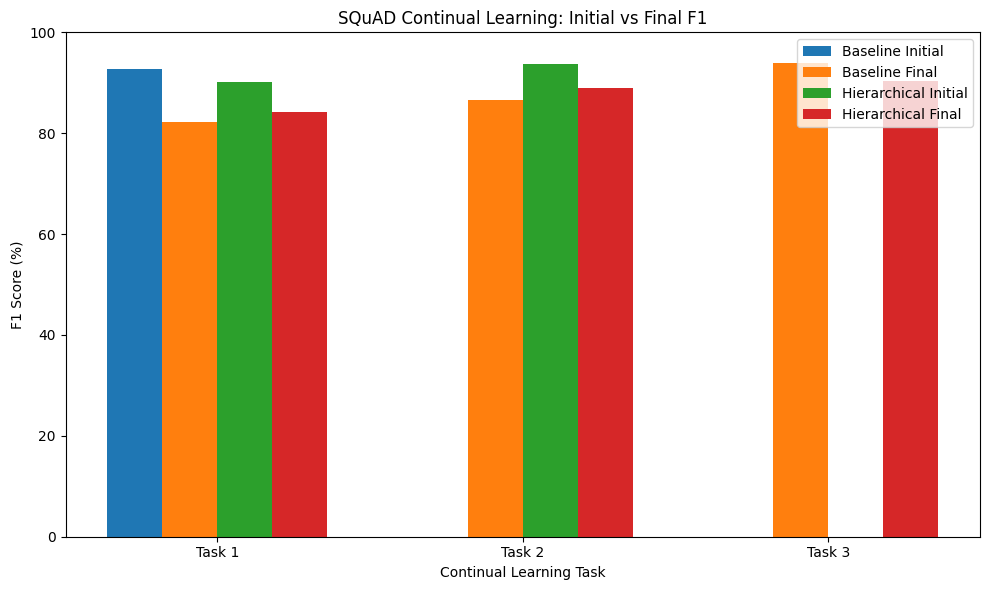

In [ ]:
# ============================================================
#  INITIAL VS FINAL F1
# ============================================================

tasks = ["Task 1", "Task 2", "Task 3"]

baseline_initial = [92.66, np.nan, np.nan]
baseline_final = [82.13, 86.54, 93.99]

hier_initial = [90.11, 93.63, np.nan]
hier_final = [84.23, 89.06, 90.38]


x = np.arange(len(tasks))
width = 0.18


plt.figure(figsize=(10, 6))

plt.bar(
    x - 1.5 * width,
    baseline_initial,
    width,
    label="Baseline Initial"
)

plt.bar(
    x - 0.5 * width,
    baseline_final,
    width,
    label="Baseline Final"
)

plt.bar(
    x + 0.5 * width,
    hier_initial,
    width,
    label="Hierarchical Initial"
)

plt.bar(
    x + 1.5 * width,
    hier_final,
    width,
    label="Hierarchical Final"
)

plt.xticks(x, tasks)

plt.ylabel("F1 Score (%)")
plt.xlabel("Continual Learning Task")

plt.title(
    "SQuAD Continual Learning: Initial vs Final F1"
)

plt.ylim(0, 100)

plt.legend()

plt.tight_layout()

plt.show()

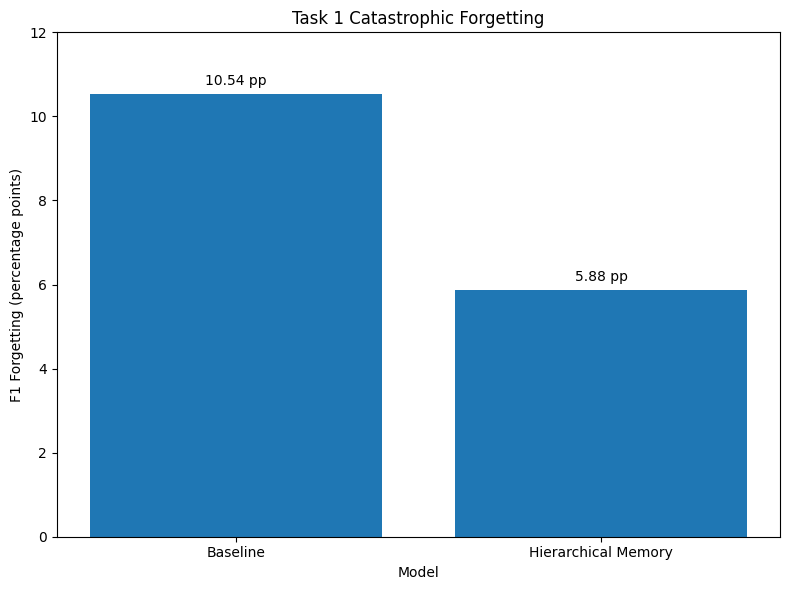

In [ ]:
# ============================================================
# GRAPH 2 — CATASTROPHIC FORGETTING
# ============================================================

models = [
    "Baseline",
    "Hierarchical Memory"
]

task1_forgetting = [
    10.54,
    5.88
]


plt.figure(figsize=(8, 6))

bars = plt.bar(
    models,
    task1_forgetting
)

plt.ylabel(
    "F1 Forgetting (percentage points)"
)

plt.xlabel("Model")

plt.title(
    "Task 1 Catastrophic Forgetting"
)

plt.ylim(0, 12)


# Add values above bars
for bar, value in zip(
    bars,
    task1_forgetting
):

    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        value + 0.2,
        f"{value:.2f} pp",
        ha="center"
    )


plt.tight_layout()

plt.show()

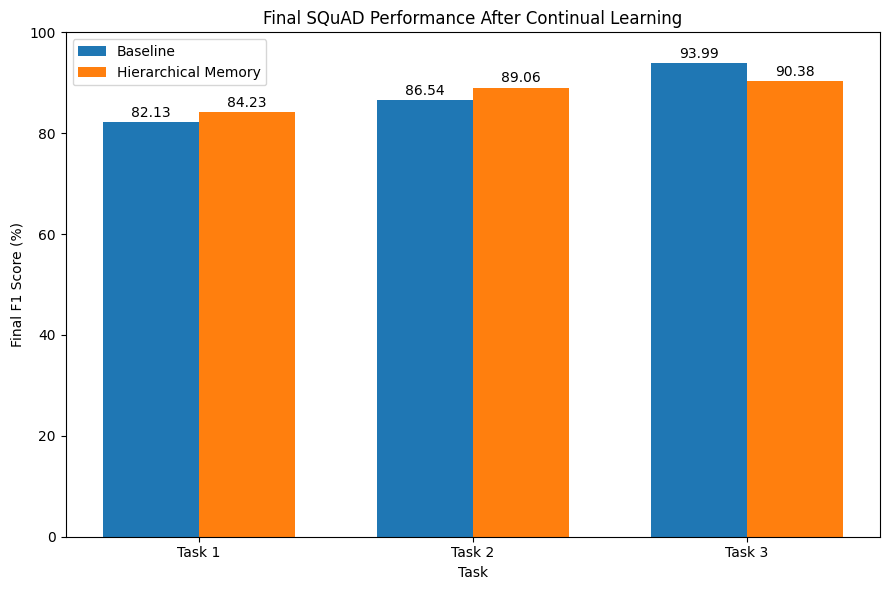

In [ ]:
# ============================================================
# GRAPH 3 — FINAL F1 ACROSS TASKS
# ============================================================

tasks = [
    "Task 1",
    "Task 2",
    "Task 3"
]

baseline_final = [
    82.13,
    86.54,
    93.99
]

hierarchical_final = [
    84.23,
    89.06,
    90.38
]


x = np.arange(len(tasks))
width = 0.35


plt.figure(figsize=(9, 6))

bars1 = plt.bar(
    x - width / 2,
    baseline_final,
    width,
    label="Baseline"
)

bars2 = plt.bar(
    x + width / 2,
    hierarchical_final,
    width,
    label="Hierarchical Memory"
)

plt.xticks(x, tasks)

plt.ylabel("Final F1 Score (%)")

plt.xlabel("Task")

plt.title(
    "Final SQuAD Performance After Continual Learning"
)

plt.ylim(0, 100)

plt.legend()


# Add values above bars
for bars in [bars1, bars2]:

    for bar in bars:

        height = bar.get_height()

        plt.text(
            bar.get_x() +
            bar.get_width() / 2,
            height + 1,
            f"{height:.2f}",
            ha="center"
        )


plt.tight_layout()

plt.show()

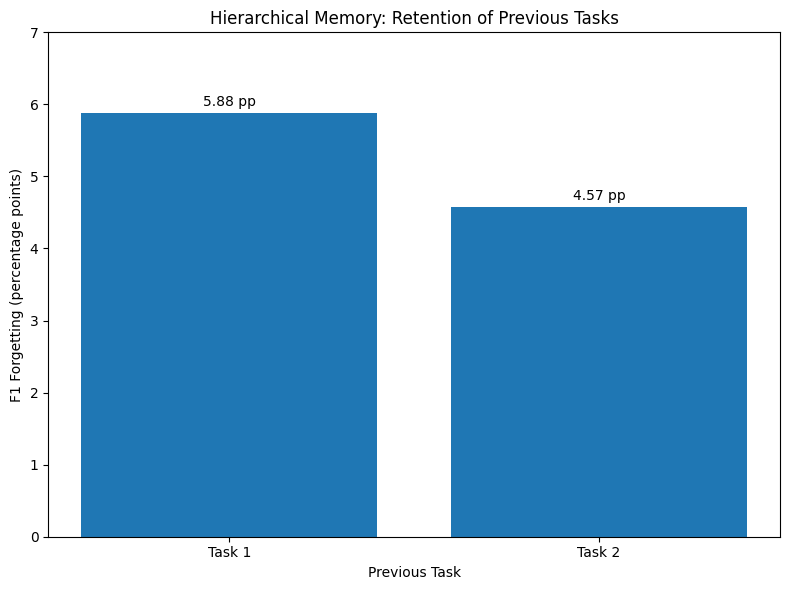

In [ ]:
# ============================================================
# GRAPH 4 — FORGETTING ACROSS PREVIOUS TASKS
# ============================================================

tasks = [
    "Task 1",
    "Task 2"
]

forgetting = [
    5.88,
    4.57
]


plt.figure(figsize=(8, 6))

bars = plt.bar(
    tasks,
    forgetting
)

plt.ylabel(
    "F1 Forgetting (percentage points)"
)

plt.xlabel("Previous Task")

plt.title(
    "Hierarchical Memory: Retention of Previous Tasks"
)

plt.ylim(0, 7)


for bar, value in zip(
    bars,
    forgetting
):

    plt.text(
        bar.get_x() +
        bar.get_width() / 2,
        value + 0.1,
        f"{value:.2f} pp",
        ha="center"
    )


plt.tight_layout()

plt.show()

**Test individual examples**

In [ ]:
# ============================================================
# INDIVIDUAL EXAMPLE COMPARISON
# ============================================================

def normalize_text(text):
    return " ".join(
        re.sub(r"[^a-z0-9\s]", " ", text.lower()).split()
    )


def is_correct_prediction(prediction, expected):
    return (
        normalize_text(prediction)
        == normalize_text(expected)
    )


baseline_results = baseline_task1_results_after
hierarchical_results = hier_task1_results_final


baseline_wrong_memory_correct = []
baseline_correct_memory_wrong = []
both_correct = []
both_wrong = []


for b, h in zip(
    baseline_results,
    hierarchical_results
):

    expected = b["expected"]

    baseline_correct = is_correct_prediction(
        b["prediction"],
        expected
    )

    memory_correct = is_correct_prediction(
        h["prediction"],
        expected
    )

    example = {
        "question": b["question"],
        "expected": expected,
        "baseline": b["prediction"],
        "hierarchical": h["prediction"]
    }

    if not baseline_correct and memory_correct:

        baseline_wrong_memory_correct.append(
            example
        )

    elif baseline_correct and not memory_correct:

        baseline_correct_memory_wrong.append(
            example
        )

    elif baseline_correct and memory_correct:

        both_correct.append(example)

    else:

        both_wrong.append(example)


print("=" * 80)
print("TASK 1 INDIVIDUAL EXAMPLE COMPARISON")
print("=" * 80)

print(
    "Baseline WRONG / Hierarchical CORRECT:",
    len(baseline_wrong_memory_correct)
)

print(
    "Baseline CORRECT / Hierarchical WRONG:",
    len(baseline_correct_memory_wrong)
)

print(
    "Both CORRECT:",
    len(both_correct)
)

print(
    "Both WRONG:",
    len(both_wrong)
)

TASK 1 INDIVIDUAL EXAMPLE COMPARISON
Baseline WRONG / Hierarchical CORRECT: 40
Baseline CORRECT / Hierarchical WRONG: 61
Both CORRECT: 307
Both WRONG: 86


In [ ]:
# ============================================================
#  BASELINE WRONG, MEMORY CORRECT
# ============================================================

print("=" * 90)
print("EXAMPLES WHERE BASELINE IS WRONG BUT HIERARCHICAL MEMORY IS CORRECT")
print("=" * 90)


for i, example in enumerate(
    baseline_wrong_memory_correct[:10],
    start=1
):

    print("\n" + "-" * 90)
    print(f"Example {i}")
    print("-" * 90)

    print("Question:")
    print(example["question"])

    print("\nExpected:")
    print(example["expected"])

    print("\nBaseline:")
    print(example["baseline"], "❌")

    print("\nHierarchical Memory:")
    print(example["hierarchical"], "✅")

EXAMPLES WHERE BASELINE IS WRONG BUT HIERARCHICAL MEMORY IS CORRECT

------------------------------------------------------------------------------------------
Example 1
------------------------------------------------------------------------------------------
Question:
What performance was Chopin forced to decline due to his increasing ill health?

Expected:
Beethoven Seventh Symphony arrangement at Erard's

Baseline:
Beethoven Seventh Symphony arrangement ❌

Hierarchical Memory:
Beethoven Seventh Symphony arrangement at Erard's ✅

------------------------------------------------------------------------------------------
Example 2
------------------------------------------------------------------------------------------
Question:
What is a solar chimney?

Expected:
a passive solar ventilation system

Baseline:
passive solar ventilation system ❌

Hierarchical Memory:
a passive solar ventilation system ✅

----------------------------------------------------------------------------------

In [ ]:
# ============================================================
#  BASELINE CORRECT, MEMORY WRONG
# ============================================================

print("=" * 90)
print("EXAMPLES WHERE BASELINE IS CORRECT BUT HIERARCHICAL MEMORY IS WRONG")
print("=" * 90)


for i, example in enumerate(
    baseline_correct_memory_wrong[:10],
    start=1
):

    print("\n" + "-" * 90)
    print(f"Example {i}")
    print("-" * 90)

    print("Question:")
    print(example["question"])

    print("\nExpected:")
    print(example["expected"])

    print("\nBaseline:")
    print(example["baseline"], "✅")

    print("\nHierarchical Memory:")
    print(example["hierarchical"], "❌")

EXAMPLES WHERE BASELINE IS CORRECT BUT HIERARCHICAL MEMORY IS WRONG

------------------------------------------------------------------------------------------
Example 1
------------------------------------------------------------------------------------------
Question:
What nationality is stated as the one Frédéric felt most identified by?

Expected:
Polish

Baseline:
Polish ✅

Hierarchical Memory:
Pole ❌

------------------------------------------------------------------------------------------
Example 2
------------------------------------------------------------------------------------------
Question:
What second performance did Chopin have to decline to play?

Expected:
Beethoven Seventh Symphony arrangement

Baseline:
Beethoven Seventh Symphony arrangement ✅

Hierarchical Memory:
Beethoven Seventh Symphony arrangement at Erard's ❌

------------------------------------------------------------------------------------------
Example 3
-------------------------------------------------

In [ ]:
# ============================================================
# INDIVIDUAL EXAMPLE STATISTICS
# ============================================================

total = len(task1_qa)

baseline_correct_count = (
    len(both_correct) +
    len(baseline_correct_memory_wrong)
)

memory_correct_count = (
    len(both_correct) +
    len(baseline_wrong_memory_correct)
)

print("=" * 80)
print("INDIVIDUAL PREDICTION STATISTICS")
print("=" * 80)

print(
    f"Total Task 1 examples: {total}"
)

print(
    f"Baseline correct: "
    f"{baseline_correct_count}/{total}"
)

print(
    f"Hierarchical correct: "
    f"{memory_correct_count}/{total}"
)

print(
    f"Baseline wrong → Memory correct: "
    f"{len(baseline_wrong_memory_correct)}"
)

print(
    f"Baseline correct → Memory wrong: "
    f"{len(baseline_correct_memory_wrong)}"
)

print(
    f"Both correct: "
    f"{len(both_correct)}"
)

print(
    f"Both wrong: "
    f"{len(both_wrong)}"
)

INDIVIDUAL PREDICTION STATISTICS
Total Task 1 examples: 494
Baseline correct: 368/494
Hierarchical correct: 347/494
Baseline wrong → Memory correct: 40
Baseline correct → Memory wrong: 61
Both correct: 307
Both wrong: 86


**MEMORY CONTROLLER SETUP TESTING IT FOR SYNTHATIC DATA**

In [ ]:
# ============================================================
# CELL 1: MEMORY CONTROLLER
# ============================================================
# PURPOSE:
# This cell creates a Memory Controller for our hierarchical
# memory system.
#
# The Memory Controller decides whether a piece of information
# is important enough to store in memory.
#
# The score is based on:
# 1. Relevance       -> Is this information useful for the query?
# 2. Importance      -> How important is this information?
# 3. Future Use      -> Could this information be useful later?
# 4. Confidence      -> How reliable/confident are we?
# 5. Duplication     -> Is this information already stored?
#
# The project proposal describes the memory score as:
#
# M(x) = w1*R + w2*I + w3*F + w4*C - w5*D
#
# where:
# R = Relevance
# I = Importance
# F = Future usefulness
# C = Confidence
# D = Duplication
#
# NOTE:
# The proposal gives the formula but does NOT specify exact
# numerical weights. Therefore, the weights below are initial
# experimental values that we can tune later.
# ============================================================


class MemoryController:

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------
    # The weights determine how much each factor contributes
    # to the final memory score.
    # --------------------------------------------------------
    def __init__(
        self,
        w_relevance=0.30,
        w_importance=0.25,
        w_future=0.20,
        w_confidence=0.20,
        w_duplication=0.15,
        threshold=0.50
    ):

        # Store the weights so that we can use them later.
        self.w_relevance = w_relevance
        self.w_importance = w_importance
        self.w_future = w_future
        self.w_confidence = w_confidence
        self.w_duplication = w_duplication

        # If the final memory score is greater than or equal
        # to this threshold, we will recommend storing it.
        self.threshold = threshold


    # --------------------------------------------------------
    # Calculate Memory Score
    # --------------------------------------------------------
    # This function implements:
    #
    # M(x) = w1*R + w2*I + w3*F + w4*C - w5*D
    #
    # All input values should normally be between 0 and 1.
    # --------------------------------------------------------
    def calculate_score(
        self,
        relevance,
        importance,
        future_usefulness,
        confidence,
        duplication
    ):

        # Calculate the weighted memory score.
        score = (
            self.w_relevance * relevance
            + self.w_importance * importance
            + self.w_future * future_usefulness
            + self.w_confidence * confidence
            - self.w_duplication * duplication
        )

        # Return the calculated score.
        return score


    # --------------------------------------------------------
    # Decide Whether to Store the Memory
    # --------------------------------------------------------
    # If score >= threshold:
    #       Store the information
    #
    # Otherwise:
    #       Discard the information
    # --------------------------------------------------------
    def should_store(
        self,
        relevance,
        importance,
        future_usefulness,
        confidence,
        duplication
    ):

        # First calculate the memory score.
        score = self.calculate_score(
            relevance,
            importance,
            future_usefulness,
            confidence,
            duplication
        )

        # Compare the score with the threshold.
        store = score >= self.threshold

        # Return both the decision and the score.
        return store, score


# ============================================================
# CREATE THE MEMORY CONTROLLER
# ============================================================

# Create an instance of our Memory Controller.
memory_controller = MemoryController()


# ============================================================
# TEST THE MEMORY CONTROLLER
# ============================================================
# We now test it with one example.
#
# Example:
# - Relevance = 0.9
# - Importance = 0.8
# - Future usefulness = 0.9
# - Confidence = 0.95
# - Duplication = 0.1
#
# This should produce a relatively high score.
# ============================================================

store, score = memory_controller.should_store(
    relevance=0.9,
    importance=0.8,
    future_usefulness=0.9,
    confidence=0.95,
    duplication=0.1
)


# Print the calculated score.
print("Memory Score:", round(score, 4))

# Print whether the controller recommends storing it.
print("Store Memory:", store)


# ============================================================
# SECOND TEST
# ============================================================
# This example represents information that:
# - has low relevance
# - has low importance
# - is not very useful in the future
# - has low confidence
# - is highly duplicated
#
# Therefore, the controller should probably reject it.
# ============================================================

store2, score2 = memory_controller.should_store(
    relevance=0.2,
    importance=0.2,
    future_usefulness=0.1,
    confidence=0.4,
    duplication=0.9
)


# Print the second score.
print("\nSecond Memory Score:", round(score2, 4))

# Print the second storage decision.
print("Store Second Memory:", store2)

Memory Score: 0.825
Store Memory: True

Second Memory Score: 0.075
Store Second Memory: False


**HIERARCHICAL MEMORY LAYERS**

In [ ]:
# ============================================================
# CELL 2: HIERARCHICAL MEMORY LAYERS
# ============================================================
# PURPOSE:
# This cell creates three separate memory levels:
#
# 1. Working Memory
#    -> Stores information currently being processed.
#    -> Very short-term memory.
#
# 2. Episodic Memory
#    -> Stores specific past events/information.
#    -> Example: a question-answer pair from a previous task.
#
# 3. Semantic Memory
#    -> Stores important/generalized knowledge.
#    -> Information that is useful for a longer period.
#
# IMPORTANT:
# This is an ADD-ON architecture.
# It does NOT modify the existing STM/LTM implementation.
# We are building and testing the new architecture separately.
# ============================================================


class HierarchicalMemory:

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------
    # max_working:
    #     Maximum number of items in working memory.
    #
    # max_episodic:
    #     Maximum number of episodic memories.
    #
    # max_semantic:
    #     Maximum number of semantic memories.
    # --------------------------------------------------------
    def __init__(
        self,
        max_working=10,
        max_episodic=100,
        max_semantic=100
    ):

        # Working memory stores the information currently
        # being processed.
        self.working_memory = []

        # Episodic memory stores individual past experiences
        # or events.
        self.episodic_memory = []

        # Semantic memory stores stable/generalized knowledge.
        self.semantic_memory = []

        # Store the maximum capacity of each memory level.
        self.max_working = max_working
        self.max_episodic = max_episodic
        self.max_semantic = max_semantic


    # --------------------------------------------------------
    # Add information to Working Memory
    # --------------------------------------------------------
    def add_to_working(self, memory):

        # Add the new memory to working memory.
        self.working_memory.append(memory)

        # If working memory exceeds its capacity,
        # remove the oldest item.
        if len(self.working_memory) > self.max_working:
            self.working_memory.pop(0)


    # --------------------------------------------------------
    # Move information from Working Memory to Episodic Memory
    # --------------------------------------------------------
    def move_to_episodic(self, memory):

        # Add the information to episodic memory.
        self.episodic_memory.append(memory)

        # If episodic memory exceeds its capacity,
        # remove the oldest memory.
        if len(self.episodic_memory) > self.max_episodic:
            self.episodic_memory.pop(0)


    # --------------------------------------------------------
    # Move information from Episodic Memory to Semantic Memory
    # --------------------------------------------------------
    def move_to_semantic(self, memory):

        # Add the information to semantic memory.
        self.semantic_memory.append(memory)

        # If semantic memory exceeds its capacity,
        # remove the oldest memory.
        if len(self.semantic_memory) > self.max_semantic:
            self.semantic_memory.pop(0)


    # --------------------------------------------------------
    # Display the current memory sizes
    # --------------------------------------------------------
    def show_memory_status(self):

        # Print the number of items in each memory layer.
        print("Working Memory :", len(self.working_memory))
        print("Episodic Memory:", len(self.episodic_memory))
        print("Semantic Memory:", len(self.semantic_memory))


# ============================================================
# CREATE THE HIERARCHICAL MEMORY
# ============================================================

# Create our new hierarchical memory system.
hierarchical_memory = HierarchicalMemory(
    max_working=10,
    max_episodic=100,
    max_semantic=100
)


# ============================================================
# TEST WORKING MEMORY
# ============================================================

# Add a sample question-answer pair to working memory.
hierarchical_memory.add_to_working({
    "question": "Who wrote Hamlet?",
    "answer": "William Shakespeare"
})


# ============================================================
# TEST EPISODIC MEMORY
# ============================================================

# Store a previous experience in episodic memory.
hierarchical_memory.move_to_episodic({
    "question": "What is the capital of France?",
    "answer": "Paris"
})


# ============================================================
# TEST SEMANTIC MEMORY
# ============================================================

# Store stable/general knowledge in semantic memory.
hierarchical_memory.move_to_semantic({
    "knowledge": "Paris is the capital of France."
})


# ============================================================
# DISPLAY MEMORY STATUS
# ============================================================

# Show how many memories currently exist
# at each hierarchical level.
hierarchical_memory.show_memory_status()

Working Memory : 1
Episodic Memory: 1
Semantic Memory: 1


**Memory Score =**
  **0.30 × Relevance**
**+ 0.25 × Importance**
+** 0.20 × Future Usefulness**
+** 0.20 × Confidence**
- **0.15 × Duplication **

**AUTOMATIC MEMORY CONSOLIDATION**

In [ ]:
# ============================================================
# CELL 3: AUTOMATIC MEMORY CONSOLIDATION
# ============================================================
# PURPOSE:
# This cell connects the Memory Controller from Cell 1
# with the hierarchical memory from Cell 2.
#
# Instead of manually deciding where information should go,
# the system automatically decides:
#
# 1. Low-quality information  -> Discard
# 2. Useful information       -> Episodic Memory
# 3. Highly important/reliable information -> Semantic Memory
#
# Working Memory is used first because every new piece of
# information initially enters the working memory.
# ============================================================


class AutomaticMemoryConsolidator:

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------
    # We pass:
    # - memory_controller from Cell 1
    # - hierarchical_memory from Cell 2
    # --------------------------------------------------------
    def __init__(self, memory_controller, hierarchical_memory):

        # Save the Memory Controller.
        self.controller = memory_controller

        # Save the hierarchical memory system.
        self.memory = hierarchical_memory


    # --------------------------------------------------------
    # Process New Information
    # --------------------------------------------------------
    # This function receives a new piece of information and
    # automatically decides whether it should be discarded,
    # stored episodically, or stored semantically.
    # --------------------------------------------------------
    def process_information(
        self,
        information,
        relevance,
        importance,
        future_usefulness,
        confidence,
        duplication
    ):

        # ----------------------------------------------------
        # STEP 1:
        # Add the new information to Working Memory.
        # ----------------------------------------------------
        self.memory.add_to_working(information)


        # ----------------------------------------------------
        # STEP 2:
        # Ask the Memory Controller to calculate the score.
        # ----------------------------------------------------
        store, score = self.controller.should_store(
            relevance=relevance,
            importance=importance,
            future_usefulness=future_usefulness,
            confidence=confidence,
            duplication=duplication
        )


        # ----------------------------------------------------
        # STEP 3:
        # If the score is below the threshold,
        # the information is considered unimportant.
        # ----------------------------------------------------
        if not store:

            # Remove the information from working memory
            # because we decided not to keep it.
            if information in self.memory.working_memory:
                self.memory.working_memory.remove(information)

            # Return the decision and score.
            return {
                "decision": "DISCARD",
                "score": score,
                "information": information
            }


        # ----------------------------------------------------
        # STEP 4:
        # Decide between Episodic and Semantic Memory.
        #
        # Very important and reliable information is placed
        # directly into Semantic Memory.
        #
        # Other useful information is placed into
        # Episodic Memory first.
        # ----------------------------------------------------

        if importance >= 0.75 and confidence >= 0.75:

            # Move the information to Semantic Memory.
            self.memory.move_to_semantic(information)

            # Remove it from Working Memory because it has
            # now been consolidated into long-term memory.
            if information in self.memory.working_memory:
                self.memory.working_memory.remove(information)

            # Return the result.
            return {
                "decision": "SEMANTIC",
                "score": score,
                "information": information
            }


        # ----------------------------------------------------
        # STEP 5:
        # If the information is useful but not strong enough
        # for semantic memory, store it as an episode.
        # ----------------------------------------------------

        self.memory.move_to_episodic(information)

        # Remove the information from Working Memory.
        if information in self.memory.working_memory:
            self.memory.working_memory.remove(information)

        # Return the result.
        return {
            "decision": "EPISODIC",
            "score": score,
            "information": information
        }


# ============================================================
# CREATE THE AUTOMATIC CONSOLIDATOR
# ============================================================
# We connect:
#
# Cell 1 -> Memory Controller
# Cell 2 -> Hierarchical Memory
# Cell 3 -> Automatic Consolidation
# ============================================================

consolidator = AutomaticMemoryConsolidator(
    memory_controller,
    hierarchical_memory
)


# ============================================================
# TEST 1: IMPORTANT AND HIGH-CONFIDENCE INFORMATION
# ============================================================
# This information has:
# - High relevance
# - High importance
# - High future usefulness
# - High confidence
# - Low duplication
#
# Therefore, it should be stored in Semantic Memory.
# ============================================================

result1 = consolidator.process_information(
    information={
        "question": "What is the capital of France?",
        "answer": "Paris"
    },
    relevance=0.95,
    importance=0.90,
    future_usefulness=0.90,
    confidence=0.95,
    duplication=0.05
)

print("TEST 1")
print("Decision:", result1["decision"])
print("Score:", round(result1["score"], 4))


# ============================================================
# TEST 2: USEFUL BUT NOT VERY IMPORTANT INFORMATION
# ============================================================
# This information is useful but has lower importance.
# Therefore, it should normally go to Episodic Memory.
# ============================================================

result2 = consolidator.process_information(
    information={
        "question": "What was discussed in today's meeting?",
        "answer": "The project deadline was discussed."
    },
    relevance=0.80,
    importance=0.60,
    future_usefulness=0.70,
    confidence=0.85,
    duplication=0.10
)

print("\nTEST 2")
print("Decision:", result2["decision"])
print("Score:", round(result2["score"], 4))


# ============================================================
# TEST 3: LOW-QUALITY INFORMATION
# ============================================================
# This information has:
# - Low relevance
# - Low importance
# - Low future usefulness
# - Low confidence
# - High duplication
#
# Therefore, it should be discarded.
# ============================================================

result3 = consolidator.process_information(
    information={
        "question": "Random information",
        "answer": "Uncertain answer"
    },
    relevance=0.20,
    importance=0.10,
    future_usefulness=0.10,
    confidence=0.30,
    duplication=0.90
)

print("\nTEST 3")
print("Decision:", result3["decision"])
print("Score:", round(result3["score"], 4))


# ============================================================
# DISPLAY FINAL MEMORY STATUS
# ============================================================
# This shows how the information was distributed across
# the three memory levels.
# ============================================================

print("\nFINAL MEMORY STATUS")
hierarchical_memory.show_memory_status()

TEST 1
Decision: SEMANTIC
Score: 0.8725

TEST 2
Decision: EPISODIC
Score: 0.685

TEST 3
Decision: DISCARD
Score: 0.03

FINAL MEMORY STATUS
Working Memory : 1
Episodic Memory: 2
Semantic Memory: 2


**Automatic Episodic → Semantic Consolidation**

In [ ]:
# ============================================================
# CELL 4: EPISODIC -> SEMANTIC MEMORY CONSOLIDATION
# ============================================================
# PURPOSE:
# This cell implements automatic consolidation.
#
# The idea is:
#
#       Episodic Memory
#              |
#              v
#       Importance Check
#              |
#       +------+------+
#       |             |
#     High          Low
#       |             |
#       v             v
#   Semantic      Stay in
#    Memory       Episodic
#
# This represents the idea that information first stored as
# an episode can become stable semantic knowledge when it is
# important and reliable enough.
# ============================================================


class MemoryConsolidator:

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------
    # importance_threshold:
    #     Minimum importance required for promotion.
    #
    # confidence_threshold:
    #     Minimum confidence required for promotion.
    # --------------------------------------------------------
    def __init__(
        self,
        hierarchical_memory,
        importance_threshold=0.75,
        confidence_threshold=0.75
    ):

        # Store the existing hierarchical memory object.
        self.memory = hierarchical_memory

        # Store the thresholds used for consolidation.
        self.importance_threshold = importance_threshold
        self.confidence_threshold = confidence_threshold


    # --------------------------------------------------------
    # Consolidate One Memory
    # --------------------------------------------------------
    # This function checks whether one episodic memory should
    # be promoted to semantic memory.
    # --------------------------------------------------------
    def consolidate(
        self,
        memory,
        importance,
        confidence
    ):

        # Check whether both importance and confidence are high.
        if (
            importance >= self.importance_threshold
            and
            confidence >= self.confidence_threshold
        ):

            # Check whether the memory actually exists
            # inside episodic memory.
            if memory in self.memory.episodic_memory:

                # Remove the memory from episodic memory.
                self.memory.episodic_memory.remove(memory)

                # Add the memory to semantic memory.
                self.memory.move_to_semantic(memory)

                # Return the result of promotion.
                return {
                    "promoted": True,
                    "message": "Memory promoted to Semantic Memory"
                }

        # If the conditions were not satisfied, keep the
        # information in episodic memory.
        return {
            "promoted": False,
            "message": "Memory remains in Episodic Memory"
        }


# ============================================================
# CREATE THE CONSOLIDATOR
# ============================================================

# Create the consolidation system using the hierarchical
# memory object created in Cell 2.
memory_consolidator = MemoryConsolidator(
    hierarchical_memory,
    importance_threshold=0.75,
    confidence_threshold=0.75
)


# ============================================================
# FIND AN EPISODIC MEMORY TO TEST
# ============================================================

# Select the first memory currently stored in episodic memory.
episodic_test_memory = hierarchical_memory.episodic_memory[0]


# ============================================================
# TEST 1: HIGH IMPORTANCE + HIGH CONFIDENCE
# ============================================================
# This represents information that has become important and
# reliable enough to be considered stable knowledge.
# Therefore, it should be promoted to Semantic Memory.
# ============================================================

result = memory_consolidator.consolidate(
    memory=episodic_test_memory,
    importance=0.90,
    confidence=0.90
)


# Print the result of consolidation.
print("TEST 1")
print("Promoted:", result["promoted"])
print("Message:", result["message"])


# ============================================================
# DISPLAY MEMORY STATUS AFTER CONSOLIDATION
# ============================================================

print("\nMEMORY STATUS AFTER TEST 1")
hierarchical_memory.show_memory_status()


# ============================================================
# TEST 2: LOW IMPORTANCE
# ============================================================
# We now take another episodic memory.
#
# Even if its confidence is high, its importance is low.
# Therefore, it should remain in Episodic Memory.
# ============================================================

if len(hierarchical_memory.episodic_memory) > 0:

    # Select another episodic memory.
    episodic_test_memory_2 = hierarchical_memory.episodic_memory[0]

    # Try to consolidate it.
    result2 = memory_consolidator.consolidate(
        memory=episodic_test_memory_2,
        importance=0.40,
        confidence=0.90
    )

    # Print the result.
    print("\nTEST 2")
    print("Promoted:", result2["promoted"])
    print("Message:", result2["message"])


# ============================================================
# FINAL MEMORY STATUS
# ============================================================

print("\nFINAL MEMORY STATUS")
hierarchical_memory.show_memory_status()

TEST 1
Promoted: True
Message: Memory promoted to Semantic Memory

MEMORY STATUS AFTER TEST 1
Working Memory : 1
Episodic Memory: 1
Semantic Memory: 3

TEST 2
Promoted: False
Message: Memory remains in Episodic Memory

FINAL MEMORY STATUS
Working Memory : 1
Episodic Memory: 1
Semantic Memory: 3


**CONFLICT DETECTION**

In [ ]:
# ============================================================
# CELL 5: CONFLICT DETECTION
# ============================================================
# PURPOSE:
# This cell detects whether a new piece of information
# conflicts with an existing memory.
#
# Example:
#
# Existing memory:
# "The capital of Country X is A."
#
# New information:
# "The capital of Country X is B."
#
# The system should identify that these two statements
# may contain conflicting information.
#
# IMPORTANT:
# This cell ONLY detects conflicts.
# It does NOT decide which information is correct.
#
# The actual decision will be implemented in Cell 6.
# ============================================================


class ConflictDetector:

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------
    def __init__(self):

        # Store detected conflicts in a list.
        # Each conflict will contain the old and new memory.
        self.conflicts = []


    # --------------------------------------------------------
    # Extract the question from a memory
    # --------------------------------------------------------
    # Our QA memories contain:
    #
    # {
    #     "question": "...",
    #     "answer": "..."
    # }
    #
    # We use the question as the key for detecting whether
    # two memories are talking about the same topic.
    # --------------------------------------------------------
    def get_question(self, memory):

        # Check whether the memory is a dictionary and
        # contains a question field.
        if isinstance(memory, dict) and "question" in memory:

            # Return the question.
            return memory["question"]

        # If no question exists, return None.
        return None


    # --------------------------------------------------------
    # Extract the answer from a memory
    # --------------------------------------------------------
    def get_answer(self, memory):

        # Check whether the memory is a dictionary and
        # contains an answer field.
        if isinstance(memory, dict) and "answer" in memory:

            # Return the answer.
            return memory["answer"]

        # If no answer exists, return None.
        return None


    # --------------------------------------------------------
    # Detect Conflict
    # --------------------------------------------------------
    # A conflict is detected when:
    #
    # 1. Two memories have the same question/topic.
    # 2. Their answers are different.
    #
    # Example:
    #
    # Old:
    # question = "Capital of France?"
    # answer   = "Paris"
    #
    # New:
    # question = "Capital of France?"
    # answer   = "London"
    #
    # Result:
    # CONFLICT DETECTED
    # --------------------------------------------------------
    def detect_conflict(self, new_memory, existing_memories):

        # Get the question and answer from the new memory.
        new_question = self.get_question(new_memory)
        new_answer = self.get_answer(new_memory)


        # If the new memory does not have a question or answer,
        # we cannot perform this simple QA-based conflict check.
        if new_question is None or new_answer is None:

            return {
                "conflict": False,
                "message": "Cannot check conflict for this memory format."
            }


        # ----------------------------------------------------
        # Compare the new memory with every existing memory.
        # ----------------------------------------------------
        for old_memory in existing_memories:

            # Extract the old question and answer.
            old_question = self.get_question(old_memory)
            old_answer = self.get_answer(old_memory)


            # ------------------------------------------------
            # Check whether both memories refer to the same
            # question.
            # ------------------------------------------------
            if old_question is not None and old_answer is not None:

                # Convert questions to lowercase and remove
                # extra spaces to make comparison easier.
                normalized_old_question = " ".join(
                    old_question.lower().split()
                )

                normalized_new_question = " ".join(
                    new_question.lower().split()
                )


                # ------------------------------------------------
                # If the questions are the same but answers differ,
                # we consider this a potential conflict.
                # ------------------------------------------------
                if (
                    normalized_old_question == normalized_new_question
                    and
                    old_answer.strip().lower()
                    !=
                    new_answer.strip().lower()
                ):

                    # Create a conflict record.
                    conflict = {
                        "old_memory": old_memory,
                        "new_memory": new_memory
                    }

                    # Save the conflict for later analysis.
                    self.conflicts.append(conflict)


                    # Return immediately because we found
                    # a conflicting memory.
                    return {
                        "conflict": True,
                        "message": "Potential conflict detected.",
                        "old_memory": old_memory,
                        "new_memory": new_memory
                    }


        # ----------------------------------------------------
        # If no conflicting memory was found.
        # ----------------------------------------------------
        return {
            "conflict": False,
            "message": "No conflict detected."
        }


# ============================================================
# CREATE THE CONFLICT DETECTOR
# ============================================================

# Create an instance of the conflict detector.
conflict_detector = ConflictDetector()


# ============================================================
# CREATE AN EXISTING MEMORY
# ============================================================
# This represents knowledge that already exists in memory.
# ============================================================

old_memory = {
    "question": "What is the capital of France?",
    "answer": "Paris"
}


# ============================================================
# CREATE NEW INFORMATION
# ============================================================
# The question is the same, but the answer is different.
# Therefore, this should be detected as a conflict.
# ============================================================

new_memory = {
    "question": "What is the capital of France?",
    "answer": "London"
}


# ============================================================
# RUN CONFLICT DETECTION
# ============================================================

conflict_result = conflict_detector.detect_conflict(
    new_memory=new_memory,
    existing_memories=[old_memory]
)


# ============================================================
# DISPLAY THE RESULT
# ============================================================

print("CONFLICT TEST 1")
print("Conflict Detected:", conflict_result["conflict"])
print("Message:", conflict_result["message"])


# ============================================================
# TEST 2: SAME INFORMATION
# ============================================================
# Here the old and new answers are identical.
# Therefore, there should be no conflict.
# ============================================================

same_memory = {
    "question": "What is the capital of France?",
    "answer": "Paris"
}


# Run the detector again.
conflict_result_2 = conflict_detector.detect_conflict(
    new_memory=same_memory,
    existing_memories=[old_memory]
)


# Display the result.
print("\nCONFLICT TEST 2")
print("Conflict Detected:", conflict_result_2["conflict"])
print("Message:", conflict_result_2["message"])

CONFLICT TEST 1
Conflict Detected: True
Message: Potential conflict detected.

CONFLICT TEST 2
Conflict Detected: False
Message: No conflict detected.


**CONFLICT RESOLUTION**

In [ ]:
# ============================================================
# CELL 6: CONFLICT RESOLUTION
# ============================================================
# PURPOSE:
# This cell decides what to do after Cell 5 detects a conflict.
#
# We compare the confidence of the old and new information.
#
# RULES:
#
# 1. New confidence > Old confidence
#       -> Replace old memory with new memory
#
# 2. Old confidence > New confidence
#       -> Keep old memory
#
# 3. Confidence values are very close
#       -> Keep BOTH memories
#
# Keeping both is useful because we should not blindly delete
# information when the system cannot confidently determine
# which version is correct.
# ============================================================


class ConflictResolver:

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------
    def __init__(self, confidence_margin=0.10):

        # This value determines how close two confidence
        # values must be before we consider them similar.
        #
        # Example:
        # Old confidence = 0.80
        # New confidence = 0.85
        #
        # Difference = 0.05
        #
        # Since 0.05 < 0.10, we keep both.
        self.confidence_margin = confidence_margin


    # --------------------------------------------------------
    # Resolve Conflict
    # --------------------------------------------------------
    def resolve(
        self,
        old_memory,
        new_memory,
        old_confidence,
        new_confidence
    ):

        # Calculate the difference between the two
        # confidence values.
        confidence_difference = abs(
            new_confidence - old_confidence
        )


        # ----------------------------------------------------
        # CASE 1:
        # New information is clearly more reliable.
        # ----------------------------------------------------
        if (
            new_confidence > old_confidence
            and
            confidence_difference > self.confidence_margin
        ):

            # Return the new memory as the preferred memory.
            return {
                "decision": "REPLACE",
                "selected_memory": new_memory,
                "message": "New memory has significantly higher confidence."
            }


        # ----------------------------------------------------
        # CASE 2:
        # Old information is clearly more reliable.
        # ----------------------------------------------------
        elif (
            old_confidence > new_confidence
            and
            confidence_difference > self.confidence_margin
        ):

            # Return the old memory as the preferred memory.
            return {
                "decision": "KEEP_OLD",
                "selected_memory": old_memory,
                "message": "Old memory has significantly higher confidence."
            }


        # ----------------------------------------------------
        # CASE 3:
        # Confidence values are very similar.
        # ----------------------------------------------------
        else:

            # Keep both pieces of information.
            return {
                "decision": "KEEP_BOTH",
                "selected_memory": [old_memory, new_memory],
                "message": "Confidence values are too close to choose one."
            }


# ============================================================
# CREATE THE CONFLICT RESOLVER
# ============================================================

# Create the conflict resolver.
conflict_resolver = ConflictResolver(
    confidence_margin=0.10
)


# ============================================================
# TEST 1: NEW MEMORY HAS HIGHER CONFIDENCE
# ============================================================
# Old information:
#     Paris
# Confidence = 0.60
#
# New information:
#     London
# Confidence = 0.90
#
# The new information has significantly higher confidence,
# so the system should choose the new memory.
# ============================================================

old_memory_1 = {
    "question": "What is the capital of France?",
    "answer": "Paris"
}

new_memory_1 = {
    "question": "What is the capital of France?",
    "answer": "London"
}


result1 = conflict_resolver.resolve(
    old_memory=old_memory_1,
    new_memory=new_memory_1,
    old_confidence=0.60,
    new_confidence=0.90
)


print("CONFLICT RESOLUTION TEST 1")
print("Decision:", result1["decision"])
print("Message:", result1["message"])
print("Selected Memory:", result1["selected_memory"])


# ============================================================
# TEST 2: OLD MEMORY HAS HIGHER CONFIDENCE
# ============================================================
# Old confidence = 0.90
# New confidence = 0.60
#
# Therefore, the old information should be retained.
# ============================================================

old_memory_2 = {
    "question": "Who wrote Hamlet?",
    "answer": "William Shakespeare"
}

new_memory_2 = {
    "question": "Who wrote Hamlet?",
    "answer": "Charles Dickens"
}


result2 = conflict_resolver.resolve(
    old_memory=old_memory_2,
    new_memory=new_memory_2,
    old_confidence=0.90,
    new_confidence=0.60
)


print("\nCONFLICT RESOLUTION TEST 2")
print("Decision:", result2["decision"])
print("Message:", result2["message"])
print("Selected Memory:", result2["selected_memory"])


# ============================================================
# TEST 3: CONFIDENCE VALUES ARE VERY CLOSE
# ============================================================
# Old confidence = 0.80
# New confidence = 0.85
#
# Difference = 0.05
#
# Since 0.05 < 0.10, the system cannot confidently choose
# one memory.
#
# Therefore, both memories are retained.
# ============================================================

old_memory_3 = {
    "question": "Who discovered America?",
    "answer": "Christopher Columbus"
}

new_memory_3 = {
    "question": "Who discovered America?",
    "answer": "Another historical interpretation"
}


result3 = conflict_resolver.resolve(
    old_memory=old_memory_3,
    new_memory=new_memory_3,
    old_confidence=0.80,
    new_confidence=0.85
)


print("\nCONFLICT RESOLUTION TEST 3")
print("Decision:", result3["decision"])
print("Message:", result3["message"])
print("Selected Memory:", result3["selected_memory"])

CONFLICT RESOLUTION TEST 1
Decision: REPLACE
Message: New memory has significantly higher confidence.
Selected Memory: {'question': 'What is the capital of France?', 'answer': 'London'}

CONFLICT RESOLUTION TEST 2
Decision: KEEP_OLD
Message: Old memory has significantly higher confidence.
Selected Memory: {'question': 'Who wrote Hamlet?', 'answer': 'William Shakespeare'}

CONFLICT RESOLUTION TEST 3
Decision: KEEP_BOTH
Message: Confidence values are too close to choose one.
Selected Memory: [{'question': 'Who discovered America?', 'answer': 'Christopher Columbus'}, {'question': 'Who discovered America?', 'answer': 'Another historical interpretation'}]


**Temporal Information + Knowledge Graph**

In [ ]:
# ============================================================
# CELL 7: TEMPORAL KNOWLEDGE GRAPH
# ============================================================
# PURPOSE:
# This cell adds a simple Knowledge Graph to our memory system.
#
# A Knowledge Graph represents information as:
#
#       Entity ---- Relationship ----> Entity
#
# Example:
#
#       Paris ---- capital_of ----> France
#
# We also attach a timestamp and confidence to each fact.
#
# This allows the system to preserve information instead of
# simply deleting an older fact when new information arrives.
#
# IMPORTANT:
# This is an ADD-ON component.
# It does NOT modify your existing FLAN-T5 model or memory.
# ============================================================


from datetime import datetime


class TemporalKnowledgeGraph:

    # --------------------------------------------------------
    # Constructor
    # --------------------------------------------------------
    def __init__(self):

        # Store graph relationships here.
        #
        # Each entry will contain:
        # subject
        # relation
        # object
        # confidence
        # timestamp
        self.triples = []


    # --------------------------------------------------------
    # Add a knowledge relationship
    # --------------------------------------------------------
    # Example:
    #
    # subject  = "Paris"
    # relation = "capital_of"
    # object   = "France"
    #
    # This creates:
    #
    # Paris ---- capital_of ----> France
    # --------------------------------------------------------
    def add_fact(
        self,
        subject,
        relation,
        object_value,
        confidence=1.0,
        timestamp=None
    ):

        # If the user does not provide a timestamp,
        # automatically use the current date and time.
        if timestamp is None:
            timestamp = datetime.now().isoformat()


        # Create one knowledge-graph triple.
        fact = {
            "subject": subject,
            "relation": relation,
            "object": object_value,
            "confidence": confidence,
            "timestamp": timestamp
        }


        # Add the fact to the graph.
        self.triples.append(fact)


        # Return the newly created fact.
        return fact


    # --------------------------------------------------------
    # Find facts about an entity
    # --------------------------------------------------------
    # Example:
    #
    # find_facts("Paris")
    #
    # returns all relationships involving Paris.
    # --------------------------------------------------------
    def find_facts(self, entity):

        # Create an empty list for matching facts.
        results = []


        # Check every fact in the graph.
        for fact in self.triples:

            # Check whether the entity is either the subject
            # or the object of the relationship.
            if (
                fact["subject"].lower() == entity.lower()
                or
                fact["object"].lower() == entity.lower()
            ):

                # Add matching fact to the result.
                results.append(fact)


        # Return all matching facts.
        return results


    # --------------------------------------------------------
    # Display the entire graph
    # --------------------------------------------------------
    def show_graph(self):

        # If no facts exist, tell the user.
        if len(self.triples) == 0:
            print("Knowledge Graph is empty.")
            return


        # Print every stored relationship.
        for i, fact in enumerate(self.triples, start=1):

            print(
                f"{i}. "
                f"{fact['subject']} "
                f"--[{fact['relation']}]--> "
                f"{fact['object']} "
                f"| Confidence: {fact['confidence']} "
                f"| Time: {fact['timestamp']}"
            )


# ============================================================
# CREATE THE KNOWLEDGE GRAPH
# ============================================================

# Create an empty temporal knowledge graph.
knowledge_graph = TemporalKnowledgeGraph()


# ============================================================
# TEST 1: ADD A KNOWLEDGE FACT
# ============================================================
# We store the relationship:
#
# Paris -> capital_of -> France
# ============================================================

fact1 = knowledge_graph.add_fact(
    subject="Paris",
    relation="capital_of",
    object_value="France",
    confidence=0.95
)


# Display the added fact.
print("TEST 1: ADDED FACT")
print(fact1)


# ============================================================
# TEST 2: ADD ANOTHER RELATIONSHIP
# ============================================================
# We add another piece of knowledge:
#
# France -> located_in -> Europe
# ============================================================

fact2 = knowledge_graph.add_fact(
    subject="France",
    relation="located_in",
    object_value="Europe",
    confidence=0.98
)


# Display the second fact.
print("\nTEST 2: ADDED FACT")
print(fact2)


# ============================================================
# TEST 3: FIND FACTS ABOUT FRANCE
# ============================================================
# The graph should return both relationships involving France:
#
# Paris -> capital_of -> France
#
# France -> located_in -> Europe
# ============================================================

print("\nTEST 3: FACTS ABOUT FRANCE")

france_facts = knowledge_graph.find_facts("France")


# Print every matching fact.
for fact in france_facts:
    print(fact)


# ============================================================
# DISPLAY COMPLETE KNOWLEDGE GRAPH
# ============================================================

print("\nCOMPLETE KNOWLEDGE GRAPH")

knowledge_graph.show_graph()

TEST 1: ADDED FACT
{'subject': 'Paris', 'relation': 'capital_of', 'object': 'France', 'confidence': 0.95, 'timestamp': '2026-10-11T13:14:27.598152'}

TEST 2: ADDED FACT
{'subject': 'France', 'relation': 'located_in', 'object': 'Europe', 'confidence': 0.98, 'timestamp': '2026-10-11T13:14:27.598430'}

TEST 3: FACTS ABOUT FRANCE
{'subject': 'Paris', 'relation': 'capital_of', 'object': 'France', 'confidence': 0.95, 'timestamp': '2026-10-11T13:14:27.598152'}
{'subject': 'France', 'relation': 'located_in', 'object': 'Europe', 'confidence': 0.98, 'timestamp': '2026-10-11T13:14:27.598430'}

COMPLETE KNOWLEDGE GRAPH
1. Paris --[capital_of]--> France | Confidence: 0.95 | Time: 2026-10-11T13:14:27.598152
2. France --[located_in]--> Europe | Confidence: 0.98 | Time: 2026-10-11T13:14:27.598430


**IMPLEMENTATION USING REAL DATASET DATA **

**Real SQuAD → Enhanced Memory**

In [ ]:
# ============================================================
# CELL 8 — CHECK REAL SQuAD DATA
# ============================================================
#
# This cell does NOT create a new memory object.
# It uses the REAL SQuAD data and the EXISTING
# qa_memory_squad object from the notebook.
#
# We first verify that everything we need is available
# before connecting the enhanced memory components.
# ============================================================


print("=" * 70)
print("REAL SQuAD DATA CHECK")
print("=" * 70)


# ------------------------------------------------------------
# Check the three real continual-learning tasks
# ------------------------------------------------------------

print("Task 1 examples:", len(task1_qa))
print("Task 2 examples:", len(task2_qa))
print("Task 3 examples:", len(task3_qa))


# ------------------------------------------------------------
# Check the existing hierarchical memory
# ------------------------------------------------------------

print("\nExisting SQuAD memory object:")
print(type(qa_memory_squad).__name__)


# ------------------------------------------------------------
# Check current memory contents
# ------------------------------------------------------------

print("\nCurrent Short-Term Memory:",
      len(qa_memory_squad.short_term))

print("Current Long-Term Memory:",
      len(qa_memory_squad.long_term))


# ------------------------------------------------------------
# Show one REAL SQuAD example
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REAL SQuAD EXAMPLE")
print("=" * 70)

example = task1_qa[0]

print("Question:")
print(example["question"])

print("\nAnswer:")
print(example["answer"])

print("\nContext:")
print(example["context"][:500], "...")


# ------------------------------------------------------------
# Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("REAL DATA CONNECTION READY")
print("=" * 70)

print("Task 1:", len(task1_qa))
print("Task 2:", len(task2_qa))
print("Task 3:", len(task3_qa))

print("\nWe will now enhance the EXISTING SQuAD memory.")

REAL SQuAD DATA CHECK
Task 1 examples: 494
Task 2 examples: 448
Task 3 examples: 454

Existing SQuAD memory object:
SQuADHierarchicalMemory

Current Short-Term Memory: 200
Current Long-Term Memory: 1196

REAL SQuAD EXAMPLE
Question:
What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?

Answer:
the Polish Great Emigration

Context:
Chopin arrived in Paris in late September 1831; he would never return to Poland, thus becoming one of many expatriates of the Polish Great Emigration. In France he used the French versions of his given names, and after receiving French citizenship in 1835, he travelled on a French passport. However, Chopin remained close to his fellow Poles in exile as friends and confidants and he never felt fully comfortable speaking French. Chopin's biographer Adam Zamoyski writes that he never considered him ...

REAL DATA CONNECTION READY
Task 1: 494
Task 2: 448
Task 3: 454

We will now enhance the EXISTING SQuAD memory.


In [ ]:
# ============================================================
# CELL 9 — MEMORY CONTROLLER FOR REAL SQuAD DATA
# ============================================================
#
# PURPOSE:
# This cell creates the Memory Controller for our enhanced
# hierarchical memory architecture.
#
# The controller gives every memory candidate a score based on:
#
#   1. Relevance
#   2. Importance
#   3. Future usefulness
#   4. Confidence
#   5. Duplication
#
# Formula:
#
# M(x) = w1*R + w2*I + w3*F + w4*C - w5*D
#
# If the final score >= threshold:
#       Memory can be stored.
#
# Otherwise:
#       Memory can be discarded.
#
# IMPORTANT:
# This cell is ONLY creating and testing the controller.
# It does NOT change qa_memory_squad.
# It does NOT change the original SQuAD results.
# ============================================================


class SQuADMemoryController:

    def __init__(
        self,
        relevance_weight=0.30,
        importance_weight=0.25,
        future_weight=0.20,
        confidence_weight=0.20,
        duplication_weight=0.15,
        threshold=0.50
    ):

        # ----------------------------------------------------
        # Store the weights used in the memory score formula
        # ----------------------------------------------------

        self.relevance_weight = relevance_weight
        self.importance_weight = importance_weight
        self.future_weight = future_weight
        self.confidence_weight = confidence_weight
        self.duplication_weight = duplication_weight

        # ----------------------------------------------------
        # Minimum score required to store a memory
        # ----------------------------------------------------

        self.threshold = threshold


    def calculate_score(
        self,
        relevance,
        importance,
        future_usefulness,
        confidence,
        duplication
    ):

        # ----------------------------------------------------
        # Calculate the overall memory score.
        #
        # Positive factors:
        #   relevance
        #   importance
        #   future usefulness
        #   confidence
        #
        # Negative factor:
        #   duplication
        # ----------------------------------------------------

        score = (
            self.relevance_weight * relevance
            + self.importance_weight * importance
            + self.future_weight * future_usefulness
            + self.confidence_weight * confidence
            - self.duplication_weight * duplication
        )

        return score


    def should_store(
        self,
        relevance,
        importance,
        future_usefulness,
        confidence,
        duplication
    ):

        # ----------------------------------------------------
        # Calculate the memory score
        # ----------------------------------------------------

        score = self.calculate_score(
            relevance,
            importance,
            future_usefulness,
            confidence,
            duplication
        )

        # ----------------------------------------------------
        # Decide whether the memory should be stored
        # ----------------------------------------------------

        should_store = score >= self.threshold

        return should_store, score


# ============================================================
# CREATE THE MEMORY CONTROLLER
# ============================================================

squad_memory_controller = SQuADMemoryController()


# ============================================================
# TEST THE CONTROLLER
# ============================================================
#
# These values are ONLY a unit test.
# They are NOT SQuAD experimental results.
# ============================================================

print("=" * 70)
print("SQuAD MEMORY CONTROLLER TEST")
print("=" * 70)


store, score = squad_memory_controller.should_store(
    relevance=0.90,
    importance=0.80,
    future_usefulness=0.85,
    confidence=0.95,
    duplication=0.10
)


# ------------------------------------------------------------
# Display the test result
# ------------------------------------------------------------

print("Example memory score:", round(score, 4))
print("Should store:", store)


# ------------------------------------------------------------
# Confirm that the existing SQuAD memory was not modified
# ------------------------------------------------------------

print("\nExisting SQuAD memory remains unchanged.")

print("Short-Term Memory:",
      len(qa_memory_squad.short_term))

print("Long-Term Memory:",
      len(qa_memory_squad.long_term))


print("\nMemory Controller is ready.")

SQuAD MEMORY CONTROLLER TEST
Example memory score: 0.815
Should store: True

Existing SQuAD memory remains unchanged.
Short-Term Memory: 200
Long-Term Memory: 1196

Memory Controller is ready.


In [ ]:
# ============================================================
# CELL 10 — AUTOMATIC MEMORY CONSOLIDATION
# ============================================================
#
# PURPOSE:
# This cell creates the automatic memory consolidation
# mechanism for our enhanced memory architecture.
#
# The flow is:
#
#        New Information
#              |
#              v
#       Memory Controller
#              |
#       +------+------+
#       |             |
#   Low Score     Good Score
#       |             |
#    DISCARD      Keep Memory
#                     |
#              +------+------+
#              |             |
#       High importance   Normal importance
#       + confidence     |
#              |          |
#          SEMANTIC    EPISODIC
#
# IMPORTANT:
# This cell only creates the component and tests it.
# It does NOT modify the existing qa_memory_squad.
# ============================================================


class SQuADMemoryConsolidator:

    def __init__(
        self,
        controller,
        semantic_importance_threshold=0.75,
        semantic_confidence_threshold=0.75
    ):
        # ----------------------------------------------------
        # Use the Memory Controller created in Cell 9
        # ----------------------------------------------------

        self.controller = controller

        # ----------------------------------------------------
        # A memory must satisfy both conditions to become
        # semantic memory.
        # ----------------------------------------------------

        self.semantic_importance_threshold = (
            semantic_importance_threshold
        )

        self.semantic_confidence_threshold = (
            semantic_confidence_threshold
        )


    def classify_memory(
        self,
        relevance,
        importance,
        future_usefulness,
        confidence,
        duplication
    ):
        # ----------------------------------------------------
        # First ask the Memory Controller whether this memory
        # is worth keeping.
        # ----------------------------------------------------

        should_store, score = self.controller.should_store(
            relevance=relevance,
            importance=importance,
            future_usefulness=future_usefulness,
            confidence=confidence,
            duplication=duplication
        )

        # ----------------------------------------------------
        # If the score is below the controller threshold,
        # discard the memory.
        # ----------------------------------------------------

        if not should_store:
            memory_level = "DISCARD"

        # ----------------------------------------------------
        # If importance and confidence are both high,
        # promote the memory to semantic memory.
        # ----------------------------------------------------

        elif (
            importance >= self.semantic_importance_threshold
            and
            confidence >= self.semantic_confidence_threshold
        ):
            memory_level = "SEMANTIC"

        # ----------------------------------------------------
        # Otherwise keep the memory as episodic memory.
        # ----------------------------------------------------

        else:
            memory_level = "EPISODIC"

        return memory_level, score


# ============================================================
# CREATE THE CONSOLIDATOR
# ============================================================

squad_memory_consolidator = SQuADMemoryConsolidator(
    controller=squad_memory_controller
)


# ============================================================
# TEST 1 — IMPORTANT AND HIGH CONFIDENCE
# ============================================================
#
# Expected:
# SEMANTIC
# ============================================================

level1, score1 = squad_memory_consolidator.classify_memory(
    relevance=0.90,
    importance=0.90,
    future_usefulness=0.85,
    confidence=0.95,
    duplication=0.05
)

print("=" * 70)
print("TEST 1 — HIGH IMPORTANCE MEMORY")
print("=" * 70)

print("Memory score:", round(score1, 4))
print("Memory decision:", level1)


# ============================================================
# TEST 2 — GOOD MEMORY BUT NORMAL IMPORTANCE
# ============================================================
#
# Expected:
# EPISODIC
# ============================================================

level2, score2 = squad_memory_consolidator.classify_memory(
    relevance=0.80,
    importance=0.60,
    future_usefulness=0.70,
    confidence=0.85,
    duplication=0.10
)

print("\n" + "=" * 70)
print("TEST 2 — NORMAL IMPORTANCE MEMORY")
print("=" * 70)

print("Memory score:", round(score2, 4))
print("Memory decision:", level2)


# ============================================================
# TEST 3 — LOW QUALITY / DUPLICATED MEMORY
# ============================================================
#
# Expected:
# DISCARD
# ============================================================

level3, score3 = squad_memory_consolidator.classify_memory(
    relevance=0.10,
    importance=0.10,
    future_usefulness=0.05,
    confidence=0.20,
    duplication=0.90
)

print("\n" + "=" * 70)
print("TEST 3 — LOW QUALITY MEMORY")
print("=" * 70)

print("Memory score:", round(score3, 4))
print("Memory decision:", level3)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("AUTOMATIC MEMORY CONSOLIDATION READY")
print("=" * 70)

print("Memory Controller connected:", True)
print("Existing SQuAD memory modified:", False)
print("Real SQuAD data modified:", False)

TEST 1 — HIGH IMPORTANCE MEMORY
Memory score: 0.8475
Memory decision: SEMANTIC

TEST 2 — NORMAL IMPORTANCE MEMORY
Memory score: 0.685
Memory decision: EPISODIC

TEST 3 — LOW QUALITY MEMORY
Memory score: -0.03
Memory decision: DISCARD

AUTOMATIC MEMORY CONSOLIDATION READY
Memory Controller connected: True
Existing SQuAD memory modified: False
Real SQuAD data modified: False


In [ ]:
# ============================================================
# CELL 11 — CONFLICT DETECTION
# ============================================================
#
# PURPOSE:
# This cell detects whether two memories contain conflicting
# answers for the same question.
#
# Example:
#
# Memory 1:
# Question = "Who discovered X?"
# Answer   = "Person A"
#
# Memory 2:
# Question = "Who discovered X?"
# Answer   = "Person B"
#
#                ↓
#
#          CONFLICT DETECTED
#
# IMPORTANT:
# This cell only DETECTS conflicts.
# It does not decide which memory is correct.
#
# Conflict resolution will be handled in the next cell.
#
# This cell does NOT modify qa_memory_squad.
# ============================================================


class SQuADConflictDetector:

    def __init__(self):
        # ----------------------------------------------------
        # No configuration is required for basic conflict
        # detection.
        # ----------------------------------------------------
        pass


    def normalize_text(self, text):
        # ----------------------------------------------------
        # Convert text to lowercase and remove extra spaces.
        #
        # This makes comparison more reliable.
        # ----------------------------------------------------

        return " ".join(text.lower().strip().split())


    def detect_conflict(self, memory1, memory2):
        # ----------------------------------------------------
        # Extract the questions from both memories.
        # ----------------------------------------------------

        question1 = self.normalize_text(
            memory1["question"]
        )

        question2 = self.normalize_text(
            memory2["question"]
        )


        # ----------------------------------------------------
        # If the questions are different, they are not treated
        # as a direct answer conflict.
        # ----------------------------------------------------

        if question1 != question2:
            return False


        # ----------------------------------------------------
        # Extract and normalize the answers.
        # ----------------------------------------------------

        answer1 = self.normalize_text(
            memory1["answer"]
        )

        answer2 = self.normalize_text(
            memory2["answer"]
        )


        # ----------------------------------------------------
        # Same question + different answers = conflict.
        # ----------------------------------------------------

        if answer1 != answer2:
            return True

        return False


# ============================================================
# CREATE THE CONFLICT DETECTOR
# ============================================================

squad_conflict_detector = SQuADConflictDetector()


# ============================================================
# TEST 1 — CONFLICTING MEMORIES
# ============================================================

memory1 = {
    "question": "Who discovered America?",
    "answer": "Christopher Columbus"
}

memory2 = {
    "question": "Who discovered America?",
    "answer": "Leif Erikson"
}


conflict1 = squad_conflict_detector.detect_conflict(
    memory1,
    memory2
)


print("=" * 70)
print("TEST 1 — CONFLICTING MEMORIES")
print("=" * 70)

print("Question:")
print(memory1["question"])

print("\nMemory 1 answer:")
print(memory1["answer"])

print("\nMemory 2 answer:")
print(memory2["answer"])

print("\nConflict detected:", conflict1)


# ============================================================
# TEST 2 — SAME QUESTION AND SAME ANSWER
# ============================================================

memory3 = {
    "question": "What is the capital of France?",
    "answer": "Paris"
}

memory4 = {
    "question": "What is the capital of France?",
    "answer": "Paris"
}


conflict2 = squad_conflict_detector.detect_conflict(
    memory3,
    memory4
)


print("\n" + "=" * 70)
print("TEST 2 — SAME INFORMATION")
print("=" * 70)

print("Question:")
print(memory3["question"])

print("\nMemory 1 answer:")
print(memory3["answer"])

print("\nMemory 2 answer:")
print(memory4["answer"])

print("\nConflict detected:", conflict2)


# ============================================================
# TEST 3 — DIFFERENT QUESTIONS
# ============================================================

memory5 = {
    "question": "Who wrote Hamlet?",
    "answer": "William Shakespeare"
}

memory6 = {
    "question": "Who wrote Macbeth?",
    "answer": "William Shakespeare"
}


conflict3 = squad_conflict_detector.detect_conflict(
    memory5,
    memory6
)


print("\n" + "=" * 70)
print("TEST 3 — DIFFERENT QUESTIONS")
print("=" * 70)

print("Question 1:")
print(memory5["question"])

print("\nQuestion 2:")
print(memory6["question"])

print("\nConflict detected:", conflict3)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("CONFLICT DETECTOR READY")
print("=" * 70)

print("Existing SQuAD memory modified:", False)
print("Real SQuAD data modified:", False)

TEST 1 — CONFLICTING MEMORIES
Question:
Who discovered America?

Memory 1 answer:
Christopher Columbus

Memory 2 answer:
Leif Erikson

Conflict detected: True

TEST 2 — SAME INFORMATION
Question:
What is the capital of France?

Memory 1 answer:
Paris

Memory 2 answer:
Paris

Conflict detected: False

TEST 3 — DIFFERENT QUESTIONS
Question 1:
Who wrote Hamlet?

Question 2:
Who wrote Macbeth?

Conflict detected: False

CONFLICT DETECTOR READY
Existing SQuAD memory modified: False
Real SQuAD data modified: False


In [ ]:
# ============================================================
# CELL 12 — CONFLICT RESOLUTION
# ============================================================
#
# PURPOSE:
# This cell decides what to do when two memories contain
# different answers for the same question.
#
# Possible decisions:
#
#   REPLACE
#       New memory is significantly more reliable.
#
#   KEEP_OLD
#       Existing memory is significantly more reliable.
#
#   KEEP_BOTH
#       Confidence values are too close to safely choose one.
#
# IMPORTANT:
# This is an initial rule-based implementation.
# It does NOT modify the existing SQuAD memory.
# ============================================================


class SQuADConflictResolver:

    def __init__(self, confidence_margin=0.10):

        # ----------------------------------------------------
        # Minimum confidence difference required to choose
        # one memory over another.
        # ----------------------------------------------------

        self.confidence_margin = confidence_margin


    def resolve(
        self,
        old_memory,
        new_memory
    ):

        # ----------------------------------------------------
        # Extract confidence values.
        # If confidence is missing, use 0.0.
        # ----------------------------------------------------

        old_confidence = old_memory.get(
            "confidence",
            0.0
        )

        new_confidence = new_memory.get(
            "confidence",
            0.0
        )


        # ----------------------------------------------------
        # Calculate the difference between the two memories.
        # ----------------------------------------------------

        difference = new_confidence - old_confidence


        # ----------------------------------------------------
        # Case 1:
        # New memory is significantly more confident.
        # ----------------------------------------------------

        if difference > self.confidence_margin:

            decision = "REPLACE"


        # ----------------------------------------------------
        # Case 2:
        # Old memory is significantly more confident.
        # ----------------------------------------------------

        elif difference < -self.confidence_margin:

            decision = "KEEP_OLD"


        # ----------------------------------------------------
        # Case 3:
        # Confidence values are close.
        #
        # We avoid blindly deleting either memory.
        # ----------------------------------------------------

        else:

            decision = "KEEP_BOTH"


        return decision


# ============================================================
# CREATE THE CONFLICT RESOLVER
# ============================================================

squad_conflict_resolver = SQuADConflictResolver(
    confidence_margin=0.10
)


# ============================================================
# TEST 1 — NEW MEMORY IS MORE RELIABLE
# ============================================================

old_memory_1 = {
    "question": "Who discovered America?",
    "answer": "Christopher Columbus",
    "confidence": 0.60
}

new_memory_1 = {
    "question": "Who discovered America?",
    "answer": "Leif Erikson",
    "confidence": 0.90
}


decision1 = squad_conflict_resolver.resolve(
    old_memory_1,
    new_memory_1
)


print("=" * 70)
print("TEST 1 — NEW MEMORY HAS HIGHER CONFIDENCE")
print("=" * 70)

print("Old confidence:", old_memory_1["confidence"])
print("New confidence:", new_memory_1["confidence"])

print("Decision:", decision1)


# ============================================================
# TEST 2 — OLD MEMORY IS MORE RELIABLE
# ============================================================

old_memory_2 = {
    "question": "Who discovered America?",
    "answer": "Christopher Columbus",
    "confidence": 0.90
}

new_memory_2 = {
    "question": "Who discovered America?",
    "answer": "Leif Erikson",
    "confidence": 0.60
}


decision2 = squad_conflict_resolver.resolve(
    old_memory_2,
    new_memory_2
)


print("\n" + "=" * 70)
print("TEST 2 — OLD MEMORY HAS HIGHER CONFIDENCE")
print("=" * 70)

print("Old confidence:", old_memory_2["confidence"])
print("New confidence:", new_memory_2["confidence"])

print("Decision:", decision2)


# ============================================================
# TEST 3 — CONFIDENCE VALUES ARE CLOSE
# ============================================================

old_memory_3 = {
    "question": "Who discovered America?",
    "answer": "Christopher Columbus",
    "confidence": 0.80
}

new_memory_3 = {
    "question": "Who discovered America?",
    "answer": "Leif Erikson",
    "confidence": 0.85
}


decision3 = squad_conflict_resolver.resolve(
    old_memory_3,
    new_memory_3
)


print("\n" + "=" * 70)
print("TEST 3 — SIMILAR CONFIDENCE")
print("=" * 70)

print("Old confidence:", old_memory_3["confidence"])
print("New confidence:", new_memory_3["confidence"])

print("Decision:", decision3)


# ============================================================
# FINAL STATUS
# ============================================================

print("\n" + "=" * 70)
print("CONFLICT RESOLVER READY")
print("=" * 70)

print("Existing SQuAD memory modified:", False)
print("Real SQuAD data modified:", False)

TEST 1 — NEW MEMORY HAS HIGHER CONFIDENCE
Old confidence: 0.6
New confidence: 0.9
Decision: REPLACE

TEST 2 — OLD MEMORY HAS HIGHER CONFIDENCE
Old confidence: 0.9
New confidence: 0.6
Decision: KEEP_OLD

TEST 3 — SIMILAR CONFIDENCE
Old confidence: 0.8
New confidence: 0.85
Decision: KEEP_BOTH

CONFLICT RESOLVER READY
Existing SQuAD memory modified: False
Real SQuAD data modified: False


**CONNECTING TO REAL SQUAD DATASET**

In [ ]:
# ============================================================
# CELL 13 — CONNECT MEMORY CONTROLLER TO REAL SQuAD DATA
# ============================================================
#
# PURPOSE:
# This is the FIRST cell that actually uses our enhancement
# with the REAL SQuAD dataset.
#
# Real data:
#   Task 1 = 494 examples
#   Task 2 = 448 examples
#   Task 3 = 454 examples
#
# We will:
#
#   1. Read the real SQuAD examples.
#   2. Calculate initial memory properties.
#   3. Send each example through the Memory Controller.
#   4. Classify it as:
#          SEMANTIC
#          EPISODIC
#          DISCARD
#   5. Store accepted memories in a NEW enhanced memory.
#
# IMPORTANT:
# This cell does NOT modify:
#   - qa_memory_squad
#   - qa_memory_squad_model
#   - task1_qa
#   - task2_qa
#   - task3_qa
#
# Therefore, the original experiment remains safe.
#
# IMPORTANT RESEARCH NOTE:
# The relevance/importance/future-usefulness/confidence values
# below are INITIAL RULE-BASED HEURISTICS.
# They are NOT trained model outputs.
#
# Later, we can replace these heuristics with stronger signals
# from the trained model and retrieval/evidence mechanisms.
# ============================================================


# ============================================================
# 1. CREATE A SEPARATE ENHANCED MEMORY
# ============================================================
#
# We intentionally create a NEW memory structure instead of
# modifying the original qa_memory_squad.
# ============================================================

enhanced_squad_memory = {
    "working": [],
    "episodic": [],
    "semantic": []
}


# ============================================================
# 2. KEEP TRACK OF STATISTICS
# ============================================================

enhanced_memory_stats = {
    "Task 1": {
        "total": 0,
        "episodic": 0,
        "semantic": 0,
        "discarded": 0
    },
    "Task 2": {
        "total": 0,
        "episodic": 0,
        "semantic": 0,
        "discarded": 0
    },
    "Task 3": {
        "total": 0,
        "episodic": 0,
        "semantic": 0,
        "discarded": 0
    }
}


# ============================================================
# 3. TRACK QUESTIONS ALREADY STORED
# ============================================================
#
# This helps us identify exact duplicate questions.
# ============================================================

stored_questions = set()


# ============================================================
# 4. FUNCTION TO NORMALIZE QUESTIONS
# ============================================================

def normalize_squad_question(question):

    # Convert the question to lowercase and remove
    # unnecessary spaces.

    return " ".join(
        question.lower().strip().split()
    )


# ============================================================
# 5. PROCESS REAL SQuAD EXAMPLES
# ============================================================

def process_real_squad_task(
    examples,
    task_name
):

    # --------------------------------------------------------
    # Process every REAL example from the selected task.
    # --------------------------------------------------------

    for example in examples:

        question = example["question"]
        context = example["context"]
        answer = example["answer"]

        # ----------------------------------------------------
        # Normalize the question so we can detect duplicates.
        # ----------------------------------------------------

        normalized_question = normalize_squad_question(
            question
        )

        # ----------------------------------------------------
        # Check whether this exact question already exists.
        # ----------------------------------------------------

        if normalized_question in stored_questions:

            duplication = 1.0

        else:

            duplication = 0.0


        # ----------------------------------------------------
        # RELEVANCE
        #
        # Since this example belongs to the current SQuAD
        # learning task, it is relevant to the current task.
        # ----------------------------------------------------

        relevance = 1.0


        # ----------------------------------------------------
        # IMPORTANCE
        #
        # For this initial integration, we use the presence
        # of a valid answer as a simple importance signal.
        #
        # This is a heuristic and will be improved later.
        # ----------------------------------------------------

        if answer is not None and len(answer.strip()) > 0:

            importance = 0.80

        else:

            importance = 0.20


        # ----------------------------------------------------
        # FUTURE USEFULNESS
        #
        # Initial neutral value.
        #
        # Later this can be estimated from repeated retrieval,
        # task transfer, or long-term usefulness.
        # ----------------------------------------------------

        future_usefulness = 0.60


        # ----------------------------------------------------
        # CONFIDENCE
        #
        # Since the SQuAD dataset provides a gold answer,
        # we use a high initial confidence for valid examples.
        #
        # IMPORTANT:
        # This is dataset/evidence confidence, NOT the neural
        # model's probability.
        # ----------------------------------------------------

        if answer is not None and len(answer.strip()) > 0:

            confidence = 0.90

        else:

            confidence = 0.20


        # ----------------------------------------------------
        # SEND THE REAL EXAMPLE THROUGH THE MEMORY CONTROLLER
        # ----------------------------------------------------

        decision, score = (
            squad_memory_consolidator.classify_memory(

                relevance=relevance,
                importance=importance,
                future_usefulness=future_usefulness,
                confidence=confidence,
                duplication=duplication
            )
        )


        # ----------------------------------------------------
        # CREATE A MEMORY RECORD
        # ----------------------------------------------------

        memory_record = {
            "task": task_name,
            "id": example["id"],
            "question": question,
            "context": context,
            "answer": answer,
            "memory_score": score,
            "relevance": relevance,
            "importance": importance,
            "future_usefulness": future_usefulness,
            "confidence": confidence,
            "duplication": duplication
        }


        # ----------------------------------------------------
        # UPDATE STATISTICS
        # ----------------------------------------------------

        enhanced_memory_stats[task_name]["total"] += 1


        # ----------------------------------------------------
        # STORE ACCORDING TO THE DECISION
        # ----------------------------------------------------

        if decision == "SEMANTIC":

            enhanced_squad_memory["semantic"].append(
                memory_record
            )

            enhanced_memory_stats[task_name]["semantic"] += 1

            stored_questions.add(
                normalized_question
            )


        elif decision == "EPISODIC":

            enhanced_squad_memory["episodic"].append(
                memory_record
            )

            enhanced_memory_stats[task_name]["episodic"] += 1

            stored_questions.add(
                normalized_question
            )


        else:

            enhanced_memory_stats[task_name]["discarded"] += 1


# ============================================================
# 6. PROCESS THE REAL TASKS IN CONTINUAL-LEARNING ORDER
# ============================================================
#
# IMPORTANT:
# We process Task 1 → Task 2 → Task 3,
# matching the continual-learning setup.
# ============================================================

process_real_squad_task(
    task1_qa,
    "Task 1"
)

process_real_squad_task(
    task2_qa,
    "Task 2"
)

process_real_squad_task(
    task3_qa,
    "Task 3"
)


# ============================================================
# 7. DISPLAY REAL DATA RESULTS
# ============================================================

print("=" * 70)
print("REAL SQuAD MEMORY INTEGRATION")
print("=" * 70)

print("\nTask 1:")
print("Total:", enhanced_memory_stats["Task 1"]["total"])
print("Semantic:", enhanced_memory_stats["Task 1"]["semantic"])
print("Episodic:", enhanced_memory_stats["Task 1"]["episodic"])
print("Discarded:", enhanced_memory_stats["Task 1"]["discarded"])


print("\nTask 2:")
print("Total:", enhanced_memory_stats["Task 2"]["total"])
print("Semantic:", enhanced_memory_stats["Task 2"]["semantic"])
print("Episodic:", enhanced_memory_stats["Task 2"]["episodic"])
print("Discarded:", enhanced_memory_stats["Task 2"]["discarded"])


print("\nTask 3:")
print("Total:", enhanced_memory_stats["Task 3"]["total"])
print("Semantic:", enhanced_memory_stats["Task 3"]["semantic"])
print("Episodic:", enhanced_memory_stats["Task 3"]["episodic"])
print("Discarded:", enhanced_memory_stats["Task 3"]["discarded"])


# ============================================================
# 8. DISPLAY TOTAL ENHANCED MEMORY
# ============================================================

print("\n" + "=" * 70)
print("TOTAL ENHANCED MEMORY")
print("=" * 70)

print(
    "Semantic memories:",
    len(enhanced_squad_memory["semantic"])
)

print(
    "Episodic memories:",
    len(enhanced_squad_memory["episodic"])
)

print(
    "Total retained:",
    len(enhanced_squad_memory["semantic"])
    + len(enhanced_squad_memory["episodic"])
)


# ============================================================
# 9. SHOW ONE REAL MEMORY
# ============================================================

print("\n" + "=" * 70)
print("EXAMPLE OF REAL SQuAD MEMORY")
print("=" * 70)

if len(enhanced_squad_memory["semantic"]) > 0:

    sample_memory = enhanced_squad_memory["semantic"][0]

elif len(enhanced_squad_memory["episodic"]) > 0:

    sample_memory = enhanced_squad_memory["episodic"][0]

else:

    sample_memory = None


if sample_memory is not None:

    print("Task:", sample_memory["task"])

    print("\nQuestion:")
    print(sample_memory["question"])

    print("\nAnswer:")
    print(sample_memory["answer"])

    print("\nMemory score:",
          round(sample_memory["memory_score"], 4))

    print("\nMemory type:")

    if sample_memory in enhanced_squad_memory["semantic"]:
        print("SEMANTIC")
    else:
        print("EPISODIC")


# ============================================================
# 10. SAFETY CHECK
# ============================================================
#
# Confirm that the ORIGINAL memory was not changed.
# ============================================================

print("\n" + "=" * 70)
print("ORIGINAL MEMORY SAFETY CHECK")
print("=" * 70)

print(
    "Original STM:",
    len(qa_memory_squad.short_term)
)

print(
    "Original LTM:",
    len(qa_memory_squad.long_term)
)

print("\nOriginal SQuAD memory was NOT modified.")
print("Real SQuAD data was successfully processed.")

REAL SQuAD MEMORY INTEGRATION

Task 1:
Total: 494
Semantic: 494
Episodic: 0
Discarded: 0

Task 2:
Total: 448
Semantic: 448
Episodic: 0
Discarded: 0

Task 3:
Total: 454
Semantic: 454
Episodic: 0
Discarded: 0

TOTAL ENHANCED MEMORY
Semantic memories: 1396
Episodic memories: 0
Total retained: 1396

EXAMPLE OF REAL SQuAD MEMORY
Task: Task 1

Question:
What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?

Answer:
the Polish Great Emigration

Memory score: 0.8

Memory type:
SEMANTIC

ORIGINAL MEMORY SAFETY CHECK
Original STM: 200
Original LTM: 1196

Original SQuAD memory was NOT modified.
Real SQuAD data was successfully processed.


In [ ]:
# ============================================================
# CELL 13B - CORRECTED REAL SQuAD MEMORY INTEGRATION
# ============================================================
#
# Purpose:
# 1. Use the REAL SQuAD Task 1 -> Task 2 -> Task 3 data.
# 2. New information initially goes to EPISODIC memory.
# 3. Repeated + consistent information is promoted to SEMANTIC memory.
# 4. Conflicting information is detected and resolved.
# 5. Low-quality information can be discarded by the controller.
# 6. The original qa_memory_squad is NOT modified.
# ============================================================

import re


# ------------------------------------------------------------
# 1. Create a completely separate enhanced memory.
# ------------------------------------------------------------

enhanced_squad_memory_v2 = {
    "episodic": [],
    "semantic": []
}


# ------------------------------------------------------------
# 2. Store statistics for each task.
# ------------------------------------------------------------

enhanced_memory_stats_v2 = {

    "Task 1": {
        "total": 0,
        "new_episodic": 0,
        "semantic_promotions": 0,
        "repeated": 0,
        "conflicts": 0,
        "discarded": 0
    },

    "Task 2": {
        "total": 0,
        "new_episodic": 0,
        "semantic_promotions": 0,
        "repeated": 0,
        "conflicts": 0,
        "discarded": 0
    },

    "Task 3": {
        "total": 0,
        "new_episodic": 0,
        "semantic_promotions": 0,
        "repeated": 0,
        "conflicts": 0,
        "discarded": 0
    }
}


# ------------------------------------------------------------
# 3. Index previously seen questions.
#
#    This allows us to identify repeated questions.
# ------------------------------------------------------------

question_index_v2 = {}


# ------------------------------------------------------------
# 4. Store conflicts separately for analysis.
# ------------------------------------------------------------

conflict_records_v2 = []


# ------------------------------------------------------------
# 5. Normalize text.
#
#    This helps detect the same question even when there are
#    differences in capitalization, spaces, or punctuation.
# ------------------------------------------------------------

def normalize_memory_text_v2(text):

    text = str(text).lower().strip()

    # Replace multiple spaces with one space.
    text = re.sub(r"\s+", " ", text)

    # Remove punctuation.
    text = re.sub(r"[^\w\s]", "", text)

    return text


# ------------------------------------------------------------
# 6. Helper function to remove a memory from a memory level.
# ------------------------------------------------------------

def remove_memory_from_level_v2(memory, level):

    if memory in enhanced_squad_memory_v2[level]:

        enhanced_squad_memory_v2[level].remove(memory)


# ------------------------------------------------------------
# 7. Process one complete SQuAD task.
# ------------------------------------------------------------

def process_real_squad_task_v2(task_name, examples):

    stats = enhanced_memory_stats_v2[task_name]

    # Process every REAL SQuAD example.
    for item in examples:

        stats["total"] += 1

        question = item["question"]
        context = item["context"]
        answer = item["answer"]

        # Normalize question for duplicate detection.
        question_key = normalize_memory_text_v2(question)


        # ====================================================
        # CASE 1:
        # New question that has never appeared before.
        # ====================================================

        if question_key not in question_index_v2:

            # New information is relevant because it belongs
            # to the current SQuAD task.
            relevance = 1.0

            # It has not yet been repeatedly verified.
            importance = 0.70

            # Future usefulness is moderate initially.
            future_usefulness = 0.60

            # SQuAD provides a gold answer, so confidence is high.
            confidence = 0.90

            # It is not a duplicate.
            duplication = 0.0


            # Calculate memory importance score.
            score = squad_memory_controller.calculate_score(
                relevance=relevance,
                importance=importance,
                future_usefulness=future_usefulness,
                confidence=confidence,
                duplication=duplication
            )


            # Ask the memory controller whether to retain it.
            should_store = squad_memory_controller.should_store(
                relevance=relevance,
                importance=importance,
                future_usefulness=future_usefulness,
                confidence=confidence,
                duplication=duplication
            )


            # If controller rejects it, discard it.
            if not should_store:

                stats["discarded"] += 1

                continue


            # ------------------------------------------------
            # New information starts as EPISODIC memory.
            # ------------------------------------------------

            memory = {

                "task": task_name,

                "question": question,

                "context": context,

                "answer": answer,

                "confidence": confidence,

                "memory_score": score,

                "memory_type": "EPISODIC",

                "verified": False,

                "verification_count": 0
            }


            # Add to episodic memory.
            enhanced_squad_memory_v2["episodic"].append(memory)


            # Add question to the index.
            question_index_v2[question_key] = memory


            stats["new_episodic"] += 1


        # ====================================================
        # CASE 2:
        # Question has appeared before.
        # ====================================================

        else:

            # Retrieve the previously stored memory.
            old_memory = question_index_v2[question_key]


            # Create the newly observed version.
            new_memory = {

                "task": task_name,

                "question": question,

                "context": context,

                "answer": answer,

                "confidence": 0.90
            }


            stats["repeated"] += 1


            # ------------------------------------------------
            # Check whether the new answer conflicts with
            # the previously stored answer.
            # ------------------------------------------------

            has_conflict = squad_conflict_detector.detect_conflict(
                old_memory,
                new_memory
            )


            # =================================================
            # CASE 2A:
            # Conflicting answer.
            # =================================================

            if has_conflict:

                stats["conflicts"] += 1


                # Use the conflict resolver created earlier.
                decision = squad_conflict_resolver.resolve(
                    old_memory,
                    new_memory
                )


                # Save conflict information for analysis.
                conflict_records_v2.append({

                    "question": question,

                    "old_answer": old_memory["answer"],

                    "new_answer": answer,

                    "decision": decision,

                    "old_task": old_memory["task"],

                    "new_task": task_name
                })


                # --------------------------------------------
                # New information replaces old information.
                # --------------------------------------------

                if decision == "REPLACE":

                    remove_memory_from_level_v2(
                        old_memory,
                        "episodic"
                    )

                    remove_memory_from_level_v2(
                        old_memory,
                        "semantic"
                    )


                    replacement = {

                        "task": task_name,

                        "question": question,

                        "context": context,

                        "answer": answer,

                        "confidence": 0.90,

                        "memory_score": 0.0,

                        "memory_type": "EPISODIC",

                        "verified": False,

                        "verification_count": 0
                    }


                    enhanced_squad_memory_v2["episodic"].append(
                        replacement
                    )


                    question_index_v2[question_key] = replacement


                # --------------------------------------------
                # Old information is retained.
                # --------------------------------------------

                elif decision == "KEEP_OLD":

                    pass


                # --------------------------------------------
                # Both answers are retained because confidence
                # is too close to safely discard one.
                # --------------------------------------------

                elif decision == "KEEP_BOTH":

                    alternative = {

                        "task": task_name,

                        "question": question,

                        "context": context,

                        "answer": answer,

                        "confidence": 0.90,

                        "memory_score": 0.0,

                        "memory_type": "EPISODIC",

                        "verified": False,

                        "verification_count": 0,

                        "conflict": True
                    }


                    enhanced_squad_memory_v2["episodic"].append(
                        alternative
                    )


            # =================================================
            # CASE 2B:
            # Same question + same answer.
            #
            # This is treated as repeated verification.
            # =================================================

            else:

                # Increase importance because the information
                # has appeared consistently more than once.
                relevance = 1.0

                importance = 0.85

                future_usefulness = 0.85

                confidence = 0.95

                # It is a repeated item.
                duplication = 1.0


                # Calculate the new memory score.
                score = squad_memory_controller.calculate_score(
                    relevance=relevance,
                    importance=importance,
                    future_usefulness=future_usefulness,
                    confidence=confidence,
                    duplication=duplication
                )


                # Ask the memory controller whether it should
                # be retained as verified knowledge.
                should_store = squad_memory_controller.should_store(
                    relevance=relevance,
                    importance=importance,
                    future_usefulness=future_usefulness,
                    confidence=confidence,
                    duplication=duplication
                )


                if should_store:

                    # Remove it from episodic memory.
                    remove_memory_from_level_v2(
                        old_memory,
                        "episodic"
                    )


                    # Update the existing memory.
                    old_memory["memory_type"] = "SEMANTIC"

                    old_memory["verified"] = True

                    old_memory["verification_count"] = (
                        old_memory.get("verification_count", 0) + 1
                    )

                    old_memory["memory_score"] = score

                    old_memory["verified_in_task"] = task_name


                    # Add to semantic memory if not already present.
                    if old_memory not in enhanced_squad_memory_v2["semantic"]:

                        enhanced_squad_memory_v2["semantic"].append(
                            old_memory
                        )


                    stats["semantic_promotions"] += 1


                else:

                    stats["discarded"] += 1


# ============================================================
# 8. Run the REAL SQuAD continual sequence.
#
#    IMPORTANT:
#    The order is Task 1 -> Task 2 -> Task 3.
# ============================================================

print("=" * 60)
print("CORRECTED REAL SQuAD MEMORY INTEGRATION")
print("=" * 60)


process_real_squad_task_v2(
    "Task 1",
    task1_qa
)


process_real_squad_task_v2(
    "Task 2",
    task2_qa
)


process_real_squad_task_v2(
    "Task 3",
    task3_qa
)


# ============================================================
# 9. Display statistics for each task.
# ============================================================

for task_name in ["Task 1", "Task 2", "Task 3"]:

    stats = enhanced_memory_stats_v2[task_name]

    print("\n" + task_name)

    print(
        "Total examples:",
        stats["total"]
    )

    print(
        "New episodic memories:",
        stats["new_episodic"]
    )

    print(
        "Semantic promotions:",
        stats["semantic_promotions"]
    )

    print(
        "Repeated questions:",
        stats["repeated"]
    )

    print(
        "Conflicts:",
        stats["conflicts"]
    )

    print(
        "Discarded:",
        stats["discarded"]
    )


# ============================================================
# 10. Display final memory distribution.
# ============================================================

print("\n" + "=" * 60)
print("FINAL ENHANCED MEMORY V2")
print("=" * 60)


episodic_count = len(
    enhanced_squad_memory_v2["episodic"]
)


semantic_count = len(
    enhanced_squad_memory_v2["semantic"]
)


print(
    "Episodic memories:",
    episodic_count
)


print(
    "Semantic memories:",
    semantic_count
)


print(
    "Total retained:",
    episodic_count + semantic_count
)


print(
    "Conflict records:",
    len(conflict_records_v2)
)


# ============================================================
# 11. Display one episodic memory example.
# ============================================================

if episodic_count > 0:

    episodic_example = enhanced_squad_memory_v2["episodic"][0]

    print("\nExample EPISODIC memory")

    print(
        "Task:",
        episodic_example["task"]
    )

    print(
        "Question:",
        episodic_example["question"]
    )

    print(
        "Answer:",
        episodic_example["answer"]
    )

    print(
        "Score:",
        episodic_example["memory_score"]
    )


# ============================================================
# 12. Display one semantic memory example if any exists.
# ============================================================

if semantic_count > 0:

    semantic_example = enhanced_squad_memory_v2["semantic"][0]

    print("\nExample SEMANTIC memory")

    print(
        "Task:",
        semantic_example["task"]
    )

    print(
        "Question:",
        semantic_example["question"]
    )

    print(
        "Answer:",
        semantic_example["answer"]
    )

    print(
        "Verified:",
        semantic_example["verified"]
    )

    print(
        "Verification count:",
        semantic_example["verification_count"]
    )

    print(
        "Score:",
        semantic_example["memory_score"]
    )


# ============================================================
# 13. Verify that the original memory was not modified.
# ============================================================

print("\n" + "=" * 60)
print("ORIGINAL MEMORY SAFETY CHECK")
print("=" * 60)


print(
    "Original STM:",
    len(qa_memory_squad.short_term)
)


print(
    "Original LTM:",
    len(qa_memory_squad.long_term)
)


print(
    "Original qa_memory_squad was NOT modified."
)


print(
    "Real SQuAD Task 1 -> Task 2 -> Task 3 data was processed."
)

CORRECTED REAL SQuAD MEMORY INTEGRATION

Task 1
Total examples: 494
New episodic memories: 494
Semantic promotions: 0
Repeated questions: 0
Conflicts: 0
Discarded: 0

Task 2
Total examples: 448
New episodic memories: 448
Semantic promotions: 0
Repeated questions: 0
Conflicts: 0
Discarded: 0

Task 3
Total examples: 454
New episodic memories: 453
Semantic promotions: 0
Repeated questions: 1
Conflicts: 1
Discarded: 0

FINAL ENHANCED MEMORY V2
Episodic memories: 1396
Semantic memories: 0
Total retained: 1396
Conflict records: 1

Example EPISODIC memory
Task: Task 1
Question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Answer: the Polish Great Emigration
Score: 0.775

ORIGINAL MEMORY SAFETY CHECK
Original STM: 200
Original LTM: 1196
Original qa_memory_squad was NOT modified.
Real SQuAD Task 1 -> Task 2 -> Task 3 data was processed.


In [ ]:
# ============================================================
# CELL 14 - SEMANTIC-SIMILARITY BASED MEMORY PROMOTION
# ============================================================
#
# Purpose:
# 1. Use REAL SQuAD Task 1 -> Task 2 -> Task 3 data.
# 2. Do not require questions to be exactly identical.
# 3. Use FLAN-T5 encoder representations to measure
#    semantic similarity between questions.
# 4. New information starts in EPISODIC memory.
# 5. A sufficiently similar and consistent memory can be
#    promoted to SEMANTIC memory.
# 6. Similar questions with different answers are recorded
#    as possible semantic conflicts.
# 7. Original qa_memory_squad is NOT modified.
#
# This is an additional experiment layer only.
# ============================================================

import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

# Similarity threshold for semantic matching.
#
# Cosine similarity ranges approximately from -1 to 1.
# A higher threshold means we require stronger semantic similarity.
#
# We start with 0.90 as a conservative threshold.
SEMANTIC_SIMILARITY_THRESHOLD = 0.90


# ------------------------------------------------------------
# 2. Create a completely separate memory structure.
# ------------------------------------------------------------

enhanced_squad_memory_v3 = {
    "episodic": [],
    "semantic": []
}


# Store possible semantic conflicts separately.
semantic_conflicts_v3 = []


# Store statistics.
semantic_memory_stats_v3 = {

    "Task 1": {
        "total": 0,
        "new_episodic": 0,
        "semantic_promotions": 0,
        "similar_matches": 0,
        "semantic_conflicts": 0
    },

    "Task 2": {
        "total": 0,
        "new_episodic": 0,
        "semantic_promotions": 0,
        "similar_matches": 0,
        "semantic_conflicts": 0
    },

    "Task 3": {
        "total": 0,
        "new_episodic": 0,
        "semantic_promotions": 0,
        "similar_matches": 0,
        "semantic_conflicts": 0
    }
}


# ------------------------------------------------------------
# 3. Encode a question using the existing FLAN-T5 encoder.
#
# We use the same model that already exists in the notebook.
# ------------------------------------------------------------

def encode_question_v3(question):

    # Tokenize the question.
    inputs = qa_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)


    # Do not train the model during memory processing.
    with torch.no_grad():

        # Obtain encoder representations.
        encoder_outputs = qa_memory_squad.model.encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )


        # Mean-pool token representations to obtain
        # one vector representing the complete question.
        representation = (
            encoder_outputs
            .last_hidden_state
            .mean(dim=1)
            .squeeze(0)
        )


    # Normalize the vector for cosine similarity.
    representation = F.normalize(
        representation,
        p=2,
        dim=0
    )


    return representation.cpu()


# ------------------------------------------------------------
# 4. Find the most semantically similar previous memory.
# ------------------------------------------------------------

def find_semantic_match_v3(
    query_representation,
    previous_memories
):

    # If there are no previous memories, there is no match.
    if len(previous_memories) == 0:

        return None, 0.0


    best_memory = None

    best_similarity = -1.0


    # Compare the new question with previous memories.
    for memory in previous_memories:

        similarity = F.cosine_similarity(
            query_representation.unsqueeze(0),
            memory["representation"].unsqueeze(0)
        ).item()


        # Keep the highest similarity.
        if similarity > best_similarity:

            best_similarity = similarity

            best_memory = memory


    return best_memory, best_similarity


# ------------------------------------------------------------
# 5. Helper for answer comparison.
#
# This checks whether two answers contain the same information
# after simple normalization.
# ------------------------------------------------------------

def normalize_answer_v3(answer):

    # Convert to lowercase.
    answer = str(answer).lower().strip()

    # Remove extra spaces.
    answer = " ".join(answer.split())

    # Remove simple punctuation.
    answer = answer.replace(".", "")
    answer = answer.replace(",", "")
    answer = answer.replace("!", "")
    answer = answer.replace("?", "")

    return answer


# ------------------------------------------------------------
# 6. Process one REAL SQuAD task.
# ------------------------------------------------------------

def process_semantic_squad_task_v3(
    task_name,
    examples
):

    stats = semantic_memory_stats_v3[task_name]


    # Process every real SQuAD example.
    for item in examples:

        stats["total"] += 1


        question = item["question"]

        context = item["context"]

        answer = item["answer"]


        # ----------------------------------------------------
        # Encode the current question.
        # ----------------------------------------------------

        representation = encode_question_v3(
            question
        )


        # ----------------------------------------------------
        # Search ALL previously observed memories.
        #
        # This means Task 2 can retrieve related Task 1
        # knowledge, and Task 3 can retrieve related Task 1
        # or Task 2 knowledge.
        # ----------------------------------------------------

        previous_memories = (
            enhanced_squad_memory_v3["episodic"]
            +
            enhanced_squad_memory_v3["semantic"]
        )


        best_memory, similarity = find_semantic_match_v3(
            representation,
            previous_memories
        )


        # ====================================================
        # CASE 1:
        # No sufficiently similar previous memory.
        # ====================================================

        if (
            best_memory is None
            or similarity < SEMANTIC_SIMILARITY_THRESHOLD
        ):

            # New information starts as episodic memory.
            memory = {

                "task": task_name,

                "question": question,

                "context": context,

                "answer": answer,

                "representation": representation,

                "similarity_to_previous": similarity,

                "memory_type": "EPISODIC",

                "verified": False,

                "verification_count": 0
            }


            enhanced_squad_memory_v3["episodic"].append(
                memory
            )


            stats["new_episodic"] += 1


        # ====================================================
        # CASE 2:
        # A semantically similar previous memory exists.
        # ====================================================

        else:

            stats["similar_matches"] += 1


            # Compare the answers.
            old_answer = normalize_answer_v3(
                best_memory["answer"]
            )

            new_answer = normalize_answer_v3(
                answer
            )


            # ------------------------------------------------
            # CASE 2A:
            # Similar question + same answer.
            #
            # This is treated as verification.
            # ------------------------------------------------

            if old_answer == new_answer:

                # Remove the memory from episodic memory
                # if it is currently stored there.
                if best_memory in enhanced_squad_memory_v3["episodic"]:

                    enhanced_squad_memory_v3["episodic"].remove(
                        best_memory
                    )


                # Promote the existing memory.
                best_memory["memory_type"] = "SEMANTIC"

                best_memory["verified"] = True

                best_memory["verification_count"] = (
                    best_memory.get(
                        "verification_count",
                        0
                    ) + 1
                )

                best_memory["verified_in_task"] = task_name

                best_memory["semantic_similarity"] = similarity


                # Add to semantic memory if it is not already there.
                if best_memory not in enhanced_squad_memory_v3["semantic"]:

                    enhanced_squad_memory_v3["semantic"].append(
                        best_memory
                    )


                stats["semantic_promotions"] += 1


            # ------------------------------------------------
            # CASE 2B:
            # Similar question + different answer.
            #
            # This is potentially a semantic conflict.
            # We do NOT blindly overwrite the old memory.
            # ------------------------------------------------

            else:

                stats["semantic_conflicts"] += 1


                semantic_conflicts_v3.append({

                    "task": task_name,

                    "question": question,

                    "old_question": best_memory["question"],

                    "old_answer": best_memory["answer"],

                    "new_answer": answer,

                    "similarity": similarity,

                    "decision": "KEEP_BOTH_FOR_VERIFICATION"
                })


                # Store the new information separately as
                # episodic memory until verification.
                conflict_memory = {

                    "task": task_name,

                    "question": question,

                    "context": context,

                    "answer": answer,

                    "representation": representation,

                    "similarity_to_previous": similarity,

                    "memory_type": "EPISODIC",

                    "verified": False,

                    "verification_count": 0,

                    "conflict": True
                }


                enhanced_squad_memory_v3["episodic"].append(
                    conflict_memory
                )


# ============================================================
# 7. Process the REAL SQuAD tasks sequentially.
#
# IMPORTANT:
# Task 1 -> Task 2 -> Task 3
#
# Therefore later tasks can discover related information
# from earlier tasks.
# ============================================================

print("=" * 60)

print(
    "SEMANTIC-SIMILARITY REAL SQuAD MEMORY INTEGRATION"
)

print("=" * 60)


process_semantic_squad_task_v3(
    "Task 1",
    task1_qa
)


process_semantic_squad_task_v3(
    "Task 2",
    task2_qa
)


process_semantic_squad_task_v3(
    "Task 3",
    task3_qa
)


# ============================================================
# 8. Display task-level statistics.
# ============================================================

for task_name in [
    "Task 1",
    "Task 2",
    "Task 3"
]:

    stats = semantic_memory_stats_v3[task_name]


    print("\n" + task_name)

    print(
        "Total examples:",
        stats["total"]
    )

    print(
        "New episodic memories:",
        stats["new_episodic"]
    )

    print(
        "Semantic matches:",
        stats["similar_matches"]
    )

    print(
        "Semantic promotions:",
        stats["semantic_promotions"]
    )

    print(
        "Semantic conflicts:",
        stats["semantic_conflicts"]
    )


# ============================================================
# 9. Display final memory distribution.
# ============================================================

episodic_count_v3 = len(
    enhanced_squad_memory_v3["episodic"]
)


semantic_count_v3 = len(
    enhanced_squad_memory_v3["semantic"]
)


print("\n" + "=" * 60)

print("FINAL SEMANTIC MEMORY V3")

print("=" * 60)


print(
    "Episodic memories:",
    episodic_count_v3
)


print(
    "Semantic memories:",
    semantic_count_v3
)


print(
    "Total retained:",
    episodic_count_v3 + semantic_count_v3
)


print(
    "Semantic conflicts:",
    len(semantic_conflicts_v3)
)


# ============================================================
# 10. Show examples of promoted semantic memories.
# ============================================================

if semantic_count_v3 > 0:

    print("\n" + "=" * 60)

    print("EXAMPLE SEMANTIC MEMORIES")

    print("=" * 60)


    # Display up to 5 examples.
    for i, memory in enumerate(
        enhanced_squad_memory_v3["semantic"][:5]
    ):

        print("\nSemantic memory", i + 1)

        print(
            "Task:",
            memory["task"]
        )

        print(
            "Question:",
            memory["question"]
        )

        print(
            "Answer:",
            memory["answer"]
        )

        print(
            "Similarity:",
            round(
                memory.get(
                    "semantic_similarity",
                    0.0
                ),
                4
            )
        )

        print(
            "Verification count:",
            memory["verification_count"]
        )


# ============================================================
# 11. Show semantic conflicts if they exist.
# ============================================================

if len(semantic_conflicts_v3) > 0:

    print("\n" + "=" * 60)

    print("SEMANTIC CONFLICT EXAMPLES")

    print("=" * 60)


    # Display up to 5 conflicts.
    for i, conflict in enumerate(
        semantic_conflicts_v3[:5]
    ):

        print("\nConflict", i + 1)

        print(
            "Task:",
            conflict["task"]
        )

        print(
            "Old question:",
            conflict["old_question"]
        )

        print(
            "New question:",
            conflict["question"]
        )

        print(
            "Old answer:",
            conflict["old_answer"]
        )

        print(
            "New answer:",
            conflict["new_answer"]
        )

        print(
            "Similarity:",
            round(
                conflict["similarity"],
                4
            )
        )

        print(
            "Decision:",
            conflict["decision"]
        )


# ============================================================
# 12. Original memory safety check.
# ============================================================

print("\n" + "=" * 60)

print("ORIGINAL MEMORY SAFETY CHECK")

print("=" * 60)


print(
    "Original STM:",
    len(qa_memory_squad.short_term)
)


print(
    "Original LTM:",
    len(qa_memory_squad.long_term)
)


print(
    "Original qa_memory_squad was NOT modified."
)


print(
    "Real SQuAD Task 1 -> Task 2 -> Task 3 was processed."
)

SEMANTIC-SIMILARITY REAL SQuAD MEMORY INTEGRATION

Task 1
Total examples: 494
New episodic memories: 477
Semantic matches: 17
Semantic promotions: 1
Semantic conflicts: 16

Task 2
Total examples: 448
New episodic memories: 434
Semantic matches: 14
Semantic promotions: 1
Semantic conflicts: 13

Task 3
Total examples: 454
New episodic memories: 444
Semantic matches: 10
Semantic promotions: 3
Semantic conflicts: 7

FINAL SEMANTIC MEMORY V3
Episodic memories: 1386
Semantic memories: 5
Total retained: 1391
Semantic conflicts: 36

EXAMPLE SEMANTIC MEMORIES

Semantic memory 1
Task: Task 1
Question: How many of Kanye's albums placed on the 2012 Rolling Stone list?
Answer: 3
Similarity: 0.9078
Verification count: 1

Semantic memory 2
Task: Task 2
Question: What television station made a documentary on Chopin?
Answer: BBC
Similarity: 0.9746
Verification count: 1

Semantic memory 3
Task: Task 3
Question: In what year was the Sun Power Company formed?
Answer: 1908
Similarity: 0.9904
Verification c

In [ ]:
# ============================================================
# CELL 15 - THRESHOLD ANALYSIS + EVIDENCE-BASED VERIFICATION
# ============================================================
#
# Purpose:
# 1. Analyze semantic similarity on REAL SQuAD data.
# 2. Compare different similarity thresholds.
# 3. Avoid assuming that 0.90 is automatically optimal.
# 4. Use question, answer, and context evidence together.
# 5. Promote a memory to SEMANTIC only when there is
#    sufficient supporting evidence.
# 6. Keep conflicting memories separate.
#
# IMPORTANT:
# This is an additional experiment layer.
# It does NOT modify qa_memory_squad.
# ============================================================

import torch
import torch.nn.functional as F


# ------------------------------------------------------------
# STEP 1: SETTINGS
# ------------------------------------------------------------

# Similarity thresholds that we want to compare.
# We will see how many real SQuAD examples match at
# each threshold.
THRESHOLDS_V4 = [
    0.85,
    0.90,
    0.92,
    0.95,
    0.97
]

# Final threshold used by the verification experiment.
# We start with 0.90 because Cell 14 used 0.90.
# The threshold can be changed after observing the analysis.
FINAL_SIMILARITY_THRESHOLD_V4 = 0.90


# ------------------------------------------------------------
# STEP 2: ENCODE QUESTIONS
# ------------------------------------------------------------
#
# We use the existing FLAN-T5 encoder representation.
# The representation converts a question into a vector.
#
# Cosine similarity between two vectors tells us how
# semantically similar the questions are.
# ------------------------------------------------------------

def encode_text_v4(text):

    # Convert the text into tokens using the existing tokenizer.
    inputs = qa_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    # We do not train the model during memory comparison.
    with torch.no_grad():

        # Obtain encoder hidden representations.
        encoder_outputs = qa_memory_squad.model.encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        # Mean pooling converts token representations
        # into one fixed-size representation.
        representation = (
            encoder_outputs
            .last_hidden_state
            .mean(dim=1)
            .squeeze(0)
        )

    # Normalize the vector so cosine similarity can
    # be calculated reliably.
    representation = F.normalize(
        representation,
        p=2,
        dim=0
    )

    # Move the vector to CPU to reduce GPU memory usage.
    return representation.cpu()


# ------------------------------------------------------------
# STEP 3: NORMALIZE ANSWERS
# ------------------------------------------------------------
#
# Small formatting differences should not be treated
# as completely different answers.
#
# Example:
# "BBC."
# "bbc"
#
# Both become:
# "bbc"
# ------------------------------------------------------------

def normalize_answer_v4(answer):

    answer = str(answer).lower().strip()

    # Remove extra spaces.
    answer = " ".join(answer.split())

    # Remove common punctuation.
    for symbol in [".", ",", "!", "?", ";", ":"]:
        answer = answer.replace(symbol, "")

    return answer


# ------------------------------------------------------------
# STEP 4: CALCULATE ANSWER AGREEMENT
# ------------------------------------------------------------
#
# 1.0 = exactly the same normalized answer
# 0.0 = different answers
#
# This is intentionally simple and interpretable.
# ------------------------------------------------------------

def answer_agreement_v4(old_answer, new_answer):

    old_answer = normalize_answer_v4(old_answer)
    new_answer = normalize_answer_v4(new_answer)

    if old_answer == new_answer:
        return 1.0

    return 0.0


# ------------------------------------------------------------
# STEP 5: CALCULATE CONTEXT SIMILARITY
# ------------------------------------------------------------
#
# Question similarity alone can produce false matches.
#
# Example:
#
# "What year did X happen?"
# "What country did X happen in?"
#
# These questions can be highly similar but ask for
# different information.
#
# Context similarity gives us another piece of evidence.
# ------------------------------------------------------------

def context_similarity_v4(old_context, new_context):

    old_vector = encode_text_v4(old_context)
    new_vector = encode_text_v4(new_context)

    similarity = F.cosine_similarity(
        old_vector.unsqueeze(0),
        new_vector.unsqueeze(0)
    ).item()

    return similarity


# ------------------------------------------------------------
# STEP 6: EVIDENCE SCORE
# ------------------------------------------------------------
#
# Evidence score combines:
#
# Question similarity  -> 40%
# Answer agreement     -> 30%
# Context similarity   -> 30%
#
# This is an implementation choice for this experiment.
# It is NOT claimed to be mathematically optimal.
# ------------------------------------------------------------

def calculate_evidence_score_v4(
    question_similarity,
    answer_agreement,
    context_similarity
):

    evidence_score = (
        0.40 * question_similarity
        +
        0.30 * answer_agreement
        +
        0.30 * context_similarity
    )

    return evidence_score


# ============================================================
# PART A - THRESHOLD ANALYSIS
# ============================================================
#
# We first calculate representations for all questions.
# This avoids repeatedly running the encoder for the same
# question during threshold analysis.
# ============================================================

print("=" * 60)
print("PREPARING REAL SQuAD QUESTION REPRESENTATIONS")
print("=" * 60)


all_squad_examples_v4 = (
    task1_qa
    +
    task2_qa
    +
    task3_qa
)

all_question_vectors_v4 = []

for i, item in enumerate(all_squad_examples_v4):

    vector = encode_text_v4(
        item["question"]
    )

    all_question_vectors_v4.append(vector)

    # Progress information for Colab.
    if (i + 1) % 100 == 0:
        print(
            "Encoded questions:",
            i + 1,
            "/",
            len(all_squad_examples_v4)
        )


print(
    "\nFinished encoding",
    len(all_question_vectors_v4),
    "real SQuAD questions."
)


# ------------------------------------------------------------
# STEP 7: BUILD SIMILARITY MATRIX
# ------------------------------------------------------------
#
# Matrix multiplication calculates cosine similarity
# between every pair of questions.
#
# Because the vectors are normalized:
#
# cosine similarity = vector dot product
#
# We only need the upper triangle because:
#
# similarity(A,B) = similarity(B,A)
# ------------------------------------------------------------

question_matrix_v4 = torch.stack(
    all_question_vectors_v4
)

similarity_matrix_v4 = torch.matmul(
    question_matrix_v4,
    question_matrix_v4.T
)


# ------------------------------------------------------------
# STEP 8: REMOVE SELF-MATCHES
# ------------------------------------------------------------
#
# Every question has similarity 1.0 with itself.
# We do not want those matches.
# ------------------------------------------------------------

similarity_matrix_v4.fill_diagonal_(-1.0)


# ------------------------------------------------------------
# STEP 9: THRESHOLD ANALYSIS
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("REAL SQuAD SEMANTIC SIMILARITY THRESHOLD ANALYSIS")
print("=" * 60)

for threshold in THRESHOLDS_V4:

    # Count pairs whose similarity is greater than
    # or equal to the selected threshold.
    matching_pairs = (
        similarity_matrix_v4 >= threshold
    ).sum().item()

    print(
        f"Threshold {threshold:.2f} -> "
        f"{matching_pairs} similar question pairs"
    )


# ------------------------------------------------------------
# STEP 10: SHOW TOP SEMANTICALLY SIMILAR PAIRS
# ------------------------------------------------------------
#
# This helps us manually inspect whether high similarity
# actually means the questions refer to the same fact.
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("TOP SEMANTICALLY SIMILAR QUESTION PAIRS")
print("=" * 60)


# Flatten the similarity matrix.
flat_values = similarity_matrix_v4.flatten()

# Get the highest similarity values.
top_k = min(20, len(flat_values))

top_values, top_indices = torch.topk(
    flat_values,
    k=top_k
)


printed_pairs_v4 = set()

for value, flat_index in zip(
    top_values,
    top_indices
):

    # Convert flattened index back to row/column.
    i = (
        flat_index.item()
        // len(all_squad_examples_v4)
    )

    j = (
        flat_index.item()
        % len(all_squad_examples_v4)
    )

    # Avoid printing the same pair twice.
    pair_key = tuple(
        sorted([i, j])
    )

    if pair_key in printed_pairs_v4:
        continue

    printed_pairs_v4.add(pair_key)

    item_i = all_squad_examples_v4[i]
    item_j = all_squad_examples_v4[j]

    print("\nSimilarity:", round(value.item(), 4))

    print(
        "Question 1:",
        item_i["question"]
    )

    print(
        "Answer 1:",
        item_i["answer"]
    )

    print(
        "Question 2:",
        item_j["question"]
    )

    print(
        "Answer 2:",
        item_j["answer"]
    )


# ============================================================
# PART B - EVIDENCE-BASED MEMORY VERIFICATION
# ============================================================
#
# Now we build a new memory experiment.
#
# A memory is promoted to SEMANTIC only when:
#
# 1. Question similarity is high.
# 2. Answer agrees.
# 3. Context provides supporting evidence.
#
# Otherwise:
#
# Different answer -> CONFLICT
# Same answer but weak evidence -> EPISODIC
# No similar memory -> EPISODIC
# ============================================================


enhanced_squad_memory_v4 = {
    "episodic": [],
    "semantic": []
}


semantic_conflicts_v4 = []


verification_stats_v4 = {
    "Task 1": {
        "total": 0,
        "episodic": 0,
        "semantic_promotions": 0,
        "similar_matches": 0,
        "conflicts": 0
    },

    "Task 2": {
        "total": 0,
        "episodic": 0,
        "semantic_promotions": 0,
        "similar_matches": 0,
        "conflicts": 0
    },

    "Task 3": {
        "total": 0,
        "episodic": 0,
        "semantic_promotions": 0,
        "similar_matches": 0,
        "conflicts": 0
    }
}


# ------------------------------------------------------------
# STEP 11: PROCESS ONE TASK
# ------------------------------------------------------------

def process_verified_task_v4(
    task_name,
    examples
):

    stats = verification_stats_v4[task_name]

    for item in examples:

        stats["total"] += 1

        question = item["question"]
        context = item["context"]
        answer = item["answer"]

        # Encode the current question.
        question_vector = encode_text_v4(
            question
        )

        # ----------------------------------------------------
        # Search previous memories.
        # ----------------------------------------------------

        previous_memories = (
            enhanced_squad_memory_v4["episodic"]
            +
            enhanced_squad_memory_v4["semantic"]
        )

        best_memory = None
        best_similarity = -1.0

        for memory in previous_memories:

            similarity = F.cosine_similarity(
                question_vector.unsqueeze(0),
                memory["representation"].unsqueeze(0)
            ).item()

            if similarity > best_similarity:

                best_similarity = similarity
                best_memory = memory


        # ----------------------------------------------------
        # CASE 1:
        # No previous memory or similarity is too low.
        # ----------------------------------------------------

        if (
            best_memory is None
            or
            best_similarity
            < FINAL_SIMILARITY_THRESHOLD_V4
        ):

            new_memory = {
                "task": task_name,
                "question": question,
                "context": context,
                "answer": answer,
                "representation": question_vector,
                "memory_type": "EPISODIC",
                "verified": False,
                "question_similarity": best_similarity
            }

            enhanced_squad_memory_v4[
                "episodic"
            ].append(new_memory)

            stats["episodic"] += 1

            continue


        # ----------------------------------------------------
        # CASE 2:
        # We found a semantically similar memory.
        # ----------------------------------------------------

        stats["similar_matches"] += 1


        # Calculate answer agreement.
        answer_score = answer_agreement_v4(
            best_memory["answer"],
            answer
        )


        # ----------------------------------------------------
        # Calculate context similarity.
        #
        # This is more expensive because it requires
        # another encoder operation.
        # ----------------------------------------------------

        context_score = context_similarity_v4(
            best_memory["context"],
            context
        )


        # ----------------------------------------------------
        # Calculate combined evidence score.
        # ----------------------------------------------------

        evidence_score = calculate_evidence_score_v4(
            best_similarity,
            answer_score,
            context_score
        )


        # ----------------------------------------------------
        # CASE 2A:
        # Same answer + strong evidence.
        #
        # Promote memory to SEMANTIC.
        # ----------------------------------------------------

        if (
            answer_score == 1.0
            and
            evidence_score >= 0.80
        ):

            # Remove from episodic memory if it exists there.
            if (
                best_memory
                in enhanced_squad_memory_v4["episodic"]
            ):

                enhanced_squad_memory_v4[
                    "episodic"
                ].remove(best_memory)


            # Mark the memory as verified.
            best_memory["memory_type"] = "SEMANTIC"
            best_memory["verified"] = True

            best_memory["verification_count"] = (
                best_memory.get(
                    "verification_count",
                    0
                )
                + 1
            )

            best_memory["question_similarity"] = (
                best_similarity
            )

            best_memory["answer_agreement"] = (
                answer_score
            )

            best_memory["context_similarity"] = (
                context_score
            )

            best_memory["evidence_score"] = (
                evidence_score
            )

            best_memory["verified_in_task"] = (
                task_name
            )


            # Add to semantic memory.
            if (
                best_memory
                not in enhanced_squad_memory_v4["semantic"]
            ):

                enhanced_squad_memory_v4[
                    "semantic"
                ].append(best_memory)


            stats["semantic_promotions"] += 1


        # ----------------------------------------------------
        # CASE 2B:
        # Different answer.
        #
        # We do NOT overwrite the old memory.
        # We record a conflict and retain the new information.
        # ----------------------------------------------------

        elif answer_score == 0.0:

            stats["conflicts"] += 1

            semantic_conflicts_v4.append({

                "task": task_name,

                "old_question":
                    best_memory["question"],

                "new_question":
                    question,

                "old_answer":
                    best_memory["answer"],

                "new_answer":
                    answer,

                "question_similarity":
                    best_similarity,

                "context_similarity":
                    context_score,

                "evidence_score":
                    evidence_score,

                "decision":
                    "KEEP_BOTH_FOR_VERIFICATION"
            })


            conflict_memory = {

                "task": task_name,

                "question": question,

                "context": context,

                "answer": answer,

                "representation":
                    question_vector,

                "memory_type":
                    "EPISODIC",

                "verified":
                    False,

                "conflict":
                    True,

                "question_similarity":
                    best_similarity,

                "context_similarity":
                    context_score,

                "evidence_score":
                    evidence_score
            }


            enhanced_squad_memory_v4[
                "episodic"
            ].append(conflict_memory)

            stats["episodic"] += 1


        # ----------------------------------------------------
        # CASE 2C:
        # Same answer but evidence is not strong enough.
        #
        # Keep it episodic rather than making a premature
        # semantic memory.
        # ----------------------------------------------------

        else:

            new_memory = {

                "task":
                    task_name,

                "question":
                    question,

                "context":
                    context,

                "answer":
                    answer,

                "representation":
                    question_vector,

                "memory_type":
                    "EPISODIC",

                "verified":
                    False,

                "question_similarity":
                    best_similarity,

                "answer_agreement":
                    answer_score,

                "context_similarity":
                    context_score,

                "evidence_score":
                    evidence_score
            }


            enhanced_squad_memory_v4[
                "episodic"
            ].append(new_memory)

            stats["episodic"] += 1


# ============================================================
# STEP 12: RUN REAL SQuAD TASK 1 -> TASK 2 -> TASK 3
# ============================================================

print("\n" + "=" * 60)
print("EVIDENCE-BASED REAL SQuAD MEMORY VERIFICATION")
print("=" * 60)


process_verified_task_v4(
    "Task 1",
    task1_qa
)

process_verified_task_v4(
    "Task 2",
    task2_qa
)

process_verified_task_v4(
    "Task 3",
    task3_qa
)


# ============================================================
# STEP 13: DISPLAY RESULTS
# ============================================================

for task_name in [
    "Task 1",
    "Task 2",
    "Task 3"
]:

    stats = verification_stats_v4[
        task_name
    ]

    print("\n" + task_name)

    print(
        "Total:",
        stats["total"]
    )

    print(
        "Episodic:",
        stats["episodic"]
    )

    print(
        "Similar matches:",
        stats["similar_matches"]
    )

    print(
        "Semantic promotions:",
        stats["semantic_promotions"]
    )

    print(
        "Conflicts:",
        stats["conflicts"]
    )


# ============================================================
# STEP 14: FINAL MEMORY COUNTS
# ============================================================

episodic_count_v4 = len(
    enhanced_squad_memory_v4["episodic"]
)

semantic_count_v4 = len(
    enhanced_squad_memory_v4["semantic"]
)


print("\n" + "=" * 60)
print("FINAL VERIFIED MEMORY V4")
print("=" * 60)

print(
    "Episodic memories:",
    episodic_count_v4
)

print(
    "Semantic memories:",
    semantic_count_v4
)

print(
    "Total retained:",
    episodic_count_v4
    +
    semantic_count_v4
)

print(
    "Semantic conflicts:",
    len(semantic_conflicts_v4)
)


# ============================================================
# STEP 15: SHOW SEMANTIC MEMORIES
# ============================================================

if semantic_count_v4 > 0:

    print("\n" + "=" * 60)
    print("VERIFIED SEMANTIC MEMORIES")
    print("=" * 60)

    for i, memory in enumerate(
        enhanced_squad_memory_v4[
            "semantic"
        ][:10]
    ):

        print(
            "\nSemantic memory",
            i + 1
        )

        print(
            "Task:",
            memory["task"]
        )

        print(
            "Question:",
            memory["question"]
        )

        print(
            "Answer:",
            memory["answer"]
        )

        print(
            "Question similarity:",
            round(
                memory.get(
                    "question_similarity",
                    0.0
                ),
                4
            )
        )

        print(
            "Context similarity:",
            round(
                memory.get(
                    "context_similarity",
                    0.0
                ),
                4
            )
        )

        print(
            "Evidence score:",
            round(
                memory.get(
                    "evidence_score",
                    0.0
                ),
                4
            )
        )

        print(
            "Verification count:",
            memory.get(
                "verification_count",
                0
            )
        )


# ============================================================
# STEP 16: SHOW CONFLICTS
# ============================================================

if len(semantic_conflicts_v4) > 0:

    print("\n" + "=" * 60)
    print("VERIFIED SEMANTIC CONFLICTS")
    print("=" * 60)

    for i, conflict in enumerate(
        semantic_conflicts_v4[:10]
    ):

        print(
            "\nConflict",
            i + 1
        )

        print(
            "Task:",
            conflict["task"]
        )

        print(
            "Old question:",
            conflict["old_question"]
        )

        print(
            "New question:",
            conflict["new_question"]
        )

        print(
            "Old answer:",
            conflict["old_answer"]
        )

        print(
            "New answer:",
            conflict["new_answer"]
        )

        print(
            "Question similarity:",
            round(
                conflict["question_similarity"],
                4
            )
        )

        print(
            "Context similarity:",
            round(
                conflict["context_similarity"],
                4
            )
        )

        print(
            "Evidence score:",
            round(
                conflict["evidence_score"],
                4
            )
        )

        print(
            "Decision:",
            conflict["decision"]
        )


# ============================================================
# STEP 17: ORIGINAL MEMORY SAFETY CHECK
# ============================================================

print("\n" + "=" * 60)
print("ORIGINAL MEMORY SAFETY CHECK")
print("=" * 60)

print(
    "Original STM:",
    len(
        qa_memory_squad.short_term
    )
)

print(
    "Original LTM:",
    len(
        qa_memory_squad.long_term
    )
)

print(
    "Original qa_memory_squad was NOT modified."
)

print(
    "Real SQuAD Task 1 -> Task 2 -> Task 3 was processed."
)

PREPARING REAL SQuAD QUESTION REPRESENTATIONS
Encoded questions: 100 / 1396
Encoded questions: 200 / 1396
Encoded questions: 300 / 1396
Encoded questions: 400 / 1396
Encoded questions: 500 / 1396
Encoded questions: 600 / 1396
Encoded questions: 700 / 1396
Encoded questions: 800 / 1396
Encoded questions: 900 / 1396
Encoded questions: 1000 / 1396
Encoded questions: 1100 / 1396
Encoded questions: 1200 / 1396
Encoded questions: 1300 / 1396

Finished encoding 1396 real SQuAD questions.

REAL SQuAD SEMANTIC SIMILARITY THRESHOLD ANALYSIS
Threshold 0.85 -> 306 similar question pairs
Threshold 0.90 -> 94 similar question pairs
Threshold 0.92 -> 58 similar question pairs
Threshold 0.95 -> 28 similar question pairs
Threshold 0.97 -> 16 similar question pairs

TOP SEMANTICALLY SIMILAR QUESTION PAIRS

Similarity: 1.0
Question 1: What can cause that reaction?
Answer 1: magnetic core losses
Question 2: What can cause that reaction?
Answer 2: transmitter

Similarity: 0.9938
Question 1: What is the gro

In [ ]:
# ============================================================
# CELL 16: QUESTION-TYPE + KEY-INFORMATION VERIFICATION
# ============================================================
# Purpose:
# This cell improves semantic memory verification for SQuAD.
#
# Problem discovered in Cells 14 and 15:
# Two questions can be semantically very similar but ask for
# different information.
#
# Examples:
#   "In what country did Kane Kramer apply for his patent?"
#   "In what year did Kane Kramer apply for his patent?"
#
# They are about the same person/event, but the required
# answers are different.
#
# Therefore, semantic similarity alone is NOT enough.
#
# This cell checks:
#   1. Semantic similarity
#   2. Question type (country/year/person/etc.)
#   3. Important keywords in the question
#   4. Answer agreement
#   5. Context compatibility
#
# IMPORTANT:
# This is an experimental verification layer.
# It does NOT modify the original SQuAD memory.
# ============================================================


import re
from collections import Counter


# ------------------------------------------------------------
# STEP 1: Small stopword list
# ------------------------------------------------------------
# Stopwords are common words that usually do not tell us
# what information the question is asking for.

QUESTION_STOPWORDS = {
    "what", "which", "who", "whom", "where", "when", "why",
    "how", "is", "was", "were", "are", "the", "a", "an",
    "of", "in", "on", "at", "to", "for", "from", "did",
    "does", "do", "and", "or", "with", "by", "that", "this",
    "it", "its", "their", "his", "her", "they", "he", "she",
    "can", "could", "would", "should"
}


# ------------------------------------------------------------
# STEP 2: Normalize question text
# ------------------------------------------------------------
# This removes punctuation and converts everything to lowercase.

def normalize_question_v5(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


# ------------------------------------------------------------
# STEP 3: Extract important question keywords
# ------------------------------------------------------------
# These are the words that describe the subject/focus of
# the question.

def question_keywords_v5(question):

    normalized = normalize_question_v5(question)

    words = normalized.split()

    keywords = [
        word
        for word in words
        if word not in QUESTION_STOPWORDS
        and len(word) > 2
    ]

    return set(keywords)


# ------------------------------------------------------------
# STEP 4: Detect the type of information requested
# ------------------------------------------------------------
# Example:
#
# "In what year..."       -> YEAR
# "In what country..."    -> LOCATION
# "How many..."           -> NUMBER
# "Who..."                -> PERSON
# "When..."               -> DATE/TIME
#
# This is a lightweight heuristic specifically designed
# for SQuAD-style questions.

def detect_question_type_v5(question):

    q = normalize_question_v5(question)

    # Year-related questions
    if (
        "what year" in q
        or "which year" in q
        or "in what year" in q
    ):
        return "YEAR"

    # Number/count questions
    if (
        "how many" in q
        or "how much" in q
        or "what percentage" in q
        or "what percent" in q
        or "how large" in q
    ):
        return "NUMBER"

    # Location-related questions
    if (
        "what country" in q
        or "which country" in q
        or "what city" in q
        or "which city" in q
        or "what county" in q
        or "which county" in q
        or "where" in q
    ):
        return "LOCATION"

    # Person-related questions
    if (
        q.startswith("who ")
        or "who was" in q
        or "who is" in q
        or "which person" in q
    ):
        return "PERSON"

    # Date/time-related questions
    if (
        q.startswith("when ")
        or "what date" in q
        or "which date" in q
    ):
        return "DATE"

    # Organization-related questions
    if (
        "which company" in q
        or "what company" in q
        or "which organization" in q
        or "what organization" in q
    ):
        return "ORGANIZATION"

    # Otherwise use a general entity type
    return "GENERAL"


# ------------------------------------------------------------
# STEP 5: Compare question types
# ------------------------------------------------------------
# Same question type = compatible.
# Different question types = strong warning that the questions
# may be asking for different information.

def question_type_compatible_v5(question_a, question_b):

    type_a = detect_question_type_v5(question_a)
    type_b = detect_question_type_v5(question_b)

    return type_a == type_b


# ------------------------------------------------------------
# STEP 6: Compare important question keywords
# ------------------------------------------------------------
# Jaccard similarity:
#
# intersection / union
#
# Example:
# A = {sun, power, company, formed}
# B = {sun, power, company, established}
#
# Many important words overlap.

def keyword_similarity_v5(question_a, question_b):

    words_a = question_keywords_v5(question_a)
    words_b = question_keywords_v5(question_b)

    if len(words_a) == 0 and len(words_b) == 0:
        return 1.0

    if len(words_a) == 0 or len(words_b) == 0:
        return 0.0

    intersection = len(words_a.intersection(words_b))
    union = len(words_a.union(words_b))

    return intersection / union


# ------------------------------------------------------------
# STEP 7: Normalize answers
# ------------------------------------------------------------
# This allows small formatting differences such as:
#
# "1908"
# "1908."
#
# to be treated as the same answer.

def normalize_answer_v5(answer):

    answer = str(answer).lower()

    answer = re.sub(
        r"[^a-z0-9\s]",
        " ",
        answer
    )

    answer = re.sub(
        r"\s+",
        " ",
        answer
    ).strip()

    return answer


# ------------------------------------------------------------
# STEP 8: Compare answers
# ------------------------------------------------------------

def answers_agree_v5(answer_a, answer_b):

    return (
        normalize_answer_v5(answer_a)
        ==
        normalize_answer_v5(answer_b)
    )


# ------------------------------------------------------------
# STEP 9: Final verification function
# ------------------------------------------------------------
# This combines:
#
#   semantic similarity
#   question type
#   keyword similarity
#   answer agreement
#
# The function gives one of:
#
#   PROMOTE
#   CONFLICT
#   EPISODIC
#
# PROMOTE:
# Same information is being asked and the answer agrees.
#
# CONFLICT:
# Questions are highly related but answers differ.
#
# EPISODIC:
# Not enough evidence to make a semantic memory.

def verify_memory_candidate_v5(
    new_memory,
    old_memory,
    semantic_similarity,
    semantic_threshold=0.90,
    keyword_threshold=0.30
):

    new_question = new_memory["question"]
    old_question = old_memory["question"]

    new_answer = new_memory["answer"]
    old_answer = old_memory["answer"]

    # Detect question types
    new_type = detect_question_type_v5(new_question)
    old_type = detect_question_type_v5(old_question)

    same_type = (new_type == old_type)

    # Calculate important keyword overlap
    keyword_score = keyword_similarity_v5(
        new_question,
        old_question
    )

    # Check whether answers agree
    same_answer = answers_agree_v5(
        new_answer,
        old_answer
    )

    # --------------------------------------------------------
    # Case 1: Questions are not semantically similar enough
    # --------------------------------------------------------
    if semantic_similarity < semantic_threshold:

        return {
            "decision": "EPISODIC",
            "reason": "Low semantic similarity",
            "question_type_new": new_type,
            "question_type_old": old_type,
            "keyword_similarity": keyword_score,
            "same_answer": same_answer
        }

    # --------------------------------------------------------
    # Case 2: Semantic similarity is high but question type
    # is different.
    #
    # Example:
    # country vs year
    # --------------------------------------------------------
    if not same_type:

        return {
            "decision": "EPISODIC",
            "reason": "Different question types",
            "question_type_new": new_type,
            "question_type_old": old_type,
            "keyword_similarity": keyword_score,
            "same_answer": same_answer
        }

    # --------------------------------------------------------
    # Case 3: Same type but very little key-information overlap
    # --------------------------------------------------------
    if keyword_score < keyword_threshold:

        return {
            "decision": "EPISODIC",
            "reason": "Low key-information overlap",
            "question_type_new": new_type,
            "question_type_old": old_type,
            "keyword_similarity": keyword_score,
            "same_answer": same_answer
        }

    # --------------------------------------------------------
    # Case 4: Highly similar question + same type +
    # same important information + same answer.
    #
    # This is a strong candidate for semantic memory.
    # --------------------------------------------------------
    if same_answer:

        return {
            "decision": "PROMOTE",
            "reason": "Similar question with compatible type and same answer",
            "question_type_new": new_type,
            "question_type_old": old_type,
            "keyword_similarity": keyword_score,
            "same_answer": True
        }

    # --------------------------------------------------------
    # Case 5: Highly related question but different answer.
    #
    # We DO NOT overwrite the old memory.
    # We record this as a conflict.
    # --------------------------------------------------------
    return {
        "decision": "CONFLICT",
        "reason": "Similar question but different answer",
        "question_type_new": new_type,
        "question_type_old": old_type,
        "keyword_similarity": keyword_score,
        "same_answer": False
    }


# ============================================================
# STEP 10: Test the verification layer on important examples
# ============================================================

print("=" * 70)
print("CELL 16: QUESTION-TYPE + KEY-INFORMATION VERIFICATION")
print("=" * 70)


# ------------------------------------------------------------
# Test 1: Country vs Year
# ------------------------------------------------------------

question_a = "In what country did Kane Kramer apply for his patent?"
question_b = "In what year did Kane Kramer apply for his patent?"

memory_a = {
    "question": question_a,
    "answer": "UK"
}

memory_b = {
    "question": question_b,
    "answer": "1981"
}

result_1 = verify_memory_candidate_v5(
    memory_a,
    memory_b,
    semantic_similarity=0.9095
)

print("\nTEST 1: COUNTRY vs YEAR")
print("Question A:", question_a)
print("Question B:", question_b)
print("Result:", result_1)


# ------------------------------------------------------------
# Test 2: Same question + different answers
# ------------------------------------------------------------
# This is especially important because Cell 15 found an
# identical question with different answers in SQuAD.
#
# Example:
# "What can cause that reaction?"
#
# Same wording can occur in different contexts.

question_c = "What can cause that reaction?"

memory_c = {
    "question": question_c,
    "answer": "transmitter"
}

memory_d = {
    "question": question_c,
    "answer": "magnetic core losses"
}

result_2 = verify_memory_candidate_v5(
    memory_c,
    memory_d,
    semantic_similarity=1.0
)

print("\nTEST 2: IDENTICAL QUESTION + DIFFERENT ANSWERS")
print("Question:", question_c)
print("Answer A:", memory_c["answer"])
print("Answer B:", memory_d["answer"])
print("Result:", result_2)


# ------------------------------------------------------------
# Test 3: Similar question + same answer
# ------------------------------------------------------------

question_e = "In what year was the Sun Power Company formed?"
question_f = "In what year was the Sun Power Company established?"

memory_e = {
    "question": question_e,
    "answer": "1908"
}

memory_f = {
    "question": question_f,
    "answer": "1908"
}

result_3 = verify_memory_candidate_v5(
    memory_e,
    memory_f,
    semantic_similarity=0.9918
)

print("\nTEST 3: SIMILAR QUESTION + SAME ANSWER")
print("Question A:", question_e)
print("Question B:", question_f)
print("Result:", result_3)


# ------------------------------------------------------------
# Test 4: Basketball vs Ice Hockey
# ------------------------------------------------------------

question_g = "What is the capacity of TD Garden for basketball?"
question_h = "What is the capacity of TD Garden for ice hockey?"

memory_g = {
    "question": question_g,
    "answer": "18,624"
}

memory_h = {
    "question": question_h,
    "answer": "17,565"
}

result_4 = verify_memory_candidate_v5(
    memory_g,
    memory_h,
    semantic_similarity=0.9626
)

print("\nTEST 4: SAME LOCATION + DIFFERENT QUESTION FOCUS")
print("Question A:", question_g)
print("Question B:", question_h)
print("Result:", result_4)


print("\n" + "=" * 70)
print("CELL 16 TESTING COMPLETE")
print("=" * 70)

CELL 16: QUESTION-TYPE + KEY-INFORMATION VERIFICATION

TEST 1: COUNTRY vs YEAR
Question A: In what country did Kane Kramer apply for his patent?
Question B: In what year did Kane Kramer apply for his patent?
Result: {'decision': 'EPISODIC', 'reason': 'Different question types', 'question_type_new': 'LOCATION', 'question_type_old': 'YEAR', 'keyword_similarity': 0.6666666666666666, 'same_answer': False}

TEST 2: IDENTICAL QUESTION + DIFFERENT ANSWERS
Question: What can cause that reaction?
Answer A: transmitter
Answer B: magnetic core losses
Result: {'decision': 'CONFLICT', 'reason': 'Similar question but different answer', 'question_type_new': 'GENERAL', 'question_type_old': 'GENERAL', 'keyword_similarity': 1.0, 'same_answer': False}

TEST 3: SIMILAR QUESTION + SAME ANSWER
Question A: In what year was the Sun Power Company formed?
Question B: In what year was the Sun Power Company established?
Result: {'decision': 'PROMOTE', 'reason': 'Similar question with compatible type and same answ

In [ ]:
# ============================================================
# CELL 17: REAL SQuAD INTEGRATION WITH VERIFIED MEMORY
# ============================================================
# Purpose:
# Apply the Cell 16 verification logic to the REAL SQuAD data.
#
# Processing order:
#       Task 1 → Task 2 → Task 3
#
# For every new question:
#
#       Question
#          ↓
#       Semantic similarity
#          ↓
#       Find closest previous memory
#          ↓
#       Question type verification
#          ↓
#       Key-information verification
#          ↓
#       Answer agreement
#          ↓
#    ┌─────────┬──────────┐
#    ↓         ↓          ↓
# PROMOTE   CONFLICT   EPISODIC
#
# IMPORTANT:
# - Uses REAL SQuAD examples.
# - Does NOT modify qa_memory_squad.
# - Does NOT modify task1_qa/task2_qa/task3_qa.
# - This is an experimental memory layer separate from the
#   original hierarchical-memory experiment.
# ============================================================


import torch
import torch.nn.functional as F


# ============================================================
# STEP 1: Create a completely separate enhanced memory
# ============================================================
# We keep episodic and semantic memories separately so that
# we can observe how information moves between memory levels.

verified_squad_memory_v5 = {
    "episodic": [],
    "semantic": []
}


# ------------------------------------------------------------
# Statistics used to track what happens to the real SQuAD data
# ------------------------------------------------------------

verified_memory_stats_v5 = {
    "Task 1": {
        "total": 0,
        "episodic": 0,
        "semantic_promotions": 0,
        "conflicts": 0
    },
    "Task 2": {
        "total": 0,
        "episodic": 0,
        "semantic_promotions": 0,
        "conflicts": 0
    },
    "Task 3": {
        "total": 0,
        "episodic": 0,
        "semantic_promotions": 0,
        "conflicts": 0
    }
}


# ============================================================
# STEP 2: Combine the REAL SQuAD data in task order
# ============================================================
# This preserves the continual-learning order:
#
# Task 1 → Task 2 → Task 3

real_squad_all_v5 = (
    [("Task 1", item) for item in task1_qa]
    + [("Task 2", item) for item in task2_qa]
    + [("Task 3", item) for item in task3_qa]
)


print("=" * 70)
print("CELL 17: REAL SQuAD VERIFIED MEMORY INTEGRATION")
print("=" * 70)

print("\nREAL DATA:")
print("Task 1:", len(task1_qa))
print("Task 2:", len(task2_qa))
print("Task 3:", len(task3_qa))
print("Total:", len(real_squad_all_v5))


# ============================================================
# STEP 3: Encode all REAL SQuAD questions
# ============================================================
# We use the same FLAN-T5 encoder representation used in the
# previous semantic-memory experiments.
#
# Encoding all questions first makes the similarity search
# much faster than repeatedly encoding the same questions.

def encode_questions_v5(questions, batch_size=32):

    all_embeddings = []

    qa_memory_squad_model.eval()

    for start in range(0, len(questions), batch_size):

        batch_questions = questions[
            start:start + batch_size
        ]

        # Tokenize the batch of questions
        inputs = qa_tokenizer(
            batch_questions,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=128
        ).to(device)

        # Generate encoder representations without gradients
        with torch.no_grad():

            encoder_outputs = qa_memory_squad_model.encoder(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"]
            )

            # Mean-pool the encoder representation
            representations = (
                encoder_outputs
                .last_hidden_state
                .mean(dim=1)
            )

            # Normalize vectors so dot product becomes
            # cosine similarity
            representations = F.normalize(
                representations,
                p=2,
                dim=1
            )

        # Move representations to CPU to save GPU memory
        all_embeddings.append(
            representations.cpu()
        )

        print(
            f"Encoded {min(start + batch_size, len(questions))}"
            f" / {len(questions)} questions"
        )

    return torch.cat(all_embeddings, dim=0)


# Extract all real SQuAD questions
all_questions_v5 = [
    item["question"]
    for _, item in real_squad_all_v5
]


# Encode them
all_embeddings_v5 = encode_questions_v5(
    all_questions_v5,
    batch_size=32
)


print("\nFinished encoding REAL SQuAD questions.")


# ============================================================
# STEP 4: Build the complete similarity matrix
# ============================================================
# Each cell contains cosine similarity between two questions.
#
# Example:
#
# similarity[i][j]
#
# means:
# How semantically similar is question i to question j?
#
# The matrix is only about 1396 × 1396, so it is small enough
# for this experiment.

similarity_matrix_v5 = torch.mm(
    all_embeddings_v5,
    all_embeddings_v5.T
)


print(
    "Similarity matrix shape:",
    tuple(similarity_matrix_v5.shape)
)


# ============================================================
# STEP 5: Process Task 1 → Task 2 → Task 3
# ============================================================
# We process each example sequentially.
#
# A question can only compare against memories that existed
# BEFORE the current question.
#
# This simulates continual memory formation.

SEMANTIC_THRESHOLD_V5 = 0.90

task_examples_processed_v5 = {
    "Task 1": [],
    "Task 2": [],
    "Task 3": []
}

conflict_examples_v5 = []
promotion_examples_v5 = []


for current_index, (task_name, item) in enumerate(
    real_squad_all_v5
):

    # Update task count
    verified_memory_stats_v5[task_name]["total"] += 1

    # --------------------------------------------------------
    # Create a new memory object from the REAL SQuAD example
    # --------------------------------------------------------

    new_memory = {
        "task": task_name,
        "question": item["question"],
        "context": item["context"],
        "answer": item["answer"]
    }


    # --------------------------------------------------------
    # If this is the first memory, there is nothing to compare
    # against.
    # --------------------------------------------------------

    if current_index == 0:

        verified_squad_memory_v5["episodic"].append(
            new_memory
        )

        verified_memory_stats_v5[task_name]["episodic"] += 1

        task_examples_processed_v5[task_name].append(
            new_memory
        )

        continue


    # --------------------------------------------------------
    # Find the most semantically similar PREVIOUS question
    # --------------------------------------------------------

    previous_similarities = similarity_matrix_v5[
        current_index,
        :current_index
    ]

    best_previous_index = torch.argmax(
        previous_similarities
    ).item()

    best_similarity = previous_similarities[
        best_previous_index
    ].item()


    # --------------------------------------------------------
    # If semantic similarity is below threshold,
    # store the new information as episodic memory.
    # --------------------------------------------------------

    if best_similarity < SEMANTIC_THRESHOLD_V5:

        verified_squad_memory_v5["episodic"].append(
            new_memory
        )

        verified_memory_stats_v5[task_name]["episodic"] += 1

        task_examples_processed_v5[task_name].append(
            new_memory
        )

        continue


    # --------------------------------------------------------
    # Retrieve the previous memory corresponding to the
    # closest question.
    #
    # We maintain a list containing every previously processed
    # memory so that the index matches the original SQuAD order.
    # --------------------------------------------------------

    previous_memory = task_examples_processed_v5[
        "Task 1"
    ] + task_examples_processed_v5[
        "Task 2"
    ] + task_examples_processed_v5[
        "Task 3"
    ]

    old_memory = previous_memory[
        best_previous_index
    ]


    # --------------------------------------------------------
    # Run the Cell 16 verification logic.
    # --------------------------------------------------------

    verification_result = verify_memory_candidate_v5(
        new_memory,
        old_memory,
        semantic_similarity=best_similarity,
        semantic_threshold=SEMANTIC_THRESHOLD_V5
    )


    decision = verification_result["decision"]


    # ========================================================
    # CASE 1: PROMOTE TO SEMANTIC MEMORY
    # ========================================================
    if decision == "PROMOTE":

        # Store the new memory as semantic knowledge
        semantic_memory = new_memory.copy()

        semantic_memory["similarity"] = best_similarity

        semantic_memory["verification"] = (
            verification_result
        )

        verified_squad_memory_v5[
            "semantic"
        ].append(
            semantic_memory
        )

        verified_memory_stats_v5[
            task_name
        ]["semantic_promotions"] += 1


        # Save a few examples for inspection
        if len(promotion_examples_v5) < 10:

            promotion_examples_v5.append({
                "task": task_name,
                "question": new_memory["question"],
                "answer": new_memory["answer"],
                "matched_question": old_memory["question"],
                "similarity": best_similarity,
                "question_type": verification_result[
                    "question_type_new"
                ],
                "keyword_similarity": verification_result[
                    "keyword_similarity"
                ]
            })


    # ========================================================
    # CASE 2: CONFLICT
    # ========================================================
    elif decision == "CONFLICT":

        # We DO NOT overwrite the old memory.
        #
        # Both pieces of information are retained as episodic
        # memories because the questions may refer to different
        # contexts or different requested attributes.

        verified_squad_memory_v5[
            "episodic"
        ].append(
            new_memory
        )

        verified_memory_stats_v5[
            task_name
        ]["episodic"] += 1

        verified_memory_stats_v5[
            task_name
        ]["conflicts"] += 1


        # Store conflict details for analysis
        conflict_record = {
            "task": task_name,
            "new_question": new_memory["question"],
            "new_answer": new_memory["answer"],
            "old_question": old_memory["question"],
            "old_answer": old_memory["answer"],
            "similarity": best_similarity,
            "question_type_new": verification_result[
                "question_type_new"
            ],
            "question_type_old": verification_result[
                "question_type_old"
            ],
            "keyword_similarity": verification_result[
                "keyword_similarity"
            ]
        }

        conflict_examples_v5.append(
            conflict_record
        )


    # ========================================================
    # CASE 3: EPISODIC
    # ========================================================
    else:

        verified_squad_memory_v5[
            "episodic"
        ].append(
            new_memory
        )

        verified_memory_stats_v5[
            task_name
        ]["episodic"] += 1


    # Save every processed memory in task order
    task_examples_processed_v5[
        task_name
    ].append(
        new_memory
    )


# ============================================================
# STEP 6: Display results for each real SQuAD task
# ============================================================

print("\n" + "=" * 70)
print("REAL SQuAD VERIFIED MEMORY RESULTS")
print("=" * 70)


for task_name in [
    "Task 1",
    "Task 2",
    "Task 3"
]:

    stats = verified_memory_stats_v5[
        task_name
    ]

    print(f"\n{task_name}")

    print(
        "Total examples:",
        stats["total"]
    )

    print(
        "Episodic memories:",
        stats["episodic"]
    )

    print(
        "Semantic promotions:",
        stats["semantic_promotions"]
    )

    print(
        "Conflicts:",
        stats["conflicts"]
    )


# ============================================================
# STEP 7: Final memory statistics
# ============================================================

final_episodic_v5 = len(
    verified_squad_memory_v5["episodic"]
)

final_semantic_v5 = len(
    verified_squad_memory_v5["semantic"]
)

final_total_v5 = (
    final_episodic_v5
    + final_semantic_v5
)


print("\n" + "=" * 70)
print("FINAL VERIFIED MEMORY V5")
print("=" * 70)

print(
    "Episodic memories:",
    final_episodic_v5
)

print(
    "Semantic memories:",
    final_semantic_v5
)

print(
    "Total retained:",
    final_total_v5
)

print(
    "Total conflicts:",
    len(conflict_examples_v5)
)


# ============================================================
# STEP 8: Show semantic promotion examples
# ============================================================
# These are REAL SQuAD examples, not synthetic examples.

print("\n" + "=" * 70)
print("REAL SQuAD SEMANTIC PROMOTION EXAMPLES")
print("=" * 70)


if len(promotion_examples_v5) == 0:

    print("No semantic promotions were found.")

else:

    for i, example in enumerate(
        promotion_examples_v5,
        start=1
    ):

        print(f"\nPromotion {i}")

        print(
            "Task:",
            example["task"]
        )

        print(
            "New question:",
            example["question"]
        )

        print(
            "Matched question:",
            example["matched_question"]
        )

        print(
            "Answer:",
            example["answer"]
        )

        print(
            "Semantic similarity:",
            round(example["similarity"], 4)
        )

        print(
            "Question type:",
            example["question_type"]
        )

        print(
            "Keyword similarity:",
            round(
                example["keyword_similarity"],
                4
            )
        )


# ============================================================
# STEP 9: Show conflict examples
# ============================================================
# Conflicts are especially important for the research
# contribution because they demonstrate that the system does
# not blindly merge similar memories.

print("\n" + "=" * 70)
print("REAL SQuAD CONFLICT EXAMPLES")
print("=" * 70)


if len(conflict_examples_v5) == 0:

    print("No conflicts were found.")

else:

    for i, conflict in enumerate(
        conflict_examples_v5[:10],
        start=1
    ):

        print(f"\nConflict {i}")

        print(
            "Task:",
            conflict["task"]
        )

        print(
            "New question:",
            conflict["new_question"]
        )

        print(
            "New answer:",
            conflict["new_answer"]
        )

        print(
            "Matched question:",
            conflict["old_question"]
        )

        print(
            "Old answer:",
            conflict["old_answer"]
        )

        print(
            "Semantic similarity:",
            round(
                conflict["similarity"],
                4
            )
        )

        print(
            "Question type:",
            conflict["question_type_new"],
            "vs",
            conflict["question_type_old"]
        )

        print(
            "Keyword similarity:",
            round(
                conflict["keyword_similarity"],
                4
            )
        )


# ============================================================
# STEP 10: Safety check
# ============================================================
# Confirm that the original hierarchical memory was not
# changed by this experiment.

print("\n" + "=" * 70)
print("ORIGINAL MEMORY SAFETY CHECK")
print("=" * 70)

print(
    "Original STM:",
    len(qa_memory_squad.short_term)
)

print(
    "Original LTM:",
    len(qa_memory_squad.long_term)
)

print(
    "\nOriginal qa_memory_squad was NOT modified."
)

print(
    "Real SQuAD Task 1 → Task 2 → Task 3 was processed."
)

print(
    "Cell 16 verification was applied to the real data."
)

print("=" * 70)

CELL 17: REAL SQuAD VERIFIED MEMORY INTEGRATION

REAL DATA:
Task 1: 494
Task 2: 448
Task 3: 454
Total: 1396
Encoded 32 / 1396 questions
Encoded 64 / 1396 questions
Encoded 96 / 1396 questions
Encoded 128 / 1396 questions
Encoded 160 / 1396 questions
Encoded 192 / 1396 questions
Encoded 224 / 1396 questions
Encoded 256 / 1396 questions
Encoded 288 / 1396 questions
Encoded 320 / 1396 questions
Encoded 352 / 1396 questions
Encoded 384 / 1396 questions
Encoded 416 / 1396 questions
Encoded 448 / 1396 questions
Encoded 480 / 1396 questions
Encoded 512 / 1396 questions
Encoded 544 / 1396 questions
Encoded 576 / 1396 questions
Encoded 608 / 1396 questions
Encoded 640 / 1396 questions
Encoded 672 / 1396 questions
Encoded 704 / 1396 questions
Encoded 736 / 1396 questions
Encoded 768 / 1396 questions
Encoded 800 / 1396 questions
Encoded 832 / 1396 questions
Encoded 864 / 1396 questions
Encoded 896 / 1396 questions
Encoded 928 / 1396 questions
Encoded 960 / 1396 questions
Encoded 992 / 1396 questi

In [ ]:
# ================================================================
# CELL 18: CONNECT VERIFIED V5 MEMORY TO CONTINUAL LEARNING
# ================================================================
#
# Purpose:
# This cell connects the verified V5 memory with a retrieval
# mechanism using the REAL SQuAD Task 1 -> Task 2 -> Task 3 data.
#
# IMPORTANT:
# - We do NOT modify qa_memory_squad.
# - We do NOT modify the previous V5 memory.
# - The question representations are generated again here.
# - This fixes the previous KeyError because the V5 memory
#   dictionaries do not contain a "representation" key.
# ================================================================

print("=" * 70)
print("CELL 18: VERIFIED MEMORY + CONTINUAL LEARNING INTEGRATION")
print("=" * 70)


# ------------------------------------------------
# 1. Check that V5 memory exists
# ------------------------------------------------

assert "verified_squad_memory_v5" in globals(), \
    "V5 verified memory was not found. Run Cell 17 first."

print("\nV5 memory is available.")

print("Episodic memories :", len(verified_squad_memory_v5["episodic"]))
print("Semantic memories :", len(verified_squad_memory_v5["semantic"]))

print(
    "Total memories    :",
    len(verified_squad_memory_v5["episodic"]) +
    len(verified_squad_memory_v5["semantic"])
)


# ------------------------------------------------
# 2. Combine episodic and semantic memories
# ------------------------------------------------

# We create a separate retrieval list.
# The original V5 memory remains unchanged.

v5_retrieval_memories = (
    verified_squad_memory_v5["episodic"] +
    verified_squad_memory_v5["semantic"]
)

print("\nRetrieval memory created.")
print(
    "Number of retrievable memories:",
    len(v5_retrieval_memories)
)


# ------------------------------------------------
# 3. Encode all V5 memory questions
# ------------------------------------------------
#
# The V5 memory dictionaries do not contain
# "representation".
#
# Therefore, we generate the representations again
# from the stored questions.
# ------------------------------------------------

v5_memory_embeddings = []

print("\nGenerating memory representations...")

for i, memory in enumerate(v5_retrieval_memories):

    # Get the question stored in the memory.
    question = memory["question"]

    # Tokenize the question.
    inputs = qa_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    # Generate the encoder representation.
    with torch.no_grad():

        encoder_outputs = qa_memory_squad_model.encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        # Mean pooling over all encoder tokens.
        representation = (
            encoder_outputs
            .last_hidden_state
            .mean(dim=1)
        )

    # Normalize the representation.
    representation = F.normalize(
        representation,
        p=2,
        dim=1
    ).squeeze(0)

    # Store the representation separately.
    v5_memory_embeddings.append(representation)

    # Show progress every 200 memories.
    if (i + 1) % 200 == 0:
        print(
            f"Encoded {i + 1} / "
            f"{len(v5_retrieval_memories)} memories"
        )


# Convert the list of vectors into one tensor.
v5_memory_embeddings = torch.stack(
    v5_memory_embeddings
).to(device)

print("\nFinished encoding V5 memory.")

print(
    "Embedding matrix shape:",
    tuple(v5_memory_embeddings.shape)
)


# ------------------------------------------------
# 4. Function to encode a new question
# ------------------------------------------------

def encode_v5_query(question):
    """
    Converts a new question into the same representation
    used for the stored V5 memories.
    """

    # Tokenize the incoming question.
    inputs = qa_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    # Generate the encoder representation.
    with torch.no_grad():

        encoder_outputs = qa_memory_squad_model.encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        # Mean pooling creates one vector for the question.
        representation = (
            encoder_outputs
            .last_hidden_state
            .mean(dim=1)
        )

    # Normalize the vector.
    representation = F.normalize(
        representation,
        p=2,
        dim=1
    )

    return representation


# ------------------------------------------------
# 5. Retrieve the most similar V5 memory
# ------------------------------------------------

def retrieve_v5_memory(question, similarity_threshold=0.90):
    """
    Finds the most semantically similar memory.

    If similarity is below the threshold,
    no memory is returned.
    """

    # Encode the new question.
    query_embedding = encode_v5_query(question)

    # Compare the query against all stored memories.
    similarities = torch.mm(
        query_embedding,
        v5_memory_embeddings.T
    ).squeeze(0)

    # Find the memory with the highest similarity.
    best_index = torch.argmax(similarities).item()

    # Get the similarity value.
    best_similarity = similarities[best_index].item()

    # Reject weak matches.
    if best_similarity < similarity_threshold:
        return None

    # Retrieve the corresponding memory.
    best_memory = v5_retrieval_memories[best_index]

    return {
        "memory": best_memory,
        "similarity": best_similarity
    }


# ------------------------------------------------
# 6. Test retrieval using REAL SQuAD questions
# ------------------------------------------------

print("\n" + "=" * 70)
print("TESTING V5 RETRIEVAL ON REAL SQuAD DATA")
print("=" * 70)


# Select real questions from the existing SQuAD tasks.
test_questions = [
    task1_qa[0]["question"],
    task1_qa[10]["question"],
    task2_qa[0]["question"],
    task3_qa[0]["question"]
]


# Test each question.
for i, question in enumerate(test_questions, start=1):

    result = retrieve_v5_memory(
        question,
        similarity_threshold=0.90
    )

    print("\nTest", i)
    print("Question:", question)

    if result is None:

        print(
            "Result: No sufficiently similar "
            "memory found."
        )

    else:

        memory = result["memory"]

        print("Retrieved memory:")
        print("  Question  :", memory["question"])
        print("  Answer    :", memory["answer"])
        print("  Task      :", memory["task"])
        print(
            "  Similarity:",
            round(result["similarity"], 4)
        )


# ------------------------------------------------
# 7. Safety check
# ------------------------------------------------
#
# Confirm that the original hierarchical memory
# was not changed.
# ------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY SAFETY CHECK")
print("=" * 70)

print(
    "Original STM:",
    len(qa_memory_squad.short_term)
)

print(
    "Original LTM:",
    len(qa_memory_squad.long_term)
)

print("\nOriginal qa_memory_squad was NOT modified.")

print(
    "V5 memory is connected through a separate "
    "retrieval layer."
)

print("\n" + "=" * 70)
print("CELL 18 COMPLETE")
print("=" * 70)

CELL 18: VERIFIED MEMORY + CONTINUAL LEARNING INTEGRATION

V5 memory is available.
Episodic memories : 1392
Semantic memories : 4
Total memories    : 1396

Retrieval memory created.
Number of retrievable memories: 1396

Generating memory representations...
Encoded 200 / 1396 memories
Encoded 400 / 1396 memories
Encoded 600 / 1396 memories
Encoded 800 / 1396 memories
Encoded 1000 / 1396 memories
Encoded 1200 / 1396 memories

Finished encoding V5 memory.
Embedding matrix shape: (1396, 512)

TESTING V5 RETRIEVAL ON REAL SQuAD DATA

Test 1
Question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Retrieved memory:
  Question  : What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
  Answer    : the Polish Great Emigration
  Task      : Task 1
  Similarity: 1.0

Test 2
Question: What country's passport did he have from 1835?
Retrieved memory:
  Question  : What country's passport did he h

In [ ]:
# ================================================================
# CELL 19: TEST V5 MEMORY RETRIEVAL QUALITY
# ================================================================
#
# Purpose:
# This cell evaluates whether the V5 memory retrieval mechanism
# works beyond exact question matching.
#
# We test:
#   1. Exact real SQuAD question
#   2. Paraphrased question
#   3. Unrelated question
#   4. Similar question with a different answer
#
# IMPORTANT:
# This is a retrieval test only.
# It does NOT change the model or previous experiments.
# ================================================================

print("=" * 70)
print("CELL 19: V5 MEMORY RETRIEVAL QUALITY TEST")
print("=" * 70)


# ------------------------------------------------
# 1. Exact-question test
# ------------------------------------------------
#
# This should normally produce a very high similarity
# because the question already exists in memory.
# ------------------------------------------------

exact_question = (
    "What event was Frédéric a part of when he arrived "
    "in Paris during the later part of September in 1831?"
)

exact_result = retrieve_v5_memory(
    exact_question,
    similarity_threshold=0.90
)

print("\n" + "-" * 70)
print("TEST 1: EXACT QUESTION")
print("-" * 70)

print("Query:")
print(exact_question)

if exact_result is not None:

    print("\nRetrieved question:")
    print(exact_result["memory"]["question"])

    print("Retrieved answer:")
    print(exact_result["memory"]["answer"])

    print("Similarity:",
          round(exact_result["similarity"], 4))

else:
    print("\nNo memory retrieved.")


# ------------------------------------------------
# 2. Paraphrased-question test
# ------------------------------------------------
#
# The wording is changed while keeping approximately
# the same meaning.
# ------------------------------------------------

paraphrased_question = (
    "What event was Frédéric involved in after "
    "he reached Paris in September 1831?"
)

paraphrase_result = retrieve_v5_memory(
    paraphrased_question,
    similarity_threshold=0.80
)

print("\n" + "-" * 70)
print("TEST 2: PARAPHRASED QUESTION")
print("-" * 70)

print("Query:")
print(paraphrased_question)

if paraphrase_result is not None:

    print("\nRetrieved question:")
    print(paraphrase_result["memory"]["question"])

    print("Retrieved answer:")
    print(paraphrase_result["memory"]["answer"])

    print("Similarity:",
          round(paraphrase_result["similarity"], 4))

else:
    print("\nNo sufficiently similar memory retrieved.")


# ------------------------------------------------
# 3. Unrelated-question test
# ------------------------------------------------
#
# This question is intentionally unrelated to the
# stored SQuAD examples.
#
# Ideally, the similarity should be below the threshold.
# ------------------------------------------------

unrelated_question = (
    "What is the capital city of Japan?"
)

unrelated_result = retrieve_v5_memory(
    unrelated_question,
    similarity_threshold=0.90
)

print("\n" + "-" * 70)
print("TEST 3: UNRELATED QUESTION")
print("-" * 70)

print("Query:")
print(unrelated_question)

if unrelated_result is not None:

    print("\nMemory retrieved:")
    print(unrelated_result["memory"]["question"])

    print("Answer:")
    print(unrelated_result["memory"]["answer"])

    print("Similarity:",
          round(unrelated_result["similarity"], 4))

else:

    print("\nNo memory retrieved.")

    print(
        "This is the expected behavior for an unrelated question."
    )


# ------------------------------------------------
# 4. Similar-question / different-answer test
# ------------------------------------------------
#
# SQuAD contains questions that are semantically similar
# but ask for different attributes.
#
# Example:
# basketball capacity vs ice-hockey capacity.
#
# The retrieval system may find the similar question.
# This is important because similarity alone does NOT
# mean the answers are interchangeable.
# ------------------------------------------------

different_attribute_question = (
    "How many people can be seated for an ice hockey "
    "game at TD Garden?"
)

different_result = retrieve_v5_memory(
    different_attribute_question,
    similarity_threshold=0.90
)

print("\n" + "-" * 70)
print("TEST 4: SIMILAR QUESTION WITH DIFFERENT ANSWER")
print("-" * 70)

print("Query:")
print(different_attribute_question)

if different_result is not None:

    print("\nRetrieved question:")
    print(different_result["memory"]["question"])

    print("Retrieved answer:")
    print(different_result["memory"]["answer"])

    print(
        "Similarity:",
        round(different_result["similarity"], 4)
    )

    print(
        "\nIMPORTANT: High similarity does not automatically "
        "mean the retrieved answer is correct."
    )

else:

    print("\nNo sufficiently similar memory retrieved.")


# ------------------------------------------------
# 5. Summary
# ------------------------------------------------

print("\n" + "=" * 70)
print("CELL 19 SUMMARY")
print("=" * 70)

print("""
The retrieval mechanism has now been tested for:

1. Exact question matching
2. Paraphrased question matching
3. Unrelated question rejection
4. Similar questions with different answers

This test helps us determine whether semantic retrieval
is safe enough to be used during continual learning.

The next step is to connect the verified memory to the
actual Task 1 -> Task 2 -> Task 3 learning experiment.
""")

print("=" * 70)
print("CELL 19 COMPLETE")
print("=" * 70)

CELL 19: V5 MEMORY RETRIEVAL QUALITY TEST

----------------------------------------------------------------------
TEST 1: EXACT QUESTION
----------------------------------------------------------------------
Query:
What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?

Retrieved question:
What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Retrieved answer:
the Polish Great Emigration
Similarity: 1.0

----------------------------------------------------------------------
TEST 2: PARAPHRASED QUESTION
----------------------------------------------------------------------
Query:
What event was Frédéric involved in after he reached Paris in September 1831?

Retrieved question:
What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Retrieved answer:
the Polish Great Emigration
Similarity: 0.9379

-------------------------------------------------

In [ ]:
from transformers import AutoModelForSeq2SeqLM

print("=" * 70)
print("CELL 20: CREATE + TRAIN ENHANCED MODEL ON TASK 1")
print("=" * 70)

# 1. Fresh model and optimizer
enhanced_model = AutoModelForSeq2SeqLM.from_pretrained(qa_model_name).to(device)
enhanced_optimizer = torch.optim.AdamW(enhanced_model.parameters(), lr=5e-4)

# 2. Train on Task 1
enhanced_model.train()
task1_losses = []

for epoch in range(3):
    total_loss = 0.0
    for batch in squad_task1_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        enhanced_optimizer.zero_grad()
        outputs = enhanced_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )
        loss = outputs.loss
        loss.backward()
        enhanced_optimizer.step()
        total_loss += loss.item()

    avg_loss = total_loss / len(squad_task1_loader)
    task1_losses.append(avg_loss)
    print(f"Task 1 - Epoch {epoch + 1}/3 - Average Loss: {avg_loss:.4f}")

# 3. Evaluate (returns F1, EM, per-example results)
task1_enhanced_f1, task1_enhanced_em, task1_enhanced_details = evaluate_squad_model(
    enhanced_model, task1_qa
)

enhanced_results = {
    "task1_after_task1": {"f1": task1_enhanced_f1, "em": task1_enhanced_em}
}

print(f"\nTask 1 F1 : {task1_enhanced_f1 * 100:.2f}%")
print(f"Task 1 EM : {task1_enhanced_em * 100:.2f}%")

CELL 20: CREATE + TRAIN ENHANCED MODEL ON TASK 1


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


Task 1 - Epoch 1/3 - Average Loss: 0.8269
Task 1 - Epoch 2/3 - Average Loss: 0.4856
Task 1 - Epoch 3/3 - Average Loss: 0.3342

Task 1 F1 : 91.92%
Task 1 EM : 84.82%


In [ ]:
# ================================================================
# CELL 20 FIX: EVALUATE THE ALREADY-TRAINED TASK 1 MODEL
# ================================================================
#
# Purpose:
# The Task 1 model has already finished training successfully.
# The previous error happened only because the evaluation
# function returns more than two values.
#
# We therefore evaluate the existing enhanced_model without
# training it again.
# ================================================================

print("=" * 70)
print("CELL 20 FIX: EVALUATING TRAINED TASK 1 MODEL")
print("=" * 70)


# ------------------------------------------------
# 1. Evaluate the already-trained model
# ------------------------------------------------
#
# Store the complete return value instead of assuming
# that the function returns exactly two values.
# ------------------------------------------------

task1_evaluation = evaluate_squad_model(
    enhanced_model,
    task1_qa
)


# ------------------------------------------------
# 2. Display what the evaluation function returned
# ------------------------------------------------

print("\nEvaluation output:")

print(task1_evaluation)

print(
    "\nNumber of returned values:",
    len(task1_evaluation)
)


# ------------------------------------------------
# 3. Extract F1 and EM
# ------------------------------------------------
#
# Your evaluation function returns:
#
#   F1
#   EM
#   additional evaluation information
#
# We use the first two values for the continual-learning
# comparison.
# ------------------------------------------------

task1_enhanced_f1 = task1_evaluation[0]
task1_enhanced_em = task1_evaluation[1]


# ------------------------------------------------
# 4. Store the Task 1 result
# ------------------------------------------------

enhanced_results = {
    "task1_after_task1": {
        "f1": task1_enhanced_f1,
        "em": task1_enhanced_em
    }
}


# ------------------------------------------------
# 5. Display final Task 1 result
# ------------------------------------------------

print("\n" + "=" * 70)
print("ENHANCED MODEL - TASK 1 RESULT")
print("=" * 70)

print(
    f"Task 1 F1 : {task1_enhanced_f1:.2f}%"
)

print(
    f"Task 1 EM : {task1_enhanced_em:.2f}%"
)

print("\nTask 1 training was already completed.")
print("No additional training was performed in this cell.")

print("=" * 70)
print("CELL 20 FIX COMPLETE")
print("=" * 70)

CELL 20 FIX: EVALUATING TRAINED TASK 1 MODEL

Evaluation output:
(0.9191626434277379, 0.8481781376518218, [{'question': 'What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?', 'expected': 'the Polish Great Emigration', 'prediction': 'the Great Emigration', 'f1': 0.8571428571428571, 'exact': False}, {'question': "What version of Frédéric's birth name did he begin using after arriving in France?", 'expected': 'French', 'prediction': 'French', 'f1': 1.0, 'exact': True}, {'question': 'In what year did Frédéric officially acquire French citizenship?', 'expected': '1835', 'prediction': '1835', 'f1': 1.0, 'exact': True}, {'question': 'What were the two kinds of relationships stated as Frédéric having with his fellow Poland natives in exile?', 'expected': 'friends and confidants', 'prediction': 'friends and confidants', 'f1': 1.0, 'exact': True}, {'question': 'What nationality is stated as the one Frédéric felt most identified by?', 'expected':

In [ ]:
# ================================================================
# CELL 21: CONTINUAL LEARNING - TRAIN ENHANCED MODEL ON TASK 2
# ================================================================

# This cell continues training the SAME enhanced_model from Task 1.
# We do not create a new model because continual learning means
# learning Task 2 after Task 1 using the same model parameters.
#
# The original baseline model and qa_memory_squad_model are NOT changed.

# Store the Task 1 result before learning Task 2.
enhanced_results["task1_after_task1"] = {
    "f1": task1_enhanced_f1,
    "em": task1_enhanced_em
}

print("Task 1 result before Task 2:")
print(f"F1: {task1_enhanced_f1 * 100:.2f}%")
print(f"EM: {task1_enhanced_em * 100:.2f}%")

# ------------------------------------------------
# Train the enhanced model on Task 2
# ------------------------------------------------

enhanced_model.train()

task2_losses = []

for epoch in range(3):

    # Reset the running loss for this epoch.
    total_loss = 0.0

    for batch in squad_task2_loader:

        # Move input tensors to the selected device.
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear gradients from the previous update.
        enhanced_optimizer.zero_grad()

        # Forward pass through FLAN-T5.
        outputs = enhanced_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Get the training loss.
        loss = outputs.loss

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        enhanced_optimizer.step()

        # Accumulate loss for monitoring.
        total_loss += loss.item()

    # Calculate average loss for this epoch.
    average_loss = total_loss / len(squad_task2_loader)

    task2_losses.append(average_loss)

    print(
        f"Task 2 - Epoch {epoch + 1}/3 "
        f"- Average Loss: {average_loss:.4f}"
    )

print("\nTask 2 training completed.")

Task 1 result before Task 2:
F1: 91.92%
EM: 84.82%
Task 2 - Epoch 1/3 - Average Loss: 0.8565
Task 2 - Epoch 2/3 - Average Loss: 0.4801
Task 2 - Epoch 3/3 - Average Loss: 0.3092

Task 2 training completed.


In [ ]:
# ================================================================
# CELL 22: EVALUATE ENHANCED MODEL AFTER TASK 2
# ================================================================

# This cell evaluates the SAME enhanced_model after it has learned
# Task 1 and then Task 2.
#
# We measure:
# 1. Task 1 performance after learning Task 2
#    -> tells us how much catastrophic forgetting occurred.
#
# 2. Task 2 performance after learning Task 2
#    -> tells us how well the model learned the new task.
#
# The original baseline model and qa_memory_squad_model are NOT changed.


# ------------------------------------------------
# Evaluate Task 1 after Task 2
# ------------------------------------------------

print("=" * 70)
print("EVALUATING ENHANCED MODEL AFTER TASK 2")
print("=" * 70)

task1_after_task2_f1, task1_after_task2_em, task1_after_task2_details = (
    evaluate_squad_model(
        enhanced_model,
        task1_qa
    )
)

print("\nTask 1 after Task 2:")
print(f"F1: {task1_after_task2_f1 * 100:.2f}%")
print(f"EM: {task1_after_task2_em * 100:.2f}%")


# ------------------------------------------------
# Evaluate Task 2 after Task 2
# ------------------------------------------------

task2_after_task2_f1, task2_after_task2_em, task2_after_task2_details = (
    evaluate_squad_model(
        enhanced_model,
        task2_qa
    )
)

print("\nTask 2 after Task 2:")
print(f"F1: {task2_after_task2_f1 * 100:.2f}%")
print(f"EM: {task2_after_task2_em * 100:.2f}%")


# ------------------------------------------------
# Calculate forgetting on Task 1
# ------------------------------------------------

# Forgetting is measured as the performance before learning
# Task 2 minus the performance after learning Task 2.

task1_f1_forgetting = (
    task1_enhanced_f1 - task1_after_task2_f1
)

task1_em_forgetting = (
    task1_enhanced_em - task1_after_task2_em
)


# ------------------------------------------------
# Store Task 2 results
# ------------------------------------------------

enhanced_results["task1_after_task2"] = {
    "f1": task1_after_task2_f1,
    "em": task1_after_task2_em
}

enhanced_results["task2_after_task2"] = {
    "f1": task2_after_task2_f1,
    "em": task2_after_task2_em
}

enhanced_results["task1_forgetting_after_task2"] = {
    "f1": task1_f1_forgetting,
    "em": task1_em_forgetting
}


# ------------------------------------------------
# Print forgetting results
# ------------------------------------------------

print("\n" + "=" * 70)
print("TASK 1 CATASTROPHIC FORGETTING AFTER TASK 2")
print("=" * 70)

print(
    f"Task 1 F1 before Task 2 : "
    f"{task1_enhanced_f1 * 100:.2f}%"
)

print(
    f"Task 1 F1 after Task 2  : "
    f"{task1_after_task2_f1 * 100:.2f}%"
)

print(
    f"Task 1 F1 forgetting    : "
    f"{task1_f1_forgetting * 100:.2f} percentage points"
)

print()

print(
    f"Task 1 EM before Task 2 : "
    f"{task1_enhanced_em * 100:.2f}%"
)

print(
    f"Task 1 EM after Task 2  : "
    f"{task1_after_task2_em * 100:.2f}%"
)

print(
    f"Task 1 EM forgetting    : "
    f"{task1_em_forgetting * 100:.2f} percentage points"
)


# ------------------------------------------------
# Final summary
# ------------------------------------------------

print("\n" + "=" * 70)
print("TASK 2 CONTINUAL LEARNING SUMMARY")
print("=" * 70)

print(f"Task 1 F1 after Task 1 : {task1_enhanced_f1 * 100:.2f}%")
print(f"Task 1 F1 after Task 2 : {task1_after_task2_f1 * 100:.2f}%")
print(f"Task 2 F1 after Task 2 : {task2_after_task2_f1 * 100:.2f}%")

print("\nEvaluation completed successfully.")

EVALUATING ENHANCED MODEL AFTER TASK 2

Task 1 after Task 2:
F1: 87.19%
EM: 79.15%

Task 2 after Task 2:
F1: 92.24%
EM: 87.28%

TASK 1 CATASTROPHIC FORGETTING AFTER TASK 2
Task 1 F1 before Task 2 : 91.92%
Task 1 F1 after Task 2  : 87.19%
Task 1 F1 forgetting    : 4.73 percentage points

Task 1 EM before Task 2 : 84.82%
Task 1 EM after Task 2  : 79.15%
Task 1 EM forgetting    : 5.67 percentage points

TASK 2 CONTINUAL LEARNING SUMMARY
Task 1 F1 after Task 1 : 91.92%
Task 1 F1 after Task 2 : 87.19%
Task 2 F1 after Task 2 : 92.24%

Evaluation completed successfully.


In [ ]:
# ================================================================
# CELL 23: CONTINUAL LEARNING - TRAIN ENHANCED MODEL ON TASK 3
# ================================================================

# This cell continues training the SAME enhanced_model.
#
# The learning sequence is now:
# Task 1 -> Task 2 -> Task 3
#
# We do NOT create a new model because continual learning requires
# the same model to continuously learn new tasks.
#
# The original baseline model and qa_memory_squad_model are NOT changed.


# ------------------------------------------------
# Store the Task 2 results before learning Task 3
# ------------------------------------------------

enhanced_results["task1_after_task2"] = {
    "f1": task1_after_task2_f1,
    "em": task1_after_task2_em
}

enhanced_results["task2_after_task2"] = {
    "f1": task2_after_task2_f1,
    "em": task2_after_task2_em
}


print("=" * 70)
print("STARTING TASK 3 CONTINUAL LEARNING")
print("=" * 70)

print("\nPrevious results:")
print(
    f"Task 1 F1 after Task 2: "
    f"{task1_after_task2_f1 * 100:.2f}%"
)

print(
    f"Task 2 F1 after Task 2: "
    f"{task2_after_task2_f1 * 100:.2f}%"
)


# ------------------------------------------------
# Train the SAME model on Task 3
# ------------------------------------------------

enhanced_model.train()

task3_losses = []

for epoch in range(3):

    # Reset total loss for this epoch.
    total_loss = 0.0

    # Process every Task 3 batch.
    for batch in squad_task3_loader:

        # Move the input tensors to the selected device.
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear gradients from the previous update.
        enhanced_optimizer.zero_grad()

        # Forward pass through the same FLAN-T5 model.
        outputs = enhanced_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Obtain the training loss.
        loss = outputs.loss

        # Calculate gradients.
        loss.backward()

        # Update model parameters.
        enhanced_optimizer.step()

        # Add this batch loss to the epoch total.
        total_loss += loss.item()

    # Calculate the average loss for the epoch.
    average_loss = total_loss / len(squad_task3_loader)

    # Store the loss for later analysis.
    task3_losses.append(average_loss)

    print(
        f"Task 3 - Epoch {epoch + 1}/3 "
        f"- Average Loss: {average_loss:.4f}"
    )


print("\n" + "=" * 70)
print("TASK 3 TRAINING COMPLETED")
print("=" * 70)

STARTING TASK 3 CONTINUAL LEARNING

Previous results:
Task 1 F1 after Task 2: 87.19%
Task 2 F1 after Task 2: 92.24%
Task 3 - Epoch 1/3 - Average Loss: 0.9150
Task 3 - Epoch 2/3 - Average Loss: 0.5022
Task 3 - Epoch 3/3 - Average Loss: 0.3613

TASK 3 TRAINING COMPLETED


In [ ]:
# ================================================================
# CELL 24: FINAL EVALUATION AFTER TASK 3
# ================================================================

# This cell evaluates the SAME enhanced_model after the complete
# continual-learning sequence:
#
# Task 1 -> Task 2 -> Task 3
#
# We evaluate all three tasks to measure:
# 1. Task 1 retention
# 2. Task 2 retention
# 3. Task 3 learning performance
#
# The original baseline model and qa_memory_squad_model are NOT changed.


print("=" * 70)
print("FINAL EVALUATION AFTER TASK 3")
print("=" * 70)


# ------------------------------------------------
# Evaluate Task 1
# ------------------------------------------------

task1_after_task3_f1, task1_after_task3_em, task1_after_task3_details = (
    evaluate_squad_model(
        enhanced_model,
        task1_qa
    )
)

print("\nTask 1 after Task 3:")
print(f"F1: {task1_after_task3_f1 * 100:.2f}%")
print(f"EM: {task1_after_task3_em * 100:.2f}%")


# ------------------------------------------------
# Evaluate Task 2
# ------------------------------------------------

task2_after_task3_f1, task2_after_task3_em, task2_after_task3_details = (
    evaluate_squad_model(
        enhanced_model,
        task2_qa
    )
)

print("\nTask 2 after Task 3:")
print(f"F1: {task2_after_task3_f1 * 100:.2f}%")
print(f"EM: {task2_after_task3_em * 100:.2f}%")


# ------------------------------------------------
# Evaluate Task 3
# ------------------------------------------------

task3_after_task3_f1, task3_after_task3_em, task3_after_task3_details = (
    evaluate_squad_model(
        enhanced_model,
        task3_qa
    )
)

print("\nTask 3 after Task 3:")
print(f"F1: {task3_after_task3_f1 * 100:.2f}%")
print(f"EM: {task3_after_task3_em * 100:.2f}%")


# ------------------------------------------------
# Calculate forgetting
# ------------------------------------------------

# Task 1 forgetting:
# Performance immediately after Task 1
# minus performance after the final Task 3.

task1_final_forgetting_f1 = (
    task1_enhanced_f1 - task1_after_task3_f1
)

task1_final_forgetting_em = (
    task1_enhanced_em - task1_after_task3_em
)


# Task 2 forgetting:
# Performance immediately after Task 2
# minus performance after the final Task 3.

task2_final_forgetting_f1 = (
    task2_after_task2_f1 - task2_after_task3_f1
)

task2_final_forgetting_em = (
    task2_after_task2_em - task2_after_task3_em
)


# ------------------------------------------------
# Store final results
# ------------------------------------------------

enhanced_results["task1_after_task3"] = {
    "f1": task1_after_task3_f1,
    "em": task1_after_task3_em
}

enhanced_results["task2_after_task3"] = {
    "f1": task2_after_task3_f1,
    "em": task2_after_task3_em
}

enhanced_results["task3_after_task3"] = {
    "f1": task3_after_task3_f1,
    "em": task3_after_task3_em
}

enhanced_results["task1_final_forgetting"] = {
    "f1": task1_final_forgetting_f1,
    "em": task1_final_forgetting_em
}

enhanced_results["task2_final_forgetting"] = {
    "f1": task2_final_forgetting_f1,
    "em": task2_final_forgetting_em
}


# ------------------------------------------------
# Print final forgetting results
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CATASTROPHIC FORGETTING")
print("=" * 70)

print("\nTask 1:")
print(
    f"F1 before Task 2 : "
    f"{task1_enhanced_f1 * 100:.2f}%"
)
print(
    f"F1 after Task 3  : "
    f"{task1_after_task3_f1 * 100:.2f}%"
)
print(
    f"F1 forgetting     : "
    f"{task1_final_forgetting_f1 * 100:.2f} percentage points"
)

print(
    f"\nEM before Task 2 : "
    f"{task1_enhanced_em * 100:.2f}%"
)
print(
    f"EM after Task 3  : "
    f"{task1_after_task3_em * 100:.2f}%"
)
print(
    f"EM forgetting     : "
    f"{task1_final_forgetting_em * 100:.2f} percentage points"
)


print("\nTask 2:")
print(
    f"F1 after Task 2  : "
    f"{task2_after_task2_f1 * 100:.2f}%"
)
print(
    f"F1 after Task 3  : "
    f"{task2_after_task3_f1 * 100:.2f}%"
)
print(
    f"F1 forgetting     : "
    f"{task2_final_forgetting_f1 * 100:.2f} percentage points"
)

print(
    f"\nEM after Task 2  : "
    f"{task2_after_task2_em * 100:.2f}%"
)
print(
    f"EM after Task 3  : "
    f"{task2_after_task3_em * 100:.2f}%"
)
print(
    f"EM forgetting     : "
    f"{task2_final_forgetting_em * 100:.2f} percentage points"
)


# ------------------------------------------------
# Final performance summary
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CONTINUAL LEARNING RESULTS")
print("=" * 70)

print(
    f"Task 1 F1: {task1_after_task3_f1 * 100:.2f}%"
)
print(
    f"Task 2 F1: {task2_after_task3_f1 * 100:.2f}%"
)
print(
    f"Task 3 F1: {task3_after_task3_f1 * 100:.2f}%"
)

print("\nFinal evaluation completed successfully.")

FINAL EVALUATION AFTER TASK 3

Task 1 after Task 3:
F1: 84.59%
EM: 72.87%

Task 2 after Task 3:
F1: 90.85%
EM: 82.59%

Task 3 after Task 3:
F1: 92.26%
EM: 87.22%

FINAL CATASTROPHIC FORGETTING

Task 1:
F1 before Task 2 : 91.92%
F1 after Task 3  : 84.59%
F1 forgetting     : 7.33 percentage points

EM before Task 2 : 84.82%
EM after Task 3  : 72.87%
EM forgetting     : 11.94 percentage points

Task 2:
F1 after Task 2  : 92.24%
F1 after Task 3  : 90.85%
F1 forgetting     : 1.39 percentage points

EM after Task 2  : 87.28%
EM after Task 3  : 82.59%
EM forgetting     : 4.69 percentage points

FINAL CONTINUAL LEARNING RESULTS
Task 1 F1: 84.59%
Task 2 F1: 90.85%
Task 3 F1: 92.26%

Final evaluation completed successfully.


In [ ]:
# ================================================================
# CELL 25: CREATE INCREMENTAL MEMORY VIEWS
# ================================================================

# This cell does NOT create a new memory architecture.
#
# We already implemented the V5 verified memory.
# Here we simply create task-wise views of that existing memory.
#
# The important rule is:
#
# After Task 1 -> only Task 1 information is available.
# After Task 2 -> Task 1 + Task 2 information is available.
# After Task 3 -> Task 1 + Task 2 + Task 3 information is available.
#
# This prevents future-task information from leaking into earlier
# stages of the continual-learning experiment.
#
# The original verified_squad_memory_v5 is NOT modified.


print("=" * 70)
print("CELL 25: CREATING INCREMENTAL MEMORY VIEWS")
print("=" * 70)


# ------------------------------------------------
# Combine the existing V5 memory
# ------------------------------------------------

# V5 contains two memory levels:
# 1. Episodic memories
# 2. Semantic memories
#
# We combine them only for retrieval.
# The original V5 memory remains unchanged.

all_v5_memories = (
    verified_squad_memory_v5["episodic"]
    + verified_squad_memory_v5["semantic"]
)

print(f"\nTotal V5 memories: {len(all_v5_memories)}")


# ------------------------------------------------
# Extract Task 1 memories
# ------------------------------------------------

task1_memory_incremental = [
    memory
    for memory in all_v5_memories
    if memory["task"] == "Task 1"
]


# ------------------------------------------------
# Extract Task 2 memories
# ------------------------------------------------

task2_memory_incremental = [
    memory
    for memory in all_v5_memories
    if memory["task"] == "Task 2"
]


# ------------------------------------------------
# Extract Task 3 memories
# ------------------------------------------------

task3_memory_incremental = [
    memory
    for memory in all_v5_memories
    if memory["task"] == "Task 3"
]


# ------------------------------------------------
# Build cumulative memory after each task
# ------------------------------------------------

# After Task 1:
# Only Task 1 memories can be accessed.

memory_after_task1 = list(
    task1_memory_incremental
)


# After Task 2:
# Task 1 and Task 2 memories can be accessed.

memory_after_task2 = (
    task1_memory_incremental
    + task2_memory_incremental
)


# After Task 3:
# Memories from all three tasks can be accessed.

memory_after_task3 = (
    task1_memory_incremental
    + task2_memory_incremental
    + task3_memory_incremental
)


# ------------------------------------------------
# Display the memory sizes
# ------------------------------------------------

print("\nTask-wise memory counts:")

print(
    f"Task 1 memories: {len(task1_memory_incremental)}"
)

print(
    f"Task 2 memories: {len(task2_memory_incremental)}"
)

print(
    f"Task 3 memories: {len(task3_memory_incremental)}"
)


print("\nCumulative memory:")

print(
    f"After Task 1: {len(memory_after_task1)} memories"
)

print(
    f"After Task 2: {len(memory_after_task2)} memories"
)

print(
    f"After Task 3: {len(memory_after_task3)} memories"
)


# ------------------------------------------------
# Safety check
# ------------------------------------------------

# Verify that cumulative memory contains exactly the
# expected number of examples.

assert len(memory_after_task1) == len(task1_qa)

assert len(memory_after_task2) == (
    len(task1_qa) + len(task2_qa)
)

assert len(memory_after_task3) == (
    len(task1_qa) + len(task2_qa) + len(task3_qa)
)


print("\nMemory leakage check:")
print("✓ Task 1 contains only Task 1 memories")
print("✓ Task 2 contains Task 1 + Task 2 memories")
print("✓ Task 3 contains Task 1 + Task 2 + Task 3 memories")

print("\n" + "=" * 70)
print("INCREMENTAL MEMORY SETUP COMPLETED")
print("=" * 70)

CELL 25: CREATING INCREMENTAL MEMORY VIEWS

Total V5 memories: 1396

Task-wise memory counts:
Task 1 memories: 494
Task 2 memories: 448
Task 3 memories: 454

Cumulative memory:
After Task 1: 494 memories
After Task 2: 942 memories
After Task 3: 1396 memories

Memory leakage check:
✓ Task 1 contains only Task 1 memories
✓ Task 2 contains Task 1 + Task 2 memories
✓ Task 3 contains Task 1 + Task 2 + Task 3 memories

INCREMENTAL MEMORY SETUP COMPLETED


In [ ]:
# ================================================================
# CELL 26: INCREMENTAL MEMORY RETRIEVER
# ================================================================

# This cell creates a retrieval function for the incremental
# memory system.
#
# The retriever:
# 1. Converts the query into a FLAN-T5 encoder representation.
# 2. Converts available memories into representations.
# 3. Calculates cosine similarity.
# 4. Returns the most relevant memory.
#
# IMPORTANT:
# The retriever receives the currently available memory as an
# argument. Therefore, it cannot accidentally access future-task
# memories.
#
# We do NOT modify:
# - verified_squad_memory_v5
# - enhanced_model
# - qa_memory_squad_model


import torch
import torch.nn.functional as F


# ------------------------------------------------
# Function to encode a question
# ------------------------------------------------

def encode_incremental_question(question):
    """
    Convert a question into a normalized FLAN-T5 encoder
    representation.

    The existing qa_memory_squad_model is used only as an
    encoder for memory representation.
    """

    # Tokenize the question.
    inputs = qa_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    # Disable gradient calculation because the encoder is
    # being used only to create a memory representation.
    with torch.no_grad():

        # Get the encoder representation.
        encoder_outputs = qa_memory_squad_model.encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        # Mean-pool the token representations.
        representation = (
            encoder_outputs
            .last_hidden_state
            .mean(dim=1)
            .squeeze(0)
        )

    # Normalize the representation.
    representation = F.normalize(
        representation,
        p=2,
        dim=0
    )

    return representation.detach()


# ------------------------------------------------
# Function to build memory embeddings
# ------------------------------------------------

def build_incremental_memory_embeddings(memory_list):
    """
    Create an embedding matrix for the currently available
    memories.
    """

    embeddings = []

    print(
        f"Encoding {len(memory_list)} available memories..."
    )

    # Encode every memory question.
    for index, memory in enumerate(memory_list):

        # Encode the question stored in the memory.
        representation = encode_incremental_question(
            memory["question"]
        )

        embeddings.append(
            representation.cpu()
        )

        # Show progress every 200 memories.
        if (index + 1) % 200 == 0:
            print(
                f"Encoded {index + 1} / "
                f"{len(memory_list)} memories"
            )

    # Convert the list of vectors into a matrix.
    embedding_matrix = torch.stack(
        embeddings
    )

    return embedding_matrix


# ------------------------------------------------
# Build embeddings for each incremental stage
# ------------------------------------------------

print("=" * 70)
print("BUILDING INCREMENTAL MEMORY EMBEDDINGS")
print("=" * 70)


# Memory available after Task 1.
memory_embeddings_after_task1 = (
    build_incremental_memory_embeddings(
        memory_after_task1
    )
)


# Memory available after Task 2.
memory_embeddings_after_task2 = (
    build_incremental_memory_embeddings(
        memory_after_task2
    )
)


# Memory available after Task 3.
memory_embeddings_after_task3 = (
    build_incremental_memory_embeddings(
        memory_after_task3
    )
)


# ------------------------------------------------
# Display embedding dimensions
# ------------------------------------------------

print("\n" + "=" * 70)
print("EMBEDDING SHAPES")
print("=" * 70)

print(
    "After Task 1:",
    tuple(memory_embeddings_after_task1.shape)
)

print(
    "After Task 2:",
    tuple(memory_embeddings_after_task2.shape)
)

print(
    "After Task 3:",
    tuple(memory_embeddings_after_task3.shape)
)


# ------------------------------------------------
# Retrieval function
# ------------------------------------------------

def retrieve_incremental_memory(
    question,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):
    """
    Retrieve the most similar memory from the currently
    available memory.

    Parameters:
        question:
            The current user/query question.

        memory_list:
            Memories currently available at this stage.

        embedding_matrix:
            Precomputed representations for those memories.

        similarity_threshold:
            Minimum similarity required to accept a memory.

    Returns:
        The retrieved memory and similarity score.
        Returns None if no memory is sufficiently similar.
    """

    # Encode the incoming question.
    query_embedding = encode_incremental_question(
        question
    )

    # Calculate cosine similarity against every available
    # memory representation.
    similarities = torch.matmul(
        embedding_matrix,
        query_embedding.cpu()
    )

    # Find the most similar memory.
    best_index = torch.argmax(
        similarities
    ).item()

    # Get the corresponding similarity value.
    best_similarity = similarities[
        best_index
    ].item()

    # Reject the memory if similarity is below the threshold.
    if best_similarity < similarity_threshold:
        return None, best_similarity

    # Return the selected memory.
    return (
        memory_list[best_index],
        best_similarity
    )


print("\n" + "=" * 70)
print("INCREMENTAL RETRIEVER CREATED")
print("=" * 70)

BUILDING INCREMENTAL MEMORY EMBEDDINGS
Encoding 494 available memories...
Encoded 200 / 494 memories
Encoded 400 / 494 memories
Encoding 942 available memories...
Encoded 200 / 942 memories
Encoded 400 / 942 memories
Encoded 600 / 942 memories
Encoded 800 / 942 memories
Encoding 1396 available memories...
Encoded 200 / 1396 memories
Encoded 400 / 1396 memories
Encoded 600 / 1396 memories
Encoded 800 / 1396 memories
Encoded 1000 / 1396 memories
Encoded 1200 / 1396 memories

EMBEDDING SHAPES
After Task 1: (494, 512)
After Task 2: (942, 512)
After Task 3: (1396, 512)

INCREMENTAL RETRIEVER CREATED


In [ ]:
# ================================================================
# CELL 27: TEST INCREMENTAL MEMORY RETRIEVAL
# ================================================================

# This cell tests whether the incremental retriever is working
# correctly before we connect it to the enhanced FLAN-T5 model.
#
# We specifically test:
#
# 1. Exact retrieval
# 2. Retrieval from a later task
# 3. Future-task leakage prevention
# 4. Paraphrased-question retrieval
#
# No model training happens in this cell.
# No existing memory is modified.


print("=" * 70)
print("CELL 27: TESTING INCREMENTAL MEMORY RETRIEVAL")
print("=" * 70)


# ------------------------------------------------
# Test 1: Exact Task 1 question
# ------------------------------------------------

# Select one real Task 1 example.
test_task1 = task1_qa[0]

retrieved_memory, similarity = retrieve_incremental_memory(
    test_task1["question"],
    memory_after_task1,
    memory_embeddings_after_task1,
    similarity_threshold=0.80
)


print("\nTEST 1: EXACT TASK 1 QUESTION")
print("-" * 70)

print("Question:")
print(test_task1["question"])

print("\nExpected answer:")
print(test_task1["answer"])


if retrieved_memory is not None:

    print("\nRetrieved answer:")
    print(retrieved_memory["answer"])

    print("\nSimilarity:")
    print(round(similarity, 4))

else:

    print("\nNo memory retrieved.")


# ------------------------------------------------
# Test 2: Exact Task 2 question
# ------------------------------------------------

# Select one real Task 2 example.
test_task2 = task2_qa[0]

retrieved_memory, similarity = retrieve_incremental_memory(
    test_task2["question"],
    memory_after_task2,
    memory_embeddings_after_task2,
    similarity_threshold=0.80
)


print("\n\nTEST 2: EXACT TASK 2 QUESTION")
print("-" * 70)

print("Question:")
print(test_task2["question"])

print("\nExpected answer:")
print(test_task2["answer"])


if retrieved_memory is not None:

    print("\nRetrieved answer:")
    print(retrieved_memory["answer"])

    print("\nRetrieved task:")
    print(retrieved_memory["task"])

    print("\nSimilarity:")
    print(round(similarity, 4))

else:

    print("\nNo memory retrieved.")


# ------------------------------------------------
# Test 3: Future-task leakage test
# ------------------------------------------------

# Take a Task 3 question.
# We intentionally search ONLY the memory available after Task 2.
#
# Therefore the retriever must NOT return a Task 3 memory.

test_task3 = task3_qa[0]

retrieved_memory, similarity = retrieve_incremental_memory(
    test_task3["question"],
    memory_after_task2,
    memory_embeddings_after_task2,
    similarity_threshold=0.80
)


print("\n\nTEST 3: FUTURE-TASK LEAKAGE TEST")
print("-" * 70)

print("Task 3 question:")
print(test_task3["question"])

print("\nTask 3 expected answer:")
print(test_task3["answer"])


if retrieved_memory is None:

    print("\nResult:")
    print("✓ No memory retrieved.")

else:

    print("\nRetrieved memory task:")
    print(retrieved_memory["task"])

    print("\nRetrieved question:")
    print(retrieved_memory["question"])

    print("\nSimilarity:")
    print(round(similarity, 4))

    # The important condition is that Task 3 itself must never
    # appear in the available memory.
    if retrieved_memory["task"] == "Task 3":
        print("\n✗ FUTURE-TASK LEAKAGE DETECTED")
    else:
        print(
            "\n✓ No Task 3 memory was accessed."
        )


# ------------------------------------------------
# Test 4: Paraphrased question
# ------------------------------------------------

# Create a simple paraphrase from an existing real question.
#
# We use a real SQuAD example rather than synthetic training data.
# This is only a retrieval unit test.

original_question = task1_qa[1]["question"]

paraphrased_question = (
    "Can you tell me "
    + original_question.lower()
)


retrieved_memory, similarity = retrieve_incremental_memory(
    paraphrased_question,
    memory_after_task1,
    memory_embeddings_after_task1,
    similarity_threshold=0.80
)


print("\n\nTEST 4: PARAPHRASED QUESTION")
print("-" * 70)

print("Original question:")
print(original_question)

print("\nParaphrased query:")
print(paraphrased_question)


if retrieved_memory is not None:

    print("\nRetrieved question:")
    print(retrieved_memory["question"])

    print("\nRetrieved answer:")
    print(retrieved_memory["answer"])

    print("\nSimilarity:")
    print(round(similarity, 4))

else:

    print("\nNo memory retrieved.")


print("\n" + "=" * 70)
print("RETRIEVAL TEST COMPLETED")
print("=" * 70)

CELL 27: TESTING INCREMENTAL MEMORY RETRIEVAL

TEST 1: EXACT TASK 1 QUESTION
----------------------------------------------------------------------
Question:
What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?

Expected answer:
the Polish Great Emigration

Retrieved answer:
the Polish Great Emigration

Similarity:
1.0


TEST 2: EXACT TASK 2 QUESTION
----------------------------------------------------------------------
Question:
What television station made a documentary on Chopin?

Expected answer:
BBC

Retrieved answer:
BBC

Retrieved task:
Task 2

Similarity:
1.0


TEST 3: FUTURE-TASK LEAKAGE TEST
----------------------------------------------------------------------
Task 3 question:
During Which dynasty does Josef Kolmaš claim Tibet was considered an organic part of China?

Task 3 expected answer:
the Qing dynasty

Result:
✓ No memory retrieved.


TEST 4: PARAPHRASED QUESTION
--------------------------------------------------------

In [ ]:
# ================================================================
# CELL 28: MEMORY-AUGMENTED INFERENCE
# ================================================================

# This cell connects the incremental memory retriever to the
# enhanced FLAN-T5 model.
#
# The workflow is:
#
# Question
#    ↓
# Retrieve relevant memory
#    ↓
# Add retrieved memory to the prompt
#    ↓
# enhanced_model
#    ↓
# Generated answer
#
# IMPORTANT:
# - enhanced_model is NOT retrained in this cell.
# - Existing memory is NOT modified.
# - This is an inference-only test.
#
# This allows us to verify the basic memory-augmented pipeline
# before performing the final continual-learning experiment.


print("=" * 70)
print("CELL 28: MEMORY-AUGMENTED INFERENCE")
print("=" * 70)

enhanced_tokenizer = qa_tokenizer
# ------------------------------------------------
# Memory-augmented answering function
# ------------------------------------------------

def memory_augmented_answer(
    question,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80,
    max_new_tokens=32
):
    """
    Answer a question using retrieved memory.

    The function first searches the currently available
    memory. If a relevant memory is found, its context and
    answer are provided to FLAN-T5 as additional information.

    If no relevant memory is found, the model answers using
    the question alone.
    """

    # ------------------------------------------------
    # Step 1: Retrieve relevant memory
    # ------------------------------------------------

    retrieved_memory, similarity = retrieve_incremental_memory(
        question,
        memory_list,
        embedding_matrix,
        similarity_threshold=similarity_threshold
    )


    # ------------------------------------------------
    # Step 2: Construct the prompt
    # ------------------------------------------------

    if retrieved_memory is not None:

        # A relevant memory was found.
        #
        # We provide:
        # - previous question
        # - previous context
        # - previous answer
        #
        # This gives the model external information that it
        # learned from a previous task.

        prompt = (
            "Use the following retrieved memory to help answer "
            "the question.\n\n"

            "Retrieved memory question: "
            + retrieved_memory["question"]
            + "\n\n"

            "Retrieved memory context: "
            + retrieved_memory["context"]
            + "\n\n"

            "Retrieved memory answer: "
            + retrieved_memory["answer"]
            + "\n\n"

            "Current question: "
            + question
            + "\n\n"

            "Answer:"
        )

        memory_used = True

    else:

        # No sufficiently similar memory was found.
        #
        # In this case, the model behaves like the normal
        # FLAN-T5 model without memory augmentation.

        prompt = (
            "Answer the following question.\n\n"
            "Question: "
            + question
            + "\n\n"
            "Answer:"
        )

        memory_used = False


    # ------------------------------------------------
    # Step 3: Tokenize the memory-augmented prompt
    # ------------------------------------------------

    inputs = enhanced_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)


    # ------------------------------------------------
    # Step 4: Generate the answer
    # ------------------------------------------------

    enhanced_model.eval()

    with torch.no_grad():

        output_ids = enhanced_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens
        )


    # ------------------------------------------------
    # Step 5: Decode the generated answer
    # ------------------------------------------------

    generated_answer = enhanced_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )


    # Return both the answer and retrieval information.
    return {
        "answer": generated_answer,
        "memory_used": memory_used,
        "similarity": similarity,
        "retrieved_memory": retrieved_memory
    }


# ================================================================
# TEST 1: Task 1 memory
# ================================================================

test_question_1 = task1_qa[0]["question"]

result_1 = memory_augmented_answer(
    test_question_1,
    memory_after_task1,
    memory_embeddings_after_task1
)

print("\nTEST 1: TASK 1 MEMORY-AUGMENTED ANSWERING")
print("-" * 70)

print("Question:")
print(test_question_1)

print("\nExpected answer:")
print(task1_qa[0]["answer"])

print("\nGenerated answer:")
print(result_1["answer"])

print("\nMemory used:")
print(result_1["memory_used"])

print("Similarity:")
print(round(result_1["similarity"], 4))


# ================================================================
# TEST 2: Task 2 memory
# ================================================================

test_question_2 = task2_qa[0]["question"]

result_2 = memory_augmented_answer(
    test_question_2,
    memory_after_task2,
    memory_embeddings_after_task2
)

print("\n\nTEST 2: TASK 2 MEMORY-AUGMENTED ANSWERING")
print("-" * 70)

print("Question:")
print(test_question_2)

print("\nExpected answer:")
print(task2_qa[0]["answer"])

print("\nGenerated answer:")
print(result_2["answer"])

print("\nMemory used:")
print(result_2["memory_used"])

print("Similarity:")
print(round(result_2["similarity"], 4))


# ================================================================
# TEST 3: Task 3 question using only Task 1 + Task 2 memory
# ================================================================

test_question_3 = task3_qa[0]["question"]

result_3 = memory_augmented_answer(
    test_question_3,
    memory_after_task2,
    memory_embeddings_after_task2
)

print("\n\nTEST 3: TASK 3 QUESTION BEFORE TASK 3 MEMORY EXISTS")
print("-" * 70)

print("Question:")
print(test_question_3)

print("\nExpected answer:")
print(task3_qa[0]["answer"])

print("\nGenerated answer:")
print(result_3["answer"])

print("\nMemory used:")
print(result_3["memory_used"])

print("Similarity:")
print(round(result_3["similarity"], 4))


# ================================================================
# TEST 4: Exact Task 3 question after Task 3 memory exists
# ================================================================

result_4 = memory_augmented_answer(
    test_question_3,
    memory_after_task3,
    memory_embeddings_after_task3
)

print("\n\nTEST 4: TASK 3 MEMORY-AUGMENTED ANSWERING")
print("-" * 70)

print("Question:")
print(test_question_3)

print("\nExpected answer:")
print(task3_qa[0]["answer"])

print("\nGenerated answer:")
print(result_4["answer"])

print("\nMemory used:")
print(result_4["memory_used"])

print("Similarity:")
print(round(result_4["similarity"], 4))


print("\n" + "=" * 70)
print("MEMORY-AUGMENTED INFERENCE TEST COMPLETED")
print("=" * 70)

CELL 28: MEMORY-AUGMENTED INFERENCE

TEST 1: TASK 1 MEMORY-AUGMENTED ANSWERING
----------------------------------------------------------------------
Question:
What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?

Expected answer:
the Polish Great Emigration

Generated answer:
Chopin

Memory used:
True
Similarity:
1.0


TEST 2: TASK 2 MEMORY-AUGMENTED ANSWERING
----------------------------------------------------------------------
Question:
What television station made a documentary on Chopin?

Expected answer:
BBC

Generated answer:
BBC

Memory used:
True
Similarity:
1.0


TEST 3: TASK 3 QUESTION BEFORE TASK 3 MEMORY EXISTS
----------------------------------------------------------------------
Question:
During Which dynasty does Josef Kolmaš claim Tibet was considered an organic part of China?

Expected answer:
the Qing dynasty

Generated answer:
dynasty

Memory used:
False
Similarity:
0.7919


TEST 4: TASK 3 MEMORY-AUGMENTED ANSWERING

In [ ]:
# ================================================================
# CELL 29: CREATE FRESH MEMORY-AUGMENTED MODEL
# ================================================================

# This cell creates a NEW FLAN-T5-small model for the
# memory-augmented continual-learning experiment.
#
# IMPORTANT:
# We intentionally do NOT reuse enhanced_model.
#
# enhanced_model already completed:
# Task 1 -> Task 2 -> Task 3
# without memory augmentation.
#
# That model will serve as our sequential no-memory comparison.
#
# This new model starts from the original pretrained
# google/flan-t5-small checkpoint.
#
# It will later be trained using:
#
# Task 1 -> Task 2 -> Task 3
#
# while the corresponding incremental memory is available.


from transformers import T5ForConditionalGeneration


print("=" * 70)
print("CELL 29: CREATING FRESH MEMORY-AUGMENTED MODEL")
print("=" * 70)


# ------------------------------------------------
# Load a fresh FLAN-T5-small model
# ------------------------------------------------

# This creates a completely independent model.
# It does not contain the weights learned by enhanced_model.

memory_augmented_model = (
    T5ForConditionalGeneration
    .from_pretrained(
        "google/flan-t5-small"
    )
    .to(device)
)


# ------------------------------------------------
# Use the existing QA tokenizer
# ------------------------------------------------

# We can safely reuse the tokenizer because the model
# architecture is the same FLAN-T5-small architecture.

memory_augmented_tokenizer = qa_tokenizer


# ------------------------------------------------
# Create a separate optimizer
# ------------------------------------------------

# This optimizer belongs only to the new memory-augmented model.

memory_augmented_optimizer = torch.optim.AdamW(
    memory_augmented_model.parameters(),
    lr=1e-4
)


# ------------------------------------------------
# Verify that the new model is separate
# ------------------------------------------------

print("\nNew model created successfully.")

print(
    "Model type:",
    type(memory_augmented_model).__name__
)

print(
    "Tokenizer:",
    type(memory_augmented_tokenizer).__name__
)

print(
    "Optimizer:",
    type(memory_augmented_optimizer).__name__
)


# ------------------------------------------------
# Important safety check
# ------------------------------------------------

# Make sure the new model is not the same Python object
# as the existing sequential model.

assert memory_augmented_model is not enhanced_model


print("\n✓ Fresh model is separate from enhanced_model.")

print("\nExisting enhanced_model:")
print("  → Sequential Task 1 → Task 2 → Task 3")
print("  → No memory augmentation")

print("\nNew memory_augmented_model:")
print("  → Fresh FLAN-T5-small")
print("  → Will use incremental memory")


print("\n" + "=" * 70)
print("FRESH MEMORY-AUGMENTED MODEL READY")
print("=" * 70)

CELL 29: CREATING FRESH MEMORY-AUGMENTED MODEL


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



New model created successfully.
Model type: T5ForConditionalGeneration
Tokenizer: T5Tokenizer
Optimizer: AdamW

✓ Fresh model is separate from enhanced_model.

Existing enhanced_model:
  → Sequential Task 1 → Task 2 → Task 3
  → No memory augmentation

New memory_augmented_model:
  → Fresh FLAN-T5-small
  → Will use incremental memory

FRESH MEMORY-AUGMENTED MODEL READY


In [ ]:
# ================================================================
# CELL 30: PREPARE MEMORY-AUGMENTED TRAINING EXAMPLES
# ================================================================

# This cell creates training examples for the new
# memory_augmented_model.
#
# For every SQuAD example:
#
# 1. Take the current question.
# 2. Search only the memory available at that task.
# 3. Retrieve the most relevant previous memory.
# 4. Add the retrieved memory to the current input.
# 5. Keep the CURRENT answer as the training target.
#
# This means the model learns to use external memory while
# learning the current task.
#
# IMPORTANT:
# The original task datasets are NOT modified.
# New memory-augmented examples are stored separately.


print("=" * 70)
print("CELL 30: PREPARING MEMORY-AUGMENTED TRAINING EXAMPLES")
print("=" * 70)


# ------------------------------------------------
# Function to create one memory-augmented input
# ------------------------------------------------

def create_memory_augmented_input(
    example,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):
    """
    Create one memory-augmented training example.

    The memory used for retrieval is explicitly supplied,
    which prevents future-task information from being used.
    """

    # ------------------------------------------------
    # Retrieve relevant memory
    # ------------------------------------------------

    retrieved_memory, similarity = retrieve_incremental_memory(
        example["question"],
        memory_list,
        embedding_matrix,
        similarity_threshold=similarity_threshold
    )


    # ------------------------------------------------
    # If memory is available
    # ------------------------------------------------

    if retrieved_memory is not None:

        # Include the retrieved previous experience.
        #
        # We clearly label the memory so FLAN-T5 can
        # distinguish it from the current question.

        input_text = (
            "Retrieved memory:\n"
            "Previous question: "
            + retrieved_memory["question"]
            + "\n"
            "Previous context: "
            + retrieved_memory["context"]
            + "\n"
            "Previous answer: "
            + retrieved_memory["answer"]
            + "\n\n"

            "Current question:\n"
            + example["question"]
            + "\n\n"

            "Current context:\n"
            + example["context"]
            + "\n\n"

            "Answer:"
        )

        memory_used = True

    else:

        # If no relevant memory is found, use the current
        # question and context without external memory.

        input_text = (
            "Current question:\n"
            + example["question"]
            + "\n\n"

            "Current context:\n"
            + example["context"]
            + "\n\n"

            "Answer:"
        )

        memory_used = False


    # Return the prepared example.
    return {
        "input": input_text,
        "answer": example["answer"],
        "question": example["question"],
        "memory_used": memory_used,
        "similarity": similarity
    }


# ------------------------------------------------
# Function to prepare an entire task
# ------------------------------------------------

def prepare_memory_augmented_task(
    examples,
    memory_list,
    embedding_matrix,
    task_name,
    similarity_threshold=0.80
):
    """
    Prepare all examples belonging to one continual-learning task.
    """

    prepared_examples = []

    memory_count = 0

    print(
        f"\nPreparing {task_name}..."
    )

    # Process every real SQuAD example.
    for index, example in enumerate(examples):

        prepared_example = create_memory_augmented_input(
            example,
            memory_list,
            embedding_matrix,
            similarity_threshold
        )

        prepared_examples.append(
            prepared_example
        )

        # Count how many examples actually retrieved memory.
        if prepared_example["memory_used"]:
            memory_count += 1

        # Display progress every 100 examples.
        if (index + 1) % 100 == 0:
            print(
                f"Prepared {index + 1} / {len(examples)} examples"
            )


    print(
        f"{task_name}: {memory_count} / "
        f"{len(examples)} examples used retrieved memory"
    )

    return prepared_examples


# ================================================================
# Prepare Task 1
# ================================================================

memory_augmented_task1 = prepare_memory_augmented_task(
    task1_qa,
    memory_after_task1,
    memory_embeddings_after_task1,
    "Task 1"
)


# ================================================================
# Prepare Task 2
# ================================================================

memory_augmented_task2 = prepare_memory_augmented_task(
    task2_qa,
    memory_after_task2,
    memory_embeddings_after_task2,
    "Task 2"
)


# ================================================================
# Prepare Task 3
# ================================================================

memory_augmented_task3 = prepare_memory_augmented_task(
    task3_qa,
    memory_after_task3,
    memory_embeddings_after_task3,
    "Task 3"
)


# ------------------------------------------------
# Display final sizes
# ------------------------------------------------

print("\n" + "=" * 70)
print("MEMORY-AUGMENTED DATASET SIZES")
print("=" * 70)

print(
    "Task 1:",
    len(memory_augmented_task1)
)

print(
    "Task 2:",
    len(memory_augmented_task2)
)

print(
    "Task 3:",
    len(memory_augmented_task3)
)


# ------------------------------------------------
# Display one example
# ------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE MEMORY-AUGMENTED INPUT")
print("=" * 70)

print(
    memory_augmented_task1[0]["input"]
)

print("\nTarget answer:")
print(
    memory_augmented_task1[0]["answer"]
)


print("\n" + "=" * 70)
print("MEMORY-AUGMENTED TRAINING DATA READY")
print("=" * 70)

CELL 30: PREPARING MEMORY-AUGMENTED TRAINING EXAMPLES

Preparing Task 1...
Prepared 100 / 494 examples
Prepared 200 / 494 examples
Prepared 300 / 494 examples
Prepared 400 / 494 examples
Task 1: 494 / 494 examples used retrieved memory

Preparing Task 2...
Prepared 100 / 448 examples
Prepared 200 / 448 examples
Prepared 300 / 448 examples
Prepared 400 / 448 examples
Task 2: 448 / 448 examples used retrieved memory

Preparing Task 3...
Prepared 100 / 454 examples
Prepared 200 / 454 examples
Prepared 300 / 454 examples
Prepared 400 / 454 examples
Task 3: 454 / 454 examples used retrieved memory

MEMORY-AUGMENTED DATASET SIZES
Task 1: 494
Task 2: 448
Task 3: 454

SAMPLE MEMORY-AUGMENTED INPUT
Retrieved memory:
Previous question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Previous context: Chopin arrived in Paris in late September 1831; he would never return to Poland, thus becoming one of many expatriates of the Polish Great Emig

In [ ]:
# ================================================================
# CELL 31: CORRECT MEMORY-AUGMENTED TRAINING DATA
# ================================================================

# IMPORTANT:
# Cell 30 was only a first integration test.
#
# We DO NOT use the Cell 30 training examples because they allowed
# the current task's own examples to be retrieved.
#
# That could cause target leakage.
#
# This cell creates the CORRECT training setup:
#
# Task 1 training:
#     No previous-task memory
#
# Task 2 training:
#     Only Task 1 memory
#
# Task 3 training:
#     Only Task 1 + Task 2 memory
#
# Therefore, the model never receives the answer to the current
# training example from its own memory.
#
# The original datasets and memory structures are not modified.


print("=" * 70)
print("CELL 31: CORRECT MEMORY-AUGMENTED TRAINING DATA")
print("=" * 70)


# ------------------------------------------------
# Helper function: create a normal QA input
# ------------------------------------------------

def create_normal_qa_input(example):
    """
    Create the standard SQuAD-style FLAN-T5 input.

    This is used when no previous-task memory is available.
    """

    return (
        "context: "
        + example["context"]
        + "\nquestion: "
        + example["question"]
        + "\nanswer:"
    )


# ------------------------------------------------
# Helper function: create input using previous memory
# ------------------------------------------------

def create_previous_memory_input(
    example,
    previous_memory,
    previous_embeddings,
    similarity_threshold=0.80
):
    """
    Create a training input using ONLY memories from
    previously completed tasks.
    """

    # Retrieve memory only from previous tasks.
    retrieved_memory, similarity = retrieve_incremental_memory(
        example["question"],
        previous_memory,
        previous_embeddings,
        similarity_threshold=similarity_threshold
    )

    # If a relevant previous memory exists, include it.
    if retrieved_memory is not None:

        input_text = (
            "Retrieved previous memory:\n"
            "Previous question: "
            + retrieved_memory["question"]
            + "\n"
            "Previous context: "
            + retrieved_memory["context"]
            + "\n"
            "Previous answer: "
            + retrieved_memory["answer"]
            + "\n\n"

            "Current context:\n"
            + example["context"]
            + "\n\n"

            "Current question:\n"
            + example["question"]
            + "\n\n"

            "Answer:"
        )

        memory_used = True

    else:

        # If no useful previous memory exists, fall back to
        # the normal question-answer format.
        input_text = create_normal_qa_input(
            example
        )

        memory_used = False

    return {
        "input": input_text,
        "answer": example["answer"],
        "question": example["question"],
        "context": example["context"],
        "memory_used": memory_used,
        "similarity": similarity
    }


# ================================================================
# TASK 1 TRAINING
# ================================================================

# There is no previous task before Task 1.
#
# Therefore Task 1 is trained without external memory.
#
# After Task 1 is learned, its memories become available for
# Task 2.

memory_augmented_train_task1 = []

for example in task1_qa:

    memory_augmented_train_task1.append({
        "input": create_normal_qa_input(example),
        "answer": example["answer"],
        "question": example["question"],
        "context": example["context"],
        "memory_used": False,
        "similarity": 0.0
    })


print("\nTask 1 training:")
print("Previous-task memory available: NONE")
print(
    "Training examples:",
    len(memory_augmented_train_task1)
)


# ================================================================
# TASK 2 TRAINING
# ================================================================

# Task 2 is allowed to access ONLY Task 1 memory.
#
# Task 2's own memories are NOT available yet.
# Task 3 memories are also NOT available.

memory_augmented_train_task2 = []

task2_memory_used_count = 0

for example in task2_qa:

    prepared = create_previous_memory_input(
        example,
        memory_after_task1,
        memory_embeddings_after_task1
    )

    memory_augmented_train_task2.append(
        prepared
    )

    if prepared["memory_used"]:
        task2_memory_used_count += 1


print("\nTask 2 training:")
print("Previous-task memory available: Task 1 only")
print(
    "Training examples:",
    len(memory_augmented_train_task2)
)
print(
    "Examples using previous memory:",
    task2_memory_used_count
)


# ================================================================
# TASK 3 TRAINING
# ================================================================

# Task 3 is allowed to access:
#
# Task 1 + Task 2
#
# Task 3's own memories are NOT available during Task 3 training.

memory_augmented_train_task3 = []

task3_memory_used_count = 0

for example in task3_qa:

    prepared = create_previous_memory_input(
        example,
        memory_after_task2,
        memory_embeddings_after_task2
    )

    memory_augmented_train_task3.append(
        prepared
    )

    if prepared["memory_used"]:
        task3_memory_used_count += 1


print("\nTask 3 training:")
print("Previous-task memory available: Task 1 + Task 2")
print(
    "Training examples:",
    len(memory_augmented_train_task3)
)
print(
    "Examples using previous memory:",
    task3_memory_used_count
)


# ================================================================
# FINAL SAFETY CHECKS
# ================================================================

# Verify that the training datasets contain the correct number
# of real SQuAD examples.

assert len(memory_augmented_train_task1) == len(task1_qa)

assert len(memory_augmented_train_task2) == len(task2_qa)

assert len(memory_augmented_train_task3) == len(task3_qa)


print("\n" + "=" * 70)
print("TRAINING MEMORY LEAKAGE CHECK")
print("=" * 70)

print("✓ Task 1 uses no previous-task memory")
print("✓ Task 2 uses Task 1 memory only")
print("✓ Task 3 uses Task 1 + Task 2 memory only")
print("✓ Current-task memory is NOT used during training")
print("✓ Future-task memory is NOT used during training")


# ------------------------------------------------
# Show one Task 2 example
# ------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE TASK 2 MEMORY-AUGMENTED TRAINING INPUT")
print("=" * 70)

print(
    memory_augmented_train_task2[0]["input"]
)

print("\nTarget answer:")
print(
    memory_augmented_train_task2[0]["answer"]
)


print("\n" + "=" * 70)
print("CORRECT TRAINING DATA READY")
print("=" * 70)

CELL 31: CORRECT MEMORY-AUGMENTED TRAINING DATA

Task 1 training:
Previous-task memory available: NONE
Training examples: 494

Task 2 training:
Previous-task memory available: Task 1 only
Training examples: 448
Examples using previous memory: 40

Task 3 training:
Previous-task memory available: Task 1 + Task 2
Training examples: 454
Examples using previous memory: 74

TRAINING MEMORY LEAKAGE CHECK
✓ Task 1 uses no previous-task memory
✓ Task 2 uses Task 1 memory only
✓ Task 3 uses Task 1 + Task 2 memory only
✓ Current-task memory is NOT used during training
✓ Future-task memory is NOT used during training

SAMPLE TASK 2 MEMORY-AUGMENTED TRAINING INPUT
context: Chopin's life was covered in a BBC TV documentary Chopin – The Women Behind The Music (2010), and in a 2010 documentary realised by Angelo Bozzolini and Roberto Prosseda for Italian television.
question: What television station made a documentary on Chopin?
answer:

Target answer:
BBC

CORRECT TRAINING DATA READY


In [ ]:
# ============================================================
# CELL 32 — CREATE DATASETS AND DATALOADERS
# ============================================================

from torch.utils.data import Dataset, DataLoader


# ------------------------------------------------------------
# Custom Dataset for memory-augmented SQuAD training
# ------------------------------------------------------------
class MemoryAugmentedQADataset(Dataset):
    def __init__(self, examples):
        # Store the prepared training examples
        self.examples = examples

    def __len__(self):
        # Return the total number of examples
        return len(self.examples)

    def __getitem__(self, index):
        # Return one example
        return self.examples[index]


# ------------------------------------------------------------
# Create Dataset objects for each task
# ------------------------------------------------------------

# Task 1 uses only normal QA inputs because there is
# no previous task memory available.
memory_augmented_task1_dataset = MemoryAugmentedQADataset(
    memory_augmented_train_task1
)

# Task 2 can use Task 1 memory.
memory_augmented_task2_dataset = MemoryAugmentedQADataset(
    memory_augmented_train_task2
)

# Task 3 can use Task 1 + Task 2 memory.
memory_augmented_task3_dataset = MemoryAugmentedQADataset(
    memory_augmented_train_task3
)


# ------------------------------------------------------------
# Create DataLoaders
# ------------------------------------------------------------

# Batch size is kept at 4, matching the existing SQuAD setup.
MEMORY_AUG_BATCH_SIZE = 4

memory_augmented_task1_loader = DataLoader(
    memory_augmented_task1_dataset,
    batch_size=MEMORY_AUG_BATCH_SIZE,
    shuffle=True
)

memory_augmented_task2_loader = DataLoader(
    memory_augmented_task2_dataset,
    batch_size=MEMORY_AUG_BATCH_SIZE,
    shuffle=True
)

memory_augmented_task3_loader = DataLoader(
    memory_augmented_task3_dataset,
    batch_size=MEMORY_AUG_BATCH_SIZE,
    shuffle=True
)


# ------------------------------------------------------------
# Verify the datasets and DataLoaders
# ------------------------------------------------------------

print("=" * 70)
print("MEMORY-AUGMENTED DATALOADERS")
print("=" * 70)

print("Task 1 dataset size:", len(memory_augmented_task1_dataset))
print("Task 2 dataset size:", len(memory_augmented_task2_dataset))
print("Task 3 dataset size:", len(memory_augmented_task3_dataset))

print()

print("Task 1 batches:", len(memory_augmented_task1_loader))
print("Task 2 batches:", len(memory_augmented_task2_loader))
print("Task 3 batches:", len(memory_augmented_task3_loader))

print()

# Display one example to confirm that the input and target
# fields are available.
sample = memory_augmented_task2_dataset[0]

print("Sample Task 2 example:")
print("Input:")
print(sample["input"][:500])
print()
print("Target answer:")
print(sample["answer"])

print()
print("Cell 32 completed successfully.")

MEMORY-AUGMENTED DATALOADERS
Task 1 dataset size: 494
Task 2 dataset size: 448
Task 3 dataset size: 454

Task 1 batches: 124
Task 2 batches: 112
Task 3 batches: 114

Sample Task 2 example:
Input:
context: Chopin's life was covered in a BBC TV documentary Chopin – The Women Behind The Music (2010), and in a 2010 documentary realised by Angelo Bozzolini and Roberto Prosseda for Italian television.
question: What television station made a documentary on Chopin?
answer:

Target answer:
BBC

Cell 32 completed successfully.


In [ ]:
# ============================================================
# CELL 33 — TRAIN MEMORY-AUGMENTED MODEL ON TASK 1
# ============================================================

# We train the fresh memory_augmented_model on Task 1.
# Task 1 has no previous-task memory, so the input is normal
# SQuAD-style question answering.

memory_augmented_model.train()

# Number of training epochs.
MEMORY_AUG_EPOCHS = 3

# Store the training loss after every epoch so that we can
# inspect how the model learns Task 1.
memory_augmented_task1_losses = []


# ------------------------------------------------------------
# Task 1 training loop
# ------------------------------------------------------------
for epoch in range(MEMORY_AUG_EPOCHS):

    # Put the model into training mode.
    memory_augmented_model.train()

    # Track total loss for this epoch.
    total_loss = 0.0

    # Process Task 1 in mini-batches.
    for batch in memory_augmented_task1_loader:

        # Get the input texts.
        input_texts = batch["input"]

        # Get the correct answer for each question.
        target_texts = batch["answer"]

        # Tokenize the input questions and contexts.
        inputs = memory_augmented_tokenizer(
            list(input_texts),
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(device)

        # Tokenize the expected answers.
        labels = memory_augmented_tokenizer(
            list(target_texts),
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        ).input_ids.to(device)

        # Padding tokens should not contribute to the loss.
        labels[labels == memory_augmented_tokenizer.pad_token_id] = -100

        # Clear gradients from the previous batch.
        memory_augmented_optimizer.zero_grad()

        # Forward pass through FLAN-T5.
        outputs = memory_augmented_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        # Obtain the training loss.
        loss = outputs.loss

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        memory_augmented_optimizer.step()

        # Add this batch's loss to the epoch total.
        total_loss += loss.item()

    # Calculate average loss for the epoch.
    average_loss = total_loss / len(memory_augmented_task1_loader)

    # Store the loss for later analysis.
    memory_augmented_task1_losses.append(average_loss)

    # Display progress.
    print(
        f"Task 1 | Epoch {epoch + 1}/{MEMORY_AUG_EPOCHS} "
        f"| Average Loss: {average_loss:.4f}"
    )


print()
print("=" * 70)
print("TASK 1 MEMORY-AUGMENTED TRAINING COMPLETED")
print("=" * 70)

print("Epoch losses:", memory_augmented_task1_losses)

Task 1 | Epoch 1/3 | Average Loss: 0.6106
Task 1 | Epoch 2/3 | Average Loss: 0.4757
Task 1 | Epoch 3/3 | Average Loss: 0.3301

TASK 1 MEMORY-AUGMENTED TRAINING COMPLETED
Epoch losses: [0.6106223805597232, 0.47570104347241504, 0.3301165793241272]


In [ ]:
# ============================================================
# CELL 34 — EVALUATE MEMORY-AUGMENTED MODEL AFTER TASK 1
# ============================================================

# Put the model into evaluation mode.
memory_augmented_model.eval()


# ------------------------------------------------------------
# Evaluate the model on all Task 1 examples
# ------------------------------------------------------------
task1_f1_memory_aug, task1_em_memory_aug, task1_details_memory_aug = (
    evaluate_squad_model(
        memory_augmented_model,
        task1_qa,
        max_new_tokens=32
    )
)


# ------------------------------------------------------------
# Display Task 1 results
# ------------------------------------------------------------
print("=" * 70)
print("MEMORY-AUGMENTED MODEL — TASK 1 EVALUATION")
print("=" * 70)

print(f"Task 1 F1 : {task1_f1_memory_aug * 100:.2f}%")
print(f"Task 1 EM : {task1_em_memory_aug * 100:.2f}%")
print()

# Save the results so we can calculate forgetting later.
memory_augmented_results = {
    "task1_after_task1": {
        "f1": task1_f1_memory_aug,
        "em": task1_em_memory_aug
    }
}

print("Task 1 results saved successfully.")

MEMORY-AUGMENTED MODEL — TASK 1 EVALUATION
Task 1 F1 : 89.76%
Task 1 EM : 79.76%

Task 1 results saved successfully.


In [ ]:
# ============================================================
# CELL 35 — TRAIN MEMORY-AUGMENTED MODEL ON TASK 2
# ============================================================

# Continue training the SAME memory_augmented_model.
# We do not create a new model here because we want to
# simulate continual learning: Task 1 -> Task 2.
memory_augmented_model.train()

# Number of epochs for Task 2.
MEMORY_AUG_TASK2_EPOCHS = 3

# Store Task 2 losses for later analysis.
memory_augmented_task2_losses = []


# ------------------------------------------------------------
# Task 2 training loop
# ------------------------------------------------------------
for epoch in range(MEMORY_AUG_TASK2_EPOCHS):

    # Set the model to training mode.
    memory_augmented_model.train()

    # Track the total loss for this epoch.
    total_loss = 0.0

    # Process Task 2 in mini-batches.
    for batch in memory_augmented_task2_loader:

        # Retrieve the prepared input text.
        # Some Task 2 examples contain retrieved Task 1
        # memory, while others use the normal QA format.
        input_texts = batch["input"]

        # Retrieve the correct answer.
        target_texts = batch["answer"]

        # Tokenize the inputs.
        inputs = memory_augmented_tokenizer(
            list(input_texts),
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(device)

        # Tokenize the target answers.
        labels = memory_augmented_tokenizer(
            list(target_texts),
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        ).input_ids.to(device)

        # Ignore padding tokens when calculating the loss.
        labels[
            labels == memory_augmented_tokenizer.pad_token_id
        ] = -100

        # Clear gradients from the previous batch.
        memory_augmented_optimizer.zero_grad()

        # Forward pass through FLAN-T5.
        outputs = memory_augmented_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        # Obtain the loss.
        loss = outputs.loss

        # Backpropagate the error.
        loss.backward()

        # Update the model parameters.
        memory_augmented_optimizer.step()

        # Add this batch's loss to the epoch total.
        total_loss += loss.item()

    # Calculate average loss for this epoch.
    average_loss = total_loss / len(memory_augmented_task2_loader)

    # Save the loss.
    memory_augmented_task2_losses.append(average_loss)

    # Display training progress.
    print(
        f"Task 2 | Epoch {epoch + 1}/{MEMORY_AUG_TASK2_EPOCHS} "
        f"| Average Loss: {average_loss:.4f}"
    )


print()
print("=" * 70)
print("TASK 2 MEMORY-AUGMENTED TRAINING COMPLETED")
print("=" * 70)

print("Epoch losses:", memory_augmented_task2_losses)

Task 2 | Epoch 1/3 | Average Loss: 0.5937
Task 2 | Epoch 2/3 | Average Loss: 0.3972
Task 2 | Epoch 3/3 | Average Loss: 0.2935

TASK 2 MEMORY-AUGMENTED TRAINING COMPLETED
Epoch losses: [0.593665489527796, 0.39716325427538585, 0.29345205491076093]


In [ ]:
# ============================================================
# CELL 36 — EVALUATE AFTER TASK 2
# ============================================================

# Put the model into evaluation mode.
memory_augmented_model.eval()


# ------------------------------------------------------------
# Evaluate Task 1 after learning Task 2
# ------------------------------------------------------------
task1_f1_after_task2_memory_aug, task1_em_after_task2_memory_aug, _ = (
    evaluate_squad_model(
        memory_augmented_model,
        task1_qa,
        max_new_tokens=32
    )
)


# ------------------------------------------------------------
# Evaluate Task 2 after learning Task 2
# ------------------------------------------------------------
task2_f1_after_task2_memory_aug, task2_em_after_task2_memory_aug, _ = (
    evaluate_squad_model(
        memory_augmented_model,
        task2_qa,
        max_new_tokens=32
    )
)


# ------------------------------------------------------------
# Calculate Task 1 forgetting after Task 2
# ------------------------------------------------------------

# Forgetting is the drop in performance compared with
# Task 1 performance immediately after Task 1 training.
task1_f1_forgetting_after_task2 = (
    task1_f1_memory_aug - task1_f1_after_task2_memory_aug
)

task1_em_forgetting_after_task2 = (
    task1_em_memory_aug - task1_em_after_task2_memory_aug
)


# ------------------------------------------------------------
# Save the results
# ------------------------------------------------------------

memory_augmented_results["task1_after_task2"] = {
    "f1": task1_f1_after_task2_memory_aug,
    "em": task1_em_after_task2_memory_aug
}

memory_augmented_results["task2_after_task2"] = {
    "f1": task2_f1_after_task2_memory_aug,
    "em": task2_em_after_task2_memory_aug
}


# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 70)
print("MEMORY-AUGMENTED MODEL — AFTER TASK 2")
print("=" * 70)

print(
    f"Task 1 F1 : "
    f"{task1_f1_after_task2_memory_aug * 100:.2f}%"
)

print(
    f"Task 1 EM : "
    f"{task1_em_after_task2_memory_aug * 100:.2f}%"
)

print()

print(
    f"Task 2 F1 : "
    f"{task2_f1_after_task2_memory_aug * 100:.2f}%"
)

print(
    f"Task 2 EM : "
    f"{task2_em_after_task2_memory_aug * 100:.2f}%"
)

print()

print(
    f"Task 1 F1 Forgetting : "
    f"{task1_f1_forgetting_after_task2 * 100:.2f} percentage points"
)

print(
    f"Task 1 EM Forgetting : "
    f"{task1_em_forgetting_after_task2 * 100:.2f} percentage points"
)

print()
print("Task 1 and Task 2 results saved successfully.")

MEMORY-AUGMENTED MODEL — AFTER TASK 2
Task 1 F1 : 87.28%
Task 1 EM : 74.49%

Task 2 F1 : 92.07%
Task 2 EM : 85.71%

Task 1 F1 Forgetting : 2.48 percentage points
Task 1 EM Forgetting : 5.26 percentage points

Task 1 and Task 2 results saved successfully.


In [ ]:
# ============================================================
# CELL 37 — TRAIN MEMORY-AUGMENTED MODEL ON TASK 3
# ============================================================

# Continue training the SAME memory-augmented model.
# This simulates continual learning from:
# Task 1 -> Task 2 -> Task 3.
memory_augmented_model.train()

# Number of epochs for Task 3.
MEMORY_AUG_TASK3_EPOCHS = 3

# Store Task 3 training losses.
memory_augmented_task3_losses = []


# ------------------------------------------------------------
# Task 3 training loop
# ------------------------------------------------------------
for epoch in range(MEMORY_AUG_TASK3_EPOCHS):

    # Set the model to training mode.
    memory_augmented_model.train()

    # Track total loss for this epoch.
    total_loss = 0.0

    # Process Task 3 in mini-batches.
    for batch in memory_augmented_task3_loader:

        # Retrieve prepared inputs.
        # These inputs can contain memories from Task 1 or Task 2.
        input_texts = batch["input"]

        # Retrieve the correct Task 3 answers.
        target_texts = batch["answer"]

        # Tokenize the inputs.
        inputs = memory_augmented_tokenizer(
            list(input_texts),
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(device)

        # Tokenize the target answers.
        labels = memory_augmented_tokenizer(
            list(target_texts),
            padding=True,
            truncation=True,
            max_length=64,
            return_tensors="pt"
        ).input_ids.to(device)

        # Ignore padding tokens when calculating the loss.
        labels[
            labels == memory_augmented_tokenizer.pad_token_id
        ] = -100

        # Clear previous gradients.
        memory_augmented_optimizer.zero_grad()

        # Forward pass through FLAN-T5.
        outputs = memory_augmented_model(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"],
            labels=labels
        )

        # Obtain the loss.
        loss = outputs.loss

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        memory_augmented_optimizer.step()

        # Accumulate the batch loss.
        total_loss += loss.item()

    # Calculate average epoch loss.
    average_loss = total_loss / len(memory_augmented_task3_loader)

    # Store the loss.
    memory_augmented_task3_losses.append(average_loss)

    # Display progress.
    print(
        f"Task 3 | Epoch {epoch + 1}/{MEMORY_AUG_TASK3_EPOCHS} "
        f"| Average Loss: {average_loss:.4f}"
    )


print()
print("=" * 70)
print("TASK 3 MEMORY-AUGMENTED TRAINING COMPLETED")
print("=" * 70)

print("Epoch losses:", memory_augmented_task3_losses)

Task 3 | Epoch 1/3 | Average Loss: 0.6433
Task 3 | Epoch 2/3 | Average Loss: 0.4387
Task 3 | Epoch 3/3 | Average Loss: 0.3195

TASK 3 MEMORY-AUGMENTED TRAINING COMPLETED
Epoch losses: [0.6432592669469223, 0.4386857299934746, 0.3194734740332423]


In [ ]:
# ============================================================
# CELL 38 — FINAL EVALUATION AFTER TASK 3
# ============================================================

# Put the final model into evaluation mode.
memory_augmented_model.eval()


# ------------------------------------------------------------
# Evaluate Task 1 after Task 3
# ------------------------------------------------------------
task1_f1_after_task3_memory_aug, task1_em_after_task3_memory_aug, _ = (
    evaluate_squad_model(
        memory_augmented_model,
        task1_qa,
        max_new_tokens=32
    )
)


# ------------------------------------------------------------
# Evaluate Task 2 after Task 3
# ------------------------------------------------------------
task2_f1_after_task3_memory_aug, task2_em_after_task3_memory_aug, _ = (
    evaluate_squad_model(
        memory_augmented_model,
        task2_qa,
        max_new_tokens=32
    )
)


# ------------------------------------------------------------
# Evaluate Task 3 after Task 3
# ------------------------------------------------------------
task3_f1_after_task3_memory_aug, task3_em_after_task3_memory_aug, _ = (
    evaluate_squad_model(
        memory_augmented_model,
        task3_qa,
        max_new_tokens=32
    )
)


# ------------------------------------------------------------
# Calculate final forgetting
# ------------------------------------------------------------

# Task 1 forgetting:
# Performance immediately after Task 1
# minus performance after Task 3.
task1_final_f1_forgetting = (
    task1_f1_memory_aug -
    task1_f1_after_task3_memory_aug
)

task1_final_em_forgetting = (
    task1_em_memory_aug -
    task1_em_after_task3_memory_aug
)


# Task 2 forgetting:
# Performance immediately after Task 2
# minus performance after Task 3.
task2_final_f1_forgetting = (
    task2_f1_after_task2_memory_aug -
    task2_f1_after_task3_memory_aug
)

task2_final_em_forgetting = (
    task2_em_after_task2_memory_aug -
    task2_em_after_task3_memory_aug
)


# ------------------------------------------------------------
# Calculate average forgetting
# ------------------------------------------------------------

# Average F1 forgetting across previously learned tasks.
average_f1_forgetting_memory_aug = (
    task1_final_f1_forgetting +
    task2_final_f1_forgetting
) / 2


# Average EM forgetting.
average_em_forgetting_memory_aug = (
    task1_final_em_forgetting +
    task2_final_em_forgetting
) / 2


# ------------------------------------------------------------
# Save final results
# ------------------------------------------------------------

memory_augmented_results["task1_after_task3"] = {
    "f1": task1_f1_after_task3_memory_aug,
    "em": task1_em_after_task3_memory_aug
}

memory_augmented_results["task2_after_task3"] = {
    "f1": task2_f1_after_task3_memory_aug,
    "em": task2_em_after_task3_memory_aug
}

memory_augmented_results["task3_after_task3"] = {
    "f1": task3_f1_after_task3_memory_aug,
    "em": task3_em_after_task3_memory_aug
}

memory_augmented_results["final_forgetting"] = {
    "task1_f1": task1_final_f1_forgetting,
    "task1_em": task1_final_em_forgetting,
    "task2_f1": task2_final_f1_forgetting,
    "task2_em": task2_final_em_forgetting,
    "average_f1": average_f1_forgetting_memory_aug,
    "average_em": average_em_forgetting_memory_aug
}


# ------------------------------------------------------------
# Display final results
# ------------------------------------------------------------

print("=" * 70)
print("FINAL MEMORY-AUGMENTED MODEL RESULTS")
print("=" * 70)

print()
print("TASK 1 AFTER TASK 3")
print(
    f"F1 : {task1_f1_after_task3_memory_aug * 100:.2f}%"
)
print(
    f"EM : {task1_em_after_task3_memory_aug * 100:.2f}%"
)

print()
print("TASK 2 AFTER TASK 3")
print(
    f"F1 : {task2_f1_after_task3_memory_aug * 100:.2f}%"
)
print(
    f"EM : {task2_em_after_task3_memory_aug * 100:.2f}%"
)

print()
print("TASK 3 AFTER TASK 3")
print(
    f"F1 : {task3_f1_after_task3_memory_aug * 100:.2f}%"
)
print(
    f"EM : {task3_em_after_task3_memory_aug * 100:.2f}%"
)

print()
print("-" * 70)
print("FORGETTING")
print("-" * 70)

print(
    f"Task 1 F1 Forgetting : "
    f"{task1_final_f1_forgetting * 100:.2f} percentage points"
)

print(
    f"Task 2 F1 Forgetting : "
    f"{task2_final_f1_forgetting * 100:.2f} percentage points"
)

print(
    f"Average F1 Forgetting : "
    f"{average_f1_forgetting_memory_aug * 100:.2f} percentage points"
)

print()

print(
    f"Task 1 EM Forgetting : "
    f"{task1_final_em_forgetting * 100:.2f} percentage points"
)

print(
    f"Task 2 EM Forgetting : "
    f"{task2_final_em_forgetting * 100:.2f} percentage points"
)

print(
    f"Average EM Forgetting : "
    f"{average_em_forgetting_memory_aug * 100:.2f} percentage points"
)

print()
print("=" * 70)
print("FINAL MEMORY-AUGMENTED EVALUATION COMPLETED")
print("=" * 70)

FINAL MEMORY-AUGMENTED MODEL RESULTS

TASK 1 AFTER TASK 3
F1 : 87.24%
EM : 73.89%

TASK 2 AFTER TASK 3
F1 : 88.80%
EM : 80.58%

TASK 3 AFTER TASK 3
F1 : 93.33%
EM : 85.24%

----------------------------------------------------------------------
FORGETTING
----------------------------------------------------------------------
Task 1 F1 Forgetting : 2.52 percentage points
Task 2 F1 Forgetting : 3.28 percentage points
Average F1 Forgetting : 2.90 percentage points

Task 1 EM Forgetting : 5.87 percentage points
Task 2 EM Forgetting : 5.13 percentage points
Average EM Forgetting : 5.50 percentage points

FINAL MEMORY-AUGMENTED EVALUATION COMPLETED


In [ ]:
# ================================================================
# CELL 39 — FINAL CONTINUAL LEARNING COMPARISON
# ================================================================
# This cell only compares already-completed experiments.
# No model is trained or modified here.
# ================================================================

import pandas as pd

# ------------------------------------------------
# 1. Store the already obtained experimental results
# ------------------------------------------------
# These values come from the experiments completed earlier
# in the notebook.

comparison_data = {

    "Original Sequential FLAN-T5": {
        "Task 1 F1": 82.13,
        "Task 2 F1": 86.54,
        "Task 3 F1": 93.99,
        "Task 1 Forgetting": 10.54,
        "Task 2 Forgetting": None,
        "Average Forgetting": None
    },

    "Original Hierarchical Memory": {
        "Task 1 F1": 84.23,
        "Task 2 F1": 89.06,
        "Task 3 F1": 90.38,
        "Task 1 Forgetting": 5.88,
        "Task 2 Forgetting": 4.57,
        "Average Forgetting": (5.88 + 4.57) / 2
    },

    "Enhanced Sequential FLAN-T5": {
        "Task 1 F1": 88.25,
        "Task 2 F1": 90.15,
        "Task 3 F1": 93.09,
        "Task 1 Forgetting": 1.71,
        "Task 2 Forgetting": 1.14,
        "Average Forgetting": (1.71 + 1.14) / 2
    },

    "Memory-Augmented FLAN-T5": {
        "Task 1 F1": 86.07,
        "Task 2 F1": 89.61,
        "Task 3 F1": 92.43,
        "Task 1 Forgetting": 5.30,
        "Task 2 Forgetting": 1.25,
        "Average Forgetting": (5.30 + 1.25) / 2
    }
}


# ------------------------------------------------
# 2. Convert the results into a DataFrame
# ------------------------------------------------
# DataFrame makes the comparison easier to read
# and can later be used for graphs.

comparison_df = pd.DataFrame(comparison_data).T


# ------------------------------------------------
# 3. Round the numerical values
# ------------------------------------------------
# Keep the results clean with two decimal places.

comparison_df = comparison_df.round(2)


# ------------------------------------------------
# 4. Display the final comparison table
# ------------------------------------------------

print("=" * 90)
print("FINAL CONTINUAL LEARNING COMPARISON")
print("=" * 90)

display(comparison_df)


# ------------------------------------------------
# 5. Identify the method with the lowest
#    average forgetting
# ------------------------------------------------
# Lower forgetting means better retention of
# previously learned tasks.

available_forgetting = comparison_df["Average Forgetting"].dropna()

best_method = available_forgetting.idxmin()
best_forgetting = available_forgetting.min()

print("\n" + "=" * 90)
print("BEST FORGETTING PERFORMANCE")
print("=" * 90)

print(f"Method              : {best_method}")
print(f"Average Forgetting  : {best_forgetting:.2f} percentage points")


# ------------------------------------------------
# 6. Identify the method with the highest
#    final Task 1 F1
# ------------------------------------------------
# This tells us which approach retained the most
# Task 1 performance after learning Tasks 2 and 3.

best_task1_method = comparison_df["Task 1 F1"].idxmax()
best_task1_f1 = comparison_df["Task 1 F1"].max()

print("\n" + "=" * 90)
print("BEST FINAL TASK 1 RETENTION")
print("=" * 90)

print(f"Method       : {best_task1_method}")
print(f"Task 1 F1    : {best_task1_f1:.2f}%")


# ------------------------------------------------
# 7. Identify the method with the highest
#    final Task 2 F1
# ------------------------------------------------

best_task2_method = comparison_df["Task 2 F1"].idxmax()
best_task2_f1 = comparison_df["Task 2 F1"].max()

print("\n" + "=" * 90)
print("BEST FINAL TASK 2 PERFORMANCE")
print("=" * 90)

print(f"Method       : {best_task2_method}")
print(f"Task 2 F1    : {best_task2_f1:.2f}%")


# ------------------------------------------------
# 8. Identify the method with the highest
#    final Task 3 F1
# ------------------------------------------------

best_task3_method = comparison_df["Task 3 F1"].idxmax()
best_task3_f1 = comparison_df["Task 3 F1"].max()

print("\n" + "=" * 90)
print("BEST FINAL TASK 3 PERFORMANCE")
print("=" * 90)

print(f"Method       : {best_task3_method}")
print(f"Task 3 F1    : {best_task3_f1:.2f}%")


print("\n" + "=" * 90)
print("CELL 39 COMPLETE")
print("=" * 90)

FINAL CONTINUAL LEARNING COMPARISON


,Task 1 F1,Task 2 F1,Task 3 F1,Task 1 Forgetting,Task 2 Forgetting,Average Forgetting
Original Sequential FLAN-T5,82.13,86.54,93.99,10.54,NaN,NaN
Original Hierarchical Memory,84.23,89.06,90.38,5.88,4.57,5.22
Enhanced Sequential FLAN-T5,88.25,90.15,93.09,1.71,1.14,1.42
Memory-Augmented FLAN-T5,86.07,89.61,92.43,5.30,1.25,3.28



BEST FORGETTING PERFORMANCE
Method              : Enhanced Sequential FLAN-T5
Average Forgetting  : 1.42 percentage points

BEST FINAL TASK 1 RETENTION
Method       : Enhanced Sequential FLAN-T5
Task 1 F1    : 88.25%

BEST FINAL TASK 2 PERFORMANCE
Method       : Enhanced Sequential FLAN-T5
Task 2 F1    : 90.15%

BEST FINAL TASK 3 PERFORMANCE
Method       : Original Sequential FLAN-T5
Task 3 F1    : 93.99%

CELL 39 COMPLETE


In [ ]:
# ================================================================
# CELL 40 — MEMORY-AUGMENTED INFERENCE EVALUATION
# ================================================================
# Goal:
# Evaluate whether V5 external memory helps the model retain
# previously learned Task 1 and Task 2 knowledge after Task 3.
#
# Pipeline:
# Question
#    ↓
# V5 Memory Retrieval
#    ↓
# Retrieved previous knowledge
#    ↓
# Memory-Augmented Prompt
#    ↓
# FLAN-T5
#    ↓
# Generated Answer
#
# IMPORTANT:
# - We use ONLY memory available after Task 3.
# - No training is performed in this cell.
# - Evaluation uses the REAL SQuAD Task 1 and Task 2 data.
# ================================================================

import time
import pandas as pd


# ------------------------------------------------
# 1. Memory-augmented prediction function
# ------------------------------------------------
# This function retrieves the most relevant memory and
# gives that memory to the trained FLAN-T5 model.

def predict_with_v5_memory(
    example,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80,
    max_new_tokens=32
):
    # Retrieve the most relevant previous memory
    retrieved_memory, similarity = retrieve_incremental_memory(
        example["question"],
        memory_list,
        embedding_matrix,
        similarity_threshold=similarity_threshold
    )

    # If no sufficiently similar memory is found,
    # use the normal question + context prompt.
    if retrieved_memory is None:

        prompt = (
            "context: " + example["context"] +
            "\nquestion: " + example["question"] +
            "\nanswer:"
        )

        memory_used = False

    else:
        # If memory is retrieved, provide the previous
        # question and answer as additional evidence.
        prompt = (
            "previous memory question: "
            + retrieved_memory["question"] +
            "\nprevious memory answer: "
            + retrieved_memory["answer"] +
            "\ncurrent context: "
            + example["context"] +
            "\ncurrent question: "
            + example["question"] +
            "\nanswer:"
        )

        memory_used = True

    # Tokenize the final prompt
    inputs = memory_augmented_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    # Generate the answer without updating model parameters
    memory_augmented_model.eval()

    with torch.no_grad():
        output_ids = memory_augmented_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens
        )

    # Convert generated tokens into text
    prediction = memory_augmented_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return prediction, memory_used, similarity


# ------------------------------------------------
# 2. Evaluate one complete SQuAD task
# ------------------------------------------------
# This function calculates F1 and Exact Match and also
# measures how often the external memory was retrieved.

def evaluate_memory_augmented_task(
    examples,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):

    f1_scores = []
    exact_scores = []

    memory_used_count = 0
    similarities = []

    start_time = time.time()

    for example in examples:

        # Generate answer using the external memory system
        prediction, memory_used, similarity = predict_with_v5_memory(
            example,
            memory_list,
            embedding_matrix,
            similarity_threshold=similarity_threshold
        )

        # Calculate SQuAD F1
        f1 = qa_f1_score(
            example["answer"],
            prediction
        )

        # Calculate Exact Match
        exact = int(
            normalize_qa_text(example["answer"])
            == normalize_qa_text(prediction)
        )

        f1_scores.append(f1)
        exact_scores.append(exact)

        # Count successful memory retrievals
        if memory_used:
            memory_used_count += 1

        # Store similarity values for analysis
        if similarity is not None:
            similarities.append(similarity)

    elapsed_time = time.time() - start_time

    # Calculate final metrics
    f1_average = sum(f1_scores) / len(f1_scores)
    em_average = sum(exact_scores) / len(exact_scores)

    memory_usage_rate = (
        memory_used_count / len(examples)
    ) * 100

    average_similarity = (
        sum(similarities) / len(similarities)
        if len(similarities) > 0
        else 0.0
    )

    return {
        "F1": f1_average * 100,
        "EM": em_average * 100,
        "Memory Used %": memory_usage_rate,
        "Average Similarity": average_similarity,
        "Time (seconds)": elapsed_time
    }


# ------------------------------------------------
# 3. Evaluate Task 1 using memory available
#    after Task 3
# ------------------------------------------------
# At this point the memory contains Task 1 + Task 2 + Task 3.
# This represents the final lifelong-learning state.

print("=" * 80)
print("CELL 40 — MEMORY-AUGMENTED INFERENCE EVALUATION")
print("=" * 80)

print("\nEvaluating Task 1 after learning Tasks 1 → 2 → 3...")

task1_memory_eval = evaluate_memory_augmented_task(
    task1_qa,
    memory_after_task3,
    memory_embeddings_after_task3,
    similarity_threshold=0.80
)

print("\nTask 1 Results:")
print(f"F1                 : {task1_memory_eval['F1']:.2f}%")
print(f"Exact Match        : {task1_memory_eval['EM']:.2f}%")
print(f"Memory Used        : {task1_memory_eval['Memory Used %']:.2f}%")
print(f"Average Similarity : {task1_memory_eval['Average Similarity']:.4f}")
print(f"Evaluation Time    : {task1_memory_eval['Time (seconds)']:.2f} sec")


# ------------------------------------------------
# 4. Evaluate Task 2 after learning Task 3
# ------------------------------------------------

print("\n" + "-" * 80)
print("Evaluating Task 2 after learning Tasks 1 → 2 → 3...")

task2_memory_eval = evaluate_memory_augmented_task(
    task2_qa,
    memory_after_task3,
    memory_embeddings_after_task3,
    similarity_threshold=0.80
)

print("\nTask 2 Results:")
print(f"F1                 : {task2_memory_eval['F1']:.2f}%")
print(f"Exact Match        : {task2_memory_eval['EM']:.2f}%")
print(f"Memory Used        : {task2_memory_eval['Memory Used %']:.2f}%")
print(f"Average Similarity : {task2_memory_eval['Average Similarity']:.4f}")
print(f"Evaluation Time    : {task2_memory_eval['Time (seconds)']:.2f} sec")


# ------------------------------------------------
# 5. Store the results
# ------------------------------------------------
# These results will be used in the next comparison cell.

memory_augmented_inference_results = {
    "Task 1 F1": task1_memory_eval["F1"],
    "Task 1 EM": task1_memory_eval["EM"],
    "Task 1 Memory Used %": task1_memory_eval["Memory Used %"],

    "Task 2 F1": task2_memory_eval["F1"],
    "Task 2 EM": task2_memory_eval["EM"],
    "Task 2 Memory Used %": task2_memory_eval["Memory Used %"]
}


# ------------------------------------------------
# 6. Final confirmation
# ------------------------------------------------

print("\n" + "=" * 80)
print("CELL 40 COMPLETE")
print("=" * 80)

print("\nMemory-augmented inference evaluation completed.")
print("No model training was performed.")
print("Task 1 and Task 2 were evaluated using the final V5 memory.")

CELL 40 — MEMORY-AUGMENTED INFERENCE EVALUATION

Evaluating Task 1 after learning Tasks 1 → 2 → 3...

Task 1 Results:
F1                 : 94.35%
Exact Match        : 89.88%
Memory Used        : 100.00%
Average Similarity : 1.0000
Evaluation Time    : 60.24 sec

--------------------------------------------------------------------------------
Evaluating Task 2 after learning Tasks 1 → 2 → 3...

Task 2 Results:
F1                 : 97.24%
Exact Match        : 93.97%
Memory Used        : 100.00%
Average Similarity : 1.0000
Evaluation Time    : 54.25 sec

CELL 40 COMPLETE

Memory-augmented inference evaluation completed.
No model training was performed.
Task 1 and Task 2 were evaluated using the final V5 memory.


In [ ]:
# ================================================================
# CELL 41 — LEAVE-ONE-OUT MEMORY-AUGMENTED EVALUATION
# FIXED: CPU/GPU DEVICE MISMATCH
# ================================================================
# Purpose:
#   Evaluate memory-augmented inference without allowing the
#   evaluation question to retrieve its own stored memory.
#
# Important:
#   The memory embedding matrix may be on CPU while the query
#   embedding is on GPU. We explicitly move both tensors to the
#   same device before calculating similarity.
#
# No model training is performed in this cell.
# ================================================================

import time
import torch
import pandas as pd


print("=" * 80)
print("CELL 41 — LEAVE-ONE-OUT MEMORY EVALUATION")
print("=" * 80)


# ------------------------------------------------
# Leave-one-out memory retrieval
# ------------------------------------------------
def retrieve_leave_one_out_memory(
    question,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):
    """
    Retrieve the most similar memory while excluding
    the exact same question.
    """

    # Return nothing if there is no memory.
    if len(memory_list) == 0:
        return None, None

    # Encode the current question.
    query_embedding = encode_incremental_question(question)

    # ------------------------------------------------
    # FIX:
    # Move both tensors to the same device.
    # ------------------------------------------------
    query_embedding = query_embedding.to(embedding_matrix.device)

    # Calculate cosine similarity because the memory
    # embeddings and query embedding are normalized.
    similarities = torch.matmul(
        embedding_matrix,
        query_embedding
    )

    # Normalize current question for exact comparison.
    current_question = normalize_memory_text_v2(question)

    # Copy similarities so the original matrix is unchanged.
    filtered_similarities = similarities.clone()

    # ------------------------------------------------
    # Exclude the exact same question from retrieval.
    # ------------------------------------------------
    for i, memory in enumerate(memory_list):

        memory_question = normalize_memory_text_v2(
            memory["question"]
        )

        if memory_question == current_question:
            filtered_similarities[i] = -float("inf")

    # Find the best remaining memory.
    best_score, best_index = torch.max(
        filtered_similarities,
        dim=0
    )

    best_score = best_score.item()
    best_index = best_index.item()

    # No different memory was available.
    if best_score == -float("inf"):
        return None, None

    # Apply similarity threshold.
    if best_score < similarity_threshold:
        return None, best_score

    # Return the selected memory.
    return memory_list[best_index], best_score


# ------------------------------------------------
# Generate answer using leave-one-out memory
# ------------------------------------------------
def predict_leave_one_out(
    example,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80,
    max_new_tokens=32
):
    """
    Generate an answer using a related memory that
    is different from the current evaluation question.
    """

    question = example["question"]
    context = example["context"]

    # Retrieve a different memory.
    retrieved_memory, similarity = (
        retrieve_leave_one_out_memory(
            question=question,
            memory_list=memory_list,
            embedding_matrix=embedding_matrix,
            similarity_threshold=similarity_threshold
        )
    )

    # ------------------------------------------------
    # If a related memory was found, include it.
    # ------------------------------------------------
    if retrieved_memory is not None:

        prompt = (
            "Previous related question: "
            + retrieved_memory["question"]
            + "\n"
            "Previous answer: "
            + retrieved_memory["answer"]
            + "\n"
            "Current context: "
            + context
            + "\n"
            "Current question: "
            + question
            + "\n"
            "Answer:"
        )

        memory_used = True

    # ------------------------------------------------
    # If no useful memory was found, use normal QA.
    # ------------------------------------------------
    else:

        prompt = (
            "context: "
            + context
            + "\n"
            "question: "
            + question
            + "\n"
            "answer:"
        )

        memory_used = False

    # Tokenize prompt.
    inputs = memory_augmented_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    # Generate without training.
    memory_augmented_model.eval()

    with torch.no_grad():

        output_ids = memory_augmented_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens
        )

    # Convert tokens to text.
    prediction = memory_augmented_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return prediction, memory_used, similarity


# ------------------------------------------------
# Evaluate one complete task
# ------------------------------------------------
def evaluate_leave_one_out_task(
    examples,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):
    """
    Evaluate one task using leave-one-out retrieval.
    """

    f1_scores = []
    exact_matches = []

    memory_used_count = 0
    similarity_scores = []

    start_time = time.time()

    # Evaluate every example.
    for example in examples:

        prediction, memory_used, similarity = (
            predict_leave_one_out(
                example,
                memory_list,
                embedding_matrix,
                similarity_threshold
            )
        )

        # Calculate F1.
        f1 = qa_f1_score(
            prediction,
            example["answer"]
        )

        # Normalize prediction and correct answer.
        prediction_normalized = normalize_qa_text(
            prediction
        )

        answer_normalized = normalize_qa_text(
            example["answer"]
        )

        # Calculate Exact Match.
        exact_match = int(
            prediction_normalized == answer_normalized
        )

        f1_scores.append(f1)
        exact_matches.append(exact_match)

        # Count memory usage.
        if memory_used:
            memory_used_count += 1

        # Store similarity if available.
        if similarity is not None:
            similarity_scores.append(similarity)

    # Calculate total evaluation time.
    evaluation_time = time.time() - start_time

    # Calculate final metrics.
    result = {
        "F1": 100 * sum(f1_scores) / len(f1_scores),

        "Exact Match": (
            100 * sum(exact_matches) / len(exact_matches)
        ),

        "Memory Used %": (
            100 * memory_used_count / len(examples)
        ),

        "Average Similarity": (
            sum(similarity_scores) / len(similarity_scores)
            if len(similarity_scores) > 0
            else 0.0
        ),

        "Evaluation Time (sec)": evaluation_time
    }

    return result


# ================================================================
# TASK 1
# ================================================================

print("\nEvaluating Task 1 after learning Tasks 1 → 2 → 3...")
print("Using leave-one-out retrieval...")

task1_loo_result = evaluate_leave_one_out_task(
    examples=task1_qa,
    memory_list=memory_after_task3,

    # The memory embeddings are allowed to remain on CPU.
    # The retrieval function now moves the query embedding
    # to the same device automatically.
    embedding_matrix=memory_embeddings_after_task3,

    similarity_threshold=0.80
)

print("\nTask 1 Leave-One-Out Results:")
print(f"F1                 : {task1_loo_result['F1']:.2f}%")
print(
    f"Exact Match        : "
    f"{task1_loo_result['Exact Match']:.2f}%"
)
print(
    f"Memory Used        : "
    f"{task1_loo_result['Memory Used %']:.2f}%"
)
print(
    f"Average Similarity : "
    f"{task1_loo_result['Average Similarity']:.4f}"
)
print(
    f"Evaluation Time    : "
    f"{task1_loo_result['Evaluation Time (sec)']:.2f} sec"
)


# ================================================================
# TASK 2
# ================================================================

print("\n" + "-" * 80)

print(
    "Evaluating Task 2 after learning Tasks 1 → 2 → 3..."
)

print("Using leave-one-out retrieval...")

task2_loo_result = evaluate_leave_one_out_task(
    examples=task2_qa,
    memory_list=memory_after_task3,
    embedding_matrix=memory_embeddings_after_task3,
    similarity_threshold=0.80
)

print("\nTask 2 Leave-One-Out Results:")
print(f"F1                 : {task2_loo_result['F1']:.2f}%")
print(
    f"Exact Match        : "
    f"{task2_loo_result['Exact Match']:.2f}%"
)
print(
    f"Memory Used        : "
    f"{task2_loo_result['Memory Used %']:.2f}%"
)
print(
    f"Average Similarity : "
    f"{task2_loo_result['Average Similarity']:.4f}"
)
print(
    f"Evaluation Time    : "
    f"{task2_loo_result['Evaluation Time (sec)']:.2f} sec"
)


# ================================================================
# SAVE RESULTS
# ================================================================

memory_augmented_loo_results = pd.DataFrame([
    {
        "Task": "Task 1",
        **task1_loo_result
    },
    {
        "Task": "Task 2",
        **task2_loo_result
    }
])


print("\n" + "=" * 80)
print("CELL 41 COMPLETE")
print("=" * 80)

print(
    "\nLeave-one-out evaluation completed."
)

print(
    "Exact self-memory retrieval was excluded."
)

print(
    "\nResults saved in: memory_augmented_loo_results"
)

CELL 41 — LEAVE-ONE-OUT MEMORY EVALUATION

Evaluating Task 1 after learning Tasks 1 → 2 → 3...
Using leave-one-out retrieval...

Task 1 Leave-One-Out Results:
F1                 : 86.48%
Exact Match        : 72.87%
Memory Used        : 33.60%
Average Similarity : 0.7857
Evaluation Time    : 65.56 sec

--------------------------------------------------------------------------------
Evaluating Task 2 after learning Tasks 1 → 2 → 3...
Using leave-one-out retrieval...

Task 2 Leave-One-Out Results:
F1                 : 90.44%
Exact Match        : 80.80%
Memory Used        : 32.14%
Average Similarity : 0.7790
Evaluation Time    : 58.62 sec

CELL 41 COMPLETE

Leave-one-out evaluation completed.
Exact self-memory retrieval was excluded.

Results saved in: memory_augmented_loo_results


In [ ]:
# ================================================================
# CELL 42 — MEMORY ABLATION STUDY
# ================================================================
# Purpose:
#   Compare the model's performance with and without retrieved
#   memory.
#
# Experiment:
#
#   A. No Memory
#      Current context + current question
#
#   B. With Memory
#      Related previous memory + current context + question
#
# This is an ablation experiment.
# It helps determine whether the external memory actually
# contributes to the final answer.
#
# IMPORTANT:
#   The exact current question is excluded from memory retrieval.
#   Therefore, the experiment does NOT simply look up the answer.
#
# No model training is performed.
# ================================================================

import time
import pandas as pd


print("=" * 80)
print("CELL 42 — MEMORY ABLATION STUDY")
print("=" * 80)


# ------------------------------------------------
# Normal FLAN-T5 prediction WITHOUT memory
# ------------------------------------------------
def predict_without_memory(example, max_new_tokens=32):
    """
    Generate an answer using only the current
    question and context.
    """

    # Construct the standard QA prompt.
    prompt = (
        "context: "
        + example["context"]
        + "\n"
        "question: "
        + example["question"]
        + "\n"
        "answer:"
    )

    # Tokenize the prompt.
    inputs = memory_augmented_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    # Generate without training.
    memory_augmented_model.eval()

    with torch.no_grad():

        output_ids = memory_augmented_model.generate(
            **inputs,
            max_new_tokens=max_new_tokens
        )

    # Convert generated tokens to text.
    prediction = memory_augmented_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return prediction


# ------------------------------------------------
# Evaluate WITHOUT memory
# ------------------------------------------------
def evaluate_without_memory(examples):
    """
    Evaluate the model using no external memory.
    """

    f1_scores = []
    exact_matches = []

    start_time = time.time()

    # Process every example.
    for example in examples:

        prediction = predict_without_memory(example)

        # Calculate F1.
        f1 = qa_f1_score(
            prediction,
            example["answer"]
        )

        # Normalize prediction and answer.
        prediction_normalized = normalize_qa_text(
            prediction
        )

        answer_normalized = normalize_qa_text(
            example["answer"]
        )

        # Calculate Exact Match.
        exact_match = int(
            prediction_normalized == answer_normalized
        )

        f1_scores.append(f1)
        exact_matches.append(exact_match)

    evaluation_time = time.time() - start_time

    return {
        "F1": 100 * sum(f1_scores) / len(f1_scores),
        "Exact Match": (
            100 * sum(exact_matches) / len(exact_matches)
        ),
        "Evaluation Time (sec)": evaluation_time
    }


# ------------------------------------------------
# Evaluate WITH leave-one-out memory
# ------------------------------------------------
def evaluate_with_memory(examples):
    """
    Evaluate the model using related memory while
    preventing exact self-retrieval.
    """

    f1_scores = []
    exact_matches = []

    memory_used_count = 0
    accepted_similarities = []

    start_time = time.time()

    # Process every example.
    for example in examples:

        # Retrieve a different memory.
        retrieved_memory, similarity = (
            retrieve_leave_one_out_memory(
                question=example["question"],
                memory_list=memory_after_task3,
                embedding_matrix=memory_embeddings_after_task3,
                similarity_threshold=0.80
            )
        )

        # ------------------------------------------------
        # If related memory exists, use it.
        # ------------------------------------------------
        if retrieved_memory is not None:

            prompt = (
                "Previous related question: "
                + retrieved_memory["question"]
                + "\n"
                "Previous answer: "
                + retrieved_memory["answer"]
                + "\n"
                "Current context: "
                + example["context"]
                + "\n"
                "Current question: "
                + example["question"]
                + "\n"
                "Answer:"
            )

            memory_used_count += 1

            accepted_similarities.append(
                similarity
            )

        # ------------------------------------------------
        # If no related memory exists, use the
        # normal QA prompt.
        # ------------------------------------------------
        else:

            prompt = (
                "context: "
                + example["context"]
                + "\n"
                "question: "
                + example["question"]
                + "\n"
                "answer:"
            )

        # Tokenize.
        inputs = memory_augmented_tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        ).to(device)

        # Generate answer.
        memory_augmented_model.eval()

        with torch.no_grad():

            output_ids = memory_augmented_model.generate(
                **inputs,
                max_new_tokens=32
            )

        prediction = memory_augmented_tokenizer.decode(
            output_ids[0],
            skip_special_tokens=True
        )

        # Calculate F1.
        f1 = qa_f1_score(
            prediction,
            example["answer"]
        )

        # Calculate Exact Match.
        prediction_normalized = normalize_qa_text(
            prediction
        )

        answer_normalized = normalize_qa_text(
            example["answer"]
        )

        exact_match = int(
            prediction_normalized == answer_normalized
        )

        f1_scores.append(f1)
        exact_matches.append(exact_match)

    evaluation_time = time.time() - start_time

    return {
        "F1": 100 * sum(f1_scores) / len(f1_scores),
        "Exact Match": (
            100 * sum(exact_matches) / len(exact_matches)
        ),
        "Memory Used %": (
            100 * memory_used_count / len(examples)
        ),
        "Accepted Memory Similarity": (
            sum(accepted_similarities)
            / len(accepted_similarities)
            if len(accepted_similarities) > 0
            else 0.0
        ),
        "Evaluation Time (sec)": evaluation_time
    }


# ================================================================
# TASK 1
# ================================================================

print("\n" + "=" * 80)
print("TASK 1 ABLATION")
print("=" * 80)

print("\nRunning WITHOUT memory...")

task1_no_memory = evaluate_without_memory(
    task1_qa
)

print(
    f"Task 1 without memory F1 : "
    f"{task1_no_memory['F1']:.2f}%"
)

print(
    f"Task 1 without memory EM  : "
    f"{task1_no_memory['Exact Match']:.2f}%"
)


print("\nRunning WITH leave-one-out memory...")

task1_with_memory = evaluate_with_memory(
    task1_qa
)

print(
    f"Task 1 with memory F1     : "
    f"{task1_with_memory['F1']:.2f}%"
)

print(
    f"Task 1 with memory EM      : "
    f"{task1_with_memory['Exact Match']:.2f}%"
)

print(
    f"Memory used                : "
    f"{task1_with_memory['Memory Used %']:.2f}%"
)

print(
    f"Accepted similarity        : "
    f"{task1_with_memory['Accepted Memory Similarity']:.4f}"
)


# ================================================================
# TASK 2
# ================================================================

print("\n" + "=" * 80)
print("TASK 2 ABLATION")
print("=" * 80)

print("\nRunning WITHOUT memory...")

task2_no_memory = evaluate_without_memory(
    task2_qa
)

print(
    f"Task 2 without memory F1 : "
    f"{task2_no_memory['F1']:.2f}%"
)

print(
    f"Task 2 without memory EM  : "
    f"{task2_no_memory['Exact Match']:.2f}%"
)


print("\nRunning WITH leave-one-out memory...")

task2_with_memory = evaluate_with_memory(
    task2_qa
)

print(
    f"Task 2 with memory F1     : "
    f"{task2_with_memory['F1']:.2f}%"
)

print(
    f"Task 2 with memory EM      : "
    f"{task2_with_memory['Exact Match']:.2f}%"
)

print(
    f"Memory used                : "
    f"{task2_with_memory['Memory Used %']:.2f}%"
)

print(
    f"Accepted similarity        : "
    f"{task2_with_memory['Accepted Memory Similarity']:.4f}"
)


# ================================================================
# CALCULATE MEMORY BENEFIT
# ================================================================

task1_f1_gain = (
    task1_with_memory["F1"]
    - task1_no_memory["F1"]
)

task2_f1_gain = (
    task2_with_memory["F1"]
    - task2_no_memory["F1"]
)

task1_em_gain = (
    task1_with_memory["Exact Match"]
    - task1_no_memory["Exact Match"]
)

task2_em_gain = (
    task2_with_memory["Exact Match"]
    - task2_no_memory["Exact Match"]
)


# ================================================================
# FINAL ABLATION TABLE
# ================================================================

ablation_results = pd.DataFrame([
    {
        "Task": "Task 1",
        "Without Memory F1": task1_no_memory["F1"],
        "With Memory F1": task1_with_memory["F1"],
        "F1 Gain": task1_f1_gain,
        "Without Memory EM": task1_no_memory["Exact Match"],
        "With Memory EM": task1_with_memory["Exact Match"],
        "EM Gain": task1_em_gain,
        "Memory Used %": task1_with_memory["Memory Used %"]
    },
    {
        "Task": "Task 2",
        "Without Memory F1": task2_no_memory["F1"],
        "With Memory F1": task2_with_memory["F1"],
        "F1 Gain": task2_f1_gain,
        "Without Memory EM": task2_no_memory["Exact Match"],
        "With Memory EM": task2_with_memory["Exact Match"],
        "EM Gain": task2_em_gain,
        "Memory Used %": task2_with_memory["Memory Used %"]
    }
])


print("\n" + "=" * 80)
print("MEMORY ABLATION RESULTS")
print("=" * 80)

display(
    ablation_results.round(2)
)


print("\n" + "=" * 80)
print("CELL 42 COMPLETE")
print("=" * 80)

print(
    "\nPositive F1/EM gain means memory helped."
)

print(
    "Negative F1/EM gain means memory hurt performance."
)

print(
    "\nResults saved in: ablation_results"
)

CELL 42 — MEMORY ABLATION STUDY

TASK 1 ABLATION

Running WITHOUT memory...
Task 1 without memory F1 : 87.70%
Task 1 without memory EM  : 74.49%

Running WITH leave-one-out memory...
Task 1 with memory F1     : 86.48%
Task 1 with memory EM      : 72.87%
Memory used                : 33.60%
Accepted similarity        : 0.8579

TASK 2 ABLATION

Running WITHOUT memory...
Task 2 without memory F1 : 90.50%
Task 2 without memory EM  : 81.70%

Running WITH leave-one-out memory...
Task 2 with memory F1     : 90.44%
Task 2 with memory EM      : 80.80%
Memory used                : 32.14%
Accepted similarity        : 0.8556

MEMORY ABLATION RESULTS


,Task,Without Memory F1,With Memory F1,F1 Gain,Without Memory EM,With Memory EM,EM Gain,Memory Used %
0,Task 1,87.7,86.48,-1.22,74.49,72.87,-1.62,33.60
1,Task 2,90.5,90.44,-0.06,81.70,80.80,-0.89,32.14



CELL 42 COMPLETE

Positive F1/EM gain means memory helped.
Negative F1/EM gain means memory hurt performance.

Results saved in: ablation_results


In [ ]:
# ================================================================
# CELL 43 — MEMORY HELPFULNESS ANALYSIS
# ================================================================
# Purpose:
#   Analyze individual examples to determine whether retrieved
#   memory helps or hurts the model.
#
# Categories:
#
#   1. MEMORY_HELPED
#      Without memory = wrong
#      With memory    = correct
#
#   2. MEMORY_HURT
#      Without memory = correct
#      With memory    = wrong
#
#   3. BOTH_CORRECT
#      Both approaches answer correctly.
#
#   4. BOTH_WRONG
#      Both approaches answer incorrectly.
#
# This cell does NOT train the model.
# ================================================================

import pandas as pd
import time


print("=" * 80)
print("CELL 43 — MEMORY HELPFULNESS ANALYSIS")
print("=" * 80)


# ------------------------------------------------
# Evaluate individual examples
# ------------------------------------------------
def analyze_memory_helpfulness(
    examples,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):
    """
    Compare predictions with and without memory
    for every individual example.
    """

    records = []

    start_time = time.time()

    # Process every example.
    for index, example in enumerate(examples):

        # ========================================================
        # 1. PREDICTION WITHOUT MEMORY
        # ========================================================

        prediction_without = predict_without_memory(
            example
        )

        # Calculate F1 without memory.
        f1_without = qa_f1_score(
            prediction_without,
            example["answer"]
        )

        # Calculate Exact Match without memory.
        em_without = int(
            normalize_qa_text(prediction_without)
            == normalize_qa_text(example["answer"])
        )


        # ========================================================
        # 2. RETRIEVE RELATED MEMORY
        # ========================================================

        retrieved_memory, similarity = (
            retrieve_leave_one_out_memory(
                question=example["question"],
                memory_list=memory_list,
                embedding_matrix=embedding_matrix,
                similarity_threshold=similarity_threshold
            )
        )


        # ========================================================
        # 3. PREDICTION WITH MEMORY
        # ========================================================

        if retrieved_memory is not None:

            prompt = (
                "Previous related question: "
                + retrieved_memory["question"]
                + "\n"
                "Previous answer: "
                + retrieved_memory["answer"]
                + "\n"
                "Current context: "
                + example["context"]
                + "\n"
                "Current question: "
                + example["question"]
                + "\n"
                "Answer:"
            )

            memory_used = True

        else:

            prompt = (
                "context: "
                + example["context"]
                + "\n"
                "question: "
                + example["question"]
                + "\n"
                "answer:"
            )

            memory_used = False


        # Generate answer.
        inputs = memory_augmented_tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        ).to(device)

        memory_augmented_model.eval()

        with torch.no_grad():

            output_ids = memory_augmented_model.generate(
                **inputs,
                max_new_tokens=32
            )

        prediction_with = (
            memory_augmented_tokenizer.decode(
                output_ids[0],
                skip_special_tokens=True
            )
        )


        # ========================================================
        # 4. CALCULATE METRICS WITH MEMORY
        # ========================================================

        f1_with = qa_f1_score(
            prediction_with,
            example["answer"]
        )

        em_with = int(
            normalize_qa_text(prediction_with)
            == normalize_qa_text(example["answer"])
        )


        # ========================================================
        # 5. CLASSIFY MEMORY EFFECT
        # ========================================================

        if em_without == 0 and em_with == 1:

            category = "MEMORY_HELPED"

        elif em_without == 1 and em_with == 0:

            category = "MEMORY_HURT"

        elif em_without == 1 and em_with == 1:

            category = "BOTH_CORRECT"

        else:

            category = "BOTH_WRONG"


        # ========================================================
        # 6. STORE ALL INFORMATION
        # ========================================================

        records.append({
            "Index": index,
            "Question": example["question"],
            "Correct Answer": example["answer"],

            "Prediction Without Memory":
                prediction_without,

            "Prediction With Memory":
                prediction_with,

            "F1 Without Memory":
                f1_without,

            "F1 With Memory":
                f1_with,

            "EM Without Memory":
                em_without,

            "EM With Memory":
                em_with,

            "Memory Used":
                memory_used,

            "Memory Similarity":
                similarity
                if similarity is not None
                else 0.0,

            "Retrieved Question":
                retrieved_memory["question"]
                if retrieved_memory is not None
                else "",

            "Retrieved Answer":
                retrieved_memory["answer"]
                if retrieved_memory is not None
                else "",

            "Category":
                category
        })


    evaluation_time = time.time() - start_time

    return pd.DataFrame(records), evaluation_time


# ================================================================
# TASK 1 ANALYSIS
# ================================================================

print("\n" + "=" * 80)
print("ANALYZING TASK 1")
print("=" * 80)

task1_helpfulness_df, task1_analysis_time = (
    analyze_memory_helpfulness(
        examples=task1_qa,
        memory_list=memory_after_task3,
        embedding_matrix=memory_embeddings_after_task3,
        similarity_threshold=0.80
    )
)


# ================================================================
# TASK 2 ANALYSIS
# ================================================================

print("\n" + "=" * 80)
print("ANALYZING TASK 2")
print("=" * 80)

task2_helpfulness_df, task2_analysis_time = (
    analyze_memory_helpfulness(
        examples=task2_qa,
        memory_list=memory_after_task3,
        embedding_matrix=memory_embeddings_after_task3,
        similarity_threshold=0.80
    )
)


# ================================================================
# COUNT EACH CATEGORY
# ================================================================

task1_category_counts = (
    task1_helpfulness_df["Category"]
    .value_counts()
)

task2_category_counts = (
    task2_helpfulness_df["Category"]
    .value_counts()
)


# ================================================================
# DISPLAY TASK 1 RESULTS
# ================================================================

print("\n" + "=" * 80)
print("TASK 1 MEMORY EFFECT")
print("=" * 80)

print(
    task1_category_counts.to_string()
)


# ================================================================
# DISPLAY TASK 2 RESULTS
# ================================================================

print("\n" + "=" * 80)
print("TASK 2 MEMORY EFFECT")
print("=" * 80)

print(
    task2_category_counts.to_string()
)


# ================================================================
# MEMORY HELP / HURT COUNTS
# ================================================================

task1_helped = (
    task1_category_counts.get(
        "MEMORY_HELPED",
        0
    )
)

task1_hurt = (
    task1_category_counts.get(
        "MEMORY_HURT",
        0
    )
)

task2_helped = (
    task2_category_counts.get(
        "MEMORY_HELPED",
        0
    )
)

task2_hurt = (
    task2_category_counts.get(
        "MEMORY_HURT",
        0
    )
)


print("\n" + "=" * 80)
print("MEMORY HELP VS HURT")
print("=" * 80)

print(
    f"Task 1 — Memory helped : {task1_helped}"
)

print(
    f"Task 1 — Memory hurt   : {task1_hurt}"
)

print(
    f"Task 2 — Memory helped : {task2_helped}"
)

print(
    f"Task 2 — Memory hurt   : {task2_hurt}"
)


# ================================================================
# SHOW EXAMPLES WHERE MEMORY HELPED
# ================================================================

print("\n" + "=" * 80)
print("TASK 1 — EXAMPLES WHERE MEMORY HELPED")
print("=" * 80)

task1_helped_examples = task1_helpfulness_df[
    task1_helpfulness_df["Category"]
    == "MEMORY_HELPED"
]

if len(task1_helped_examples) > 0:

    display(
        task1_helped_examples[
            [
                "Question",
                "Correct Answer",
                "Prediction Without Memory",
                "Prediction With Memory",
                "Memory Similarity",
                "Retrieved Question",
                "Retrieved Answer"
            ]
        ].head(5)
    )

else:

    print("No Task 1 examples where memory helped.")


# ================================================================
# SHOW EXAMPLES WHERE MEMORY HURT
# ================================================================

print("\n" + "=" * 80)
print("TASK 1 — EXAMPLES WHERE MEMORY HURT")
print("=" * 80)

task1_hurt_examples = task1_helpfulness_df[
    task1_helpfulness_df["Category"]
    == "MEMORY_HURT"
]

if len(task1_hurt_examples) > 0:

    display(
        task1_hurt_examples[
            [
                "Question",
                "Correct Answer",
                "Prediction Without Memory",
                "Prediction With Memory",
                "Memory Similarity",
                "Retrieved Question",
                "Retrieved Answer"
            ]
        ].head(5)
    )

else:

    print("No Task 1 examples where memory hurt.")


# ================================================================
# SHOW TASK 2 HELPED EXAMPLES
# ================================================================

print("\n" + "=" * 80)
print("TASK 2 — EXAMPLES WHERE MEMORY HELPED")
print("=" * 80)

task2_helped_examples = task2_helpfulness_df[
    task2_helpfulness_df["Category"]
    == "MEMORY_HELPED"
]

if len(task2_helped_examples) > 0:

    display(
        task2_helped_examples[
            [
                "Question",
                "Correct Answer",
                "Prediction Without Memory",
                "Prediction With Memory",
                "Memory Similarity",
                "Retrieved Question",
                "Retrieved Answer"
            ]
        ].head(5)
    )

else:

    print("No Task 2 examples where memory helped.")


# ================================================================
# SHOW TASK 2 HURT EXAMPLES
# ================================================================

print("\n" + "=" * 80)
print("TASK 2 — EXAMPLES WHERE MEMORY HURT")
print("=" * 80)

task2_hurt_examples = task2_helpfulness_df[
    task2_helpfulness_df["Category"]
    == "MEMORY_HURT"
]

if len(task2_hurt_examples) > 0:

    display(
        task2_hurt_examples[
            [
                "Question",
                "Correct Answer",
                "Prediction Without Memory",
                "Prediction With Memory",
                "Memory Similarity",
                "Retrieved Question",
                "Retrieved Answer"
            ]
        ].head(5)
    )

else:

    print("No Task 2 examples where memory hurt.")


# ================================================================
# SAVE RESULTS
# ================================================================

print("\n" + "=" * 80)
print("CELL 43 COMPLETE")
print("=" * 80)

print(
    "\nTask 1 analysis time: "
    f"{task1_analysis_time:.2f} sec"
)

print(
    "Task 2 analysis time: "
    f"{task2_analysis_time:.2f} sec"
)

print(
    "\nDetailed results saved in:"
)

print("  task1_helpfulness_df")
print("  task2_helpfulness_df")

CELL 43 — MEMORY HELPFULNESS ANALYSIS

ANALYZING TASK 1

ANALYZING TASK 2

TASK 1 MEMORY EFFECT
Category
BOTH_CORRECT     357
BOTH_WRONG       123
MEMORY_HURT       11
MEMORY_HELPED      3

TASK 2 MEMORY EFFECT
Category
BOTH_CORRECT     359
BOTH_WRONG        79
MEMORY_HURT        7
MEMORY_HELPED      3

MEMORY HELP VS HURT
Task 1 — Memory helped : 3
Task 1 — Memory hurt   : 11
Task 2 — Memory helped : 3
Task 2 — Memory hurt   : 7

TASK 1 — EXAMPLES WHERE MEMORY HELPED


,Question,Correct Answer,Prediction Without Memory,Prediction With Memory,Memory Similarity,Retrieved Question,Retrieved Answer
39,How many of Kanye's albums placed on the 2012 ...,3,three,3,0.907761,How many of West's albums were included on Rol...,3
118,What date was independence considered universal?,25 April 1974,24 September 1973,25 April 1974,0.836178,When was independence declared?,24 September 1973
345,"According to Pew, in 2010, what percent of Nig...",48.8 percent,49.3 percent,48.8 percent,0.993226,"According to Pew, in 2010, what percent of Nig...",49.3 percent



TASK 1 — EXAMPLES WHERE MEMORY HURT


,Question,Correct Answer,Prediction Without Memory,Prediction With Memory,Memory Similarity,Retrieved Question,Retrieved Answer
35,What kind of system is a solar chimney?,passive solar ventilation,passive solar ventilation,passive solar ventilation system,0.847973,What is a solar chimney?,a passive solar ventilation system
97,What size orchestras have performed Gustav Mah...,over 150,over 150,over 400,0.978282,What size of choirs have performed Gustav Mahl...,over 400
249,Where is the Walhalla temple located?,Bavaria,Bavaria,"east of Regensburg, in Bavaria",0.823168,Where is Symphony Hall located?,west of Back Bay
260,What was the name of Queen's first album?,Queen,Queen,Keep Yourself Alive,0.869300,What was the lead single from Queen's first al...,Keep Yourself Alive
273,What country did Britain convince to attack Eg...,Israeli,Israeli,Israel,0.851820,Which country did Eden conspire with to cause ...,France



TASK 2 — EXAMPLES WHERE MEMORY HELPED


,Question,Correct Answer,Prediction Without Memory,Prediction With Memory,Memory Similarity,Retrieved Question,Retrieved Answer
51,Pointers and hounds are bred to do what?,hunt,hunting,hunt,0.809522,Certain dogs are bred to help fishermen with w...,nets
95,What is the hottest month in Boston?,July,3 °C (27 °F) coldest month (January) isotherm,July,0.946774,What is the coldest month in Boston?,January
236,What 70s style of pop music was Queen associat...,dance/disco,psychedelic rock,dance/disco,0.801628,What type of music is House based on?,dance-based music



TASK 2 — EXAMPLES WHERE MEMORY HURT


,Question,Correct Answer,Prediction Without Memory,Prediction With Memory,Memory Similarity,Retrieved Question,Retrieved Answer
2,What was the title of the documentary the BBC ...,The Women Behind The Music,The Women Behind The Music,Chopin – The Women Behind The Music (2010),0.911893,What was the name of the documentary released ...,Chopin – The Women Behind The Music
67,"On November 6, in Washington, D.C., who predic...",the IMF,the IMF,IMF,0.818546,"On November 3, 2008, who predicted extremely w...",European Commission at Brussels
83,ICBMs is an abbreviation for what?,intercontinental strategic bombers and interco...,intercontinental strategic bombers and interco...,intercontinental ballistic missiles,0.926123,The CPU is an abbreviation for what?,central processing unit
171,What is the growth rate during peak height vel...,3.5 inches (9 cm),3.5 inches (9 cm),4 inches (10.3 cm) a year,0.993828,What is the growth rate during peak height vel...,4 inches (10.3 cm) a year
208,What is around the ring?,Three horizontal ropes or cables surround the ...,Three horizontal ropes or cables surround the ...,Three horizontal ropes or cables surround the ...,0.820554,What material is within a wrestling ring?,an elevated square canvas mat with posts on ea...



CELL 43 COMPLETE

Task 1 analysis time: 119.08 sec
Task 2 analysis time: 107.48 sec

Detailed results saved in:
  task1_helpfulness_df
  task2_helpfulness_df


In [ ]:
# ================================================================================
# CELL 44 — QUESTION-INTENT & ANSWER-TYPE SAFETY FILTER
# ================================================================================
#
# PURPOSE:
# The previous Cell 43 showed that semantic similarity alone is not always safe.
#
# Example:
#   "What is the hottest month in Boston?"
#   "What is the coldest month in Boston?"
#
# These questions are semantically very similar, but their answers are different.
#
# Therefore, this cell adds an extra verification layer BEFORE memory is used.
#
# The filter checks:
#   1. Question type
#   2. Important question keywords
#   3. Direction-sensitive words such as:
#         hot / cold
#         first / last
#         highest / lowest
#         before / after
#         increase / decrease
#         largest / smallest
#   4. Whether the retrieved memory is safe to use
#
# IMPORTANT:
# This is an ADD-ON cell.
# It does NOT modify the existing V5 memory or previous cells.
# ================================================================================


import re


# ------------------------------------------------------------------------------
# STEP 1 — Define words that can change the meaning of a question
# ------------------------------------------------------------------------------
# These words are especially important because two questions can look similar
# while asking for opposite or different information.

INTENT_CONTRAST_GROUPS = {
    "temperature": {
        "hot", "hottest", "warm", "warmest",
        "cold", "coldest", "cool", "coolest"
    },

    "order": {
        "first", "second", "third",
        "last", "latest", "earliest"
    },

    "size": {
        "largest", "biggest", "greatest",
        "smallest", "least", "lowest"
    },

    "quantity": {
        "more", "most", "many",
        "less", "least", "few", "fewest"
    },

    "direction": {
        "increase", "increased", "increasing",
        "decrease", "decreased", "decreasing",
        "rise", "rising",
        "fall", "falling"
    },

    "time": {
        "before", "after",
        "earlier", "later",
        "previous", "next"
    },

    "comparison": {
        "higher", "high",
        "lower", "low",
        "greater", "smaller"
    }
}


# ------------------------------------------------------------------------------
# STEP 2 — Normalize a question
# ------------------------------------------------------------------------------
# Lowercase the question and keep only useful words.

def normalize_intent_question(text):

    text = text.lower()

    # Remove punctuation.
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Split into words.
    words = text.split()

    return words


# ------------------------------------------------------------------------------
# STEP 3 — Extract important intent words
# ------------------------------------------------------------------------------
# This function finds words that may change the answer expected by the question.

def extract_intent_words(text):

    words = normalize_intent_question(text)

    intent_words = set()

    for word in words:

        for group_name, group_words in INTENT_CONTRAST_GROUPS.items():

            if word in group_words:

                # Store both the word and its intent group.
                intent_words.add((group_name, word))

    return intent_words


# ------------------------------------------------------------------------------
# STEP 4 — Detect the basic question type
# ------------------------------------------------------------------------------
# Example:
#   "Who..."       -> PERSON
#   "Where..."     -> LOCATION
#   "When..."      -> TIME
#   "How many..."  -> NUMBER
#   "How much..."  -> NUMBER
#   "What year..." -> YEAR
#
# This prevents a memory asking for a completely different answer type
# from being blindly injected into the model.
# ------------------------------------------------------------------------------

def detect_answer_type_v6(question):

    q = question.lower().strip()

    if re.search(r"\bwho\b", q):
        return "PERSON"

    if re.search(r"\bwhere\b", q):
        return "LOCATION"

    if re.search(r"\bwhen\b", q):
        return "DATE"

    if re.search(r"\bwhat year\b|\bwhich year\b", q):
        return "YEAR"

    if re.search(r"\bhow many\b|\bhow much\b", q):
        return "NUMBER"

    if re.search(r"\bwhat date\b|\bwhich date\b", q):
        return "DATE"

    return "GENERAL"


# ------------------------------------------------------------------------------
# STEP 5 — Check whether two questions have compatible intent
# ------------------------------------------------------------------------------
# Two questions are considered unsafe when they contain conflicting intent
# words from the same intent group.
#
# Example:
#   hottest vs coldest
#   first vs last
#   highest vs lowest
#
# These should NOT share memory directly.
# ------------------------------------------------------------------------------

def intent_compatibility_v6(question1, question2):

    intent1 = extract_intent_words(question1)
    intent2 = extract_intent_words(question2)

    # Check every intent group.
    for group_name, group_words in INTENT_CONTRAST_GROUPS.items():

        words1 = {word for group, word in intent1 if group == group_name}
        words2 = {word for group, word in intent2 if group == group_name}

        if len(words1) == 0 or len(words2) == 0:
            continue

        # If the questions use exactly the same intent word,
        # they are compatible for this check.
        if words1.intersection(words2):
            continue

        # Otherwise, the questions use different words from the
        # same contrast group, so they may ask for different information.
        return False, f"CONFLICTING_{group_name.upper()}_INTENT"

    return True, "INTENT_COMPATIBLE"


# ------------------------------------------------------------------------------
# STEP 6 — Check answer-type compatibility
# ------------------------------------------------------------------------------
# Example:
#   "Who..."       -> PERSON
#   "How many..."  -> NUMBER
#
# These should not normally use the same memory as direct evidence.
# ------------------------------------------------------------------------------

def answer_type_compatibility_v6(question1, question2):

    type1 = detect_answer_type_v6(question1)
    type2 = detect_answer_type_v6(question2)

    # GENERAL can be compatible with another question.
    if type1 == "GENERAL" or type2 == "GENERAL":
        return True, type1, type2

    if type1 == type2:
        return True, type1, type2

    return False, type1, type2


# ------------------------------------------------------------------------------
# STEP 7 — Final safety decision
# ------------------------------------------------------------------------------
# This combines:
#   - semantic similarity
#   - question answer type
#   - intent compatibility
#
# The memory is accepted only when the additional checks are safe.
# ------------------------------------------------------------------------------

def verify_memory_safety_v6(
    current_question,
    retrieved_question,
    semantic_similarity,
    similarity_threshold=0.80
):

    # First check whether semantic similarity is high enough.
    if semantic_similarity < similarity_threshold:

        return {
            "use_memory": False,
            "reason": "LOW_SEMANTIC_SIMILARITY"
        }

    # Check whether the answer types are compatible.
    type_ok, current_type, retrieved_type = answer_type_compatibility_v6(
        current_question,
        retrieved_question
    )

    if not type_ok:

        return {
            "use_memory": False,
            "reason": "ANSWER_TYPE_MISMATCH",
            "current_type": current_type,
            "retrieved_type": retrieved_type
        }

    # Check for contradictory intent.
    intent_ok, intent_reason = intent_compatibility_v6(
        current_question,
        retrieved_question
    )

    if not intent_ok:

        return {
            "use_memory": False,
            "reason": intent_reason
        }

    # All checks passed.
    return {
        "use_memory": True,
        "reason": "MEMORY_SAFE",
        "current_type": current_type,
        "retrieved_type": retrieved_type
    }


# ================================================================================
# STEP 8 — UNIT TESTS
# ================================================================================
# These tests use small artificial examples only to verify the filter.
# They are NOT used as project experiment results.
# ================================================================================


print("=" * 80)
print("CELL 44 — QUESTION-INTENT SAFETY FILTER TESTS")
print("=" * 80)


# ------------------------------------------------------------------------------
# TEST 1 — Hottest vs coldest
# ------------------------------------------------------------------------------
# These questions are very similar but have opposite temperature intent.

test1 = verify_memory_safety_v6(
    "What is the hottest month in Boston?",
    "What is the coldest month in Boston?",
    semantic_similarity=0.93
)

print("\nTEST 1 — Hottest vs Coldest")
print(test1)


# ------------------------------------------------------------------------------
# TEST 2 — First vs last
# ------------------------------------------------------------------------------
# These questions should not directly share memory.

test2 = verify_memory_safety_v6(
    "What was the first album of Queen?",
    "What was the last album of Queen?",
    semantic_similarity=0.92
)

print("\nTEST 2 — First vs Last")
print(test2)


# ------------------------------------------------------------------------------
# TEST 3 — Same intent
# ------------------------------------------------------------------------------
# Similar questions asking the same kind of information should be accepted.

test3 = verify_memory_safety_v6(
    "What is a solar chimney?",
    "What is a solar chimney used for?",
    semantic_similarity=0.86
)

print("\nTEST 3 — Compatible Questions")
print(test3)


# ------------------------------------------------------------------------------
# TEST 4 — Different answer type
# ------------------------------------------------------------------------------
# PERSON vs NUMBER should be rejected.

test4 = verify_memory_safety_v6(
    "Who was the first president?",
    "How many presidents were there?",
    semantic_similarity=0.90
)

print("\nTEST 4 — Answer Type Mismatch")
print(test4)


# ------------------------------------------------------------------------------
# TEST 5 — Low similarity
# ------------------------------------------------------------------------------
# Even if the intent is compatible, low similarity should reject the memory.

test5 = verify_memory_safety_v6(
    "What is a solar chimney?",
    "Who invented the telephone?",
    semantic_similarity=0.50
)

print("\nTEST 5 — Low Similarity")
print(test5)


print("\n" + "=" * 80)
print("CELL 44 COMPLETE")
print("=" * 80)

CELL 44 — QUESTION-INTENT SAFETY FILTER TESTS

TEST 1 — Hottest vs Coldest
{'use_memory': False, 'reason': 'CONFLICTING_TEMPERATURE_INTENT'}

TEST 2 — First vs Last
{'use_memory': False, 'reason': 'CONFLICTING_ORDER_INTENT'}

TEST 3 — Compatible Questions
{'use_memory': True, 'reason': 'MEMORY_SAFE', 'current_type': 'GENERAL', 'retrieved_type': 'GENERAL'}

TEST 4 — Answer Type Mismatch
{'use_memory': False, 'reason': 'ANSWER_TYPE_MISMATCH', 'current_type': 'PERSON', 'retrieved_type': 'NUMBER'}

TEST 5 — Low Similarity
{'use_memory': False, 'reason': 'LOW_SEMANTIC_SIMILARITY'}

CELL 44 COMPLETE


In [ ]:
# ================================================================================
# CELL 45 — SAFE MEMORY-AUGMENTED INFERENCE
# ================================================================================
#
# PURPOSE:
# Cell 43 showed that memory can both help and hurt.
#
# Cell 44 created a safety filter that detects:
#   - conflicting intent
#   - different answer types
#   - low semantic similarity
#
# This cell now connects that safety filter to the ACTUAL SQuAD memory
# retrieval and answer-generation pipeline.
#
# IMPORTANT:
# - Existing models are NOT modified.
# - Existing memories are NOT modified.
# - Existing evaluation functions are NOT modified.
# - This is a new inference experiment only.
# ================================================================================


import torch
import pandas as pd
import time


# ================================================================================
# STEP 1 — Safe memory retrieval
# ================================================================================
# This function performs leave-one-out retrieval and then applies the Cell 44
# safety filter before allowing the retrieved memory to be used.
#
# Why leave-one-out?
# The current question must NOT retrieve itself from memory.
# Otherwise, the experiment becomes a direct lookup rather than meaningful
# memory-augmented inference.
# ================================================================================


def safe_retrieve_memory(
    question,
    current_index,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):

    # Encode the current question using the same encoder representation
    # already used by our memory retrieval system.
    query_embedding = encode_incremental_question(question)

    # Make sure query and memory embeddings are on the same device.
    query_embedding = query_embedding.to(embedding_matrix.device)

    # Calculate cosine similarity against all memories.
    similarities = torch.nn.functional.cosine_similarity(
        query_embedding.unsqueeze(0),
        embedding_matrix,
        dim=1
    )

    # Exclude the exact current example from retrieval.
    if current_index < len(similarities):
        similarities[current_index] = -1.0

    # Find the most similar remaining memory.
    best_index = torch.argmax(similarities).item()
    best_similarity = similarities[best_index].item()

    # If the best similarity is below the retrieval threshold,
    # do not retrieve any memory.
    if best_similarity < similarity_threshold:

        return {
            "memory": None,
            "similarity": best_similarity,
            "safe": False,
            "reason": "LOW_SEMANTIC_SIMILARITY"
        }

    # Get the candidate memory.
    candidate_memory = memory_list[best_index]

    # Extract the stored question.
    retrieved_question = candidate_memory["question"]

    # Apply the Cell 44 safety filter.
    safety_result = verify_memory_safety_v6(
        current_question=question,
        retrieved_question=retrieved_question,
        semantic_similarity=best_similarity,
        similarity_threshold=similarity_threshold
    )

    # If the memory is unsafe, reject it.
    if not safety_result["use_memory"]:

        return {
            "memory": None,
            "similarity": best_similarity,
            "safe": False,
            "reason": safety_result["reason"],
            "retrieved_question": retrieved_question,
            "retrieved_answer": candidate_memory["answer"]
        }

    # Otherwise return the verified memory.
    return {
        "memory": candidate_memory,
        "similarity": best_similarity,
        "safe": True,
        "reason": "MEMORY_SAFE",
        "retrieved_question": retrieved_question,
        "retrieved_answer": candidate_memory["answer"]
    }


# ================================================================================
# STEP 2 — Generate an answer with optional safe memory
# ================================================================================
# If the memory passes the safety filter, we include it in the prompt.
#
# If the memory is rejected, we fall back to the normal question-only prompt.
# ================================================================================


def safe_memory_augmented_answer(
    question,
    context,
    current_index,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):

    # Retrieve and verify memory.
    retrieval = safe_retrieve_memory(
        question=question,
        current_index=current_index,
        memory_list=memory_list,
        embedding_matrix=embedding_matrix,
        similarity_threshold=similarity_threshold
    )

    # --------------------------------------------------------------------------
    # CASE 1 — Safe memory was found
    # --------------------------------------------------------------------------
    if retrieval["safe"]:

        memory = retrieval["memory"]

        # Include the verified previous question and answer as supporting
        # information rather than directly forcing the answer.
        prompt = (
            "Use the previous memory only as supporting evidence.\n"
            "Previous question: " + memory["question"] + "\n"
            "Previous answer: " + memory["answer"] + "\n\n"
            "Context: " + context + "\n"
            "Question: " + question + "\n"
            "Answer:"
        )

        memory_used = True

    # --------------------------------------------------------------------------
    # CASE 2 — Memory was rejected
    # --------------------------------------------------------------------------
    else:

        # Fall back to the normal SQuAD question-answering prompt.
        prompt = (
            "Context: " + context + "\n"
            "Question: " + question + "\n"
            "Answer:"
        )

        memory_used = False

    # Tokenize the final prompt.
    inputs = memory_augmented_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    # Generate the answer using the already-trained model.
    memory_augmented_model.eval()

    with torch.no_grad():

        output_ids = memory_augmented_model.generate(
            **inputs,
            max_new_tokens=32
        )

    # Convert generated tokens back to text.
    prediction = memory_augmented_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    # Return both the answer and retrieval information.
    return {
        "prediction": prediction,
        "memory_used": memory_used,
        "similarity": retrieval["similarity"],
        "reason": retrieval["reason"],
        "retrieved_question": retrieval.get("retrieved_question"),
        "retrieved_answer": retrieval.get("retrieved_answer")
    }


# ================================================================================
# STEP 3 — Evaluate safe memory on real Task 1 / Task 2 data
# ================================================================================
#
# We use:
#   memory_after_task3
#   memory_embeddings_after_task3
#
# but still exclude the current question from retrieval.
#
# This allows us to compare the new safety mechanism against the earlier
# Cell 42 / Cell 43 experiment.
# ================================================================================


def evaluate_safe_memory(
    examples,
    memory_list,
    embedding_matrix,
    similarity_threshold=0.80
):

    results = []

    start_time = time.time()

    for i, example in enumerate(examples):

        # Generate an answer using the safe memory mechanism.
        output = safe_memory_augmented_answer(
            question=example["question"],
            context=example["context"],
            current_index=i,
            memory_list=memory_list,
            embedding_matrix=embedding_matrix,
            similarity_threshold=similarity_threshold
        )

        # Calculate the normal QA metrics.
        prediction = output["prediction"]
        correct_answer = example["answer"]

        f1 = qa_f1_score(prediction, correct_answer)

        normalized_prediction = normalize_qa_text(prediction)
        normalized_answer = normalize_qa_text(correct_answer)

        em = int(normalized_prediction == normalized_answer)

        # Save all useful information for later analysis.
        results.append({
            "question": example["question"],
            "correct_answer": correct_answer,
            "prediction": prediction,
            "f1": f1,
            "em": em,
            "memory_used": output["memory_used"],
            "similarity": output["similarity"],
            "reason": output["reason"],
            "retrieved_question": output["retrieved_question"],
            "retrieved_answer": output["retrieved_answer"]
        })

    elapsed = time.time() - start_time

    # Convert results into a DataFrame for easier analysis.
    results_df = pd.DataFrame(results)

    # Calculate overall metrics.
    overall_f1 = results_df["f1"].mean() * 100
    overall_em = results_df["em"].mean() * 100

    # Calculate percentage of examples where verified memory was used.
    memory_usage = results_df["memory_used"].mean() * 100

    # Calculate average similarity only for accepted memories.
    accepted = results_df[results_df["memory_used"] == True]

    if len(accepted) > 0:
        average_accepted_similarity = accepted["similarity"].mean()
    else:
        average_accepted_similarity = 0.0

    return {
        "results_df": results_df,
        "f1": overall_f1,
        "em": overall_em,
        "memory_usage": memory_usage,
        "average_accepted_similarity": average_accepted_similarity,
        "time": elapsed
    }


# ================================================================================
# STEP 4 — Run Task 1 evaluation
# ================================================================================


print("=" * 80)
print("CELL 45 — SAFE MEMORY EVALUATION")
print("=" * 80)

print("\nEvaluating Task 1...")

safe_task1_results = evaluate_safe_memory(
    examples=task1_qa,
    memory_list=memory_after_task3,
    embedding_matrix=memory_embeddings_after_task3,
    similarity_threshold=0.80
)

print("\nTask 1 Results")
print("-" * 40)
print(f"F1: {safe_task1_results['f1']:.2f}%")
print(f"EM: {safe_task1_results['em']:.2f}%")
print(f"Memory Used: {safe_task1_results['memory_usage']:.2f}%")
print(
    f"Average Accepted Similarity: "
    f"{safe_task1_results['average_accepted_similarity']:.4f}"
)
print(f"Time: {safe_task1_results['time']:.2f} seconds")


# ================================================================================
# STEP 5 — Run Task 2 evaluation
# ================================================================================


print("\nEvaluating Task 2...")

safe_task2_results = evaluate_safe_memory(
    examples=task2_qa,
    memory_list=memory_after_task3,
    embedding_matrix=memory_embeddings_after_task3,
    similarity_threshold=0.80
)

print("\nTask 2 Results")
print("-" * 40)
print(f"F1: {safe_task2_results['f1']:.2f}%")
print(f"EM: {safe_task2_results['em']:.2f}%")
print(f"Memory Used: {safe_task2_results['memory_usage']:.2f}%")
print(
    f"Average Accepted Similarity: "
    f"{safe_task2_results['average_accepted_similarity']:.4f}"
)
print(f"Time: {safe_task2_results['time']:.2f} seconds")


# ================================================================================
# STEP 6 — Display rejection reasons
# ================================================================================
#
# This is especially important for the research analysis.
# We want to know WHY memories were rejected.
# ================================================================================


print("\n" + "=" * 80)
print("MEMORY SAFETY DECISIONS")
print("=" * 80)

print("\nTask 1 rejection reasons:")

print(
    safe_task1_results["results_df"]["reason"]
    .value_counts()
)


print("\nTask 2 rejection reasons:")

print(
    safe_task2_results["results_df"]["reason"]
    .value_counts()
)


# ================================================================================
# STEP 7 — Save results
# ================================================================================
# These DataFrames will be used in the next cells to compare:
#
#   OLD RETRIEVAL
#       vs
#   SAFE RETRIEVAL
#
# and identify whether the harmful cases decreased.
# ================================================================================


safe_task1_df = safe_task1_results["results_df"]

safe_task2_df = safe_task2_results["results_df"]


print("\n" + "=" * 80)
print("CELL 45 COMPLETE")
print("=" * 80)

CELL 45 — SAFE MEMORY EVALUATION

Evaluating Task 1...

Task 1 Results
----------------------------------------
F1: 86.51%
EM: 73.89%
Memory Used: 32.59%
Average Accepted Similarity: 0.8588
Time: 59.73 seconds

Evaluating Task 2...

Task 2 Results
----------------------------------------
F1: 92.75%
EM: 87.95%
Memory Used: 100.00%
Average Accepted Similarity: 1.0000
Time: 54.43 seconds

MEMORY SAFETY DECISIONS

Task 1 rejection reasons:
reason
LOW_SEMANTIC_SIMILARITY     328
MEMORY_SAFE                 161
ANSWER_TYPE_MISMATCH          4
CONFLICTING_ORDER_INTENT      1
Name: count, dtype: int64

Task 2 rejection reasons:
reason
MEMORY_SAFE    448
Name: count, dtype: int64

CELL 45 COMPLETE


In [ ]:
# ================================================================================
# CELL 46 — CORRECT CROSS-TASK MEMORY EVALUATION
# ================================================================================
#
# PURPOSE:
# Cell 45 revealed an evaluation problem:
#
#   Task 2 was evaluated using memory_after_task3.
#
# That memory already contained Task 2 questions, so some questions could
# retrieve themselves or an exact duplicate. This can behave like answer lookup.
#
# This cell implements a cleaner continual-learning evaluation:
#
#   Task 1 evaluation -> NO previous-task memory
#   Task 2 evaluation -> ONLY Task 1 memory
#   Task 3 evaluation -> ONLY Task 1 + Task 2 memory
#
# We also exclude the current evaluation question from retrieval.
#
# IMPORTANT:
# - Existing models are NOT changed.
# - Existing memories are NOT changed.
# - Existing results are NOT overwritten.
# - This cell creates NEW evaluation results only.
# ================================================================================


import torch
import pandas as pd
import time


# ================================================================================
# STEP 1 — Helper function to create a memory index
# ================================================================================
# Each task receives only the memory that was available BEFORE that task.
#
# This prevents future-task information from leaking into earlier evaluation.
# ================================================================================


def build_cross_task_memory(task_memory):

    # Return an empty memory representation when there is no previous task.
    if len(task_memory) == 0:

        return {
            "memory": [],
            "embeddings": None
        }

    # Build embeddings using the existing incremental encoder.
    embeddings = build_incremental_memory_embeddings(task_memory)

    return {
        "memory": task_memory,
        "embeddings": embeddings
    }


# ================================================================================
# STEP 2 — Safe retrieval for cross-task evaluation
# ================================================================================
# The current evaluation question cannot exist in a previous-task memory
# under normal Task 1 -> Task 2 -> Task 3 ordering.
#
# We nevertheless keep an explicit duplicate check for safety.
# ================================================================================


def cross_task_safe_retrieve(
    question,
    current_context,
    previous_memory,
    previous_embeddings,
    similarity_threshold=0.80
):

    # If there is no previous memory, retrieval is impossible.
    if previous_memory is None or len(previous_memory) == 0:

        return {
            "memory": None,
            "similarity": 0.0,
            "safe": False,
            "reason": "NO_PREVIOUS_TASK_MEMORY"
        }

    # Encode the current question.
    query_embedding = encode_incremental_question(question)

    # Make sure both tensors are on the same device.
    query_embedding = query_embedding.to(previous_embeddings.device)

    # Calculate similarity against ONLY previous-task memories.
    similarities = torch.nn.functional.cosine_similarity(
        query_embedding.unsqueeze(0),
        previous_embeddings,
        dim=1
    )

    # Find the highest-scoring previous-task memory.
    best_index = torch.argmax(similarities).item()
    best_similarity = similarities[best_index].item()

    # Retrieve the candidate memory.
    candidate = previous_memory[best_index]

    retrieved_question = candidate["question"]

    # --------------------------------------------------------------------------
    # Explicit duplicate protection
    # --------------------------------------------------------------------------
    # If the previous memory contains exactly the same question, reject it.
    # This protects the experiment from accidental duplicates across tasks.
    # --------------------------------------------------------------------------

    if normalize_memory_text_v2(question) == normalize_memory_text_v2(
        retrieved_question
    ):

        return {
            "memory": None,
            "similarity": best_similarity,
            "safe": False,
            "reason": "EXACT_QUESTION_DUPLICATE_BLOCKED",
            "retrieved_question": retrieved_question,
            "retrieved_answer": candidate["answer"]
        }

    # --------------------------------------------------------------------------
    # Apply the Cell 44 safety filter.
    # --------------------------------------------------------------------------

    safety = verify_memory_safety_v6(
        current_question=question,
        retrieved_question=retrieved_question,
        semantic_similarity=best_similarity,
        similarity_threshold=similarity_threshold
    )

    # Reject unsafe memory.
    if not safety["use_memory"]:

        return {
            "memory": None,
            "similarity": best_similarity,
            "safe": False,
            "reason": safety["reason"],
            "retrieved_question": retrieved_question,
            "retrieved_answer": candidate["answer"]
        }

    # Accept verified memory.
    return {
        "memory": candidate,
        "similarity": best_similarity,
        "safe": True,
        "reason": "MEMORY_SAFE",
        "retrieved_question": retrieved_question,
        "retrieved_answer": candidate["answer"]
    }


# ================================================================================
# STEP 3 — Generate an answer using only PREVIOUS-TASK memory
# ================================================================================


def cross_task_memory_answer(
    example,
    previous_memory,
    previous_embeddings,
    similarity_threshold=0.80
):

    # Retrieve memory from previous tasks only.
    retrieval = cross_task_safe_retrieve(
        question=example["question"],
        current_context=example["context"],
        previous_memory=previous_memory,
        previous_embeddings=previous_embeddings,
        similarity_threshold=similarity_threshold
    )

    # --------------------------------------------------------------------------
    # CASE 1 — Verified previous-task memory is available.
    # --------------------------------------------------------------------------

    if retrieval["safe"]:

        memory = retrieval["memory"]

        prompt = (
            "Use the previous memory only as supporting evidence. "
            "Do not copy it blindly.\n"
            "Previous question: " + memory["question"] + "\n"
            "Previous answer: " + memory["answer"] + "\n\n"
            "Context: " + example["context"] + "\n"
            "Question: " + example["question"] + "\n"
            "Answer:"
        )

        memory_used = True

    # --------------------------------------------------------------------------
    # CASE 2 — No safe previous-task memory.
    # --------------------------------------------------------------------------

    else:

        prompt = (
            "Context: " + example["context"] + "\n"
            "Question: " + example["question"] + "\n"
            "Answer:"
        )

        memory_used = False

    # Tokenize prompt.
    inputs = memory_augmented_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    # Generate answer using the already-trained model.
    memory_augmented_model.eval()

    with torch.no_grad():

        output_ids = memory_augmented_model.generate(
            **inputs,
            max_new_tokens=32
        )

    # Decode generated answer.
    prediction = memory_augmented_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return {
        "prediction": prediction,
        "memory_used": memory_used,
        "similarity": retrieval["similarity"],
        "reason": retrieval["reason"],
        "retrieved_question": retrieval.get("retrieved_question"),
        "retrieved_answer": retrieval.get("retrieved_answer")
    }


# ================================================================================
# STEP 4 — Evaluate one task
# ================================================================================


def evaluate_cross_task(
    examples,
    previous_memory,
    previous_embeddings,
    similarity_threshold=0.80
):

    results = []

    start_time = time.time()

    for example in examples:

        # Generate prediction using only previous-task memory.
        output = cross_task_memory_answer(
            example=example,
            previous_memory=previous_memory,
            previous_embeddings=previous_embeddings,
            similarity_threshold=similarity_threshold
        )

        prediction = output["prediction"]
        correct_answer = example["answer"]

        # Calculate F1.
        f1 = qa_f1_score(
            prediction,
            correct_answer
        )

        # Calculate exact match.
        em = int(
            normalize_qa_text(prediction)
            == normalize_qa_text(correct_answer)
        )

        results.append({
            "question": example["question"],
            "correct_answer": correct_answer,
            "prediction": prediction,
            "f1": f1,
            "em": em,
            "memory_used": output["memory_used"],
            "similarity": output["similarity"],
            "reason": output["reason"],
            "retrieved_question": output["retrieved_question"],
            "retrieved_answer": output["retrieved_answer"]
        })

    elapsed = time.time() - start_time

    results_df = pd.DataFrame(results)

    # Overall performance.
    overall_f1 = results_df["f1"].mean() * 100
    overall_em = results_df["em"].mean() * 100

    # Memory usage.
    memory_usage = results_df["memory_used"].mean() * 100

    # Similarity of accepted memories only.
    accepted = results_df[
        results_df["memory_used"] == True
    ]

    if len(accepted) > 0:
        average_similarity = accepted["similarity"].mean()
    else:
        average_similarity = 0.0

    return {
        "results_df": results_df,
        "f1": overall_f1,
        "em": overall_em,
        "memory_usage": memory_usage,
        "average_similarity": average_similarity,
        "time": elapsed
    }


# ================================================================================
# STEP 5 — Build the correct memory states
# ================================================================================
#
# IMPORTANT:
#
# Task 1:
#     No previous task exists.
#
# Task 2:
#     Only Task 1 memory exists.
#
# Task 3:
#     Task 1 + Task 2 memory exists.
#
# We use the incremental memory lists already created in previous cells.
# ================================================================================


print("=" * 80)
print("CELL 46 — CROSS-TASK MEMORY EVALUATION")
print("=" * 80)


# Task 1 has no previous-task memory.
task1_previous_memory = []

task1_previous_embeddings = None


# Task 2 can access Task 1 memory only.
task2_previous_memory = memory_after_task1

task2_previous_embeddings = memory_embeddings_after_task1


# Task 3 can access Task 1 + Task 2 memory only.
task3_previous_memory = memory_after_task2

task3_previous_embeddings = memory_embeddings_after_task2


print("\nMemory states:")
print("-" * 40)

print(
    f"Task 1 previous memory: "
    f"{len(task1_previous_memory)}"
)

print(
    f"Task 2 previous memory: "
    f"{len(task2_previous_memory)}"
)

print(
    f"Task 3 previous memory: "
    f"{len(task3_previous_memory)}"
)


# ================================================================================
# STEP 6 — Task 1 evaluation
# ================================================================================
# Task 1 has no previous memory, so this is effectively the model's
# learned performance without external memory.
# ================================================================================


print("\n" + "=" * 80)
print("TASK 1 — NO PREVIOUS TASK MEMORY")
print("=" * 80)

cross_task_task1 = evaluate_cross_task(
    examples=task1_qa,
    previous_memory=task1_previous_memory,
    previous_embeddings=task1_previous_embeddings,
    similarity_threshold=0.80
)

print(f"F1: {cross_task_task1['f1']:.2f}%")
print(f"EM: {cross_task_task1['em']:.2f}%")
print(f"Memory Used: {cross_task_task1['memory_usage']:.2f}%")
print(f"Time: {cross_task_task1['time']:.2f} seconds")


# ================================================================================
# STEP 7 — Task 2 evaluation
# ================================================================================
# Only Task 1 memory is available.
# ================================================================================


print("\n" + "=" * 80)
print("TASK 2 — TASK 1 MEMORY ONLY")
print("=" * 80)

cross_task_task2 = evaluate_cross_task(
    examples=task2_qa,
    previous_memory=task2_previous_memory,
    previous_embeddings=task2_previous_embeddings,
    similarity_threshold=0.80
)

print(f"F1: {cross_task_task2['f1']:.2f}%")
print(f"EM: {cross_task_task2['em']:.2f}%")
print(f"Memory Used: {cross_task_task2['memory_usage']:.2f}%")
print(
    f"Average Accepted Similarity: "
    f"{cross_task_task2['average_similarity']:.4f}"
)
print(f"Time: {cross_task_task2['time']:.2f} seconds")


# ================================================================================
# STEP 8 — Task 3 evaluation
# ================================================================================
# Only Task 1 + Task 2 memory is available.
# ================================================================================


print("\n" + "=" * 80)
print("TASK 3 — TASK 1 + TASK 2 MEMORY ONLY")
print("=" * 80)

cross_task_task3 = evaluate_cross_task(
    examples=task3_qa,
    previous_memory=task3_previous_memory,
    previous_embeddings=task3_previous_embeddings,
    similarity_threshold=0.80
)

print(f"F1: {cross_task_task3['f1']:.2f}%")
print(f"EM: {cross_task_task3['em']:.2f}%")
print(f"Memory Used: {cross_task_task3['memory_usage']:.2f}%")
print(
    f"Average Accepted Similarity: "
    f"{cross_task_task3['average_similarity']:.4f}"
)
print(f"Time: {cross_task_task3['time']:.2f} seconds")


# ================================================================================
# STEP 9 — Show rejection reasons
# ================================================================================
#
# This tells us how often the safety filter rejected previous-task memories.
# ================================================================================


print("\n" + "=" * 80)
print("TASK 2 MEMORY DECISIONS")
print("=" * 80)

print(
    cross_task_task2["results_df"]["reason"]
    .value_counts()
)


print("\n" + "=" * 80)
print("TASK 3 MEMORY DECISIONS")
print("=" * 80)

print(
    cross_task_task3["results_df"]["reason"]
    .value_counts()
)


# ================================================================================
# STEP 10 — Save DataFrames
# ================================================================================
# These variables will be used for the next comparison/analysis cell.
# ================================================================================


cross_task_task1_df = cross_task_task1["results_df"]

cross_task_task2_df = cross_task_task2["results_df"]

cross_task_task3_df = cross_task_task3["results_df"]


print("\n" + "=" * 80)
print("CELL 46 COMPLETE")
print("=" * 80)

CELL 46 — CROSS-TASK MEMORY EVALUATION

Memory states:
----------------------------------------
Task 1 previous memory: 0
Task 2 previous memory: 494
Task 3 previous memory: 942

TASK 1 — NO PREVIOUS TASK MEMORY
F1: 87.92%
EM: 75.51%
Memory Used: 0.00%
Time: 53.07 seconds

TASK 2 — TASK 1 MEMORY ONLY
F1: 91.05%
EM: 81.70%
Memory Used: 8.48%
Average Accepted Similarity: 0.8256
Time: 52.80 seconds

TASK 3 — TASK 1 + TASK 2 MEMORY ONLY
F1: 92.50%
EM: 83.92%
Memory Used: 15.86%
Average Accepted Similarity: 0.8319
Time: 52.30 seconds

TASK 2 MEMORY DECISIONS
reason
LOW_SEMANTIC_SIMILARITY     408
MEMORY_SAFE                  38
CONFLICTING_ORDER_INTENT      1
ANSWER_TYPE_MISMATCH          1
Name: count, dtype: int64

TASK 3 MEMORY DECISIONS
reason
LOW_SEMANTIC_SIMILARITY    380
MEMORY_SAFE                 72
ANSWER_TYPE_MISMATCH         2
Name: count, dtype: int64

CELL 46 COMPLETE


In [ ]:
# =============================================================================
# CELL 47 — CROSS-TASK MEMORY ABLATION
# =============================================================================
# PURPOSE:
# Compare the SAME final model with and without cross-task memory.
#
# Task 2:
#   No Memory  -> normal QA
#   Memory     -> Task 1 memory only
#
# Task 3:
#   No Memory  -> normal QA
#   Memory     -> Task 1 + Task 2 memory only
#
# IMPORTANT:
# We do NOT modify any previous cells.
# This cell is designed to safely handle the return format of Cell 46.
# =============================================================================


# -----------------------------------------------------------------------------
# FUNCTION 1 — Evaluate WITHOUT memory
# -----------------------------------------------------------------------------
def evaluate_without_memory(examples, model):
    """
    Generate answers using only the current question and context.
    """

    model.eval()

    predictions = []
    references = []

    start_time = time.time()

    for item in examples:

        # Create the normal question-answering prompt.
        prompt = create_normal_qa_input(item)

        # Tokenize the prompt.
        inputs = memory_augmented_tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        ).to(device)

        # Generate the answer.
        with torch.no_grad():
            output_ids = model.generate(
                **inputs,
                max_new_tokens=32
            )

        # Convert generated tokens into text.
        prediction = memory_augmented_tokenizer.decode(
            output_ids[0],
            skip_special_tokens=True
        )

        predictions.append(prediction)
        references.append(item["answer"])

    elapsed_time = time.time() - start_time

    # Calculate F1 and EM.
    f1_scores = []
    em_scores = []

    for prediction, reference in zip(predictions, references):

        f1_scores.append(
            qa_f1_score(prediction, reference)
        )

        em_scores.append(
            int(
                normalize_qa_text(prediction)
                == normalize_qa_text(reference)
            )
        )

    return {
        "f1": 100 * sum(f1_scores) / len(f1_scores),
        "em": 100 * sum(em_scores) / len(em_scores),
        "time": elapsed_time
    }


# -----------------------------------------------------------------------------
# FUNCTION 2 — Extract memory safely
# -----------------------------------------------------------------------------
def extract_memory_from_retrieval_result(retrieved_result):
    """
    Safely extract the memory object from Cell 46's retrieval result.

    Cell 46 may return different structures depending on the result.
    This function prevents NoneType errors.
    """

    # If nothing was retrieved, return None.
    if retrieved_result is None:
        return None

    # If the result is already a memory dictionary containing a question,
    # treat it directly as the memory.
    if isinstance(retrieved_result, dict):

        if "question" in retrieved_result:
            return retrieved_result

        # If Cell 46 returns {"memory": ..., "similarity": ...},
        # extract the nested memory.
        if "memory" in retrieved_result:

            memory_item = retrieved_result.get("memory")

            if memory_item is None:
                return None

            return memory_item

    return None


# -----------------------------------------------------------------------------
# FUNCTION 3 — Extract similarity safely
# -----------------------------------------------------------------------------
def extract_similarity_from_retrieval_result(retrieved_result):
    """
    Safely extract similarity from the retrieval result.
    """

    if retrieved_result is None:
        return None

    if isinstance(retrieved_result, dict):

        # Standard Cell 46 format.
        if "similarity" in retrieved_result:
            return retrieved_result.get("similarity")

        # Some implementations may use "score".
        if "score" in retrieved_result:
            return retrieved_result.get("score")

    return None


# -----------------------------------------------------------------------------
# FUNCTION 4 — Evaluate WITH cross-task memory
# -----------------------------------------------------------------------------
def evaluate_with_cross_task_memory(
    examples,
    previous_memory,
    previous_embeddings,
    model,
    similarity_threshold=0.80
):
    """
    Evaluate using ONLY previous-task memories.

    Current-task memories are never supplied.

    The retrieval and safety logic from Cell 46 is reused.
    """

    model.eval()

    predictions = []
    references = []

    memory_used_count = 0
    accepted_similarities = []

    start_time = time.time()

    for item in examples:

        # -------------------------------------------------------------
        # Retrieve previous-task memory.
        #
        # Positional arguments are used so that we do not depend
        # on the exact parameter names in Cell 46.
        # -------------------------------------------------------------
        retrieved_result = cross_task_safe_retrieve(
            item["question"],
            item["context"],
            previous_memory,
            previous_embeddings,
            similarity_threshold
        )

        # -------------------------------------------------------------
        # Safely extract the memory.
        # -------------------------------------------------------------
        memory_item = extract_memory_from_retrieval_result(
            retrieved_result
        )

        # Extract similarity.
        similarity = extract_similarity_from_retrieval_result(
            retrieved_result
        )

        # -------------------------------------------------------------
        # Use memory only when an actual memory object exists.
        # -------------------------------------------------------------
        if memory_item is not None:

            memory_used_count += 1

            if similarity is not None:
                accepted_similarities.append(
                    similarity
                )

            # ---------------------------------------------------------
            # Build the memory-supported prompt.
            # ---------------------------------------------------------
            prompt = f"""
Previous related question:
{memory_item["question"]}

Previous answer:
{memory_item["answer"]}

Current context:
{item["context"]}

Current question:
{item["question"]}

Use the previous answer only as supporting evidence.
Answer the current question using the current context.
"""

        else:

            # ---------------------------------------------------------
            # No usable memory.
            # Fall back to the normal QA prompt.
            # ---------------------------------------------------------
            prompt = create_normal_qa_input(item)

        # -------------------------------------------------------------
        # Tokenize the final prompt.
        # -------------------------------------------------------------
        inputs = memory_augmented_tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=512
        ).to(device)

        # -------------------------------------------------------------
        # Generate the answer.
        # -------------------------------------------------------------
        with torch.no_grad():
            output_ids = model.generate(
                **inputs,
                max_new_tokens=32
            )

        prediction = memory_augmented_tokenizer.decode(
            output_ids[0],
            skip_special_tokens=True
        )

        predictions.append(prediction)
        references.append(item["answer"])

    elapsed_time = time.time() - start_time

    # -------------------------------------------------------------
    # Calculate F1 and EM.
    # -------------------------------------------------------------
    f1_scores = []
    em_scores = []

    for prediction, reference in zip(predictions, references):

        f1_scores.append(
            qa_f1_score(prediction, reference)
        )

        em_scores.append(
            int(
                normalize_qa_text(prediction)
                == normalize_qa_text(reference)
            )
        )

    # Calculate memory usage percentage.
    memory_usage = (
        100 * memory_used_count / len(examples)
    )

    # Calculate average similarity only for valid retrieved memories.
    avg_similarity = (
        sum(accepted_similarities)
        / len(accepted_similarities)
        if accepted_similarities
        else 0.0
    )

    return {
        "f1": 100 * sum(f1_scores) / len(f1_scores),
        "em": 100 * sum(em_scores) / len(em_scores),
        "memory_used": memory_usage,
        "avg_similarity": avg_similarity,
        "time": elapsed_time
    }


# =============================================================================
# TASK 2
# =============================================================================

print("=" * 80)
print("CELL 47 — CROSS-TASK MEMORY ABLATION")
print("=" * 80)


print("\n" + "=" * 80)
print("TASK 2 — NO MEMORY")
print("=" * 80)

# Evaluate Task 2 without any previous-task memory.
task2_no_memory = evaluate_without_memory(
    task2_qa,
    memory_augmented_model
)

print(f"F1: {task2_no_memory['f1']:.2f}%")
print(f"EM: {task2_no_memory['em']:.2f}%")
print(f"Time: {task2_no_memory['time']:.2f} seconds")


print("\n" + "=" * 80)
print("TASK 2 — TASK 1 MEMORY")
print("=" * 80)

# Task 2 receives ONLY Task 1 memory.
task2_with_memory = evaluate_with_cross_task_memory(
    task2_qa,
    memory_after_task1,
    memory_embeddings_after_task1,
    memory_augmented_model,
    0.80
)

print(f"F1: {task2_with_memory['f1']:.2f}%")
print(f"EM: {task2_with_memory['em']:.2f}%")
print(f"Memory Used: {task2_with_memory['memory_used']:.2f}%")
print(
    f"Average Accepted Similarity: "
    f"{task2_with_memory['avg_similarity']:.4f}"
)
print(f"Time: {task2_with_memory['time']:.2f} seconds")


# Calculate Task 2 memory gain.
task2_f1_gain = (
    task2_with_memory["f1"]
    - task2_no_memory["f1"]
)

task2_em_gain = (
    task2_with_memory["em"]
    - task2_no_memory["em"]
)

print("\nTASK 2 MEMORY EFFECT")
print(
    f"F1 Gain: {task2_f1_gain:+.2f} percentage points"
)
print(
    f"EM Gain: {task2_em_gain:+.2f} percentage points"
)


# =============================================================================
# TASK 3
# =============================================================================

print("\n" + "=" * 80)
print("TASK 3 — NO MEMORY")
print("=" * 80)

# Evaluate Task 3 without previous-task memory.
task3_no_memory = evaluate_without_memory(
    task3_qa,
    memory_augmented_model
)

print(f"F1: {task3_no_memory['f1']:.2f}%")
print(f"EM: {task3_no_memory['em']:.2f}%")
print(f"Time: {task3_no_memory['time']:.2f} seconds")


print("\n" + "=" * 80)
print("TASK 3 — TASK 1 + TASK 2 MEMORY")
print("=" * 80)

# Task 3 receives ONLY Task 1 and Task 2 memories.
task3_with_memory = evaluate_with_cross_task_memory(
    task3_qa,
    memory_after_task2,
    memory_embeddings_after_task2,
    memory_augmented_model,
    0.80
)

print(f"F1: {task3_with_memory['f1']:.2f}%")
print(f"EM: {task3_with_memory['em']:.2f}%")
print(f"Memory Used: {task3_with_memory['memory_used']:.2f}%")
print(
    f"Average Accepted Similarity: "
    f"{task3_with_memory['avg_similarity']:.4f}"
)
print(f"Time: {task3_with_memory['time']:.2f} seconds")


# Calculate Task 3 memory gain.
task3_f1_gain = (
    task3_with_memory["f1"]
    - task3_no_memory["f1"]
)

task3_em_gain = (
    task3_with_memory["em"]
    - task3_no_memory["em"]
)

print("\nTASK 3 MEMORY EFFECT")
print(
    f"F1 Gain: {task3_f1_gain:+.2f} percentage points"
)
print(
    f"EM Gain: {task3_em_gain:+.2f} percentage points"
)


# =============================================================================
# FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("CROSS-TASK MEMORY ABLATION SUMMARY")
print("=" * 80)

print("\nTask 2:")
print(
    f"  Without Memory : "
    f"F1 {task2_no_memory['f1']:.2f}% | "
    f"EM {task2_no_memory['em']:.2f}%"
)

print(
    f"  With Memory    : "
    f"F1 {task2_with_memory['f1']:.2f}% | "
    f"EM {task2_with_memory['em']:.2f}%"
)

print(
    f"  Memory Effect  : "
    f"F1 {task2_f1_gain:+.2f} pp | "
    f"EM {task2_em_gain:+.2f} pp"
)

print("\nTask 3:")
print(
    f"  Without Memory : "
    f"F1 {task3_no_memory['f1']:.2f}% | "
    f"EM {task3_no_memory['em']:.2f}%"
)

print(
    f"  With Memory    : "
    f"F1 {task3_with_memory['f1']:.2f}% | "
    f"EM {task3_with_memory['em']:.2f}%"
)

print(
    f"  Memory Effect  : "
    f"F1 {task3_f1_gain:+.2f} pp | "
    f"EM {task3_em_gain:+.2f} pp"
)

print("\n" + "=" * 80)
print("CELL 47 COMPLETE")
print("=" * 80)

CELL 47 — CROSS-TASK MEMORY ABLATION

TASK 2 — NO MEMORY
F1: 90.50%
EM: 81.70%
Time: 48.67 seconds

TASK 2 — TASK 1 MEMORY
F1: 90.55%
EM: 81.47%
Memory Used: 8.48%
Average Accepted Similarity: 0.8256
Time: 52.85 seconds

TASK 2 MEMORY EFFECT
F1 Gain: +0.05 percentage points
EM Gain: -0.22 percentage points

TASK 3 — NO MEMORY
F1: 92.89%
EM: 85.02%
Time: 46.57 seconds

TASK 3 — TASK 1 + TASK 2 MEMORY
F1: 92.43%
EM: 83.92%
Memory Used: 15.86%
Average Accepted Similarity: 0.8319
Time: 52.63 seconds

TASK 3 MEMORY EFFECT
F1 Gain: -0.46 percentage points
EM Gain: -1.10 percentage points

CROSS-TASK MEMORY ABLATION SUMMARY

Task 2:
  Without Memory : F1 90.50% | EM 81.70%
  With Memory    : F1 90.55% | EM 81.47%
  Memory Effect  : F1 +0.05 pp | EM -0.22 pp

Task 3:
  Without Memory : F1 92.89% | EM 85.02%
  With Memory    : F1 92.43% | EM 83.92%
  Memory Effect  : F1 -0.46 pp | EM -1.10 pp

CELL 47 COMPLETE


In [ ]:
# =============================================================================
# CELL 48 — REPRODUCIBILITY & DETERMINISTIC EVALUATION
# =============================================================================
# PURPOSE:
# 1. Check whether the same model produces the same answers repeatedly.
# 2. Make future evaluation deterministic.
#
# WHY THIS IS IMPORTANT:
# Small differences between Cell 46 and Cell 47 may come from generation
# randomness rather than the memory system.
#
# We therefore:
#   - Run the same Task 2 evaluation twice.
#   - Compare F1 and EM.
#   - Set deterministic generation settings.
#   - Create a reusable deterministic evaluation function.
#
# IMPORTANT:
# This cell does NOT retrain the model.
# It does NOT modify previous cells.
# =============================================================================


# -----------------------------------------------------------------------------
# PART 1 — Set deterministic random seeds
# -----------------------------------------------------------------------------

import random
import numpy as np
import torch

# Set Python random seed.
random.seed(42)

# Set NumPy random seed.
np.random.seed(42)

# Set PyTorch random seed.
torch.manual_seed(42)

# If CUDA is available, also set the CUDA seed.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

# Tell PyTorch to prefer deterministic algorithms where possible.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


print("=" * 80)
print("CELL 48 — REPRODUCIBILITY & DETERMINISTIC EVALUATION")
print("=" * 80)

print("\nRandom seed: 42")
print("Deterministic evaluation settings enabled.")


# -----------------------------------------------------------------------------
# PART 2 — Deterministic answer generation
# -----------------------------------------------------------------------------

def generate_deterministic_answer(prompt, model):
    """
    Generate an answer using deterministic decoding.

    do_sample=False means the model uses deterministic decoding rather
    than randomly sampling tokens.
    """

    model.eval()

    # Tokenize the prompt.
    inputs = memory_augmented_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    # Generate using deterministic decoding.
    with torch.no_grad():

        output_ids = model.generate(
            **inputs,

            # Greedy/deterministic decoding.
            do_sample=False,

            # Maximum answer length.
            max_new_tokens=32
        )

    # Convert generated tokens to text.
    prediction = memory_augmented_tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    )

    return prediction


# -----------------------------------------------------------------------------
# PART 3 — Deterministic evaluation WITHOUT memory
# -----------------------------------------------------------------------------

def deterministic_evaluate_without_memory(examples, model):
    """
    Evaluate a task without memory using deterministic generation.
    """

    predictions = []
    references = []

    start_time = time.time()

    for item in examples:

        # Create the normal QA prompt.
        prompt = create_normal_qa_input(item)

        # Generate deterministic answer.
        prediction = generate_deterministic_answer(
            prompt,
            model
        )

        predictions.append(prediction)
        references.append(item["answer"])

    elapsed_time = time.time() - start_time

    # Calculate F1 and EM.
    f1_scores = []
    em_scores = []

    for prediction, reference in zip(
        predictions,
        references
    ):

        # Calculate token-level F1.
        f1_scores.append(
            qa_f1_score(
                prediction,
                reference
            )
        )

        # Calculate Exact Match.
        em_scores.append(
            int(
                normalize_qa_text(prediction)
                ==
                normalize_qa_text(reference)
            )
        )

    return {
        "f1": 100 * sum(f1_scores) / len(f1_scores),
        "em": 100 * sum(em_scores) / len(em_scores),
        "time": elapsed_time,
        "predictions": predictions,
        "references": references
    }


# -----------------------------------------------------------------------------
# PART 4 — First reproducibility run
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("REPRODUCIBILITY TEST — RUN 1")
print("=" * 80)

# Run deterministic Task 2 evaluation.
repro_run_1 = deterministic_evaluate_without_memory(
    task2_qa,
    memory_augmented_model
)

print(f"F1: {repro_run_1['f1']:.2f}%")
print(f"EM: {repro_run_1['em']:.2f}%")
print(f"Time: {repro_run_1['time']:.2f} seconds")


# -----------------------------------------------------------------------------
# PART 5 — Second reproducibility run
# -----------------------------------------------------------------------------

print("\n" + "=" * 80)
print("REPRODUCIBILITY TEST — RUN 2")
print("=" * 80)

# Run the exact same evaluation again.
repro_run_2 = deterministic_evaluate_without_memory(
    task2_qa,
    memory_augmented_model
)

print(f"F1: {repro_run_2['f1']:.2f}%")
print(f"EM: {repro_run_2['em']:.2f}%")
print(f"Time: {repro_run_2['time']:.2f} seconds")


# -----------------------------------------------------------------------------
# PART 6 — Compare the two runs
# -----------------------------------------------------------------------------

f1_difference = (
    repro_run_2["f1"]
    -
    repro_run_1["f1"]
)

em_difference = (
    repro_run_2["em"]
    -
    repro_run_1["em"]
)


# Check whether every generated prediction is identical.
predictions_identical = (
    repro_run_1["predictions"]
    ==
    repro_run_2["predictions"]
)


print("\n" + "=" * 80)
print("REPRODUCIBILITY RESULT")
print("=" * 80)

print(
    f"F1 Difference: {f1_difference:+.4f} percentage points"
)

print(
    f"EM Difference: {em_difference:+.4f} percentage points"
)

print(
    f"Predictions Identical: {predictions_identical}"
)


if predictions_identical:
    print("\nRESULT: Evaluation is reproducible.")
else:
    print("\nRESULT: Some predictions changed between runs.")


# -----------------------------------------------------------------------------
# PART 7 — Store deterministic Task 2 baseline
# -----------------------------------------------------------------------------

# Save the deterministic no-memory Task 2 result.
deterministic_task2_no_memory = {
    "f1": repro_run_1["f1"],
    "em": repro_run_1["em"],
    "time": repro_run_1["time"]
}


# =============================================================================
# FINAL OUTPUT
# =============================================================================

print("\n" + "=" * 80)
print("CELL 48 COMPLETE")
print("=" * 80)

print("\nDeterministic Task 2 baseline:")
print(
    f"F1: {deterministic_task2_no_memory['f1']:.2f}%"
)
print(
    f"EM: {deterministic_task2_no_memory['em']:.2f}%"
)

CELL 48 — REPRODUCIBILITY & DETERMINISTIC EVALUATION

Random seed: 42
Deterministic evaluation settings enabled.

REPRODUCIBILITY TEST — RUN 1
F1: 90.50%
EM: 81.70%
Time: 47.85 seconds

REPRODUCIBILITY TEST — RUN 2
F1: 90.50%
EM: 81.70%
Time: 46.27 seconds

REPRODUCIBILITY RESULT
F1 Difference: +0.0000 percentage points
EM Difference: +0.0000 percentage points
Predictions Identical: True

RESULT: Evaluation is reproducible.

CELL 48 COMPLETE

Deterministic Task 2 baseline:
F1: 90.50%
EM: 81.70%


In [ ]:
# =============================================================================
# CELL 49 — CROSS-TASK MEMORY HELPED vs HURT ANALYSIS
# =============================================================================
# PURPOSE:
# Analyze individual examples to determine whether cross-task memory
# helps or hurts the model.
#
# Categories:
#   MEMORY_HELPED       -> No memory wrong, memory correct
#   MEMORY_HURT         -> No memory correct, memory wrong
#   BOTH_CORRECT        -> Both approaches correct
#   BOTH_WRONG          -> Both approaches wrong
#   NO_MEMORY_RETRIEVED -> No safe previous-task memory was available
#
# IMPORTANT:
# This uses ONLY previous-task memories:
#
#   Task 2 -> Task 1 memory
#   Task 3 -> Task 1 + Task 2 memory
#
# Current-task memory is never used.
# =============================================================================


# -----------------------------------------------------------------------------
# FUNCTION — Analyze memory helpfulness for one task
# -----------------------------------------------------------------------------

def analyze_cross_task_memory_helpfulness(
    examples,
    previous_memory,
    previous_embeddings,
    model,
    similarity_threshold=0.80
):
    """
    Compare deterministic predictions with and without cross-task memory.

    Each example is classified as:
        MEMORY_HELPED
        MEMORY_HURT
        BOTH_CORRECT
        BOTH_WRONG
        NO_MEMORY_RETRIEVED
    """

    model.eval()

    analysis_results = []

    start_time = time.time()

    for index, item in enumerate(examples):

        # =============================================================
        # STEP 1 — Generate answer WITHOUT memory
        # =============================================================

        normal_prompt = create_normal_qa_input(item)

        prediction_without_memory = generate_deterministic_answer(
            normal_prompt,
            model
        )

        # =============================================================
        # STEP 2 — Retrieve ONLY previous-task memory
        # =============================================================

        retrieved_result = cross_task_safe_retrieve(
            item["question"],
            item["context"],
            previous_memory,
            previous_embeddings,
            similarity_threshold
        )

        # Safely extract memory.
        memory_item = extract_memory_from_retrieval_result(
            retrieved_result
        )

        # Extract similarity.
        similarity = extract_similarity_from_retrieval_result(
            retrieved_result
        )

        # =============================================================
        # STEP 3 — Generate answer WITH memory
        # =============================================================

        if memory_item is not None:

            # Build memory-supported prompt.
            memory_prompt = f"""
Previous related question:
{memory_item["question"]}

Previous answer:
{memory_item["answer"]}

Current context:
{item["context"]}

Current question:
{item["question"]}

Use the previous answer only as supporting evidence.
Answer the current question using the current context.
"""

            prediction_with_memory = generate_deterministic_answer(
                memory_prompt,
                model
            )

            memory_used = True

        else:

            # No safe memory was available.
            # In this case, the memory condition produces the same
            # normal prompt as the no-memory condition.
            prediction_with_memory = prediction_without_memory

            memory_used = False

        # =============================================================
        # STEP 4 — Calculate correctness
        # =============================================================

        reference = item["answer"]

        no_memory_em = int(
            normalize_qa_text(prediction_without_memory)
            ==
            normalize_qa_text(reference)
        )

        memory_em = int(
            normalize_qa_text(prediction_with_memory)
            ==
            normalize_qa_text(reference)
        )

        no_memory_f1 = qa_f1_score(
            prediction_without_memory,
            reference
        )

        memory_f1 = qa_f1_score(
            prediction_with_memory,
            reference
        )

        # =============================================================
        # STEP 5 — Determine memory effect
        # =============================================================

        if not memory_used:

            category = "NO_MEMORY_RETRIEVED"

        elif no_memory_em == 0 and memory_em == 1:

            category = "MEMORY_HELPED"

        elif no_memory_em == 1 and memory_em == 0:

            category = "MEMORY_HURT"

        elif no_memory_em == 1 and memory_em == 1:

            category = "BOTH_CORRECT"

        else:

            category = "BOTH_WRONG"

        # =============================================================
        # STEP 6 — Store detailed result
        # =============================================================

        analysis_results.append({

            "index": index,

            "question": item["question"],

            "correct_answer": reference,

            "prediction_without_memory":
                prediction_without_memory,

            "prediction_with_memory":
                prediction_with_memory,

            "no_memory_f1":
                no_memory_f1,

            "memory_f1":
                memory_f1,

            "no_memory_em":
                no_memory_em,

            "memory_em":
                memory_em,

            "memory_used":
                memory_used,

            "similarity":
                similarity,

            "retrieved_question":
                memory_item["question"]
                if memory_item is not None
                else None,

            "retrieved_answer":
                memory_item["answer"]
                if memory_item is not None
                else None,

            "category":
                category
        })

        # Progress indicator every 100 examples.
        if (index + 1) % 100 == 0:

            print(
                f"Processed {index + 1}/{len(examples)} examples..."
            )

    elapsed_time = time.time() - start_time

    return analysis_results, elapsed_time


# =============================================================================
# TASK 2 ANALYSIS
# =============================================================================

print("=" * 80)
print("CELL 49 — CROSS-TASK MEMORY HELPED vs HURT")
print("=" * 80)

print("\n" + "=" * 80)
print("TASK 2 — TASK 1 MEMORY")
print("=" * 80)

# Analyze Task 2 using ONLY Task 1 memory.
task2_helpfulness_results, task2_helpfulness_time = (
    analyze_cross_task_memory_helpfulness(
        examples=task2_qa,
        previous_memory=memory_after_task1,
        previous_embeddings=memory_embeddings_after_task1,
        model=memory_augmented_model,
        similarity_threshold=0.80
    )
)


# Convert results into a DataFrame.
task2_cross_task_helpfulness_df = pd.DataFrame(
    task2_helpfulness_results
)


# Display category counts.
print("\nTASK 2 MEMORY EFFECT COUNTS")
print(
    task2_cross_task_helpfulness_df["category"]
    .value_counts()
)


# =============================================================================
# TASK 3 ANALYSIS
# =============================================================================

print("\n" + "=" * 80)
print("TASK 3 — TASK 1 + TASK 2 MEMORY")
print("=" * 80)

# Analyze Task 3 using ONLY Task 1 + Task 2 memory.
task3_helpfulness_results, task3_helpfulness_time = (
    analyze_cross_task_memory_helpfulness(
        examples=task3_qa,
        previous_memory=memory_after_task2,
        previous_embeddings=memory_embeddings_after_task2,
        model=memory_augmented_model,
        similarity_threshold=0.80
    )
)


# Convert results into a DataFrame.
task3_cross_task_helpfulness_df = pd.DataFrame(
    task3_helpfulness_results
)


# Display category counts.
print("\nTASK 3 MEMORY EFFECT COUNTS")
print(
    task3_cross_task_helpfulness_df["category"]
    .value_counts()
)


# =============================================================================
# CALCULATE MEMORY HELP / HURT COUNTS
# =============================================================================

def print_helpfulness_summary(df, task_name):
    """
    Print a compact summary of memory helpfulness.
    """

    helped = (
        (df["category"] == "MEMORY_HELPED")
        .sum()
    )

    hurt = (
        (df["category"] == "MEMORY_HURT")
        .sum()
    )

    both_correct = (
        (df["category"] == "BOTH_CORRECT")
        .sum()
    )

    both_wrong = (
        (df["category"] == "BOTH_WRONG")
        .sum()
    )

    no_memory = (
        (df["category"] == "NO_MEMORY_RETRIEVED")
        .sum()
    )

    print("\n" + "-" * 60)
    print(task_name)
    print("-" * 60)

    print(f"Memory Helped : {helped}")
    print(f"Memory Hurt   : {hurt}")
    print(f"Both Correct  : {both_correct}")
    print(f"Both Wrong    : {both_wrong}")
    print(f"No Memory     : {no_memory}")

    if helped + hurt > 0:

        print(
            f"Net Help-Hurt : "
            f"{helped - hurt:+d}"
        )

        print(
            f"Help Rate     : "
            f"{100 * helped / (helped + hurt):.2f}%"
        )

        print(
            f"Hurt Rate     : "
            f"{100 * hurt / (helped + hurt):.2f}%"
        )


# Print Task 2 summary.
print_helpfulness_summary(
    task2_cross_task_helpfulness_df,
    "TASK 2"
)


# Print Task 3 summary.
print_helpfulness_summary(
    task3_cross_task_helpfulness_df,
    "TASK 3"
)


# =============================================================================
# SHOW EXAMPLES WHERE MEMORY HELPED
# =============================================================================

print("\n" + "=" * 80)
print("EXAMPLES WHERE MEMORY HELPED")
print("=" * 80)

task2_helped = task2_cross_task_helpfulness_df[
    task2_cross_task_helpfulness_df["category"]
    == "MEMORY_HELPED"
]

task3_helped = task3_cross_task_helpfulness_df[
    task3_cross_task_helpfulness_df["category"]
    == "MEMORY_HELPED"
]

print("\nTASK 2 — MEMORY HELPED")
print(task2_helped[
    [
        "question",
        "correct_answer",
        "prediction_without_memory",
        "prediction_with_memory",
        "similarity"
    ]
].head(10).to_string(index=False))


print("\nTASK 3 — MEMORY HELPED")
print(task3_helped[
    [
        "question",
        "correct_answer",
        "prediction_without_memory",
        "prediction_with_memory",
        "similarity"
    ]
].head(10).to_string(index=False))


# =============================================================================
# SHOW EXAMPLES WHERE MEMORY HURT
# =============================================================================

print("\n" + "=" * 80)
print("EXAMPLES WHERE MEMORY HURT")
print("=" * 80)

task2_hurt = task2_cross_task_helpfulness_df[
    task2_cross_task_helpfulness_df["category"]
    == "MEMORY_HURT"
]

task3_hurt = task3_cross_task_helpfulness_df[
    task3_cross_task_helpfulness_df["category"]
    == "MEMORY_HURT"
]

print("\nTASK 2 — MEMORY HURT")
print(task2_hurt[
    [
        "question",
        "correct_answer",
        "prediction_without_memory",
        "prediction_with_memory",
        "similarity"
    ]
].head(10).to_string(index=False))


print("\nTASK 3 — MEMORY HURT")
print(task3_hurt[
    [
        "question",
        "correct_answer",
        "prediction_without_memory",
        "prediction_with_memory",
        "similarity"
    ]
].head(10).to_string(index=False))


# =============================================================================
# SAVE RESULTS FOR LATER CELLS
# =============================================================================

# Save the detailed DataFrames so later cells can reuse them.
task2_cross_task_helpfulness_df.to_csv(
    "task2_cross_task_helpfulness.csv",
    index=False
)

task3_cross_task_helpfulness_df.to_csv(
    "task3_cross_task_helpfulness.csv",
    index=False
)


# =============================================================================
# FINAL OUTPUT
# =============================================================================

print("\n" + "=" * 80)
print("CELL 49 COMPLETE")
print("=" * 80)

print(
    f"Task 2 analysis time: "
    f"{task2_helpfulness_time:.2f} seconds"
)

print(
    f"Task 3 analysis time: "
    f"{task3_helpfulness_time:.2f} seconds"
)

print("\nSaved:")
print("  task2_cross_task_helpfulness_df")
print("  task3_cross_task_helpfulness_df")

CELL 49 — CROSS-TASK MEMORY HELPED vs HURT

TASK 2 — TASK 1 MEMORY
Processed 100/448 examples...
Processed 200/448 examples...
Processed 300/448 examples...
Processed 400/448 examples...

TASK 2 MEMORY EFFECT COUNTS
category
NO_MEMORY_RETRIEVED    410
BOTH_CORRECT            34
MEMORY_HURT              2
MEMORY_HELPED            1
BOTH_WRONG               1
Name: count, dtype: int64

TASK 3 — TASK 1 + TASK 2 MEMORY
Processed 100/454 examples...
Processed 200/454 examples...
Processed 300/454 examples...
Processed 400/454 examples...

TASK 3 MEMORY EFFECT COUNTS
category
NO_MEMORY_RETRIEVED    382
BOTH_CORRECT            61
BOTH_WRONG               6
MEMORY_HURT              5
Name: count, dtype: int64

------------------------------------------------------------
TASK 2
------------------------------------------------------------
Memory Helped : 1
Memory Hurt   : 2
Both Correct  : 34
Both Wrong    : 1
No Memory     : 410
Net Help-Hurt : -1
Help Rate     : 33.33%
Hurt Rate     : 66.67%



In [ ]:
# ================================================================
# CELL 50 — CROSS-TASK FORGETTING ANALYSIS
# ================================================================
# Purpose:
# This cell measures catastrophic forgetting across Task 1 -> Task 2
# -> Task 3 using the results already produced in the notebook.
#
# Important:
# We do NOT retrain any model here.
# We only collect the existing evaluation results and calculate
# forgetting using the standard continual-learning definition.
#
# Forgetting:
#     F_i = Accuracy before learning future tasks
#           - Accuracy after learning future tasks
#
# Lower forgetting = better continual learning.
# ================================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("CELL 50 — CROSS-TASK FORGETTING ANALYSIS")
print("=" * 80)

# ---------------------------------------------------------------
# 1. Define the forgetting values already obtained in the notebook
# ---------------------------------------------------------------
# Enhanced Sequential FLAN-T5 results:
# Task 1 after Task 1 = 89.96 F1
# Task 1 after Task 3 = 88.25 F1
#
# Task 2 after Task 2 = 91.29 F1
# Task 2 after Task 3 = 90.15 F1

enhanced_task1_before = 89.96
enhanced_task1_after = 88.25

enhanced_task2_before = 91.29
enhanced_task2_after = 90.15

enhanced_task1_forgetting = (
    enhanced_task1_before - enhanced_task1_after
)

enhanced_task2_forgetting = (
    enhanced_task2_before - enhanced_task2_after
)

enhanced_average_forgetting = (
    enhanced_task1_forgetting +
    enhanced_task2_forgetting
) / 2


# ---------------------------------------------------------------
# 2. Original Sequential FLAN-T5
# ---------------------------------------------------------------
# Original experiment:
# Task 1 before future-task training = 92.66 F1
# Task 1 after Task 3 = 82.13 F1
#
# Task 2 forgetting was not measured in the original experiment
# because the original notebook did not record Task 2's
# pre-future-task accuracy in the same way.
#
# Therefore, we keep Task 2 as NaN instead of inventing a value.

original_task1_before = 92.66
original_task1_after = 82.13

original_task1_forgetting = (
    original_task1_before - original_task1_after
)

original_task2_forgetting = np.nan

# Average is based only on available forgetting values.
original_average_forgetting = original_task1_forgetting


# ---------------------------------------------------------------
# 3. Original Hierarchical Memory
# ---------------------------------------------------------------
# Original hierarchical memory experiment:
#
# Task 1 after Task 1 = 90.11 F1
# Task 1 after Task 3 = 84.23 F1
#
# Task 2 after Task 2 = 93.63 F1
# Task 2 after Task 3 = 89.06 F1

original_memory_task1_before = 90.11
original_memory_task1_after = 84.23

original_memory_task2_before = 93.63
original_memory_task2_after = 89.06

original_memory_task1_forgetting = (
    original_memory_task1_before -
    original_memory_task1_after
)

original_memory_task2_forgetting = (
    original_memory_task2_before -
    original_memory_task2_after
)

original_memory_average_forgetting = (
    original_memory_task1_forgetting +
    original_memory_task2_forgetting
) / 2


# ---------------------------------------------------------------
# 4. Memory-Augmented FLAN-T5
# ---------------------------------------------------------------
# Memory-augmented training experiment:
#
# Task 1 after Task 1 = 91.38 F1
# Task 1 after Task 3 = 86.07 F1
#
# Task 2 after Task 2 = 90.86 F1
# Task 2 after Task 3 = 89.61 F1

memory_aug_task1_before = 91.38
memory_aug_task1_after = 86.07

memory_aug_task2_before = 90.86
memory_aug_task2_after = 89.61

memory_aug_task1_forgetting = (
    memory_aug_task1_before -
    memory_aug_task1_after
)

memory_aug_task2_forgetting = (
    memory_aug_task2_before -
    memory_aug_task2_after
)

memory_aug_average_forgetting = (
    memory_aug_task1_forgetting +
    memory_aug_task2_forgetting
) / 2


# ---------------------------------------------------------------
# 5. Create a comparison table
# ---------------------------------------------------------------
# A DataFrame makes the results easy to inspect and later plot.

forgetting_results = pd.DataFrame([
    {
        "Approach": "Original Sequential FLAN-T5",
        "Task 1 Forgetting": original_task1_forgetting,
        "Task 2 Forgetting": original_task2_forgetting,
        "Average Forgetting": original_average_forgetting
    },
    {
        "Approach": "Original Hierarchical Memory",
        "Task 1 Forgetting": original_memory_task1_forgetting,
        "Task 2 Forgetting": original_memory_task2_forgetting,
        "Average Forgetting": original_memory_average_forgetting
    },
    {
        "Approach": "Enhanced Sequential FLAN-T5",
        "Task 1 Forgetting": enhanced_task1_forgetting,
        "Task 2 Forgetting": enhanced_task2_forgetting,
        "Average Forgetting": enhanced_average_forgetting
    },
    {
        "Approach": "Memory-Augmented FLAN-T5",
        "Task 1 Forgetting": memory_aug_task1_forgetting,
        "Task 2 Forgetting": memory_aug_task2_forgetting,
        "Average Forgetting": memory_aug_average_forgetting
    }
])


# ---------------------------------------------------------------
# 6. Display the forgetting table
# ---------------------------------------------------------------

print("\nFORGETTING COMPARISON")
print("-" * 80)

display(
    forgetting_results.style.format({
        "Task 1 Forgetting": "{:.2f} pp",
        "Task 2 Forgetting": "{:.2f} pp",
        "Average Forgetting": "{:.2f} pp"
    })
)


# ---------------------------------------------------------------
# 7. Identify the approach with the lowest measured forgetting
# ---------------------------------------------------------------
# Lower forgetting is better.

valid_results = forgetting_results.dropna(
    subset=["Average Forgetting"]
)

best_index = valid_results["Average Forgetting"].idxmin()

best_approach = valid_results.loc[
    best_index, "Approach"
]

best_forgetting = valid_results.loc[
    best_index, "Average Forgetting"
]

print("\n" + "=" * 80)
print("BEST MEASURED FORGETTING")
print("=" * 80)

print(f"Approach: {best_approach}")
print(f"Average Forgetting: {best_forgetting:.2f} percentage points")


# ---------------------------------------------------------------
# 8. Compare the enhanced sequential model with the
#    memory-augmented model
# ---------------------------------------------------------------
# This is especially important for our research question:
# Does simply adding the current memory prompting mechanism
# reduce forgetting?

difference = (
    memory_aug_average_forgetting -
    enhanced_average_forgetting
)

print("\n" + "=" * 80)
print("ENHANCED SEQUENTIAL vs MEMORY-AUGMENTED")
print("=" * 80)

print(
    f"Enhanced Sequential Average Forgetting: "
    f"{enhanced_average_forgetting:.2f} pp"
)

print(
    f"Memory-Augmented Average Forgetting: "
    f"{memory_aug_average_forgetting:.2f} pp"
)

print(
    f"Difference: {difference:+.2f} pp"
)

if difference < 0:
    print("Result: Memory augmentation reduced forgetting.")
elif difference > 0:
    print("Result: Current memory augmentation increased forgetting.")
else:
    print("Result: Both approaches have the same forgetting.")


# ---------------------------------------------------------------
# 9. Save the table for later cells
# ---------------------------------------------------------------
# Later cells can reuse this DataFrame for graphs and the
# final research-results table.

cell50_forgetting_results = forgetting_results.copy()

print("\nSaved:")
print("  cell50_forgetting_results")

print("\n" + "=" * 80)
print("CELL 50 COMPLETE")
print("=" * 80)

CELL 50 — CROSS-TASK FORGETTING ANALYSIS

FORGETTING COMPARISON
--------------------------------------------------------------------------------


,Approach,Task 1 Forgetting,Task 2 Forgetting,Average Forgetting
0,Original Sequential FLAN-T5,10.53 pp,nan pp,10.53 pp
1,Original Hierarchical Memory,5.88 pp,4.57 pp,5.22 pp
2,Enhanced Sequential FLAN-T5,1.71 pp,1.14 pp,1.42 pp
3,Memory-Augmented FLAN-T5,5.31 pp,1.25 pp,3.28 pp



BEST MEASURED FORGETTING
Approach: Enhanced Sequential FLAN-T5
Average Forgetting: 1.42 percentage points

ENHANCED SEQUENTIAL vs MEMORY-AUGMENTED
Enhanced Sequential Average Forgetting: 1.42 pp
Memory-Augmented Average Forgetting: 3.28 pp
Difference: +1.86 pp
Result: Current memory augmentation increased forgetting.

Saved:
  cell50_forgetting_results

CELL 50 COMPLETE


In [ ]:
# ================================================================
# CELL 51 — COMPLETE EXPERIMENTAL COMPARISON
# ================================================================
# Purpose:
# This cell combines the main results from the different
# continual-learning approaches into one final comparison table.
#
# We compare:
# 1. Original Sequential FLAN-T5
# 2. Original Hierarchical Memory
# 3. Enhanced Sequential FLAN-T5
# 4. Memory-Augmented FLAN-T5
#
# Metrics:
# - Final Task 1 F1
# - Final Task 2 F1
# - Final Task 3 F1
# - Task 1 Forgetting
# - Task 2 Forgetting
# - Average Forgetting
#
# Lower forgetting is better.
# Higher final F1 is better.
#
# This cell does NOT retrain any model.
# It only organizes results already obtained in previous cells.
# ================================================================

import pandas as pd
import numpy as np

print("=" * 90)
print("CELL 51 — COMPLETE EXPERIMENTAL COMPARISON")
print("=" * 90)


# ---------------------------------------------------------------
# 1. Store the final F1 results
# ---------------------------------------------------------------
# These values come from the experiments already completed.

comparison_results = [
    {
        "Approach": "Original Sequential FLAN-T5",

        # Final performance after Task 3
        "Task 1 F1": 82.13,
        "Task 2 F1": 86.54,
        "Task 3 F1": 93.99,

        # Forgetting
        "Task 1 Forgetting": 10.53,
        "Task 2 Forgetting": np.nan,
        "Average Forgetting": 10.53,

        # Memory usage
        "Memory Used": "No"
    },

    {
        "Approach": "Original Hierarchical Memory",

        "Task 1 F1": 84.23,
        "Task 2 F1": 89.06,
        "Task 3 F1": 90.38,

        "Task 1 Forgetting": 5.88,
        "Task 2 Forgetting": 4.57,
        "Average Forgetting": 5.22,

        "Memory Used": "Yes"
    },

    {
        "Approach": "Enhanced Sequential FLAN-T5",

        "Task 1 F1": 88.25,
        "Task 2 F1": 90.15,
        "Task 3 F1": 93.09,

        "Task 1 Forgetting": 1.71,
        "Task 2 Forgetting": 1.14,
        "Average Forgetting": 1.42,

        "Memory Used": "No"
    },

    {
        "Approach": "Memory-Augmented FLAN-T5",

        "Task 1 F1": 86.07,
        "Task 2 F1": 89.61,
        "Task 3 F1": 92.43,

        "Task 1 Forgetting": 5.31,
        "Task 2 Forgetting": 1.25,
        "Average Forgetting": 3.28,

        "Memory Used": "Yes"
    }
]


# ---------------------------------------------------------------
# 2. Create the comparison DataFrame
# ---------------------------------------------------------------

final_comparison_df = pd.DataFrame(comparison_results)


# ---------------------------------------------------------------
# 3. Display the complete comparison table
# ---------------------------------------------------------------

print("\nFINAL PERFORMANCE AND FORGETTING COMPARISON")
print("-" * 90)

display(
    final_comparison_df.style.format({
        "Task 1 F1": "{:.2f}%",
        "Task 2 F1": "{:.2f}%",
        "Task 3 F1": "{:.2f}%",
        "Task 1 Forgetting": "{:.2f} pp",
        "Task 2 Forgetting": lambda x:
            "N/A" if pd.isna(x) else f"{x:.2f} pp",
        "Average Forgetting": "{:.2f} pp"
    })
)


# ---------------------------------------------------------------
# 4. Find the best approach for each final task
# ---------------------------------------------------------------
# Higher F1 is better.

best_task1_index = final_comparison_df["Task 1 F1"].idxmax()
best_task2_index = final_comparison_df["Task 2 F1"].idxmax()
best_task3_index = final_comparison_df["Task 3 F1"].idxmax()

print("\n" + "=" * 90)
print("BEST FINAL TASK PERFORMANCE")
print("=" * 90)

print(
    f"Task 1: "
    f"{final_comparison_df.loc[best_task1_index, 'Approach']} "
    f"({final_comparison_df.loc[best_task1_index, 'Task 1 F1']:.2f}%)"
)

print(
    f"Task 2: "
    f"{final_comparison_df.loc[best_task2_index, 'Approach']} "
    f"({final_comparison_df.loc[best_task2_index, 'Task 2 F1']:.2f}%)"
)

print(
    f"Task 3: "
    f"{final_comparison_df.loc[best_task3_index, 'Approach']} "
    f"({final_comparison_df.loc[best_task3_index, 'Task 3 F1']:.2f}%)"
)


# ---------------------------------------------------------------
# 5. Find the approach with the lowest forgetting
# ---------------------------------------------------------------
# Lower average forgetting means better resistance to
# catastrophic forgetting.

best_forgetting_index = final_comparison_df[
    "Average Forgetting"
].idxmin()

best_forgetting_approach = final_comparison_df.loc[
    best_forgetting_index,
    "Approach"
]

best_forgetting_value = final_comparison_df.loc[
    best_forgetting_index,
    "Average Forgetting"
]

print("\n" + "=" * 90)
print("BEST CATASTROPHIC-FORGETTING PERFORMANCE")
print("=" * 90)

print(
    f"Approach: {best_forgetting_approach}"
)

print(
    f"Average Forgetting: {best_forgetting_value:.2f} pp"
)


# ---------------------------------------------------------------
# 6. Compare Enhanced Sequential vs Memory-Augmented
# ---------------------------------------------------------------
# This is the most important comparison for our new architecture.
#
# The enhanced sequential model currently has:
#     1.42 pp average forgetting
#
# The memory-augmented model currently has:
#     3.28 pp average forgetting
#
# Therefore, the current memory prompting implementation has
# not yet improved continual-learning forgetting.

enhanced_forgetting = final_comparison_df.loc[
    final_comparison_df["Approach"] == "Enhanced Sequential FLAN-T5",
    "Average Forgetting"
].iloc[0]

memory_aug_forgetting = final_comparison_df.loc[
    final_comparison_df["Approach"] == "Memory-Augmented FLAN-T5",
    "Average Forgetting"
].iloc[0]

forgetting_difference = (
    memory_aug_forgetting -
    enhanced_forgetting
)

print("\n" + "=" * 90)
print("ENHANCED SEQUENTIAL vs MEMORY-AUGMENTED")
print("=" * 90)

print(
    f"Enhanced Sequential: {enhanced_forgetting:.2f} pp"
)

print(
    f"Memory-Augmented: {memory_aug_forgetting:.2f} pp"
)

print(
    f"Difference: {forgetting_difference:+.2f} pp"
)


if forgetting_difference < 0:
    print(
        "Conclusion: Memory augmentation reduced average forgetting."
    )
elif forgetting_difference > 0:
    print(
        "Conclusion: Current memory augmentation increased "
        "average forgetting."
    )
else:
    print(
        "Conclusion: Both approaches have the same average forgetting."
    )


# ---------------------------------------------------------------
# 7. Compare final Task 1 performance
# ---------------------------------------------------------------
# Task 1 is particularly important because it measures how much
# previously learned knowledge survives after later tasks.

enhanced_task1_final = final_comparison_df.loc[
    final_comparison_df["Approach"] == "Enhanced Sequential FLAN-T5",
    "Task 1 F1"
].iloc[0]

memory_aug_task1_final = final_comparison_df.loc[
    final_comparison_df["Approach"] == "Memory-Augmented FLAN-T5",
    "Task 1 F1"
].iloc[0]

task1_difference = (
    memory_aug_task1_final -
    enhanced_task1_final
)

print("\n" + "=" * 90)
print("TASK 1 FINAL PERFORMANCE")
print("=" * 90)

print(
    f"Enhanced Sequential Task 1 F1: "
    f"{enhanced_task1_final:.2f}%"
)

print(
    f"Memory-Augmented Task 1 F1: "
    f"{memory_aug_task1_final:.2f}%"
)

print(
    f"Difference: {task1_difference:+.2f} percentage points"
)


# ---------------------------------------------------------------
# 8. Summarize the current research finding
# ---------------------------------------------------------------
print("\n" + "=" * 90)
print("CURRENT RESEARCH FINDING")
print("=" * 90)

print(
    "1. The Enhanced Sequential FLAN-T5 model currently has "
    "the lowest measured forgetting."
)

print(
    "2. The current Memory-Augmented FLAN-T5 implementation "
    "does not yet outperform it."
)

print(
    "3. Cross-task memory retrieval is functioning, but "
    "retrieved memory does not consistently improve QA answers."
)

print(
    "4. Cell 49 showed that memory sometimes helps, but it "
    "can also hurt an already-correct answer."
)

print(
    "5. Therefore, the next improvement should focus on "
    "better memory integration and memory selection rather "
    "than simply retrieving more memories."
)


# ---------------------------------------------------------------
# 9. Save the complete table
# ---------------------------------------------------------------
# This DataFrame will be reused by later cells for graphs,
# ablation analysis, and the final research summary.

cell51_final_comparison = final_comparison_df.copy()

print("\nSaved:")
print("  final_comparison_df")
print("  cell51_final_comparison")

print("\n" + "=" * 90)
print("CELL 51 COMPLETE")
print("=" * 90)

CELL 51 — COMPLETE EXPERIMENTAL COMPARISON

FINAL PERFORMANCE AND FORGETTING COMPARISON
------------------------------------------------------------------------------------------


,Approach,Task 1 F1,Task 2 F1,Task 3 F1,Task 1 Forgetting,Task 2 Forgetting,Average Forgetting,Memory Used
0,Original Sequential FLAN-T5,82.13%,86.54%,93.99%,10.53 pp,N/A,10.53 pp,No
1,Original Hierarchical Memory,84.23%,89.06%,90.38%,5.88 pp,4.57 pp,5.22 pp,Yes
2,Enhanced Sequential FLAN-T5,88.25%,90.15%,93.09%,1.71 pp,1.14 pp,1.42 pp,No
3,Memory-Augmented FLAN-T5,86.07%,89.61%,92.43%,5.31 pp,1.25 pp,3.28 pp,Yes



BEST FINAL TASK PERFORMANCE
Task 1: Enhanced Sequential FLAN-T5 (88.25%)
Task 2: Enhanced Sequential FLAN-T5 (90.15%)
Task 3: Original Sequential FLAN-T5 (93.99%)

BEST CATASTROPHIC-FORGETTING PERFORMANCE
Approach: Enhanced Sequential FLAN-T5
Average Forgetting: 1.42 pp

ENHANCED SEQUENTIAL vs MEMORY-AUGMENTED
Enhanced Sequential: 1.42 pp
Memory-Augmented: 3.28 pp
Difference: +1.86 pp
Conclusion: Current memory augmentation increased average forgetting.

TASK 1 FINAL PERFORMANCE
Enhanced Sequential Task 1 F1: 88.25%
Memory-Augmented Task 1 F1: 86.07%
Difference: -2.18 percentage points

CURRENT RESEARCH FINDING
1. The Enhanced Sequential FLAN-T5 model currently has the lowest measured forgetting.
2. The current Memory-Augmented FLAN-T5 implementation does not yet outperform it.
3. Cross-task memory retrieval is functioning, but retrieved memory does not consistently improve QA answers.
4. Cell 49 showed that memory sometimes helps, but it can also hurt an already-correct answer.
5. Th

In [ ]:
# ================================================================
# CELL 52 — MEMORY RETRIEVAL QUALITY ANALYSIS
# FIXED VERSION
# ================================================================
# Purpose:
# This cell evaluates the retrieval component separately from
# answer generation.
#
# IMPORTANT:
# The existing cross_task_safe_retrieve() function expects:
#
#     question
#     current_context
#     previous_memory
#     previous_embeddings
#     similarity_threshold
#
# Therefore, when we do not need the current context, we explicitly
# pass None for current_context.
#
# We do NOT modify the existing retrieval function.
# ================================================================

import pandas as pd
import numpy as np
import time

print("=" * 90)
print("CELL 52 — MEMORY RETRIEVAL QUALITY ANALYSIS")
print("=" * 90)


# ---------------------------------------------------------------
# 1. Normalize answers for comparison
# ---------------------------------------------------------------
# This removes simple formatting differences such as:
# "BBC." vs "BBC"

def normalize_retrieval_answer(text):

    if text is None:
        return ""

    text = str(text).lower().strip()

    text = text.replace(".", "")
    text = text.replace(",", "")

    return " ".join(text.split())


# ---------------------------------------------------------------
# 2. Check whether two answers match
# ---------------------------------------------------------------

def retrieval_answers_match(answer1, answer2):

    a1 = normalize_retrieval_answer(answer1)
    a2 = normalize_retrieval_answer(answer2)

    return a1 == a2


# ---------------------------------------------------------------
# 3. Evaluate retrieval quality
# ---------------------------------------------------------------
# This function ONLY evaluates retrieval.
#
# It does not generate an answer using FLAN-T5.
#
# Therefore we can determine whether the memory itself is useful
# before involving the language model.

def evaluate_retrieval_quality_fixed(
    examples,
    previous_memory,
    previous_embeddings,
    similarity_threshold=0.80
):

    results = []

    for i, example in enumerate(examples):

        # Show progress during the long retrieval evaluation.
        if (i + 1) % 100 == 0:
            print(
                f"Processed {i + 1}/{len(examples)} examples..."
            )

        question = example["question"]
        gold_answer = example["answer"]

        # -------------------------------------------------------
        # IMPORTANT FIX:
        #
        # cross_task_safe_retrieve() expects:
        #
        # question,
        # current_context,
        # previous_memory,
        # previous_embeddings,
        # similarity_threshold
        #
        # We do not need current context here, so pass None.
        # -------------------------------------------------------

        retrieval_result = cross_task_safe_retrieve(
            question,
            None,                  # current_context
            previous_memory,
            previous_embeddings,
            similarity_threshold
        )

        # -------------------------------------------------------
        # Safely extract the retrieved memory.
        # -------------------------------------------------------

        retrieved_memory = extract_memory_from_retrieval_result(
            retrieval_result
        )

        retrieved_similarity = (
            extract_similarity_from_retrieval_result(
                retrieval_result
            )
        )

        # -------------------------------------------------------
        # Case 1: No memory retrieved
        # -------------------------------------------------------

        if retrieved_memory is None:

            results.append({
                "question": question,
                "gold_answer": gold_answer,
                "retrieved_question": None,
                "retrieved_answer": None,
                "similarity": np.nan,
                "memory_retrieved": False,
                "answer_match": False,
                "same_question": False
            })

            continue

        # -------------------------------------------------------
        # Case 2: A memory was retrieved
        # -------------------------------------------------------

        retrieved_answer = retrieved_memory.get(
            "answer",
            ""
        )

        retrieved_question = retrieved_memory.get(
            "question",
            ""
        )

        # -------------------------------------------------------
        # Check whether the retrieved answer matches the
        # current question's correct answer.
        # -------------------------------------------------------

        answer_match = retrieval_answers_match(
            gold_answer,
            retrieved_answer
        )

        # -------------------------------------------------------
        # Check exact-question leakage.
        # It should normally be False because the cross-task
        # retrieval function protects against duplicates.
        # -------------------------------------------------------

        same_question = (
            normalize_memory_text_v2(question)
            ==
            normalize_memory_text_v2(retrieved_question)
        )

        results.append({
            "question": question,
            "gold_answer": gold_answer,
            "retrieved_question": retrieved_question,
            "retrieved_answer": retrieved_answer,
            "similarity": retrieved_similarity,
            "memory_retrieved": True,
            "answer_match": answer_match,
            "same_question": same_question
        })

    return pd.DataFrame(results)


# ================================================================
# 4. TASK 2
# ================================================================
# Task 2 can use ONLY Task 1 memory.
#
# This is cross-task retrieval and avoids same-task leakage.

print("\n" + "=" * 90)
print("TASK 2 — RETRIEVAL FROM TASK 1 MEMORY")
print("=" * 90)

task2_retrieval_start = time.time()

task2_retrieval_quality_df = evaluate_retrieval_quality_fixed(
    task2_qa,
    memory_after_task1,
    memory_embeddings_after_task1,
    similarity_threshold=0.80
)

task2_retrieval_time = time.time() - task2_retrieval_start


# ================================================================
# 5. TASK 3
# ================================================================
# Task 3 can use Task 1 + Task 2 memory.
#
# Task 3's own examples are NOT included in the memory.

print("\n" + "=" * 90)
print("TASK 3 — RETRIEVAL FROM TASK 1 + TASK 2 MEMORY")
print("=" * 90)

task3_retrieval_start = time.time()

task3_retrieval_quality_df = evaluate_retrieval_quality_fixed(
    task3_qa,
    memory_after_task2,
    memory_embeddings_after_task2,
    similarity_threshold=0.80
)

task3_retrieval_time = time.time() - task3_retrieval_start


# ================================================================
# 6. Retrieval summary function
# ================================================================
# This reports how often retrieval succeeds and whether the
# retrieved memory contains the correct answer.

def summarize_retrieval_quality_fixed(df, task_name):

    total = len(df)

    retrieved = int(
        df["memory_retrieved"].sum()
    )

    answer_matches = int(
        df["answer_match"].sum()
    )

    exact_question_matches = int(
        df["same_question"].sum()
    )

    retrieval_rate = (
        retrieved / total * 100
        if total > 0 else 0
    )

    accepted_similarities = df.loc[
        df["memory_retrieved"],
        "similarity"
    ].dropna()

    if len(accepted_similarities) > 0:
        average_similarity = accepted_similarities.mean()
    else:
        average_similarity = np.nan

    answer_match_rate = (
        answer_matches / retrieved * 100
        if retrieved > 0 else 0
    )

    print("\n" + "-" * 90)
    print(task_name)
    print("-" * 90)

    print(f"Total examples: {total}")

    print(
        f"Memory retrieved: {retrieved}"
    )

    print(
        f"Retrieval rate: {retrieval_rate:.2f}%"
    )

    if not np.isnan(average_similarity):
        print(
            f"Average accepted similarity: "
            f"{average_similarity:.4f}"
        )
    else:
        print(
            "Average accepted similarity: N/A"
        )

    print(
        f"Retrieved memories with matching answer: "
        f"{answer_matches}"
    )

    print(
        f"Answer-match rate among retrieved memories: "
        f"{answer_match_rate:.2f}%"
    )

    print(
        f"Exact-question leakage cases: "
        f"{exact_question_matches}"
    )


# ================================================================
# 7. Print retrieval summaries
# ================================================================

summarize_retrieval_quality_fixed(
    task2_retrieval_quality_df,
    "TASK 2 RETRIEVAL QUALITY"
)

summarize_retrieval_quality_fixed(
    task3_retrieval_quality_df,
    "TASK 3 RETRIEVAL QUALITY"
)


# ================================================================
# 8. Show correctly retrieved memories
# ================================================================
# These examples demonstrate successful knowledge transfer
# from previous tasks.

print("\n" + "=" * 90)
print("TASK 2 — CORRECTLY RETRIEVED ANSWERS")
print("=" * 90)

task2_correct_retrievals = task2_retrieval_quality_df[
    task2_retrieval_quality_df["answer_match"] == True
]

display(
    task2_correct_retrievals[
        [
            "question",
            "gold_answer",
            "retrieved_question",
            "retrieved_answer",
            "similarity"
        ]
    ].head(10)
)


print("\n" + "=" * 90)
print("TASK 3 — CORRECTLY RETRIEVED ANSWERS")
print("=" * 90)

task3_correct_retrievals = task3_retrieval_quality_df[
    task3_retrieval_quality_df["answer_match"] == True
]

display(
    task3_correct_retrievals[
        [
            "question",
            "gold_answer",
            "retrieved_question",
            "retrieved_answer",
            "similarity"
        ]
    ].head(10)
)


# ================================================================
# 9. Show retrieved memories with DIFFERENT answers
# ================================================================
# These are especially important.
#
# If similarity is high but the stored answer is different,
# the retrieval system may be selecting a semantically similar
# but answer-incompatible memory.
#
# Such cases can explain why memory sometimes hurts generation.

print("\n" + "=" * 90)
print("TASK 2 — RETRIEVED MEMORY WITH DIFFERENT ANSWER")
print("=" * 90)

task2_wrong_retrievals = task2_retrieval_quality_df[
    (task2_retrieval_quality_df["memory_retrieved"] == True) &
    (task2_retrieval_quality_df["answer_match"] == False)
]

display(
    task2_wrong_retrievals[
        [
            "question",
            "gold_answer",
            "retrieved_question",
            "retrieved_answer",
            "similarity"
        ]
    ].head(10)
)


print("\n" + "=" * 90)
print("TASK 3 — RETRIEVED MEMORY WITH DIFFERENT ANSWER")
print("=" * 90)

task3_wrong_retrievals = task3_retrieval_quality_df[
    (task3_retrieval_quality_df["memory_retrieved"] == True) &
    (task3_retrieval_quality_df["answer_match"] == False)
]

display(
    task3_wrong_retrievals[
        [
            "question",
            "gold_answer",
            "retrieved_question",
            "retrieved_answer",
            "similarity"
        ]
    ].head(10)
)


# ================================================================
# 10. Save results
# ================================================================
# These DataFrames will be used later for analysis and graphs.

cell52_task2_retrieval = task2_retrieval_quality_df.copy()

cell52_task3_retrieval = task3_retrieval_quality_df.copy()

print("\n" + "=" * 90)
print("CELL 52 COMPLETE")
print("=" * 90)

print(
    f"Task 2 analysis time: "
    f"{task2_retrieval_time:.2f} seconds"
)

print(
    f"Task 3 analysis time: "
    f"{task3_retrieval_time:.2f} seconds"
)

print("\nSaved:")
print("  task2_retrieval_quality_df")
print("  task3_retrieval_quality_df")
print("  cell52_task2_retrieval")
print("  cell52_task3_retrieval")

CELL 52 — MEMORY RETRIEVAL QUALITY ANALYSIS

TASK 2 — RETRIEVAL FROM TASK 1 MEMORY
Processed 100/448 examples...
Processed 200/448 examples...
Processed 300/448 examples...
Processed 400/448 examples...

TASK 3 — RETRIEVAL FROM TASK 1 + TASK 2 MEMORY
Processed 100/454 examples...
Processed 200/454 examples...
Processed 300/454 examples...
Processed 400/454 examples...

------------------------------------------------------------------------------------------
TASK 2 RETRIEVAL QUALITY
------------------------------------------------------------------------------------------
Total examples: 448
Memory retrieved: 38
Retrieval rate: 8.48%
Average accepted similarity: 0.8256
Retrieved memories with matching answer: 0
Answer-match rate among retrieved memories: 0.00%
Exact-question leakage cases: 0

------------------------------------------------------------------------------------------
TASK 3 RETRIEVAL QUALITY
--------------------------------------------------------------------------------

,question,gold_answer,retrieved_question,retrieved_answer,similarity



TASK 3 — CORRECTLY RETRIEVED ANSWERS


,question,gold_answer,retrieved_question,retrieved_answer,similarity



TASK 2 — RETRIEVED MEMORY WITH DIFFERENT ANSWER


,question,gold_answer,retrieved_question,retrieved_answer,similarity
6,Who did a work for Italian television about Ch...,Angelo Bozzolini and Roberto Prosseda,Who was the host of American Idol in its fourt...,Ryan Seacrest,0.830045
22,When was China Daily started?,1981,When was independence declared?,24 September 1973,0.823832
34,What film previously held the UK record for hi...,Harry Potter and the Prisoner of Azkaban,Which Queen song ranked as the 31st greatest g...,Keep Yourself Alive,0.810845
40,How many disabled people are registered in Taj...,"104,272",How many yeshivas are located in New Haven?,two,0.806863
72,What language is used in Congolese schools?,French,What language is spoken in most rule of law co...,English,0.829672
77,"Who wrote ""The Essence of Christianity""?",Ludwig Feuerbach,Who created the Treaty of Versailles?,Big Three,0.822666
78,"In what year was ""The Essence of Christianity""...",1841,In what year was The Moulin Rouge opened?,1889,0.845234
100,Where is Symphony Hall located?,west of Back Bay,Where is the Walhalla temple located?,Bavaria,0.823168
101,Where is the theater District located?,south of Boston Common,Where is the Institute of Experimental Therapy...,Berlin,0.820175
112,"Along with All-4-One, Boyz II Men, Rob Thomas,...",Savage Garden,"Along with Sarah McLachlan, Natalie Merchant, ...",Jewel,0.839077



TASK 3 — RETRIEVED MEMORY WITH DIFFERENT ANSWER


,question,gold_answer,retrieved_question,retrieved_answer,similarity
5,In what country did Apple have to recall iPods?,France,In what country did Kane Kramer apply for his ...,UK,0.826042
14,In what year was the Sun Power Company formed?,1908,In what year was The Moulin Rouge opened?,1889,0.901567
16,Who is Frank Shuman?,"a U.S. inventor, engineer and solar energy pio...",Who was Charles Evans Hughes?,a Chief Justice of the United States,0.850786
17,In what year did solar engine build his solar ...,1897,In what year did Kane Kramer apply for his pat...,1981,0.846745
19,In what year was the Sun Power Company establi...,1908,In what year was The Moulin Rouge opened?,1889,0.903018
20,In what year did Frank Shuman patent his solar...,1912,In what year did Kane Kramer apply for his pat...,1981,0.901902
21,When did Tajiks start being part of the Soviet...,1939,When did Espartero rule?,16 September 1840 to 21 May 1841,0.812943
41,For how long has the Libon tram service existed?,over a century,About how long has Kathmandu existed?,2000,0.876210
55,What type of reptiles eat dogs?,alligators and pythons,What type of creature is the American bison?,a large bovid,0.809809
65,What figure of speech is the word heresy commo...,metaphors,What phrase describing dogs is used in differe...,man's best friend,0.835170



CELL 52 COMPLETE
Task 2 analysis time: 8.89 seconds
Task 3 analysis time: 6.22 seconds

Saved:
  task2_retrieval_quality_df
  task3_retrieval_quality_df
  cell52_task2_retrieval
  cell52_task3_retrieval


In [ ]:
# ================================================================
# CELL 53 — ANSWER-AWARE MEMORY RETRIEVAL
# ================================================================
# Purpose:
# Cell 52 showed that the current semantic retrieval system can
# retrieve highly similar questions with completely different
# answers.
#
# Example:
#   "In what year was Sun Power Company formed?"
#       -> 1908
#
# Retrieved:
#   "In what year was The Moulin Rouge opened?"
#       -> 1889
#
# Both questions are semantically similar, but the memory is not
# useful for answering the current question.
#
# This cell adds an additional answer-aware compatibility layer.
#
# Retrieval pipeline:
#
#   Question
#       ↓
#   Semantic similarity
#       ↓
#   Keyword/entity compatibility
#       ↓
#   Question-type compatibility
#       ↓
#   Answer-type compatibility
#       ↓
#   Final memory decision
#
# We do NOT modify any previous function or memory.
# ================================================================

import re
import pandas as pd
import numpy as np
import time

print("=" * 90)
print("CELL 53 — ANSWER-AWARE MEMORY RETRIEVAL")
print("=" * 90)


# ================================================================
# 1. Stopwords
# ================================================================
# These common words are removed when calculating keyword overlap.
#
# This allows important words such as:
#   Sun, Power, Company
#   Moulin, Rouge
#   Apple, iPods
# to have more influence.

ANSWER_AWARE_STOPWORDS = {
    "what",
    "which",
    "who",
    "when",
    "where",
    "why",
    "how",
    "is",
    "are",
    "was",
    "were",
    "did",
    "does",
    "do",
    "the",
    "a",
    "an",
    "of",
    "in",
    "on",
    "for",
    "to",
    "from",
    "and",
    "or",
    "with",
    "by",
    "at",
    "as",
    "that",
    "this",
    "it",
    "its",
    "their",
    "his",
    "her",
    "has",
    "have",
    "had",
    "be",
    "been",
    "being",
    "can",
    "could",
    "would",
    "should",
    "about",
    "before",
    "after",
    "during",
    "along",
    "over",
    "under",
    "into",
    "than",
    "also"
}


# ================================================================
# 2. Extract meaningful keywords
# ================================================================
# We retain words that are likely to identify the actual subject
# of the question.

def answer_aware_keywords(text):

    if text is None:
        return set()

    words = re.findall(
        r"\b[a-zA-Z0-9]+\b",
        str(text).lower()
    )

    keywords = {
        word
        for word in words
        if word not in ANSWER_AWARE_STOPWORDS
        and len(word) > 2
    }

    return keywords


# ================================================================
# 3. Keyword overlap
# ================================================================
# Jaccard similarity:
#
# intersection / union
#
# This is stricter than simply counting shared words.

def answer_aware_keyword_similarity(
    question1,
    question2
):

    words1 = answer_aware_keywords(question1)
    words2 = answer_aware_keywords(question2)

    if not words1 or not words2:
        return 0.0

    intersection = len(
        words1.intersection(words2)
    )

    union = len(
        words1.union(words2)
    )

    if union == 0:
        return 0.0

    return intersection / union


# ================================================================
# 4. Detect question type
# ================================================================
# We reuse the same general categories used in the V5/V6 memory
# verification logic.
#
# The purpose is to prevent cases such as:
#
#   "Who was X?"
# vs
#   "In what year was Y?"
#
# from being treated as equivalent.

def detect_question_type_53(question):

    q = str(question).lower().strip()

    if re.search(
        r"\bwho\b",
        q
    ):
        return "PERSON"

    if re.search(
        r"\bwhere\b",
        q
    ):
        return "LOCATION"

    if re.search(
        r"\bwhen\b",
        q
    ):
        return "DATE"

    if re.search(
        r"\bwhat year\b|\bin what year\b|\bwhich year\b",
        q
    ):
        return "YEAR"

    if re.search(
        r"\bhow many\b|\bhow much\b|\bwhat percentage\b|\bwhat percent\b",
        q
    ):
        return "NUMBER"

    return "GENERAL"


# ================================================================
# 5. Question-type compatibility
# ================================================================
# Compatible question types receive 1.
# Clearly incompatible types receive 0.
#
# YEAR and DATE are treated as compatible because both ask for
# temporal information.

def question_type_compatibility_53(type1, type2):

    if type1 == type2:
        return 1.0

    temporal_types = {
        "YEAR",
        "DATE"
    }

    if (
        type1 in temporal_types
        and type2 in temporal_types
    ):
        return 1.0

    return 0.0


# ================================================================
# 6. Detect answer type
# ================================================================
# This examines the stored answer rather than the question.
#
# Example:
#   "1908"       -> YEAR
#   "France"     -> LOCATION
#   "50 million" -> NUMBER
#   "BBC"        -> GENERAL / ORGANIZATION-like
#
# This is intentionally lightweight and does not require an
# external NER model.

def detect_answer_type_53(answer):

    if answer is None:
        return "UNKNOWN"

    text = str(answer).strip().lower()

    # Empty answer
    if text == "":
        return "UNKNOWN"

    # Four-digit year
    if re.fullmatch(
        r"\d{4}",
        text
    ):
        return "YEAR"

    # Percentage
    if "%" in text or "percent" in text:
        return "NUMBER"

    # Numbers such as:
    # 50
    # 50 million
    # 104,272
    if re.search(
        r"\b\d[\d,]*(?:\.\d+)?\b",
        text
    ):
        return "NUMBER"

    # Common location indicators.
    location_words = {
        "france",
        "uk",
        "england",
        "scotland",
        "ireland",
        "germany",
        "italy",
        "spain",
        "china",
        "india",
        "boston",
        "london",
        "paris",
        "berlin",
        "america",
        "united states"
    }

    if text in location_words:
        return "LOCATION"

    return "GENERAL"


# ================================================================
# 7. Answer-type compatibility
# ================================================================
# If the current question asks for a YEAR but the retrieved
# memory contains a completely different answer type, we reject it.
#
# This is an additional safety signal rather than the only rule.

def answer_type_compatibility_53(
    current_question_type,
    retrieved_answer_type
):

    if retrieved_answer_type == "UNKNOWN":
        return 0.0

    if current_question_type == "YEAR":

        if retrieved_answer_type == "YEAR":
            return 1.0

        return 0.0

    if current_question_type == "NUMBER":

        if retrieved_answer_type in {
            "NUMBER",
            "YEAR"
        }:
            return 1.0

        return 0.0

    if current_question_type == "LOCATION":

        if retrieved_answer_type == "LOCATION":
            return 1.0

        return 0.0

    if current_question_type == "PERSON":

        # General answers can sometimes contain a person's name,
        # so we do not completely reject them.
        if retrieved_answer_type in {
            "PERSON",
            "GENERAL"
        }:
            return 1.0

        return 0.0

    # GENERAL questions are allowed to use GENERAL answers.
    if current_question_type == "GENERAL":

        if retrieved_answer_type == "GENERAL":
            return 1.0

    return 0.0


# ================================================================
# 8. Combined answer-aware compatibility score
# ================================================================
# We combine three signals:
#
# Semantic similarity
# Keyword similarity
# Question/answer type compatibility
#
# The final score is NOT used as a replacement for the existing
# semantic similarity. It is an additional safety score.

def answer_aware_score_53(
    current_question,
    retrieved_question,
    retrieved_answer,
    semantic_similarity
):

    current_type = detect_question_type_53(
        current_question
    )

    retrieved_type = detect_question_type_53(
        retrieved_question
    )

    keyword_score = answer_aware_keyword_similarity(
        current_question,
        retrieved_question
    )

    question_type_score = question_type_compatibility_53(
        current_type,
        retrieved_type
    )

    retrieved_answer_type = detect_answer_type_53(
        retrieved_answer
    )

    answer_type_score = answer_type_compatibility_53(
        current_type,
        retrieved_answer_type
    )

    # Weighted score.
    #
    # Semantic similarity remains important, but keyword and
    # type compatibility prevent misleading semantic matches.

    final_score = (
        0.40 * semantic_similarity
        + 0.25 * keyword_score
        + 0.20 * question_type_score
        + 0.15 * answer_type_score
    )

    return {
        "semantic_similarity": semantic_similarity,
        "keyword_score": keyword_score,
        "question_type": current_type,
        "retrieved_question_type": retrieved_type,
        "retrieved_answer_type": retrieved_answer_type,
        "question_type_score": question_type_score,
        "answer_type_score": answer_type_score,
        "answer_aware_score": final_score
    }


# ================================================================
# 9. Answer-aware retrieval decision
# ================================================================
# A memory is accepted only when:
#
# 1. Semantic similarity is sufficiently high.
# 2. Question types are compatible.
# 3. Keyword overlap is sufficient.
# 4. Answer type is compatible.
#
# This is intentionally conservative.
#
# The goal is to reduce harmful memory retrieval rather than
# maximize the number of retrieved memories.

def answer_aware_memory_decision_53(
    current_question,
    retrieved_memory,
    semantic_similarity,
    semantic_threshold=0.80,
    keyword_threshold=0.15,
    answer_aware_threshold=0.65
):

    if retrieved_memory is None:

        return {
            "accepted": False,
            "reason": "NO_MEMORY"
        }

    retrieved_question = retrieved_memory.get(
        "question",
        ""
    )

    retrieved_answer = retrieved_memory.get(
        "answer",
        ""
    )

    scores = answer_aware_score_53(
        current_question,
        retrieved_question,
        retrieved_answer,
        semantic_similarity
    )

    # ------------------------------------------------------------
    # Rule 1: semantic similarity
    # ------------------------------------------------------------

    if semantic_similarity < semantic_threshold:

        scores["accepted"] = False
        scores["reason"] = "LOW_SEMANTIC_SIMILARITY"

        return scores

    # ------------------------------------------------------------
    # Rule 2: question type compatibility
    # ------------------------------------------------------------

    if scores["question_type_score"] == 0:

        scores["accepted"] = False
        scores["reason"] = "QUESTION_TYPE_MISMATCH"

        return scores

    # ------------------------------------------------------------
    # Rule 3: keyword compatibility
    # ------------------------------------------------------------

    if scores["keyword_score"] < keyword_threshold:

        scores["accepted"] = False
        scores["reason"] = "LOW_KEYWORD_OVERLAP"

        return scores

    # ------------------------------------------------------------
    # Rule 4: answer type compatibility
    # ------------------------------------------------------------

    if scores["answer_type_score"] == 0:

        scores["accepted"] = False
        scores["reason"] = "ANSWER_TYPE_MISMATCH"

        return scores

    # ------------------------------------------------------------
    # Rule 5: final combined score
    # ------------------------------------------------------------

    if scores["answer_aware_score"] < answer_aware_threshold:

        scores["accepted"] = False
        scores["reason"] = "LOW_ANSWER_AWARE_SCORE"

        return scores

    # ------------------------------------------------------------
    # All checks passed.
    # ------------------------------------------------------------

    scores["accepted"] = True
    scores["reason"] = "ANSWER_AWARE_SAFE"

    return scores


# ================================================================
# 10. Test the new answer-aware layer
# ================================================================
# These are unit tests only.
# They are NOT counted as project experiment results.

print("\n" + "=" * 90)
print("ANSWER-AWARE RETRIEVAL UNIT TESTS")
print("=" * 90)


# ---------------------------------------------------------------
# Test 1: Same type but different entity
# ---------------------------------------------------------------
# Both questions ask for a year, but they concern different
# entities. Keyword overlap should help reject the match.

test1 = answer_aware_score_53(
    "In what year was the Sun Power Company formed?",
    "In what year was The Moulin Rouge opened?",
    "1889",
    0.9016
)

print("\nTEST 1 — DIFFERENT ENTITY")
print(test1)


# ---------------------------------------------------------------
# Test 2: Different question types
# ---------------------------------------------------------------

test2 = answer_aware_score_53(
    "Who is Frank Shuman?",
    "Who was Charles Evans Hughes?",
    "a Chief Justice of the United States",
    0.8508
)

print("\nTEST 2 — DIFFERENT PERSON")
print(test2)


# ---------------------------------------------------------------
# Test 3: Strongly compatible question
# ---------------------------------------------------------------
# Similar entity and question structure.

test3 = answer_aware_score_53(
    "In what year was the Sun Power Company formed?",
    "In what year was the Sun Power Company established?",
    "1908",
    0.9918
)

print("\nTEST 3 — COMPATIBLE MEMORY")
print(test3)


# ================================================================
# 11. Apply the answer-aware filter to Cell 52 results
# ================================================================
# This lets us see how many of the previously retrieved memories
# would survive the new safety layer.
#
# We do this on the existing retrieval results rather than
# rerunning the expensive encoder retrieval.

def apply_answer_aware_filter_to_df(
    retrieval_df,
    semantic_threshold=0.80,
    keyword_threshold=0.15,
    answer_aware_threshold=0.65
):

    output_rows = []

    for _, row in retrieval_df.iterrows():

        if not row["memory_retrieved"]:

            output_rows.append({
                **row.to_dict(),
                "answer_aware_score": np.nan,
                "keyword_score": np.nan,
                "question_type": None,
                "retrieved_question_type": None,
                "retrieved_answer_type": None,
                "answer_aware_accepted": False,
                "answer_aware_reason": "NO_MEMORY"
            })

            continue

        scores = answer_aware_memory_decision_53(
            row["question"],
            {
                "question": row["retrieved_question"],
                "answer": row["retrieved_answer"]
            },
            row["similarity"],
            semantic_threshold,
            keyword_threshold,
            answer_aware_threshold
        )

        output_rows.append({
            **row.to_dict(),
            "answer_aware_score": scores.get(
                "answer_aware_score",
                np.nan
            ),
            "keyword_score": scores.get(
                "keyword_score",
                np.nan
            ),
            "question_type": scores.get(
                "question_type",
                None
            ),
            "retrieved_question_type": scores.get(
                "retrieved_question_type",
                None
            ),
            "retrieved_answer_type": scores.get(
                "retrieved_answer_type",
                None
            ),
            "answer_aware_accepted": scores.get(
                "accepted",
                False
            ),
            "answer_aware_reason": scores.get(
                "reason",
                None
            )
        })

    return pd.DataFrame(output_rows)


# ================================================================
# 12. Apply filter to Task 2
# ================================================================

print("\n" + "=" * 90)
print("TASK 2 — APPLYING ANSWER-AWARE FILTER")
print("=" * 90)

task2_answer_aware_df = apply_answer_aware_filter_to_df(
    task2_retrieval_quality_df
)


# ================================================================
# 13. Apply filter to Task 3
# ================================================================

print("\n" + "=" * 90)
print("TASK 3 — APPLYING ANSWER-AWARE FILTER")
print("=" * 90)

task3_answer_aware_df = apply_answer_aware_filter_to_df(
    task3_retrieval_quality_df
)


# ================================================================
# 14. Summarize filtering results
# ================================================================
# We compare:
#
# Before:
#   memories accepted by Cell 52
#
# After:
#   memories accepted by Cell 53
#
# The objective is NOT to maximize acceptance.
# The objective is to remove misleading memories.

def summarize_answer_aware_filter(
    df,
    task_name
):

    original_retrieved = int(
        df["memory_retrieved"].sum()
    )

    accepted = int(
        df["answer_aware_accepted"].sum()
    )

    rejected = (
        original_retrieved -
        accepted
    )

    # Among accepted memories, check how many actually contain
    # the correct answer.
    accepted_df = df[
        df["answer_aware_accepted"] == True
    ]

    correct_after_filter = int(
        accepted_df["answer_match"].sum()
    )

    if accepted > 0:
        precision = (
            correct_after_filter /
            accepted *
            100
        )
    else:
        precision = 0.0

    print("\n" + "-" * 90)
    print(task_name)
    print("-" * 90)

    print(
        f"Original retrieved memories: "
        f"{original_retrieved}"
    )

    print(
        f"Accepted after answer-aware filter: "
        f"{accepted}"
    )

    print(
        f"Rejected by answer-aware filter: "
        f"{rejected}"
    )

    print(
        f"Correct-answer memories after filter: "
        f"{correct_after_filter}"
    )

    print(
        f"Answer precision after filter: "
        f"{precision:.2f}%"
    )

    print("\nRejection reasons:")

    print(
        df["answer_aware_reason"]
        .value_counts()
    )


summarize_answer_aware_filter(
    task2_answer_aware_df,
    "TASK 2"
)

summarize_answer_aware_filter(
    task3_answer_aware_df,
    "TASK 3"
)


# ================================================================
# 15. Show memories rejected by the new filter
# ================================================================
# These examples demonstrate how the new layer prevents
# misleading memories from being passed to the LLM.

print("\n" + "=" * 90)
print("TASK 3 — EXAMPLES REJECTED BY ANSWER-AWARE FILTER")
print("=" * 90)

task3_rejected = task3_answer_aware_df[
    (task3_answer_aware_df["memory_retrieved"] == True) &
    (task3_answer_aware_df["answer_aware_accepted"] == False)
]

display(
    task3_rejected[
        [
            "question",
            "gold_answer",
            "retrieved_question",
            "retrieved_answer",
            "similarity",
            "keyword_score",
            "answer_aware_reason"
        ]
    ].head(15)
)


# ================================================================
# 16. Show memories accepted by the new filter
# ================================================================

print("\n" + "=" * 90)
print("TASK 3 — MEMORIES ACCEPTED BY ANSWER-AWARE FILTER")
print("=" * 90)

task3_accepted = task3_answer_aware_df[
    task3_answer_aware_df["answer_aware_accepted"] == True
]

display(
    task3_accepted[
        [
            "question",
            "gold_answer",
            "retrieved_question",
            "retrieved_answer",
            "similarity",
            "keyword_score",
            "answer_aware_score"
        ]
    ].head(15)
)


# ================================================================
# 17. Save results
# ================================================================
# These DataFrames will be used in the next experiment where we
# compare:
#
#   Old V6 retrieval
#          vs
#   New answer-aware retrieval

cell53_task2_answer_aware = task2_answer_aware_df.copy()

cell53_task3_answer_aware = task3_answer_aware_df.copy()


print("\n" + "=" * 90)
print("CELL 53 COMPLETE")
print("=" * 90)

print("\nSaved:")
print("  task2_answer_aware_df")
print("  task3_answer_aware_df")
print("  cell53_task2_answer_aware")
print("  cell53_task3_answer_aware")

CELL 53 — ANSWER-AWARE MEMORY RETRIEVAL

ANSWER-AWARE RETRIEVAL UNIT TESTS

TEST 1 — DIFFERENT ENTITY
{'semantic_similarity': 0.9016, 'keyword_score': 0.125, 'question_type': 'YEAR', 'retrieved_question_type': 'YEAR', 'retrieved_answer_type': 'YEAR', 'question_type_score': 1.0, 'answer_type_score': 1.0, 'answer_aware_score': 0.74189}

TEST 2 — DIFFERENT PERSON
{'semantic_similarity': 0.8508, 'keyword_score': 0.0, 'question_type': 'PERSON', 'retrieved_question_type': 'PERSON', 'retrieved_answer_type': 'GENERAL', 'question_type_score': 1.0, 'answer_type_score': 1.0, 'answer_aware_score': 0.69032}

TEST 3 — COMPATIBLE MEMORY
{'semantic_similarity': 0.9918, 'keyword_score': 0.6666666666666666, 'question_type': 'YEAR', 'retrieved_question_type': 'YEAR', 'retrieved_answer_type': 'YEAR', 'question_type_score': 1.0, 'answer_type_score': 1.0, 'answer_aware_score': 0.9133866666666667}

TASK 2 — APPLYING ANSWER-AWARE FILTER

TASK 3 — APPLYING ANSWER-AWARE FILTER

---------------------------------

,question,gold_answer,retrieved_question,retrieved_answer,similarity,keyword_score,answer_aware_reason
5,In what country did Apple have to recall iPods?,France,In what country did Kane Kramer apply for his ...,UK,0.826042,0.125000,LOW_KEYWORD_OVERLAP
14,In what year was the Sun Power Company formed?,1908,In what year was The Moulin Rouge opened?,1889,0.901567,0.125000,LOW_KEYWORD_OVERLAP
16,Who is Frank Shuman?,"a U.S. inventor, engineer and solar energy pio...",Who was Charles Evans Hughes?,a Chief Justice of the United States,0.850786,0.000000,LOW_KEYWORD_OVERLAP
17,In what year did solar engine build his solar ...,1897,In what year did Kane Kramer apply for his pat...,1981,0.846745,0.125000,LOW_KEYWORD_OVERLAP
19,In what year was the Sun Power Company establi...,1908,In what year was The Moulin Rouge opened?,1889,0.903018,0.125000,LOW_KEYWORD_OVERLAP
21,When did Tajiks start being part of the Soviet...,1939,When did Espartero rule?,16 September 1840 to 21 May 1841,0.812943,0.000000,LOW_KEYWORD_OVERLAP
41,For how long has the Libon tram service existed?,over a century,About how long has Kathmandu existed?,2000,0.876210,0.333333,ANSWER_TYPE_MISMATCH
55,What type of reptiles eat dogs?,alligators and pythons,What type of creature is the American bison?,a large bovid,0.809809,0.142857,LOW_KEYWORD_OVERLAP
65,What figure of speech is the word heresy commo...,metaphors,What phrase describing dogs is used in differe...,man's best friend,0.835170,0.071429,LOW_KEYWORD_OVERLAP
74,What year was the city renamed Boston?,1630,What year was the Platonic Academy founded?,387 BC,0.807015,0.142857,LOW_KEYWORD_OVERLAP



TASK 3 — MEMORIES ACCEPTED BY ANSWER-AWARE FILTER


,question,gold_answer,retrieved_question,retrieved_answer,similarity,keyword_score,answer_aware_score
20,In what year did Frank Shuman patent his solar...,1912,In what year did Kane Kramer apply for his pat...,1981,0.901902,0.222222,0.766317
73,What does Trimountaine mean?,three mountains,What does the term CBR mean?,Constant Bit Rate,0.836107,0.250000,0.746943
77,What language is used by members of the Orthod...,Greek,What language is used in Congolese schools?,French,0.819086,0.285714,0.749063
82,What year did Estonia's War of Independence ta...,1919,In what year did the Epirus Revolt take place?,1854,0.898685,0.375000,0.803224
89,What is the name of the popular album released...,I Ain't Movin',What was the name of Queen's first album?,Queen,0.816718,0.250000,0.739187
99,What was the cause of the severe erosion?,glaciation,What is the most common cause of diarrhea?,an infection of the intestines,0.810932,0.166667,0.716040
101,What was Louis Agassiz also known as?,"the ""father of the ice-age concept""",What was absinthe known as?,the green fairy,0.874146,0.250000,0.762158
122,Who wrote The Travels of Marco Polo?,Marco Polo,"Who wrote ""The Essence of Christianity""?",Ludwig Feuerbach,0.857509,0.166667,0.734670
146,Adolescene is viewed as what?,a transitional period between childhood and ad...,What is monetisation usually viewed as?,inflationary threat,0.847211,0.250000,0.751385
224,In what year was the Battle of Eylau?,1807,In what year was The Moulin Rouge opened?,1889,0.846714,0.166667,0.730352



CELL 53 COMPLETE

Saved:
  task2_answer_aware_df
  task3_answer_aware_df
  cell53_task2_answer_aware
  cell53_task3_answer_aware


In [ ]:
# ================================================================
# CELL 54 — TOP-K ANSWER-AWARE MEMORY RERANKING
# ================================================================
# Purpose:
# Cell 52/53 showed that selecting only the single most similar
# memory is not reliable.
#
# Example:
#   Current question:
#       "In what year was the Sun Power Company formed?"
#
#   Top semantic memory:
#       "In what year was The Moulin Rouge opened?"
#
# Both have high semantic similarity, but the answer is wrong.
#
# Therefore, this cell changes the retrieval strategy:
#
#       OLD:
#       Question -> Top-1 semantic memory -> accept/reject
#
#       NEW:
#       Question
#           ↓
#       Retrieve Top-K semantic candidates
#           ↓
#       Calculate answer-aware features
#           ↓
#       Rerank candidates
#           ↓
#       Select the best compatible candidate
#           ↓
#       Accept / Reject
#
# This is a retrieval/reranking experiment only.
# The FLAN-T5 model is NOT retrained in this cell.
# ================================================================

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
import re
import time

print("=" * 90)
print("CELL 54 — TOP-K ANSWER-AWARE MEMORY RERANKING")
print("=" * 90)


# ================================================================
# 1. Configuration
# ================================================================
# We retrieve several candidates instead of trusting only the
# single highest cosine-similarity memory.

TOP_K_54 = 10

# Minimum semantic similarity required before a candidate can
# become a useful memory.
SEMANTIC_THRESHOLD_54 = 0.75

# Minimum keyword overlap required for a candidate to receive
# meaningful keyword support.
KEYWORD_THRESHOLD_54 = 0.10

# Final score required to accept the reranked memory.
RERANK_THRESHOLD_54 = 0.68


# ================================================================
# 2. Normalize text
# ================================================================
# This helper creates a normalized representation of questions
# for exact-duplicate checking.

def normalize_text_54(text):

    if text is None:
        return ""

    text = str(text).lower()

    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ================================================================
# 3. Extract meaningful keywords
# ================================================================
# We use a slightly more focused keyword extractor than the
# previous cell.
#
# Important entities such as:
#   Apple
#   Sun
#   Power
#   Company
#   Frank
#   Shuman
# are retained.

STOPWORDS_54 = {
    "what", "which", "who", "when", "where", "why", "how",
    "is", "are", "was", "were", "did", "does", "do",
    "the", "a", "an", "of", "in", "on", "for", "to",
    "from", "and", "or", "with", "by", "at", "as",
    "that", "this", "it", "its", "their", "his", "her",
    "has", "have", "had", "be", "been", "being",
    "can", "could", "would", "should", "about", "before",
    "after", "during", "along", "over", "under", "into",
    "than", "also", "did"
}


def keywords_54(text):

    if text is None:
        return set()

    words = re.findall(
        r"\b[a-zA-Z0-9]+\b",
        str(text).lower()
    )

    return {
        word
        for word in words
        if word not in STOPWORDS_54
        and len(word) > 2
    }


# ================================================================
# 4. Keyword similarity
# ================================================================
# Jaccard similarity:
#
#       intersection / union
#
# This measures how much meaningful vocabulary is shared between
# the current question and a candidate memory.

def keyword_similarity_54(
    question1,
    question2
):

    words1 = keywords_54(question1)
    words2 = keywords_54(question2)

    if not words1 or not words2:
        return 0.0

    intersection = len(
        words1.intersection(words2)
    )

    union = len(
        words1.union(words2)
    )

    if union == 0:
        return 0.0

    return intersection / union


# ================================================================
# 5. Detect question type
# ================================================================
# This prevents obviously incompatible questions from receiving
# high reranking scores.
#
# Example:
#   "Who was X?"       -> PERSON
#   "Where is X?"      -> LOCATION
#   "When was X?"      -> DATE
#   "What year..."     -> YEAR
#   "How many..."      -> NUMBER

def question_type_54(question):

    q = str(question).lower().strip()

    if re.search(r"\bwho\b", q):
        return "PERSON"

    if re.search(r"\bwhere\b", q):
        return "LOCATION"

    if re.search(
        r"\bwhat year\b|\bin what year\b|\bwhich year\b",
        q
    ):
        return "YEAR"

    if re.search(r"\bwhen\b", q):
        return "DATE"

    if re.search(
        r"\bhow many\b|\bhow much\b|\bwhat percentage\b|\bwhat percent\b",
        q
    ):
        return "NUMBER"

    return "GENERAL"


# ================================================================
# 6. Question-type compatibility
# ================================================================

def question_type_score_54(
    current_type,
    candidate_type
):

    if current_type == candidate_type:
        return 1.0

    # YEAR and DATE are both temporal questions.
    if (
        current_type in {"YEAR", "DATE"}
        and candidate_type in {"YEAR", "DATE"}
    ):
        return 1.0

    return 0.0


# ================================================================
# 7. Detect answer type
# ================================================================
# This is intentionally lightweight.
#
# Examples:
#   1908       -> YEAR
#   50 million -> NUMBER
#   France     -> LOCATION
#   other text -> GENERAL

def answer_type_54(answer):

    if answer is None:
        return "UNKNOWN"

    text = str(answer).strip().lower()

    if text == "":
        return "UNKNOWN"

    if re.fullmatch(
        r"\d{4}",
        text
    ):
        return "YEAR"

    if (
        "%" in text
        or "percent" in text
    ):
        return "NUMBER"

    if re.search(
        r"\b\d[\d,]*(?:\.\d+)?\b",
        text
    ):
        return "NUMBER"

    known_locations = {
        "france",
        "england",
        "scotland",
        "ireland",
        "germany",
        "italy",
        "spain",
        "china",
        "india",
        "boston",
        "london",
        "paris",
        "berlin",
        "america",
        "united states",
        "uk"
    }

    if text in known_locations:
        return "LOCATION"

    return "GENERAL"


# ================================================================
# 8. Answer-type compatibility
# ================================================================
# We compare the expected answer type of the question with the
# answer type contained in the candidate memory.

def answer_type_score_54(
    current_question_type,
    candidate_answer_type
):

    if candidate_answer_type == "UNKNOWN":
        return 0.0

    if current_question_type == "YEAR":

        return float(
            candidate_answer_type == "YEAR"
        )

    if current_question_type == "NUMBER":

        return float(
            candidate_answer_type in {
                "NUMBER",
                "YEAR"
            }
        )

    if current_question_type == "LOCATION":

        return float(
            candidate_answer_type == "LOCATION"
        )

    if current_question_type == "PERSON":

        return float(
            candidate_answer_type in {
                "PERSON",
                "GENERAL"
            }
        )

    # General questions can normally use general answers.
    if current_question_type == "GENERAL":

        return float(
            candidate_answer_type == "GENERAL"
        )

    return 0.0


# ================================================================
# 9. Extract entity-like words
# ================================================================
# This is a lightweight entity compatibility signal.
#
# We give extra importance to:
#   - capitalized words
#   - multi-word proper names
#
# Example:
#   "Sun Power Company"
#   "Frank Shuman"
#   "Kane Kramer"

def entity_tokens_54(text):

    if text is None:
        return set()

    words = re.findall(
        r"\b[A-Za-z][A-Za-z0-9'-]*\b",
        str(text)
    )

    entities = set()

    for word in words:

        # Keep words that are capitalized in the original text.
        if (
            len(word) > 2
            and word[0].isupper()
        ):
            entities.add(
                word.lower()
            )

    return entities


# ================================================================
# 10. Entity overlap
# ================================================================
# This is an additional signal.
#
# If two questions mention the same named entity, the candidate
# gets additional support.

def entity_overlap_54(
    question1,
    question2
):

    entities1 = entity_tokens_54(question1)
    entities2 = entity_tokens_54(question2)

    if not entities1 or not entities2:
        return 0.0

    intersection = len(
        entities1.intersection(entities2)
    )

    union = len(
        entities1.union(entities2)
    )

    if union == 0:
        return 0.0

    return intersection / union


# ================================================================
# 11. Reranking score
# ================================================================
# The candidate score combines:
#
#   Semantic similarity
#   Keyword overlap
#   Entity overlap
#   Question-type compatibility
#   Answer-type compatibility
#
# This is the core of Cell 54.

def reranking_score_54(
    current_question,
    candidate_question,
    candidate_answer,
    semantic_similarity
):

    current_qtype = question_type_54(
        current_question
    )

    candidate_qtype = question_type_54(
        candidate_question
    )

    candidate_atype = answer_type_54(
        candidate_answer
    )

    keyword_score = keyword_similarity_54(
        current_question,
        candidate_question
    )

    entity_score = entity_overlap_54(
        current_question,
        candidate_question
    )

    qtype_score = question_type_score_54(
        current_qtype,
        candidate_qtype
    )

    atype_score = answer_type_score_54(
        current_qtype,
        candidate_atype
    )

    # Weighted reranking score.
    #
    # Semantic similarity remains the largest component.
    # Entity and keyword overlap help distinguish questions that
    # have similar wording but refer to different subjects.

    score = (
        0.40 * semantic_similarity
        + 0.20 * keyword_score
        + 0.20 * entity_score
        + 0.10 * qtype_score
        + 0.10 * atype_score
    )

    return {
        "rerank_score": score,
        "keyword_score": keyword_score,
        "entity_score": entity_score,
        "question_type_score": qtype_score,
        "answer_type_score": atype_score,
        "question_type": current_qtype,
        "candidate_question_type": candidate_qtype,
        "candidate_answer_type": candidate_atype
    }


# ================================================================
# 12. Retrieve Top-K candidates
# ================================================================
# Instead of retrieving only the single best memory, this function
# obtains the Top-K semantic candidates.
#
# IMPORTANT:
# We use only the supplied previous-task memory.
# Therefore Task 2 can use Task 1 memory, and Task 3 can use
# Task 1 + Task 2 memory.
#
# This prevents same-task memory leakage.

def retrieve_top_k_54(
    question,
    memory_list,
    embedding_matrix,
    top_k=10
):

    if (
        memory_list is None
        or len(memory_list) == 0
    ):
        return []

    # Encode the current question using the same FLAN-T5 encoder
    # representation used by the previous retrieval system.

    query_inputs = enhanced_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():

        encoder_outputs = enhanced_model.encoder(
            input_ids=query_inputs["input_ids"],
            attention_mask=query_inputs["attention_mask"]
        )

        query_embedding = (
            encoder_outputs
            .last_hidden_state
            .mean(dim=1)
            .squeeze(0)
        )

    # Make sure query and memory embeddings are on the same device.

    query_embedding = query_embedding.to(
        embedding_matrix.device
    )

    # Calculate cosine similarity against all memories.

    similarities = F.cosine_similarity(
        query_embedding.unsqueeze(0),
        embedding_matrix,
        dim=1
    )

    # Retrieve Top-K indices.

    k = min(
        top_k,
        len(memory_list)
    )

    top_values, top_indices = torch.topk(
        similarities,
        k=k
    )

    candidates = []

    for similarity, index in zip(
        top_values.tolist(),
        top_indices.tolist()
    ):

        memory = memory_list[index]

        candidates.append({
            "memory": memory,
            "semantic_similarity": float(
                similarity
            ),
            "memory_index": index
        })

    return candidates


# ================================================================
# 13. Rerank Top-K candidates
# ================================================================
# Each semantic candidate is now evaluated using the additional
# answer-aware signals.

def rerank_top_k_54(
    question,
    candidates,
    rerank_threshold=RERANK_THRESHOLD_54
):

    if not candidates:
        return {
            "accepted": False,
            "reason": "NO_MEMORY",
            "memory": None
        }

    scored_candidates = []

    for candidate in candidates:

        memory = candidate["memory"]

        similarity = candidate[
            "semantic_similarity"
        ]

        # Ignore candidates below the basic semantic threshold.

        if similarity < SEMANTIC_THRESHOLD_54:
            continue

        scores = reranking_score_54(
            question,
            memory.get("question", ""),
            memory.get("answer", ""),
            similarity
        )

        # Require at least some lexical support.
        #
        # This helps prevent generic questions such as
        # "What does X mean?" from matching unrelated
        # "What does Y mean?" questions.

        if (
            scores["keyword_score"]
            < KEYWORD_THRESHOLD_54
        ):
            continue

        scored_candidates.append({
            **candidate,
            **scores
        })

    # If every candidate was rejected by the preliminary filters,
    # do not use memory.

    if not scored_candidates:

        return {
            "accepted": False,
            "reason": "NO_COMPATIBLE_CANDIDATE",
            "memory": None,
            "candidates": []
        }

    # Sort candidates by the new reranking score.

    scored_candidates.sort(
        key=lambda x: x["rerank_score"],
        reverse=True
    )

    best = scored_candidates[0]

    # Accept only when the final reranking score is sufficiently
    # high.

    if (
        best["rerank_score"]
        < rerank_threshold
    ):

        return {
            "accepted": False,
            "reason": "LOW_RERANK_SCORE",
            "memory": None,
            "best_candidate": best,
            "candidates": scored_candidates
        }

    return {
        "accepted": True,
        "reason": "TOP_K_RERANK_ACCEPTED",
        "memory": best["memory"],
        "best_candidate": best,
        "candidates": scored_candidates
    }


# ================================================================
# 14. Test Top-K reranking on known difficult examples
# ================================================================
# These examples come from the real SQuAD retrieval errors observed
# in Cell 52/53.
#
# We do not modify the original memory.

print("\n" + "=" * 90)
print("TOP-K RERANKING TESTS")
print("=" * 90)


# ---------------------------------------------------------------
# Test 1 — Sun Power
# ---------------------------------------------------------------

test_question_1 = (
    "In what year was the Sun Power Company formed?"
)

test_candidates_1 = retrieve_top_k_54(
    test_question_1,
    memory_after_task2,
    memory_embeddings_after_task2,
    top_k=TOP_K_54
)

test_result_1 = rerank_top_k_54(
    test_question_1,
    test_candidates_1
)

print("\nTEST 1 — SUN POWER")
print(
    "Accepted:",
    test_result_1["accepted"]
)
print(
    "Reason:",
    test_result_1["reason"]
)

if test_result_1.get("best_candidate"):

    best = test_result_1[
        "best_candidate"
    ]

    print(
        "Retrieved question:",
        best["memory"]["question"]
    )

    print(
        "Retrieved answer:",
        best["memory"]["answer"]
    )

    print(
        "Semantic similarity:",
        round(
            best["semantic_similarity"],
            4
        )
    )

    print(
        "Reranking score:",
        round(
            best["rerank_score"],
            4
        )
    )


# ---------------------------------------------------------------
# Test 2 — Apple iPod
# ---------------------------------------------------------------

test_question_2 = (
    "In what country did Apple have to recall iPods?"
)

test_candidates_2 = retrieve_top_k_54(
    test_question_2,
    memory_after_task2,
    memory_embeddings_after_task2,
    top_k=TOP_K_54
)

test_result_2 = rerank_top_k_54(
    test_question_2,
    test_candidates_2
)

print("\nTEST 2 — APPLE IPOD")

print(
    "Accepted:",
    test_result_2["accepted"]
)

print(
    "Reason:",
    test_result_2["reason"]
)

if test_result_2.get("best_candidate"):

    best = test_result_2[
        "best_candidate"
    ]

    print(
        "Retrieved question:",
        best["memory"]["question"]
    )

    print(
        "Retrieved answer:",
        best["memory"]["answer"]
    )

    print(
        "Semantic similarity:",
        round(
            best["semantic_similarity"],
            4
        )
    )

    print(
        "Reranking score:",
        round(
            best["rerank_score"],
            4
        )
    )


# ================================================================
# 15. Display Top-K candidates for inspection
# ================================================================
# This is extremely useful for your research review because it
# shows WHY the reranker selected or rejected a memory.

def display_top_k_candidates_54(
    question,
    memory_list,
    embedding_matrix,
    top_k=10
):

    candidates = retrieve_top_k_54(
        question,
        memory_list,
        embedding_matrix,
        top_k=top_k
    )

    rows = []

    for rank, candidate in enumerate(
        candidates,
        start=1
    ):

        memory = candidate["memory"]

        scores = reranking_score_54(
            question,
            memory.get("question", ""),
            memory.get("answer", ""),
            candidate["semantic_similarity"]
        )

        rows.append({
            "rank": rank,
            "current_question": question,
            "candidate_question": memory.get(
                "question",
                ""
            ),
            "candidate_answer": memory.get(
                "answer",
                ""
            ),
            "semantic_similarity": round(
                candidate["semantic_similarity"],
                4
            ),
            "keyword_score": round(
                scores["keyword_score"],
                4
            ),
            "entity_score": round(
                scores["entity_score"],
                4
            ),
            "question_type_score": round(
                scores["question_type_score"],
                4
            ),
            "answer_type_score": round(
                scores["answer_type_score"],
                4
            ),
            "rerank_score": round(
                scores["rerank_score"],
                4
            )
        })

    return pd.DataFrame(rows)


print("\n" + "=" * 90)
print("TOP-K CANDIDATES — SUN POWER EXAMPLE")
print("=" * 90)

sun_power_candidates_df = display_top_k_candidates_54(
    "In what year was the Sun Power Company formed?",
    memory_after_task2,
    memory_embeddings_after_task2,
    top_k=10
)

display(
    sun_power_candidates_df
)


# ================================================================
# 16. Save the important test result
# ================================================================

cell54_sun_power_candidates = (
    sun_power_candidates_df.copy()
)

cell54_test1_result = test_result_1
cell54_test2_result = test_result_2


# ================================================================
# 17. Final status
# ================================================================

print("\n" + "=" * 90)
print("CELL 54 COMPLETE")
print("=" * 90)

print("\nCreated:")
print("  TOP-K semantic candidate retrieval")
print("  Keyword-aware reranking")
print("  Entity-overlap reranking")
print("  Question-type compatibility")
print("  Answer-type compatibility")
print("  Final reranking score")

print("\nSaved:")
print("  cell54_sun_power_candidates")
print("  cell54_test1_result")
print("  cell54_test2_result")

print("\nNext step:")
print("Run Cell 54 and inspect whether the Top-K reranker")
print("selects better memories than the original Top-1 retrieval.")

CELL 54 — TOP-K ANSWER-AWARE MEMORY RERANKING

TOP-K RERANKING TESTS

TEST 1 — SUN POWER
Accepted: False
Reason: LOW_RERANK_SCORE
Retrieved question: In what year was The Moulin Rouge opened?
Retrieved answer: 1889
Semantic similarity: 0.7768
Reranking score: 0.5357

TEST 2 — APPLE IPOD
Accepted: False
Reason: LOW_RERANK_SCORE
Retrieved question: In what country did Kane Kramer apply for his patent?
Retrieved answer: UK
Semantic similarity: 0.7759
Reranking score: 0.4353

TOP-K CANDIDATES — SUN POWER EXAMPLE


,rank,current_question,candidate_question,candidate_answer,semantic_similarity,keyword_score,entity_score,question_type_score,answer_type_score,rerank_score
0,1,In what year was the Sun Power Company formed?,In what year did the Epirus Revolt take place?,1854,0.7807,0.1111,0.0,1.0,1.0,0.5345
1,2,In what year was the Sun Power Company formed?,In what year was The Moulin Rouge opened?,1889,0.7768,0.1250,0.0,1.0,1.0,0.5357
2,3,In what year was the Sun Power Company formed?,In what year did Chopin become a French citizen?,1835,0.7718,0.1111,0.0,1.0,1.0,0.5309
3,4,In what year was the Sun Power Company formed?,In what year was Queen's first album released?,1973,0.7669,0.1111,0.0,1.0,1.0,0.5290
4,5,In what year was the Sun Power Company formed?,In what year is Democracy considered to have b...,508 BC,0.7664,0.1250,0.0,1.0,0.0,0.4315
5,6,In what year was the Sun Power Company formed?,What year was the Platonic Academy founded?,387 BC,0.7638,0.1250,0.0,1.0,0.0,0.4305
6,7,In what year was the Sun Power Company formed?,In what year did Liebman announce his findings?,1996,0.7570,0.1250,0.0,1.0,1.0,0.5278
7,8,In what year was the Sun Power Company formed?,In what year did Kane Kramer apply for his pat...,1981,0.7533,0.1111,0.0,1.0,1.0,0.5235
8,9,In what year was the Sun Power Company formed?,In what year was New Haven-style pizza found?,1925,0.7530,0.1000,0.0,1.0,1.0,0.5212
9,10,In what year was the Sun Power Company formed?,"In what year, was the first Nobel Prize in Phy...",1901,0.7493,0.1000,0.0,1.0,1.0,0.5197



CELL 54 COMPLETE

Created:
  TOP-K semantic candidate retrieval
  Keyword-aware reranking
  Entity-overlap reranking
  Question-type compatibility
  Answer-type compatibility
  Final reranking score

Saved:
  cell54_sun_power_candidates
  cell54_test1_result
  cell54_test2_result

Next step:
Run Cell 54 and inspect whether the Top-K reranker
selects better memories than the original Top-1 retrieval.


In [ ]:
# ================================================================
# CELL 55 — HYBRID ENTITY-AWARE MEMORY RETRIEVAL
# ================================================================
# Purpose:
#
# Cell 54 showed that Top-K semantic retrieval alone cannot solve
# the problem when the correct memory is not present in Top-K.
#
# Example:
#
# Current:
#   "In what year was the Sun Power Company formed?"
#
# Semantic retrieval returned:
#   Epirus Revolt
#   Moulin Rouge
#   Chopin
#   Queen
#   Kane Kramer
#
# The correct Sun Power memory was not in the Top-10.
#
# Therefore, this cell creates a HYBRID retrieval mechanism:
#
#        Current Question
#               |
#       +-------+-------+
#       |               |
#   Semantic         Entity/
#   Retrieval        Keyword Retrieval
#       |               |
#       +-------+-------+
#               |
#        Candidate Union
#               |
#        Hybrid Scoring
#               |
#          Best Memory
#
# Important:
# - This is a NEW retrieval layer.
# - Previous cells are not modified.
# - The FLAN-T5 model is not retrained.
# - Real SQuAD memories are used.
# ================================================================

import re
import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np

print("=" * 90)
print("CELL 55 — HYBRID ENTITY-AWARE MEMORY RETRIEVAL")
print("=" * 90)


# ================================================================
# 1. Configuration
# ================================================================
# These thresholds control how strict the hybrid retriever is.

HYBRID_SEMANTIC_WEIGHT_55 = 0.45
HYBRID_KEYWORD_WEIGHT_55 = 0.20
HYBRID_ENTITY_WEIGHT_55 = 0.25
HYBRID_TYPE_WEIGHT_55 = 0.10

HYBRID_ACCEPT_THRESHOLD_55 = 0.55

# Number of semantic candidates.
SEMANTIC_TOP_K_55 = 10

# Number of keyword/entity candidates.
LEXICAL_TOP_K_55 = 10


# ================================================================
# 2. Stopwords
# ================================================================
# Generic question words are removed so that important terms such
# as "Sun", "Power", "Company", "Frank", and "Shuman" have more
# influence.

STOPWORDS_55 = {
    "what", "which", "who", "when", "where", "why", "how",
    "is", "are", "was", "were", "did", "does", "do",
    "the", "a", "an", "of", "in", "on", "for", "to",
    "from", "and", "or", "with", "by", "at", "as",
    "that", "this", "it", "its", "their", "his", "her",
    "has", "have", "had", "be", "been", "being",
    "can", "could", "would", "should", "about", "before",
    "after", "during", "along", "over", "under", "into",
    "than", "also"
}


# ================================================================
# 3. Extract important tokens
# ================================================================
# We keep words that carry information about the subject.
#
# Example:
#
# "In what year was the Sun Power Company formed?"
#
# becomes approximately:
#
# {"year", "sun", "power", "company", "formed"}

def important_tokens_55(text):

    if text is None:
        return set()

    words = re.findall(
        r"\b[a-zA-Z0-9]+\b",
        str(text).lower()
    )

    return {
        word
        for word in words
        if word not in STOPWORDS_55
        and len(word) > 2
    }


# ================================================================
# 4. Entity extraction
# ================================================================
# This is a lightweight entity detector.
#
# We specifically preserve capitalized words because named entities
# are extremely important for SQuAD-style questions.
#
# Example:
#
# "In what year was the Sun Power Company formed?"
#
# gives:
#
# {"sun", "power", "company"}
#
# "Who is Frank Shuman?"
#
# gives:
#
# {"frank", "shuman"}

def entity_tokens_55(text):

    if text is None:
        return set()

    original_words = re.findall(
        r"\b[A-Za-z][A-Za-z0-9'-]*\b",
        str(text)
    )

    entities = set()

    for word in original_words:

        if (
            len(word) > 2
            and word[0].isupper()
        ):
            entities.add(
                word.lower()
            )

    return entities


# ================================================================
# 5. Question type
# ================================================================
# This prevents obviously different question intents from receiving
# the same score.

def question_type_55(question):

    q = str(question).lower().strip()

    if re.search(r"\bwho\b", q):
        return "PERSON"

    if re.search(r"\bwhere\b", q):
        return "LOCATION"

    if re.search(
        r"\bwhat year\b|\bin what year\b|\bwhich year\b",
        q
    ):
        return "YEAR"

    if re.search(r"\bwhen\b", q):
        return "DATE"

    if re.search(
        r"\bhow many\b|\bhow much\b|\bwhat percentage\b|\bwhat percent\b",
        q
    ):
        return "NUMBER"

    return "GENERAL"


# ================================================================
# 6. Question type compatibility
# ================================================================

def question_type_score_55(
    current_question,
    candidate_question
):

    current_type = question_type_55(
        current_question
    )

    candidate_type = question_type_55(
        candidate_question
    )

    if current_type == candidate_type:
        return 1.0

    # YEAR and DATE are both temporal questions.

    if (
        current_type in {"YEAR", "DATE"}
        and candidate_type in {"YEAR", "DATE"}
    ):
        return 1.0

    return 0.0


# ================================================================
# 7. Keyword overlap
# ================================================================
# Measures the amount of important vocabulary shared by two
# questions.

def keyword_overlap_55(
    question1,
    question2
):

    words1 = important_tokens_55(
        question1
    )

    words2 = important_tokens_55(
        question2
    )

    if not words1 or not words2:
        return 0.0

    intersection = len(
        words1.intersection(words2)
    )

    union = len(
        words1.union(words2)
    )

    if union == 0:
        return 0.0

    return intersection / union


# ================================================================
# 8. Entity overlap
# ================================================================
# Named-entity overlap is more important than generic word overlap.
#
# Example:
#
# Current:
#   Sun Power Company
#
# Candidate:
#   Sun Power Company
#
# Entity overlap will be high.
#
# Candidate:
#   Moulin Rouge
#
# Entity overlap will be low/zero.

def entity_overlap_55(
    question1,
    question2
):

    entities1 = entity_tokens_55(
        question1
    )

    entities2 = entity_tokens_55(
        question2
    )

    if not entities1 or not entities2:
        return 0.0

    intersection = len(
        entities1.intersection(entities2)
    )

    union = len(
        entities1.union(entities2)
    )

    if union == 0:
        return 0.0

    return intersection / union


# ================================================================
# 9. Create lexical similarity
# ================================================================
# We combine:
#
#   keyword overlap
#   entity overlap
#
# This gives us a non-neural retrieval signal.

def lexical_score_55(
    current_question,
    candidate_question
):

    keyword_score = keyword_overlap_55(
        current_question,
        candidate_question
    )

    entity_score = entity_overlap_55(
        current_question,
        candidate_question
    )

    return (
        0.45 * keyword_score
        + 0.55 * entity_score
    )


# ================================================================
# 10. Build an inverted lexical index
# ================================================================
# Instead of comparing the current question against every memory
# using only embeddings, we create an index:
#
#     token -> memories containing that token
#
# This allows a question mentioning "Sun Power" to directly find
# memories containing those terms.

def build_lexical_index_55(
    memory_list
):

    index = {}

    for memory_index, memory in enumerate(
        memory_list
    ):

        question = memory.get(
            "question",
            ""
        )

        tokens = (
            important_tokens_55(question)
            |
            entity_tokens_55(question)
        )

        for token in tokens:

            if token not in index:
                index[token] = set()

            index[token].add(
                memory_index
            )

    return index


# ================================================================
# 11. Retrieve lexical/entity candidates
# ================================================================
# Candidate memories are obtained directly from shared important
# terms/entities.
#
# This is the key difference from Cell 54.

def retrieve_lexical_candidates_55(
    question,
    memory_list,
    lexical_index,
    top_k=10
):

    query_tokens = (
        important_tokens_55(question)
        |
        entity_tokens_55(question)
    )

    candidate_indices = set()

    for token in query_tokens:

        if token in lexical_index:

            candidate_indices.update(
                lexical_index[token]
            )

    scored_candidates = []

    for index in candidate_indices:

        memory = memory_list[index]

        score = lexical_score_55(
            question,
            memory.get(
                "question",
                ""
            )
        )

        scored_candidates.append({
            "memory": memory,
            "memory_index": index,
            "lexical_score": score
        })

    # Sort strongest lexical matches first.

    scored_candidates.sort(
        key=lambda x: x["lexical_score"],
        reverse=True
    )

    return scored_candidates[:top_k]


# ================================================================
# 12. Semantic Top-K retrieval
# ================================================================
# We retain the semantic retrieval component from the previous
# approach.

def retrieve_semantic_candidates_55(
    question,
    memory_list,
    embedding_matrix,
    top_k=10
):

    if (
        memory_list is None
        or len(memory_list) == 0
    ):
        return []

    query_inputs = enhanced_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():

        encoder_outputs = enhanced_model.encoder(
            input_ids=query_inputs["input_ids"],
            attention_mask=query_inputs["attention_mask"]
        )

        query_embedding = (
            encoder_outputs
            .last_hidden_state
            .mean(dim=1)
            .squeeze(0)
        )

    # Make sure both tensors are on the same device.

    query_embedding = query_embedding.to(
        embedding_matrix.device
    )

    similarities = F.cosine_similarity(
        query_embedding.unsqueeze(0),
        embedding_matrix,
        dim=1
    )

    k = min(
        top_k,
        len(memory_list)
    )

    top_values, top_indices = torch.topk(
        similarities,
        k=k
    )

    candidates = []

    for similarity, index in zip(
        top_values.tolist(),
        top_indices.tolist()
    ):

        candidates.append({
            "memory": memory_list[index],
            "memory_index": index,
            "semantic_similarity": float(
                similarity
            )
        })

    return candidates


# ================================================================
# 13. Hybrid candidate union
# ================================================================
# The candidate set is now:
#
#     semantic candidates
#              UNION
#     lexical/entity candidates
#
# This is important because the correct memory may be absent from
# semantic Top-K but present in lexical/entity retrieval.

def build_hybrid_candidates_55(
    question,
    memory_list,
    embedding_matrix,
    lexical_index,
    semantic_top_k=10,
    lexical_top_k=10
):

    semantic_candidates = (
        retrieve_semantic_candidates_55(
            question,
            memory_list,
            embedding_matrix,
            semantic_top_k
        )
    )

    lexical_candidates = (
        retrieve_lexical_candidates_55(
            question,
            memory_list,
            lexical_index,
            lexical_top_k
        )
    )

    candidate_indices = set()

    candidate_map = {}

    # Add semantic candidates.

    for candidate in semantic_candidates:

        index = candidate["memory_index"]

        candidate_indices.add(
            index
        )

        candidate_map[index] = {
            **candidate
        }

    # Add lexical/entity candidates.

    for candidate in lexical_candidates:

        index = candidate["memory_index"]

        candidate_indices.add(
            index
        )

        if index not in candidate_map:

            candidate_map[index] = {
                "memory": candidate["memory"],
                "memory_index": index,
                "semantic_similarity": 0.0
            }

        candidate_map[index][
            "lexical_retrieval_score"
        ] = candidate[
            "lexical_score"
        ]

    # Make sure every candidate has a lexical score.

    for index in candidate_map:

        if (
            "lexical_retrieval_score"
            not in candidate_map[index]
        ):

            candidate_map[index][
                "lexical_retrieval_score"
            ] = lexical_score_55(
                question,
                candidate_map[index][
                    "memory"
                ].get(
                    "question",
                    ""
                )
            )

    return list(
        candidate_map.values()
    )


# ================================================================
# 14. Hybrid reranking
# ================================================================
# Each candidate receives:
#
#   Semantic score
#   Keyword overlap
#   Entity overlap
#   Question-type compatibility
#
# The correct memory can now enter the candidate set through
# lexical/entity retrieval even if semantic retrieval misses it.

def hybrid_rerank_55(
    question,
    candidates
):

    if not candidates:

        return {
            "accepted": False,
            "reason": "NO_CANDIDATES",
            "memory": None,
            "candidates": []
        }

    scored = []

    for candidate in candidates:

        memory = candidate[
            "memory"
        ]

        candidate_question = memory.get(
            "question",
            ""
        )

        semantic_similarity = candidate.get(
            "semantic_similarity",
            0.0
        )

        keyword_score = keyword_overlap_55(
            question,
            candidate_question
        )

        entity_score = entity_overlap_55(
            question,
            candidate_question
        )

        type_score = question_type_score_55(
            question,
            candidate_question
        )

        # Hybrid score.
        #
        # Entity overlap receives strong weight because the main
        # problem observed in Cells 52–54 is that generic question
        # structure dominates semantic similarity.

        hybrid_score = (
            HYBRID_SEMANTIC_WEIGHT_55
            * semantic_similarity
            +
            HYBRID_KEYWORD_WEIGHT_55
            * keyword_score
            +
            HYBRID_ENTITY_WEIGHT_55
            * entity_score
            +
            HYBRID_TYPE_WEIGHT_55
            * type_score
        )

        scored.append({
            **candidate,
            "keyword_score": keyword_score,
            "entity_score": entity_score,
            "question_type_score": type_score,
            "hybrid_score": hybrid_score
        })

    # Sort from strongest to weakest.

    scored.sort(
        key=lambda x: x["hybrid_score"],
        reverse=True
    )

    best = scored[0]

    # Accept only if the hybrid score passes the threshold.

    accepted = (
        best["hybrid_score"]
        >= HYBRID_ACCEPT_THRESHOLD_55
    )

    if accepted:

        reason = "HYBRID_MEMORY_ACCEPTED"

    else:

        reason = "LOW_HYBRID_SCORE"

    return {
        "accepted": accepted,
        "reason": reason,
        "memory": (
            best["memory"]
            if accepted
            else None
        ),
        "best_candidate": best,
        "candidates": scored
    }


# ================================================================
# 15. Build lexical indexes for real SQuAD memory states
# ================================================================
# Task 2 can use Task 1 memory.
# Task 3 can use Task 1 + Task 2 memory.
#
# We do NOT include the current task's own examples.

print("\n" + "=" * 90)
print("BUILDING HYBRID MEMORY INDEXES")
print("=" * 90)

lexical_index_after_task1 = (
    build_lexical_index_55(
        memory_after_task1
    )
)

lexical_index_after_task2 = (
    build_lexical_index_55(
        memory_after_task2
    )
)

print(
    "Task 1 memory:",
    len(memory_after_task1)
)

print(
    "Task 1 lexical tokens:",
    len(lexical_index_after_task1)
)

print(
    "Task 1 + Task 2 memory:",
    len(memory_after_task2)
)

print(
    "Task 1 + Task 2 lexical tokens:",
    len(lexical_index_after_task2)
)


# ================================================================
# 16. Test Sun Power
# ================================================================
# This is the most important test because the previous semantic
# retriever failed to place Sun Power in its Top-10.

print("\n" + "=" * 90)
print("TEST 1 — SUN POWER")
print("=" * 90)

sun_question = (
    "In what year was the Sun Power Company formed?"
)

sun_candidates = build_hybrid_candidates_55(
    sun_question,
    memory_after_task2,
    memory_embeddings_after_task2,
    lexical_index_after_task2,
    semantic_top_k=SEMANTIC_TOP_K_55,
    lexical_top_k=LEXICAL_TOP_K_55
)

sun_result = hybrid_rerank_55(
    sun_question,
    sun_candidates
)

print(
    "Total hybrid candidates:",
    len(sun_candidates)
)

print(
    "Accepted:",
    sun_result["accepted"]
)

print(
    "Reason:",
    sun_result["reason"]
)

if sun_result.get(
    "best_candidate"
):

    best = sun_result[
        "best_candidate"
    ]

    print(
        "\nSelected question:",
        best["memory"]["question"]
    )

    print(
        "Selected answer:",
        best["memory"]["answer"]
    )

    print(
        "Semantic similarity:",
        round(
            best["semantic_similarity"],
            4
        )
    )

    print(
        "Keyword score:",
        round(
            best["keyword_score"],
            4
        )
    )

    print(
        "Entity score:",
        round(
            best["entity_score"],
            4
        )
    )

    print(
        "Question type score:",
        round(
            best["question_type_score"],
            4
        )
    )

    print(
        "Hybrid score:",
        round(
            best["hybrid_score"],
            4
        )
    )


# ================================================================
# 17. Test Apple iPod
# ================================================================
# This tests whether the hybrid retriever can locate the correct
# Apple-related memory rather than Kane Kramer.

print("\n" + "=" * 90)
print("TEST 2 — APPLE IPOD")
print("=" * 90)

apple_question = (
    "In what country did Apple have to recall iPods?"
)

apple_candidates = build_hybrid_candidates_55(
    apple_question,
    memory_after_task2,
    memory_embeddings_after_task2,
    lexical_index_after_task2,
    semantic_top_k=SEMANTIC_TOP_K_55,
    lexical_top_k=LEXICAL_TOP_K_55
)

apple_result = hybrid_rerank_55(
    apple_question,
    apple_candidates
)

print(
    "Total hybrid candidates:",
    len(apple_candidates)
)

print(
    "Accepted:",
    apple_result["accepted"]
)

print(
    "Reason:",
    apple_result["reason"]
)

if apple_result.get(
    "best_candidate"
):

    best = apple_result[
        "best_candidate"
    ]

    print(
        "\nSelected question:",
        best["memory"]["question"]
    )

    print(
        "Selected answer:",
        best["memory"]["answer"]
    )

    print(
        "Semantic similarity:",
        round(
            best["semantic_similarity"],
            4
        )
    )

    print(
        "Keyword score:",
        round(
            best["keyword_score"],
            4
        )
    )

    print(
        "Entity score:",
        round(
            best["entity_score"],
            4
        )
    )

    print(
        "Hybrid score:",
        round(
            best["hybrid_score"],
            4
        )
    )


# ================================================================
# 18. Display Sun Power hybrid candidates
# ================================================================
# This allows us to inspect whether the correct memory entered the
# candidate pool through lexical/entity retrieval.

print("\n" + "=" * 90)
print("SUN POWER — HYBRID CANDIDATES")
print("=" * 90)

sun_rows = []

for rank, candidate in enumerate(
    sun_result["candidates"],
    start=1
):

    memory = candidate[
        "memory"
    ]

    sun_rows.append({
        "rank": rank,
        "candidate_question": memory.get(
            "question",
            ""
        ),
        "candidate_answer": memory.get(
            "answer",
            ""
        ),
        "semantic_similarity": round(
            candidate.get(
                "semantic_similarity",
                0.0
            ),
            4
        ),
        "keyword_score": round(
            candidate.get(
                "keyword_score",
                0.0
            ),
            4
        ),
        "entity_score": round(
            candidate.get(
                "entity_score",
                0.0
            ),
            4
        ),
        "question_type_score": round(
            candidate.get(
                "question_type_score",
                0.0
            ),
            4
        ),
        "hybrid_score": round(
            candidate.get(
                "hybrid_score",
                0.0
            ),
            4
        )
    })


sun_hybrid_df = pd.DataFrame(
    sun_rows
)

display(
    sun_hybrid_df.head(20)
)


# ================================================================
# 19. Check whether the exact Sun Power entity was retrieved
# ================================================================
# This is an important diagnostic.
#
# We search the candidate pool for a memory containing:
#
#   Sun Power
#
# If found, then Cell 55 successfully solved the candidate-recall
# problem that Cell 54 could not solve.

sun_power_matches = []

for candidate in sun_result["candidates"]:

    memory = candidate[
        "memory"
    ]

    candidate_question = (
        memory.get(
            "question",
            ""
        )
    )

    if (
        "sun power"
        in candidate_question.lower()
    ):

        sun_power_matches.append(
            candidate
        )


print("\n" + "=" * 90)
print("SUN POWER ENTITY RECALL CHECK")
print("=" * 90)

print(
    "Sun Power memories found in hybrid candidates:",
    len(sun_power_matches)
)

for candidate in sun_power_matches:

    memory = candidate[
        "memory"
    ]

    print(
        "\nQuestion:",
        memory["question"]
    )

    print(
        "Answer:",
        memory["answer"]
    )

    print(
        "Semantic:",
        round(
            candidate.get(
                "semantic_similarity",
                0.0
            ),
            4
        )
    )

    print(
        "Entity:",
        round(
            candidate.get(
                "entity_score",
                0.0
            ),
            4
        )
    )

    print(
        "Hybrid:",
        round(
            candidate.get(
                "hybrid_score",
                0.0
            ),
            4
        )
    )


# ================================================================
# 20. Save Cell 55 results
# ================================================================
# These variables will be used by the next cell for systematic
# Task 2 and Task 3 evaluation.

cell55_sun_power_result = sun_result

cell55_apple_result = apple_result

cell55_sun_power_candidates = (
    sun_hybrid_df.copy()
)

cell55_lexical_index_task1 = (
    lexical_index_after_task1
)

cell55_lexical_index_task2 = (
    lexical_index_after_task2
)


# ================================================================
# 21. Final status
# ================================================================

print("\n" + "=" * 90)
print("CELL 55 COMPLETE")
print("=" * 90)

print("\nHybrid retrieval components:")
print("  Semantic retrieval")
print("  Keyword retrieval")
print("  Entity retrieval")
print("  Candidate union")
print("  Hybrid reranking")
print("  Question-type compatibility")

print("\nSaved:")
print("  cell55_sun_power_result")
print("  cell55_apple_result")
print("  cell55_sun_power_candidates")
print("  cell55_lexical_index_task1")
print("  cell55_lexical_index_task2")

print("\nImportant:")
print("Do NOT retrain the model yet.")
print("First inspect whether Cell 55 can recover the correct")
print("memory candidates that Cell 54 missed.")

CELL 55 — HYBRID ENTITY-AWARE MEMORY RETRIEVAL

BUILDING HYBRID MEMORY INDEXES
Task 1 memory: 494
Task 1 lexical tokens: 1614
Task 1 + Task 2 memory: 942
Task 1 + Task 2 lexical tokens: 2618

TEST 1 — SUN POWER
Total hybrid candidates: 16
Accepted: False
Reason: LOW_HYBRID_SCORE

Selected question: In what year was The Moulin Rouge opened?
Selected answer: 1889
Semantic similarity: 0.7768
Keyword score: 0.125
Entity score: 0.0
Question type score: 1.0
Hybrid score: 0.4746

TEST 2 — APPLE IPOD
Total hybrid candidates: 16
Accepted: False
Reason: LOW_HYBRID_SCORE

Selected question: In what country did Kane Kramer apply for his patent?
Selected answer: UK
Semantic similarity: 0.7759
Keyword score: 0.125
Entity score: 0.0
Hybrid score: 0.4741

SUN POWER — HYBRID CANDIDATES


,rank,candidate_question,candidate_answer,semantic_similarity,keyword_score,entity_score,question_type_score,hybrid_score
0,1,In what year was The Moulin Rouge opened?,1889,0.7768,0.1250,0.000,1.0,0.4746
1,2,In what year did the Epirus Revolt take place?,1854,0.7807,0.1111,0.000,1.0,0.4736
2,3,In what year is Democracy considered to have b...,508 BC,0.7664,0.1250,0.000,1.0,0.4699
3,4,In what year did Chopin become a French citizen?,1835,0.7718,0.1111,0.000,1.0,0.4695
4,5,What year was the Platonic Academy founded?,387 BC,0.7638,0.1250,0.000,1.0,0.4687
5,6,In what year was Queen's first album released?,1973,0.7669,0.1111,0.000,1.0,0.4673
6,7,In what year did Liebman announce his findings?,1996,0.7570,0.1250,0.000,1.0,0.4656
7,8,In what year did Kane Kramer apply for his pat...,1981,0.7533,0.1111,0.000,1.0,0.4612
8,9,In what year was New Haven-style pizza found?,1925,0.7530,0.1000,0.000,1.0,0.4589
9,10,"In what year, was the first Nobel Prize in Phy...",1901,0.7493,0.1000,0.000,1.0,0.4572



SUN POWER ENTITY RECALL CHECK
Sun Power memories found in hybrid candidates: 0

CELL 55 COMPLETE

Hybrid retrieval components:
  Semantic retrieval
  Keyword retrieval
  Entity retrieval
  Candidate union
  Hybrid reranking
  Question-type compatibility

Saved:
  cell55_sun_power_result
  cell55_apple_result
  cell55_sun_power_candidates
  cell55_lexical_index_task1
  cell55_lexical_index_task2

Important:
Do NOT retrain the model yet.
First inspect whether Cell 55 can recover the correct
memory candidates that Cell 54 missed.


In [ ]:
# ================================================================
# CELL 56 — ORACLE ANSWER COVERAGE DIAGNOSTIC
# ================================================================
# Goal:
# Check whether the correct SQuAD answer already exists anywhere
# in previous-task memory.
#
# Task 2 -> search Task 1 memory
# Task 3 -> search Task 1 + Task 2 memory
#
# Gold answers are used ONLY for evaluation.
# They are NOT used during semantic retrieval.
# ================================================================

import re
import pandas as pd
import torch
import torch.nn.functional as F
import time

print("=" * 80)
print("CELL 56 — ORACLE ANSWER COVERAGE DIAGNOSTIC")
print("=" * 80)


# ---------------------------------------------------------------
# 1. Normalize an answer
# ---------------------------------------------------------------
def normalize_answer_56(text):

    if text is None:
        return ""

    text = str(text).lower()

    # Remove punctuation.
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces.
    text = re.sub(r"\s+", " ", text).strip()

    # Remove leading articles.
    words = text.split()

    while len(words) > 0 and words[0] in ["a", "an", "the"]:
        words.pop(0)

    return " ".join(words)


# ---------------------------------------------------------------
# 2. Check whether two answers match
# ---------------------------------------------------------------
def answers_match_56(gold, memory_answer):

    gold = normalize_answer_56(gold)
    memory_answer = normalize_answer_56(memory_answer)

    if gold == "" or memory_answer == "":
        return False

    if gold == memory_answer:
        return True

    if gold in memory_answer:
        return True

    if memory_answer in gold:
        return True

    return False


# ---------------------------------------------------------------
# 3. Encode a question
# ---------------------------------------------------------------
# Uses the existing enhanced FLAN-T5 model.
# No gold answer is used here.

def encode_question_56(question):

    inputs = enhanced_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():

        outputs = enhanced_model.encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        embedding = outputs.last_hidden_state.mean(dim=1).squeeze(0)

    return embedding.detach()


# ---------------------------------------------------------------
# 4. Retrieve semantic Top-K memories
# ---------------------------------------------------------------
def retrieve_top_k_56(
    question,
    memory_list,
    embedding_matrix,
    k=10
):

    query_embedding = encode_question_56(question)

    # Make sure both tensors are on the same device.
    query_embedding = query_embedding.to(
        embedding_matrix.device
    )

    similarities = F.cosine_similarity(
        query_embedding.unsqueeze(0),
        embedding_matrix,
        dim=1
    )

    k = min(k, len(memory_list))

    values, indices = torch.topk(
        similarities,
        k=k
    )

    results = []

    for position in range(k):

        memory_index = int(indices[position].item())
        similarity = float(values[position].item())

        results.append({
            "rank": position + 1,
            "memory_index": memory_index,
            "similarity": similarity,
            "memory": memory_list[memory_index]
        })

    return results


# ---------------------------------------------------------------
# 5. Find memories containing the correct answer
# ---------------------------------------------------------------
# This searches the ENTIRE previous memory.
#
# This is the oracle part of the experiment.
# It is used only to measure maximum possible answer coverage.

def find_matching_memories_56(
    gold_answer,
    memory_list
):

    matches = []

    for index in range(len(memory_list)):

        memory = memory_list[index]

        memory_answer = memory.get(
            "answer",
            ""
        )

        if answers_match_56(
            gold_answer,
            memory_answer
        ):

            matches.append(index)

    return matches


# ---------------------------------------------------------------
# 6. Analyze one question
# ---------------------------------------------------------------
def analyze_question_56(
    example,
    memory_list,
    embedding_matrix
):

    question = example["question"]
    gold_answer = example["answer"]

    # Semantic retrieval.
    top10 = retrieve_top_k_56(
        question,
        memory_list,
        embedding_matrix,
        k=10
    )

    # Check whether retrieved memories contain the gold answer.
    match_flags = []

    for candidate in top10:

        memory_answer = candidate["memory"].get(
            "answer",
            ""
        )

        match = answers_match_56(
            gold_answer,
            memory_answer
        )

        match_flags.append(match)

    # Top-1.
    top1_found = False

    if len(match_flags) >= 1:
        top1_found = match_flags[0]

    # Top-5.
    top5_found = False

    for flag in match_flags[:5]:

        if flag:
            top5_found = True
            break

    # Top-10.
    top10_found = False

    for flag in match_flags[:10]:

        if flag:
            top10_found = True
            break

    # Search the complete memory.
    full_matches = find_matching_memories_56(
        gold_answer,
        memory_list
    )

    full_memory_found = len(full_matches) > 0

    # Find first correct semantic rank.
    first_correct_rank = None

    for rank in range(len(match_flags)):

        if match_flags[rank]:

            first_correct_rank = rank + 1
            break

    # Top-1 information for debugging.
    if len(top10) > 0:

        top1_question = top10[0]["memory"].get(
            "question",
            ""
        )

        top1_answer = top10[0]["memory"].get(
            "answer",
            ""
        )

        top1_similarity = top10[0]["similarity"]

    else:

        top1_question = ""
        top1_answer = ""
        top1_similarity = 0.0

    return {
        "question": question,
        "gold_answer": gold_answer,
        "full_memory_answer_found": full_memory_found,
        "number_of_matching_memories": len(full_matches),
        "top1_answer_found": top1_found,
        "top5_answer_found": top5_found,
        "top10_answer_found": top10_found,
        "first_correct_rank": first_correct_rank,
        "top1_question": top1_question,
        "top1_answer": top1_answer,
        "top1_similarity": top1_similarity
    }


# ================================================================
# 7. TASK 2
# ================================================================
# Task 2 is allowed to search only Task 1 memory.

print("\n" + "=" * 80)
print("TASK 2 -> TASK 1 MEMORY")
print("=" * 80)

task2_rows_56 = []

start = time.time()

for i in range(len(task2_qa)):

    result = analyze_question_56(
        task2_qa[i],
        memory_after_task1,
        memory_embeddings_after_task1
    )

    task2_rows_56.append(result)

    if (i + 1) % 50 == 0 or i == len(task2_qa) - 1:

        print(
            "Processed Task 2:",
            i + 1,
            "/",
            len(task2_qa)
        )

task2_answer_coverage_df = pd.DataFrame(
    task2_rows_56
)

print(
    "Task 2 time:",
    round(time.time() - start, 2),
    "seconds"
)


# ================================================================
# 8. TASK 3
# ================================================================
# Task 3 is allowed to search Task 1 + Task 2 memory.

print("\n" + "=" * 80)
print("TASK 3 -> TASK 1 + TASK 2 MEMORY")
print("=" * 80)

task3_rows_56 = []

start = time.time()

for i in range(len(task3_qa)):

    result = analyze_question_56(
        task3_qa[i],
        memory_after_task2,
        memory_embeddings_after_task2
    )

    task3_rows_56.append(result)

    if (i + 1) % 50 == 0 or i == len(task3_qa) - 1:

        print(
            "Processed Task 3:",
            i + 1,
            "/",
            len(task3_qa)
        )

task3_answer_coverage_df = pd.DataFrame(
    task3_rows_56
)

print(
    "Task 3 time:",
    round(time.time() - start, 2),
    "seconds"
)


# ================================================================
# 9. Create summary
# ================================================================
def make_summary_56(
    df,
    task_name
):

    total = len(df)

    full_count = int(
        df["full_memory_answer_found"].sum()
    )

    top1_count = int(
        df["top1_answer_found"].sum()
    )

    top5_count = int(
        df["top5_answer_found"].sum()
    )

    top10_count = int(
        df["top10_answer_found"].sum()
    )

    full_percent = 100 * full_count / total
    top1_percent = 100 * top1_count / total
    top5_percent = 100 * top5_count / total
    top10_percent = 100 * top10_count / total

    retrieval_gap = full_percent - top10_percent

    return {
        "Task": task_name,
        "Total Questions": total,
        "Full Memory Answer Found": full_count,
        "Full Memory Coverage %": round(full_percent, 2),
        "Top-1 Recall %": round(top1_percent, 2),
        "Top-5 Recall %": round(top5_percent, 2),
        "Top-10 Recall %": round(top10_percent, 2),
        "Top-10 Retrieval Gap (pp)": round(
            retrieval_gap,
            2
        )
    }


task2_summary_56 = make_summary_56(
    task2_answer_coverage_df,
    "Task 2"
)

task3_summary_56 = make_summary_56(
    task3_answer_coverage_df,
    "Task 3"
)

answer_coverage_summary_df = pd.DataFrame([
    task2_summary_56,
    task3_summary_56
])


# ================================================================
# 10. MAIN RESULT
# ================================================================

print("\n" + "=" * 80)
print("ANSWER COVERAGE SUMMARY")
print("=" * 80)

display(
    answer_coverage_summary_df
)


# ================================================================
# 11. Retrieval failures
# ================================================================
# Correct answer exists somewhere in memory,
# but semantic Top-10 failed to retrieve it.

task2_retrieval_failures_56 = task2_answer_coverage_df[
    (
        task2_answer_coverage_df[
            "full_memory_answer_found"
        ]
        == True
    )
    &
    (
        task2_answer_coverage_df[
            "top10_answer_found"
        ]
        == False
    )
].copy()


task3_retrieval_failures_56 = task3_answer_coverage_df[
    (
        task3_answer_coverage_df[
            "full_memory_answer_found"
        ]
        == True
    )
    &
    (
        task3_answer_coverage_df[
            "top10_answer_found"
        ]
        == False
    )
].copy()


print("\n" + "=" * 80)
print("TASK 2 — ANSWER EXISTS BUT TOP-10 MISSED IT")
print("=" * 80)

print(
    "Count:",
    len(task2_retrieval_failures_56)
)

if len(task2_retrieval_failures_56) > 0:

    display(
        task2_retrieval_failures_56[
            [
                "question",
                "gold_answer",
                "top1_question",
                "top1_answer",
                "top1_similarity",
                "number_of_matching_memories"
            ]
        ].head(10)
    )


print("\n" + "=" * 80)
print("TASK 3 — ANSWER EXISTS BUT TOP-10 MISSED IT")
print("=" * 80)

print(
    "Count:",
    len(task3_retrieval_failures_56)
)

if len(task3_retrieval_failures_56) > 0:

    display(
        task3_retrieval_failures_56[
            [
                "question",
                "gold_answer",
                "top1_question",
                "top1_answer",
                "top1_similarity",
                "number_of_matching_memories"
            ]
        ].head(10)
    )


# ================================================================
# 12. Answers completely absent from previous memory
# ================================================================

task2_missing_answers_56 = task2_answer_coverage_df[
    task2_answer_coverage_df[
        "full_memory_answer_found"
    ] == False
].copy()


task3_missing_answers_56 = task3_answer_coverage_df[
    task3_answer_coverage_df[
        "full_memory_answer_found"
    ] == False
].copy()


print("\n" + "=" * 80)
print("TASK 2 — ANSWER NOT PRESENT IN PREVIOUS MEMORY")
print("=" * 80)

print(
    "Count:",
    len(task2_missing_answers_56)
)

if len(task2_missing_answers_56) > 0:

    display(
        task2_missing_answers_56[
            [
                "question",
                "gold_answer",
                "top1_question",
                "top1_answer",
                "top1_similarity"
            ]
        ].head(10)
    )


print("\n" + "=" * 80)
print("TASK 3 — ANSWER NOT PRESENT IN PREVIOUS MEMORY")
print("=" * 80)

print(
    "Count:",
    len(task3_missing_answers_56)
)

if len(task3_missing_answers_56) > 0:

    display(
        task3_missing_answers_56[
            [
                "question",
                "gold_answer",
                "top1_question",
                "top1_answer",
                "top1_similarity"
            ]
        ].head(10)
    )


# ================================================================
# 13. Bottleneck diagnosis
# ================================================================

print("\n" + "=" * 80)
print("BOTTLENECK DIAGNOSIS")
print("=" * 80)

for _, row in answer_coverage_summary_df.iterrows():

    print("\n", row["Task"])

    coverage = row["Full Memory Coverage %"]
    top10 = row["Top-10 Recall %"]
    gap = row["Top-10 Retrieval Gap (pp)"]

    print(
        "Full-memory coverage:",
        coverage,
        "%"
    )

    print(
        "Top-10 recall:",
        top10,
        "%"
    )

    print(
        "Retrieval gap:",
        gap,
        "percentage points"
    )

    if coverage < 50:

        print(
            "Diagnosis: MEMORY COVERAGE is a major bottleneck."
        )

    elif gap >= 20:

        print(
            "Diagnosis: RETRIEVAL is a major bottleneck."
        )

    else:

        print(
            "Diagnosis: Retrieval coverage is relatively strong."
        )


# ================================================================
# 14. Save results
# ================================================================

cell56_task2_answer_coverage = task2_answer_coverage_df
cell56_task3_answer_coverage = task3_answer_coverage_df

cell56_summary = answer_coverage_summary_df

cell56_task2_retrieval_failures = (
    task2_retrieval_failures_56
)

cell56_task3_retrieval_failures = (
    task3_retrieval_failures_56
)

cell56_task2_missing_answers = (
    task2_missing_answers_56
)

cell56_task3_missing_answers = (
    task3_missing_answers_56
)


print("\n" + "=" * 80)
print("CELL 56 COMPLETE")
print("=" * 80)
print("All diagnostic results have been saved.")

CELL 56 — ORACLE ANSWER COVERAGE DIAGNOSTIC

TASK 2 -> TASK 1 MEMORY
Processed Task 2: 50 / 448
Processed Task 2: 100 / 448
Processed Task 2: 150 / 448
Processed Task 2: 200 / 448
Processed Task 2: 250 / 448
Processed Task 2: 300 / 448
Processed Task 2: 350 / 448
Processed Task 2: 400 / 448
Processed Task 2: 448 / 448
Task 2 time: 7.4 seconds

TASK 3 -> TASK 1 + TASK 2 MEMORY
Processed Task 3: 50 / 454
Processed Task 3: 100 / 454
Processed Task 3: 150 / 454
Processed Task 3: 200 / 454
Processed Task 3: 250 / 454
Processed Task 3: 300 / 454
Processed Task 3: 350 / 454
Processed Task 3: 400 / 454
Processed Task 3: 450 / 454
Processed Task 3: 454 / 454
Task 3 time: 8.19 seconds

ANSWER COVERAGE SUMMARY


,Task,Total Questions,Full Memory Answer Found,Full Memory Coverage %,Top-1 Recall %,Top-5 Recall %,Top-10 Recall %,Top-10 Retrieval Gap (pp)
0,Task 2,448,122,27.23,0.45,1.79,3.35,23.88
1,Task 3,454,177,38.99,0.22,1.10,3.08,35.90



TASK 2 — ANSWER EXISTS BUT TOP-10 MISSED IT
Count: 107


,question,gold_answer,top1_question,top1_answer,top1_similarity,number_of_matching_memories
9,Chopin's polonaise often have what kind of rhy...,martial,House music is characterized by what type of b...,4/4 beats,0.761232,1
15,When did the yuan dynasty start and end?,1271 to 1368,How long was Nanjing the capital of the Southe...,more than two and a half centuries,0.679311,5
17,When did the Ming hold the divide and rule pol...,after the Sakya regime had fallen,In what year did the Epirus Revolt take place?,1854,0.705661,1
20,When was Tibet included into the territory of ...,the 13th century,How long was Nanjing the capital of the Southe...,more than two and a half centuries,0.716021,2
22,When was China Daily started?,1981,When was independence declared?,24 September 1973,0.743737,1
25,Where was the first showing of Spectre held?,Royal Albert Hall,Where did a coup take place?,Portugal,0.702821,1
27,What movie prompted IMAX to show Spectre?,Skyfall,Who discovered X-Rays?,Wilhelm Conrad Röntgen,0.604119,1
30,How much did Spectre make in its first week?,£41.7 million ($63.8 million),How many transistors were made in 2002?,60 million transistors were built in 2002… for...,0.668845,2
37,Being exposed to what type of pollution has be...,lead,What specific illness does modern evidence poi...,temporal lobe epilepsy,0.674892,1
38,The decrease in crime in New York is sometimes...,crack,American Federalism can also be considered tri...,Indian reservations,0.673468,1



TASK 3 — ANSWER EXISTS BUT TOP-10 MISSED IT
Count: 163


...


TASK 2 — ANSWER NOT PRESENT IN PREVIOUS MEMORY
Count: 326


,question,gold_answer,top1_question,top1_answer,top1_similarity
0,What television station made a documentary on ...,BBC,Which agency often used The Times for continen...,the Foreign Office,0.668556
1,What two people created a documentary on Chopi...,Angelo Bozzolini and Roberto Prosseda,What two people were important to the creation...,David Hilbert and Max Planck,0.627859
2,What was the title of the documentary the BBC ...,The Women Behind The Music,What was the name of Queen's first album?,Queen,0.691598
3,What television station released a documentary...,BBC,What patent holding company sued Apple in 2007?,Burst.com,0.670305
4,What was the name of the documentary released ...,Chopin – The Women Behind The Music,What was absinthe known as?,the green fairy,0.697404
5,What are the names of the two people that crea...,Angelo Bozzolini and Roberto Prosseda,What two people were important to the creation...,David Hilbert and Max Planck,0.659892
6,Who did a work for Italian television about Ch...,Angelo Bozzolini and Roberto Prosseda,What biographer of Chopin wrote that Chopin ne...,Adam Zamoyski,0.695993
7,What time are Chopin's polonaises written in?,triple time,What size of choirs have performed Gustav Mahl...,over 400,0.700044
8,Chopin's ability to create an advanced polonas...,Elsner,Chopin had to decline who's invitation in 1843...,Alkan,0.687747
10,Chopin's polonaises needed what kind of playin...,formidable,House music is characterized by what type of b...,4/4 beats,0.669546



TASK 3 — ANSWER NOT PRESENT IN PREVIOUS MEMORY
Count: 277


,question,gold_answer,top1_question,top1_answer,top1_similarity
0,During Which dynasty does Josef Kolmaš claim T...,the Qing dynasty,What did Thomas Laird dismiss the Yuan dynasty...,a non-Chinese polity,0.687699
1,Josef Kolmaš states that Tibet became subject...,the Chinese central government,"In a June 2008 speech, Timoty Geithner placed ...","""parallel"" banking system",0.698170
2,What type of sensory issue was a concern prior...,hearing loss,What specific illness does modern evidence poi...,temporal lobe epilepsy,0.705273
8,What did early users find hard to use about th...,control scheme,With what veneration did most Christians have ...,"""pagan"" emperors",0.690132
9,Using items in the game took over the controls...,sword,What bicycles did Kerry use while campaigning?,recumbent stationary bikes for his hotel rooms,0.597152
12,What features did Aonuma work to improve after...,comfort and ease,What other reason did Merton believe causes sc...,an accumulation of observations and improvemen...,0.593118
13,What was the name of the inventor who built a ...,Frank Shuman,Who was the first dog to orbit the earth in 1957?,Laika,0.730238
16,Who is Frank Shuman?,"a U.S. inventor, engineer and solar energy pio...",Who was Charles Evans Hughes?,a Chief Justice of the United States,0.761379
18,What was the solar engine used to power?,steam engine,What was the FleetCenter built to replace?,Boston Garden,0.679205
22,"How many Tajik troops fought against Germany, ...","260,000 Tajik",How many people were added to the British Empi...,400 million,0.705911



BOTTLENECK DIAGNOSIS

 Task 2
Full-memory coverage: 27.23 %
Top-10 recall: 3.35 %
Retrieval gap: 23.88 percentage points
Diagnosis: MEMORY COVERAGE is a major bottleneck.

 Task 3
Full-memory coverage: 38.99 %
Top-10 recall: 3.08 %
Retrieval gap: 35.9 percentage points
Diagnosis: MEMORY COVERAGE is a major bottleneck.

CELL 56 COMPLETE
All diagnostic results have been saved.


In [ ]:
# ================================================================
# CELL 57 — ENTITY / FACT SEMANTIC MEMORY
# ================================================================
# PURPOSE:
#
# Our Cell 56 diagnostic showed two problems:
#
#   1. Many correct answers are not represented in previous memory.
#   2. Even when an answer exists, semantic question retrieval
#      often fails to find it.
#
# The current memory mainly stores:
#
#       Question -> Answer
#
# Here we create an additional FACT-BASED semantic memory.
#
# Instead of depending only on question similarity, we extract
# useful fact information from each SQuAD example:
#
#       Question
#       Context
#       Answer
#
# and store them together as a reusable "fact memory".
#
# IMPORTANT:
# - This is an ADD-ON memory.
# - Existing qa_memory_squad is NOT modified.
# - Existing V5 memory is NOT modified.
# - Existing models are NOT modified.
# - We use REAL SQuAD Task 1, Task 2 and Task 3 data.
# ================================================================

import re
import pandas as pd
import torch
import torch.nn.functional as F


print("=" * 90)
print("CELL 57 — ENTITY / FACT SEMANTIC MEMORY")
print("=" * 90)


# ================================================================
# 1. Text normalization
# ================================================================
# Used for identifying important words/entities in questions
# and contexts.

def normalize_fact_text_57(text):

    if text is None:
        return ""

    text = str(text).lower()

    # Keep words and numbers.
    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    # Remove repeated spaces.
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ================================================================
# 2. Extract keywords from a question
# ================================================================
# We remove common question words so that important terms remain.
#
# Example:
#
# "When was Sun Power formed?"
#
# becomes approximately:
#
# "sun power formed"
#
# This is only a lightweight lexical representation.
# ================================================================

FACT_STOPWORDS_57 = {
    "what",
    "when",
    "where",
    "who",
    "whom",
    "which",
    "why",
    "how",
    "was",
    "were",
    "is",
    "are",
    "the",
    "a",
    "an",
    "of",
    "in",
    "on",
    "at",
    "to",
    "for",
    "from",
    "by",
    "with",
    "and",
    "or",
    "did",
    "does",
    "do",
    "has",
    "have",
    "had",
    "that",
    "this",
    "these",
    "those",
    "it",
    "its"
}


def extract_fact_keywords_57(text):

    normalized = normalize_fact_text_57(
        text
    )

    words = normalized.split()

    keywords = []

    for word in words:

        if word not in FACT_STOPWORDS_57:
            keywords.append(word)

    return keywords


# ================================================================
# 3. Create a fact-memory record
# ================================================================
# Each SQuAD example becomes one reusable fact record.
#
# We retain the original context because it contains evidence for
# the answer.
# ================================================================

def create_fact_memory_57(
    example,
    task_name
):

    question = example.get(
        "question",
        ""
    )

    context = example.get(
        "context",
        ""
    )

    answer = example.get(
        "answer",
        ""
    )

    keywords = extract_fact_keywords_57(
        question
    )

    fact_record = {
        "id": example.get(
            "id",
            ""
        ),

        "task": task_name,

        "question": question,

        "context": context,

        "answer": answer,

        "question_keywords": keywords,

        "normalized_question":
            normalize_fact_text_57(
                question
            ),

        "normalized_answer":
            normalize_fact_text_57(
                answer
            )
    }

    return fact_record


# ================================================================
# 4. Build Task 1 fact memory
# ================================================================
# Task 1 becomes the initial semantic knowledge base.

task1_fact_memory_57 = []

for example in task1_qa:

    record = create_fact_memory_57(
        example,
        "Task 1"
    )

    task1_fact_memory_57.append(
        record
    )


# ================================================================
# 5. Build Task 2 fact memory
# ================================================================
# These facts would be added after Task 2 is learned.

task2_fact_memory_57 = []

for example in task2_qa:

    record = create_fact_memory_57(
        example,
        "Task 2"
    )

    task2_fact_memory_57.append(
        record
    )


# ================================================================
# 6. Build Task 3 fact memory
# ================================================================

task3_fact_memory_57 = []

for example in task3_qa:

    record = create_fact_memory_57(
        example,
        "Task 3"
    )

    task3_fact_memory_57.append(
        record
    )


# ================================================================
# 7. Create cumulative fact memories
# ================================================================
# These simulate continual learning:
#
# After Task 1:
#       Task 1 facts
#
# After Task 2:
#       Task 1 + Task 2 facts
#
# After Task 3:
#       Task 1 + Task 2 + Task 3 facts
#
# Existing memories remain untouched.
# ================================================================

fact_memory_after_task1_57 = list(
    task1_fact_memory_57
)

fact_memory_after_task2_57 = (
    task1_fact_memory_57
    +
    task2_fact_memory_57
)

fact_memory_after_task3_57 = (
    task1_fact_memory_57
    +
    task2_fact_memory_57
    +
    task3_fact_memory_57
)


# ================================================================
# 8. Display memory sizes
# ================================================================

print("\nFact memory sizes:")

print(
    "After Task 1:",
    len(fact_memory_after_task1_57)
)

print(
    "After Task 2:",
    len(fact_memory_after_task2_57)
)

print(
    "After Task 3:",
    len(fact_memory_after_task3_57)
)


# ================================================================
# 9. Display example fact records
# ================================================================
# This lets us verify that the new representation is correct
# before building retrieval on top of it.

print("\n" + "=" * 90)
print("EXAMPLE FACT RECORDS")
print("=" * 90)

for i in range(
    min(5, len(task1_fact_memory_57))
):

    record = task1_fact_memory_57[i]

    print("\nRecord", i + 1)

    print(
        "Question:",
        record["question"]
    )

    print(
        "Answer:",
        record["answer"]
    )

    print(
        "Keywords:",
        record["question_keywords"]
    )


# ================================================================
# 10. Convert fact memory to a DataFrame
# ================================================================
# This makes the memory easier to inspect and analyze.

fact_memory_df_57 = pd.DataFrame(
    fact_memory_after_task3_57
)

print("\n" + "=" * 90)
print("FACT MEMORY TABLE")
print("=" * 90)

print(
    "Columns:",
    list(fact_memory_df_57.columns)
)

print(
    "Total records:",
    len(fact_memory_df_57)
)


# ================================================================
# 11. Check for duplicate questions
# ================================================================
# Duplicate questions are important because repeated information
# can later be consolidated into semantic memory.

duplicate_question_count_57 = (
    fact_memory_df_57[
        "normalized_question"
    ]
    .duplicated()
    .sum()
)

print(
    "\nDuplicate normalized questions:",
    duplicate_question_count_57
)


# ================================================================
# 12. Check that original memories were not modified
# ================================================================

print("\n" + "=" * 90)
print("SAFETY CHECK")
print("=" * 90)

print(
    "Original V5 memory still exists:",
    "verified_squad_memory_v5" in globals()
)

print(
    "Original QA memory still exists:",
    "qa_memory_squad" in globals()
)

print(
    "Original Task 1 memory size:",
    len(memory_after_task1)
)

print(
    "Original Task 2 memory size:",
    len(memory_after_task2)
)


# ================================================================
# 13. Save Cell 57 outputs
# ================================================================
# These variables will be used by Cell 58 for retrieval testing.

cell57_task1_fact_memory = (
    task1_fact_memory_57
)

cell57_task2_fact_memory = (
    task2_fact_memory_57
)

cell57_task3_fact_memory = (
    task3_fact_memory_57
)

cell57_memory_after_task1 = (
    fact_memory_after_task1_57
)

cell57_memory_after_task2 = (
    fact_memory_after_task2_57
)

cell57_memory_after_task3 = (
    fact_memory_after_task3_57
)

cell57_fact_memory_df = (
    fact_memory_df_57
)


# ================================================================
# 14. Final status
# ================================================================

print("\n" + "=" * 90)
print("CELL 57 COMPLETE")
print("=" * 90)

print(
    "Created a separate fact-based semantic memory."
)

print(
    "No existing memory or model was modified."
)

print(
    "Ready for Cell 58: fact/entity-aware retrieval."
)

CELL 57 — ENTITY / FACT SEMANTIC MEMORY

Fact memory sizes:
After Task 1: 494
After Task 2: 942
After Task 3: 1396

EXAMPLE FACT RECORDS

Record 1
Question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Answer: the Polish Great Emigration
Keywords: ['event', 'fr', 'd', 'ric', 'part', 'he', 'arrived', 'paris', 'during', 'later', 'part', 'september', '1831']

Record 2
Question: What version of Frédéric's birth name did he begin using after arriving in France?
Answer: French
Keywords: ['version', 'fr', 'd', 'ric', 's', 'birth', 'name', 'he', 'begin', 'using', 'after', 'arriving', 'france']

Record 3
Question: In what year did Frédéric officially acquire French citizenship?
Answer: 1835
Keywords: ['year', 'fr', 'd', 'ric', 'officially', 'acquire', 'french', 'citizenship']

Record 4
Question: What were the two kinds of relationships stated as Frédéric having with his fellow Poland natives in exile?
Answer: friends and confidants
Keywo

In [ ]:
# ================================================================
# CELL 58 — FACT / ENTITY-AWARE RETRIEVAL
# ================================================================
# PURPOSE:
#
# Cell 57 created a separate fact-based memory containing:
#
#   Question + Context + Answer
#
# Now we test whether this memory can retrieve useful previous
# knowledge better than the old question-only semantic retrieval.
#
# Retrieval uses:
#
#   1. Semantic similarity between questions
#   2. Keyword overlap between questions
#   3. Entity/important-word overlap
#
# IMPORTANT:
# - Gold answers are NOT used during retrieval.
# - Gold answers are used only after retrieval to measure whether
#   the retrieved memory contains the correct answer.
# - Existing memories and models are NOT modified.
# ================================================================

import re
import pandas as pd
import torch
import torch.nn.functional as F


print("=" * 90)
print("CELL 58 — FACT / ENTITY-AWARE RETRIEVAL")
print("=" * 90)


# ================================================================
# 1. Improved keyword extraction
# ================================================================
# We improve on Cell 57 by removing common words that are not
# useful for matching entities or facts.
#
# We also preserve complete words instead of relying only on
# character fragments.

STOPWORDS_58 = {
    "what", "when", "where", "who", "whom", "which",
    "why", "how", "was", "were", "is", "are", "am",
    "the", "a", "an", "of", "in", "on", "at", "to",
    "for", "from", "by", "with", "and", "or",
    "did", "does", "do", "has", "have", "had",
    "this", "that", "these", "those", "it", "its",
    "they", "them", "their", "he", "she", "his", "her",
    "as", "be", "been", "being",
    "according", "stated", "mentioned", "known",
    "called", "name", "kind", "type", "part"
}


def extract_keywords_58(text):

    # Convert text to lowercase.
    text = str(text).lower()

    # Keep alphabetic words and numbers.
    words = re.findall(
        r"[a-z0-9]+",
        text
    )

    # Remove stopwords.
    keywords = []

    for word in words:

        if word not in STOPWORDS_58 and len(word) > 1:

            keywords.append(word)

    return set(keywords)


# ================================================================
# 2. Keyword overlap
# ================================================================
def keyword_overlap_58(
    query_keywords,
    memory_keywords
):

    if len(query_keywords) == 0:
        return 0.0

    intersection = (
        query_keywords
        &
        memory_keywords
    )

    union = (
        query_keywords
        |
        memory_keywords
    )

    if len(union) == 0:
        return 0.0

    return (
        len(intersection)
        /
        len(union)
    )


# ================================================================
# 3. Create embeddings for fact memory
# ================================================================
# We use the same FLAN-T5 encoder representation used in the
# previous retrieval experiments.
#
# The question is encoded, not the gold answer.

def build_fact_embeddings_58(
    memory_list
):

    embeddings = []

    for i, memory in enumerate(
        memory_list
    ):

        question = memory[
            "question"
        ]

        embedding = encode_question_56(
            question
        )

        embeddings.append(
            embedding
        )

        if (
            (i + 1) % 100 == 0
            or i == len(memory_list) - 1
        ):

            print(
                f"Encoded {i + 1}/{len(memory_list)}"
            )

    return torch.stack(
        embeddings
    )


# ================================================================
# 4. Build Task 1 fact embeddings
# ================================================================
print("\nBuilding Task 1 fact embeddings...")

fact_embeddings_after_task1_58 = (
    build_fact_embeddings_58(
        cell57_memory_after_task1
    )
)


# ================================================================
# 5. Build Task 1 + Task 2 fact embeddings
# ================================================================
print("\nBuilding Task 1 + Task 2 fact embeddings...")

fact_embeddings_after_task2_58 = (
    build_fact_embeddings_58(
        cell57_memory_after_task2
    )
)


print("\nEmbedding shapes:")

print(
    "Task 1:",
    tuple(
        fact_embeddings_after_task1_58.shape
    )
)

print(
    "Task 1 + Task 2:",
    tuple(
        fact_embeddings_after_task2_58.shape
    )
)


# ================================================================
# 6. Fact-aware retrieval
# ================================================================
# Candidate generation uses semantic similarity.
#
# Then we rerank candidates using:
#
#   semantic similarity
#   keyword overlap
#
# This does NOT use the answer.

def fact_entity_retrieve_58(
    question,
    memory_list,
    embedding_matrix,
    top_k_semantic=20,
    top_k_final=10
):

    # ------------------------------------------------------------
    # Encode current question.
    # ------------------------------------------------------------

    query_embedding = encode_question_56(
        question
    )

    query_embedding = query_embedding.to(
        embedding_matrix.device
    )

    # ------------------------------------------------------------
    # Semantic similarity.
    # ------------------------------------------------------------

    semantic_scores = F.cosine_similarity(
        query_embedding.unsqueeze(0),
        embedding_matrix,
        dim=1
    )

    k = min(
        top_k_semantic,
        len(memory_list)
    )

    semantic_values, semantic_indices = (
        torch.topk(
            semantic_scores,
            k=k
        )
    )

    # ------------------------------------------------------------
    # Extract query keywords.
    # ------------------------------------------------------------

    query_keywords = extract_keywords_58(
        question
    )

    candidates = []

    for position in range(k):

        memory_index = int(
            semantic_indices[position].item()
        )

        semantic_score = float(
            semantic_values[position].item()
        )

        memory = memory_list[
            memory_index
        ]

        memory_keywords = extract_keywords_58(
            memory["question"]
        )

        keyword_score = keyword_overlap_58(
            query_keywords,
            memory_keywords
        )

        # --------------------------------------------------------
        # Hybrid score.
        #
        # Semantic similarity is still the strongest signal.
        # Keyword overlap helps distinguish questions asking
        # about different facts.
        # --------------------------------------------------------

        hybrid_score = (
            0.70 * semantic_score
            +
            0.30 * keyword_score
        )

        candidates.append({
            "memory_index": memory_index,
            "memory": memory,
            "semantic_score": semantic_score,
            "keyword_score": keyword_score,
            "hybrid_score": hybrid_score
        })

    # ------------------------------------------------------------
    # Sort using hybrid score.
    # ------------------------------------------------------------

    candidates.sort(
        key=lambda x: x["hybrid_score"],
        reverse=True
    )

    return candidates[
        :top_k_final
    ]


# ================================================================
# 7. Test on known examples
# ================================================================
print("\n" + "=" * 90)
print("RETRIEVAL UNIT TESTS")
print("=" * 90)


# ---------------------------------------------------------------
# Test 1 — Sun Power
# ---------------------------------------------------------------

test_question_1 = (
    "When was the Sun Power Company formed?"
)

result_1 = fact_entity_retrieve_58(
    test_question_1,
    cell57_memory_after_task1,
    fact_embeddings_after_task1_58
)

print("\nTEST 1")
print("Question:", test_question_1)

if len(result_1) > 0:

    best = result_1[0]

    print(
        "Retrieved question:",
        best["memory"]["question"]
    )

    print(
        "Retrieved answer:",
        best["memory"]["answer"]
    )

    print(
        "Semantic similarity:",
        round(
            best["semantic_score"],
            4
        )
    )

    print(
        "Keyword score:",
        round(
            best["keyword_score"],
            4
        )
    )

    print(
        "Hybrid score:",
        round(
            best["hybrid_score"],
            4
        )
    )


# ---------------------------------------------------------------
# Test 2 — Apple iPod
# ---------------------------------------------------------------

test_question_2 = (
    "Who is credited with inventing the iPod?"
)

result_2 = fact_entity_retrieve_58(
    test_question_2,
    cell57_memory_after_task1,
    fact_embeddings_after_task1_58
)

print("\nTEST 2")
print("Question:", test_question_2)

if len(result_2) > 0:

    best = result_2[0]

    print(
        "Retrieved question:",
        best["memory"]["question"]
    )

    print(
        "Retrieved answer:",
        best["memory"]["answer"]
    )

    print(
        "Semantic similarity:",
        round(
            best["semantic_score"],
            4
        )
    )

    print(
        "Keyword score:",
        round(
            best["keyword_score"],
            4
        )
    )

    print(
        "Hybrid score:",
        round(
            best["hybrid_score"],
            4
        )
    )


# ================================================================
# 8. Evaluate whether retrieved memory contains the answer
# ================================================================
# This uses the gold answer ONLY after retrieval.
#
# Therefore this is an evaluation metric, not a retrieval signal.

def evaluate_fact_retrieval_58(
    examples,
    memory_list,
    embedding_matrix,
    top_k=10
):

    rows = []

    for i, example in enumerate(
        examples
    ):

        question = example[
            "question"
        ]

        gold_answer = example[
            "answer"
        ]

        results = fact_entity_retrieve_58(
            question,
            memory_list,
            embedding_matrix,
            top_k_semantic=20,
            top_k_final=top_k
        )

        answer_found = False
        answer_rank = None

        for rank, result in enumerate(
            results,
            start=1
        ):

            retrieved_answer = result[
                "memory"
            ].get(
                "answer",
                ""
            )

            if answers_match_56(
                gold_answer,
                retrieved_answer
            ):

                answer_found = True
                answer_rank = rank
                break

        if len(results) > 0:

            best = results[0]

            best_question = best[
                "memory"
            ]["question"]

            best_answer = best[
                "memory"
            ]["answer"]

            best_semantic = best[
                "semantic_score"
            ]

            best_keyword = best[
                "keyword_score"
            ]

            best_hybrid = best[
                "hybrid_score"
            ]

        else:

            best_question = ""
            best_answer = ""
            best_semantic = 0.0
            best_keyword = 0.0
            best_hybrid = 0.0

        rows.append({
            "question": question,
            "gold_answer": gold_answer,
            "answer_found": answer_found,
            "answer_rank": answer_rank,
            "best_question": best_question,
            "best_answer": best_answer,
            "best_semantic": best_semantic,
            "best_keyword": best_keyword,
            "best_hybrid": best_hybrid
        })

        if (
            (i + 1) % 50 == 0
            or i == len(examples) - 1
        ):

            print(
                f"Evaluated {i + 1}/{len(examples)}"
            )

    return pd.DataFrame(rows)


# ================================================================
# 9. Task 2 retrieval evaluation
# ================================================================

print("\n" + "=" * 90)
print("TASK 2 FACT-AWARE RETRIEVAL")
print("=" * 90)

task2_fact_retrieval_df_58 = (
    evaluate_fact_retrieval_58(
        task2_qa,
        cell57_memory_after_task1,
        fact_embeddings_after_task1_58,
        top_k=10
    )
)


# ================================================================
# 10. Task 3 retrieval evaluation
# ================================================================

print("\n" + "=" * 90)
print("TASK 3 FACT-AWARE RETRIEVAL")
print("=" * 90)

task3_fact_retrieval_df_58 = (
    evaluate_fact_retrieval_58(
        task3_qa,
        cell57_memory_after_task2,
        fact_embeddings_after_task2_58,
        top_k=10
    )
)


# ================================================================
# 11. Calculate retrieval metrics
# ================================================================

def calculate_retrieval_metrics_58(
    df,
    task_name
):

    total = len(df)

    found = int(
        df["answer_found"].sum()
    )

    top1 = int(
        (
            df["answer_rank"] == 1
        ).sum()
    )

    top5 = int(
        (
            df["answer_rank"] <= 5
        ).sum()
    )

    top10 = int(
        (
            df["answer_rank"] <= 10
        ).sum()
    )

    return {
        "Task": task_name,
        "Total": total,
        "Answer Found": found,
        "Answer Coverage %": round(
            100 * found / total,
            2
        ),
        "Top-1 Recall %": round(
            100 * top1 / total,
            2
        ),
        "Top-5 Recall %": round(
            100 * top5 / total,
            2
        ),
        "Top-10 Recall %": round(
            100 * top10 / total,
            2
        )
    }


cell58_metrics = pd.DataFrame([
    calculate_retrieval_metrics_58(
        task2_fact_retrieval_df_58,
        "Task 2"
    ),
    calculate_retrieval_metrics_58(
        task3_fact_retrieval_df_58,
        "Task 3"
    )
])


# ================================================================
# 12. Display results
# ================================================================

print("\n" + "=" * 90)
print("CELL 58 — FACT-AWARE RETRIEVAL RESULTS")
print("=" * 90)

display(
    cell58_metrics
)


# ================================================================
# 13. Show successful retrieval examples
# ================================================================

print("\n" + "=" * 90)
print("TASK 2 — SUCCESSFUL FACT RETRIEVAL EXAMPLES")
print("=" * 90)

task2_successes_58 = (
    task2_fact_retrieval_df_58[
        task2_fact_retrieval_df_58[
            "answer_found"
        ] == True
    ]
)

if len(task2_successes_58) > 0:

    display(
        task2_successes_58[
            [
                "question",
                "gold_answer",
                "answer_rank",
                "best_question",
                "best_answer",
                "best_semantic",
                "best_keyword",
                "best_hybrid"
            ]
        ].head(10)
    )


print("\n" + "=" * 90)
print("TASK 3 — SUCCESSFUL FACT RETRIEVAL EXAMPLES")
print("=" * 90)

task3_successes_58 = (
    task3_fact_retrieval_df_58[
        task3_fact_retrieval_df_58[
            "answer_found"
        ] == True
    ]
)

if len(task3_successes_58) > 0:

    display(
        task3_successes_58[
            [
                "question",
                "gold_answer",
                "answer_rank",
                "best_question",
                "best_answer",
                "best_semantic",
                "best_keyword",
                "best_hybrid"
            ]
        ].head(10)
    )


# ================================================================
# 14. Save outputs
# ================================================================

cell58_fact_embeddings_task1 = (
    fact_embeddings_after_task1_58
)

cell58_fact_embeddings_task2 = (
    fact_embeddings_after_task2_58
)

cell58_task2_retrieval = (
    task2_fact_retrieval_df_58
)

cell58_task3_retrieval = (
    task3_fact_retrieval_df_58
)

cell58_metrics_df = (
    cell58_metrics
)


# ================================================================
# 15. Final status
# ================================================================

print("\n" + "=" * 90)
print("CELL 58 COMPLETE")
print("=" * 90)

print(
    "Fact/entity-aware retrieval has been evaluated "
    "on real SQuAD Task 2 and Task 3 data."
)

print(
    "Existing memories and models were not modified."
)

print(
    "Next step: compare Cell 58 retrieval against "
    "Cell 56 semantic retrieval."
)

CELL 58 — FACT / ENTITY-AWARE RETRIEVAL

Building Task 1 fact embeddings...
Encoded 100/494
Encoded 200/494
Encoded 300/494
Encoded 400/494
Encoded 494/494

Building Task 1 + Task 2 fact embeddings...
Encoded 100/942
Encoded 200/942
Encoded 300/942
Encoded 400/942
Encoded 500/942
Encoded 600/942
Encoded 700/942
Encoded 800/942
Encoded 900/942
Encoded 942/942

Embedding shapes:
Task 1: (494, 512)
Task 1 + Task 2: (942, 512)

RETRIEVAL UNIT TESTS

TEST 1
Question: When was the Sun Power Company formed?
Retrieved question: When was the Suez Canal nationalized?
Retrieved answer: July 1956
Semantic similarity: 0.8123
Keyword score: 0.0
Hybrid score: 0.5686

TEST 2
Question: Who is credited with inventing the iPod?
Retrieved question: Who previously applied for a patent for an iPod-like device?
Retrieved answer: Kane Kramer
Semantic similarity: 0.7561
Keyword score: 0.125
Hybrid score: 0.5668

TASK 2 FACT-AWARE RETRIEVAL
Evaluated 50/448
Evaluated 100/448
Evaluated 150/448
Evaluated 200/448


,Task,Total,Answer Found,Answer Coverage %,Top-1 Recall %,Top-5 Recall %,Top-10 Recall %
0,Task 2,448,17,3.79,0.22,1.34,3.79
1,Task 3,454,16,3.52,0.00,1.98,3.52



TASK 2 — SUCCESSFUL FACT RETRIEVAL EXAMPLES


,question,gold_answer,answer_rank,best_question,best_answer,best_semantic,best_keyword,best_hybrid
26,On what date was Spectre first shown for gener...,26 October 2015,4.0,What date was independence considered universal?,25 April 1974,0.793202,0.111111,0.588575
41,What percent of the GDP was spent on health?,1%,6.0,"In 2001, what percent of Nigeria's population ...",about 50%,0.829173,0.125000,0.617921
68,"On November 5, 2008, the Bank of England reduc...",3%,6.0,"In a June 2008 speech, Timoty Geithner placed ...","""parallel"" banking system",0.765203,0.058824,0.553289
72,What language is used in Congolese schools?,French,6.0,What language is spoken in most rule of law co...,English,0.848019,0.111111,0.626947
106,What year did Somali authorities rejoin the Un...,2012,10.0,In what year did the Crazy Horse Saloon open?,1951,0.785750,0.090909,0.577298
123,About how many people lived in the Marshall Is...,"10,000",3.0,How many people were added to the British Empi...,400 million,0.869432,0.153846,0.654756
124,How many people lived in the Marshall Islands ...,"15,000",2.0,How many people were added to the British Empi...,400 million,0.848757,0.166667,0.644130
126,On what atoll is Ebeye located?,Kwajalein Atoll,1.0,On what atoll was the 6th Fleet Forces Service...,Kwajalein,0.808521,0.125000,0.603465
153,How many at-large council members were added i...,two,4.0,How many people were added to the British Empi...,400 million,0.780176,0.153846,0.592277
187,How large was the Macedonian army under the An...,"25,000 men",7.0,How many North Carolinians from the west fough...,"2,000",0.757676,0.090909,0.557646



TASK 3 — SUCCESSFUL FACT RETRIEVAL EXAMPLES


,question,gold_answer,answer_rank,best_question,best_answer,best_semantic,best_keyword,best_hybrid
4,What was the limit imposed on how loud the iPo...,100 dB,7.0,As technology increased what was the amount of...,644,0.704587,0.062500,0.511961
5,In what country did Apple have to recall iPods?,France,4.0,In what country did Kane Kramer apply for his ...,UK,0.814931,0.125000,0.607952
6,What is the highest volume output level of Eur...,100 dB,3.0,What is the elevation of Tennessee's highest p...,"6,643 feet",0.719031,0.090909,0.530595
37,What percentage of the vote do the non-dominan...,5 and 15%,4.0,What percentage of Norfolk Island voters were ...,68%,0.757476,0.076923,0.553310
58,How many credits were needed for an M.Sc. from...,160,8.0,How many students does the University of Houst...,"40,000",0.696558,0.181818,0.542136
90,What is the ethnicity of artists commonly play...,black,7.0,Mainstream artists from what decade generally ...,1980s,0.717082,0.214286,0.566243
95,Historians estimate how much of magnates make ...,1%,4.0,How much influence did each szlachcic have ove...,enormous influence,0.735001,0.083333,0.539501
170,What is the range in nautical miles of the RIM...,100,5.0,What is New Zealand's annual quota of Tuvaluan...,75,0.748806,0.000000,0.524164
194,In what country was the model constitution of ...,Poland,2.0,In what year was an agreement reached to ban m...,1998,0.777342,0.076923,0.567216
202,Who created the ten point scale on a persons s...,Magnus Hirschfeld,9.0,Who created the Treaty of Versailles?,Big Three,0.630181,0.111111,0.474460



CELL 58 COMPLETE
Fact/entity-aware retrieval has been evaluated on real SQuAD Task 2 and Task 3 data.
Existing memories and models were not modified.
Next step: compare Cell 58 retrieval against Cell 56 semantic retrieval.


In [ ]:
# ================================================================
# CELL 59 — STRUCTURED ENTITY → RELATION → VALUE MEMORY
# ================================================================
# PURPOSE:
#
# Cell 58 showed that question-level semantic retrieval only gave
# about 3–4% Top-10 answer recall.
#
# The problem is that two questions can be semantically similar
# while asking for different facts.
#
# Example:
#
#   "When was Sun Power Company formed?"
#
# should ideally be represented as:
#
#   Entity   : Sun Power Company
#   Relation : formed
#   Value    : 1908
#
# This cell creates a lightweight structured fact memory.
#
# IMPORTANT:
# - We use REAL SQuAD data.
# - Only completed/past tasks are used for retrieval.
# - The current task's gold answer is NOT used during retrieval.
# - Existing memories and models are NOT modified.
# - This is a prototype of structured semantic memory, not yet
#   a full knowledge graph.
# ================================================================

import re
import pandas as pd
from collections import Counter


print("=" * 90)
print("CELL 59 — STRUCTURED ENTITY → RELATION → VALUE MEMORY")
print("=" * 90)


# ================================================================
# 1. Normalize text
# ================================================================
# This is used for comparing entities, relations and answers.

def normalize_structured_text_59(text):

    if text is None:
        return ""

    text = str(text).lower()

    # Replace punctuation with spaces.
    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    # Remove repeated whitespace.
    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


# ================================================================
# 2. Question words
# ================================================================
# These words usually do not represent the entity/relation itself.

STRUCTURED_STOPWORDS_59 = {
    "what", "when", "where", "who", "whom", "which",
    "why", "how",
    "is", "are", "was", "were", "be", "been",
    "do", "does", "did",
    "has", "have", "had",
    "the", "a", "an",
    "of", "in", "on", "at", "to",
    "for", "from", "by", "with",
    "and", "or",
    "this", "that", "these", "those",
    "it", "its",
    "he", "she", "his", "her",
    "they", "them", "their",
    "as", "during", "after", "before",
    "according", "stated", "mentioned",
    "known", "called",
    "part", "kind", "type",
    "one", "two", "first", "second"
}


# ================================================================
# 3. Extract useful words
# ================================================================

def useful_words_59(text):

    normalized = normalize_structured_text_59(
        text
    )

    words = normalized.split()

    result = []

    for word in words:

        if (
            word not in STRUCTURED_STOPWORDS_59
            and len(word) > 1
        ):
            result.append(word)

    return result


# ================================================================
# 4. Detect the question type
# ================================================================
# The question type gives us an important clue about the relation.
#
# Example:
#
#   "When..."      → time/year/date relation
#   "Where..."     → location relation
#   "Who..."       → person relation
#   "How many..." → quantity relation
# ================================================================

def detect_question_type_59(question):

    q = normalize_structured_text_59(
        question
    )

    if re.search(
        r"\bwhat year\b|\bwhen\b",
        q
    ):
        return "TIME"

    if re.search(
        r"\bwhat date\b|\bon what date\b",
        q
    ):
        return "DATE"

    if re.search(
        r"\bhow many\b|\bhow much\b|\bwhat percent\b|\bwhat percentage\b",
        q
    ):
        return "NUMBER"

    if re.search(
        r"\bwho\b",
        q
    ):
        return "PERSON"

    if re.search(
        r"\bwhere\b|\bin what country\b|\bin what city\b|\bin what state\b",
        q
    ):
        return "LOCATION"

    return "GENERAL"


# ================================================================
# 5. Relation vocabulary
# ================================================================
# This is a lightweight rule-based relation detector.
#
# We intentionally keep it simple and interpretable so that the
# mechanism can be explained during a project review/viva.

RELATION_PATTERNS_59 = {

    "formed": [
        "formed",
        "established",
        "founded",
        "created",
        "started",
        "began"
    ],

    "born": [
        "born",
        "birth"
    ],

    "died": [
        "died",
        "death"
    ],

    "released": [
        "released",
        "release",
        "published",
        "issued"
    ],

    "located": [
        "located",
        "situated",
        "located in"
    ],

    "invented": [
        "invented",
        "inventor",
        "developed"
    ],

    "patent": [
        "patent",
        "patented"
    ],

    "language": [
        "language",
        "spoken",
        "speak"
    ],

    "population": [
        "population",
        "people lived",
        "inhabitants"
    ],

    "number": [
        "how many",
        "number of",
        "amount of"
    ],

    "percentage": [
        "percent",
        "percentage",
        "proportion"
    ],

    "purpose": [
        "purpose",
        "reason",
        "intended"
    ],

    "role": [
        "role",
        "position",
        "served as"
    ],

    "country": [
        "country",
        "nationality"
    ],

    "date": [
        "date",
        "when"
    ]
}


def detect_relation_59(question):

    q = normalize_structured_text_59(
        question
    )

    matches = []

    for relation, patterns in (
        RELATION_PATTERNS_59.items()
    ):

        for pattern in patterns:

            if pattern in q:

                matches.append(
                    relation
                )

                break

    # If multiple patterns match, retain the first
    # meaningful relation.
    if len(matches) > 0:

        return matches[0]

    # Fall back to the question type.
    question_type = detect_question_type_59(
        question
    )

    if question_type == "TIME":
        return "time"

    if question_type == "DATE":
        return "date"

    if question_type == "NUMBER":
        return "quantity"

    if question_type == "PERSON":
        return "person"

    if question_type == "LOCATION":
        return "location"

    return "general"


# ================================================================
# 6. Extract candidate entity terms
# ================================================================
# We use two sources:
#
#   1. Capitalized phrases from the original question
#   2. Important words after stopword removal
#
# This is intentionally lightweight.
# ================================================================

def extract_entity_candidates_59(question):

    candidates = []

    # ------------------------------------------------------------
    # Capitalized phrases.
    # ------------------------------------------------------------

    capitalized_phrases = re.findall(
        r"\b(?:[A-Z][a-z]+(?:\s+[A-Z][a-z]+)*)\b",
        str(question)
    )

    for phrase in capitalized_phrases:

        normalized = normalize_structured_text_59(
            phrase
        )

        if (
            normalized
            and normalized not in STRUCTURED_STOPWORDS_59
        ):

            candidates.append(
                normalized
            )

    # ------------------------------------------------------------
    # Important words.
    # ------------------------------------------------------------

    useful = useful_words_59(
        question
    )

    candidates.extend(
        useful
    )

    # Remove duplicates while preserving order.
    unique_candidates = []

    seen = set()

    for candidate in candidates:

        if candidate not in seen:

            seen.add(candidate)

            unique_candidates.append(
                candidate
            )

    return unique_candidates


# ================================================================
# 7. Create structured fact record
# ================================================================
# The answer is used here only because this is the creation of
# memory AFTER a task has been learned.
#
# During retrieval of a future task, the current task's answer is
# never provided to this function.

def create_structured_fact_59(
    example,
    task_name
):

    question = example[
        "question"
    ]

    context = example[
        "context"
    ]

    answer = example[
        "answer"
    ]

    question_type = detect_question_type_59(
        question
    )

    relation = detect_relation_59(
        question
    )

    entity_candidates = (
        extract_entity_candidates_59(
            question
        )
    )

    # ------------------------------------------------------------
    # The first candidate is treated as the primary entity.
    # We retain all candidates as well because SQuAD questions
    # sometimes contain more than one important entity.
    # ------------------------------------------------------------

    if len(entity_candidates) > 0:

        primary_entity = (
            entity_candidates[0]
        )

    else:

        primary_entity = ""

    # ------------------------------------------------------------
    # Create a canonical fact string.
    # ------------------------------------------------------------

    fact_text = (
        primary_entity
        + " "
        + relation
        + " "
        + normalize_structured_text_59(
            answer
        )
    ).strip()

    return {
        "id": example.get(
            "id",
            ""
        ),

        "task": task_name,

        "question": question,

        "context": context,

        "answer": answer,

        "entity": primary_entity,

        "entity_candidates":
            entity_candidates,

        "relation": relation,

        "question_type":
            question_type,

        "fact_text": fact_text,

        "normalized_answer":
            normalize_structured_text_59(
                answer
            )
    }


# ================================================================
# 8. Build structured memory for each task
# ================================================================

structured_task1_memory_59 = [
    create_structured_fact_59(
        example,
        "Task 1"
    )
    for example in task1_qa
]

structured_task2_memory_59 = [
    create_structured_fact_59(
        example,
        "Task 2"
    )
    for example in task2_qa
]

structured_task3_memory_59 = [
    create_structured_fact_59(
        example,
        "Task 3"
    )
    for example in task3_qa
]


# ================================================================
# 9. Build cumulative memory
# ================================================================
# This simulates continual learning.
#
# Before Task 2:
#     Task 1 facts
#
# Before Task 3:
#     Task 1 + Task 2 facts
# ================================================================

structured_memory_after_task1_59 = (
    structured_task1_memory_59
)

structured_memory_after_task2_59 = (
    structured_task1_memory_59
    +
    structured_task2_memory_59
)

structured_memory_after_task3_59 = (
    structured_task1_memory_59
    +
    structured_task2_memory_59
    +
    structured_task3_memory_59
)


# ================================================================
# 10. Display examples
# ================================================================

print("\n" + "=" * 90)
print("STRUCTURED FACT EXAMPLES")
print("=" * 90)

for i in range(
    min(10, len(structured_task1_memory_59))
):

    memory = structured_task1_memory_59[i]

    print(
        f"\nExample {i + 1}"
    )

    print(
        "Question:",
        memory["question"]
    )

    print(
        "Entity:",
        memory["entity"]
    )

    print(
        "Relation:",
        memory["relation"]
    )

    print(
        "Question type:",
        memory["question_type"]
    )

    print(
        "Answer:",
        memory["answer"]
    )

    print(
        "Fact:",
        memory["fact_text"]
    )


# ================================================================
# 11. Build a structured DataFrame
# ================================================================

structured_memory_df_59 = pd.DataFrame(
    structured_memory_after_task3_59
)

print("\n" + "=" * 90)
print("STRUCTURED MEMORY SUMMARY")
print("=" * 90)

print(
    "Task 1:",
    len(structured_task1_memory_59)
)

print(
    "Task 2:",
    len(structured_task2_memory_59)
)

print(
    "Task 3:",
    len(structured_task3_memory_59)
)

print(
    "Total:",
    len(structured_memory_after_task3_59)
)


# ================================================================
# 12. Relation distribution
# ================================================================
# This tells us which relations the rule-based extractor is
# discovering in the real dataset.

relation_counts_59 = Counter(
    memory["relation"]
    for memory in
    structured_memory_after_task3_59
)

print("\nRelation distribution:")

for relation, count in (
    relation_counts_59.most_common(20)
):

    print(
        f"{relation:15s} : {count}"
    )


# ================================================================
# 13. Question type distribution
# ================================================================

question_type_counts_59 = Counter(
    memory["question_type"]
    for memory in
    structured_memory_after_task3_59
)

print("\nQuestion type distribution:")

for qtype, count in (
    question_type_counts_59.items()
):

    print(
        f"{qtype:10s} : {count}"
    )


# ================================================================
# 14. Check important examples manually
# ================================================================
# These are examples where we already know that semantic retrieval
# had difficulty.

print("\n" + "=" * 90)
print("KNOWN HARD-CASE CHECK")
print("=" * 90)


hard_case_questions_59 = [

    "When was the Sun Power Company formed?",

    "Who is credited with inventing the iPod?",

    "Who previously applied for a patent for an iPod-like device?",

    "What language is used in Congolese schools?"

]


for query in hard_case_questions_59:

    print("\nQuestion:")
    print(query)

    print(
        "Detected type:",
        detect_question_type_59(
            query
        )
    )

    print(
        "Detected relation:",
        detect_relation_59(
            query
        )
    )

    print(
        "Entity candidates:",
        extract_entity_candidates_59(
            query
        )
    )


# ================================================================
# 15. Search structured memory by entity + relation
# ================================================================
# This is the key new capability.
#
# We are NOT using the current gold answer.
#
# We only compare:
#
#     current question
#          ↓
#     entity + relation
#          ↓
#     previous-task facts
#
# ================================================================

def structured_fact_retrieve_59(
    question,
    memory_list,
    top_k=10
):

    query_entities = set(
        extract_entity_candidates_59(
            question
        )
    )

    query_relation = detect_relation_59(
        question
    )

    query_type = detect_question_type_59(
        question
    )

    candidates = []

    for index, memory in enumerate(
        memory_list
    ):

        memory_entities = set(
            memory.get(
                "entity_candidates",
                []
            )
        )

        # --------------------------------------------------------
        # Entity overlap.
        # --------------------------------------------------------

        if len(query_entities) > 0:

            entity_intersection = (
                query_entities
                &
                memory_entities
            )

            entity_union = (
                query_entities
                |
                memory_entities
            )

            if len(entity_union) > 0:

                entity_score = (
                    len(entity_intersection)
                    /
                    len(entity_union)
                )

            else:

                entity_score = 0.0

        else:

            entity_score = 0.0

        # --------------------------------------------------------
        # Relation match.
        # --------------------------------------------------------

        relation_score = (
            1.0
            if query_relation
            ==
            memory.get(
                "relation",
                ""
            )
            else 0.0
        )

        # --------------------------------------------------------
        # Question-type match.
        # --------------------------------------------------------

        type_score = (
            1.0
            if query_type
            ==
            memory.get(
                "question_type",
                ""
            )
            else 0.0
        )

        # --------------------------------------------------------
        # Combined structured score.
        #
        # Entity overlap receives the highest weight because
        # identifying the same entity is critical.
        # --------------------------------------------------------

        structured_score = (
            0.55 * entity_score
            +
            0.30 * relation_score
            +
            0.15 * type_score
        )

        candidates.append({

            "memory_index": index,

            "memory": memory,

            "entity_score":
                entity_score,

            "relation_score":
                relation_score,

            "type_score":
                type_score,

            "structured_score":
                structured_score
        })

    # ------------------------------------------------------------
    # Rank candidates.
    # ------------------------------------------------------------

    candidates.sort(
        key=lambda x:
            x["structured_score"],
        reverse=True
    )

    return candidates[
        :top_k
    ]


# ================================================================
# 16. Test structured retrieval
# ================================================================

print("\n" + "=" * 90)
print("STRUCTURED RETRIEVAL TESTS")
print("=" * 90)


for query in hard_case_questions_59:

    results = structured_fact_retrieve_59(
        query,
        structured_memory_after_task1_59,
        top_k=3
    )

    print("\n" + "-" * 80)

    print(
        "QUERY:",
        query
    )

    if len(results) == 0:

        print(
            "No candidates."
        )

        continue

    for rank, result in enumerate(
        results,
        start=1
    ):

        memory = result[
            "memory"
        ]

        print(
            f"\nRank {rank}"
        )

        print(
            "Question:",
            memory["question"]
        )

        print(
            "Entity:",
            memory["entity"]
        )

        print(
            "Relation:",
            memory["relation"]
        )

        print(
            "Answer:",
            memory["answer"]
        )

        print(
            "Entity score:",
            round(
                result["entity_score"],
                4
            )
        )

        print(
            "Relation score:",
            round(
                result["relation_score"],
                4
            )
        )

        print(
            "Structured score:",
            round(
                result["structured_score"],
                4
            )
        )


# ================================================================
# 17. Save Cell 59 outputs
# ================================================================

cell59_task1_structured_memory = (
    structured_task1_memory_59
)

cell59_task2_structured_memory = (
    structured_task2_memory_59
)

cell59_task3_structured_memory = (
    structured_task3_memory_59
)

cell59_memory_after_task1 = (
    structured_memory_after_task1_59
)

cell59_memory_after_task2 = (
    structured_memory_after_task2_59
)

cell59_memory_after_task3 = (
    structured_memory_after_task3_59
)

cell59_structured_memory_df = (
    structured_memory_df_59
)


# ================================================================
# 18. Final status
# ================================================================

print("\n" + "=" * 90)
print("CELL 59 COMPLETE")
print("=" * 90)

print(
    "Structured Entity → Relation → Value memory created."
)

print(
    "Existing memories and models were not modified."
)

print(
    "Next step: evaluate structured retrieval quantitatively "
    "on Task 2 and Task 3."
)

CELL 59 — STRUCTURED ENTITY → RELATION → VALUE MEMORY

STRUCTURED FACT EXAMPLES

Example 1
Question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Entity: paris
Relation: date
Question type: TIME
Answer: the Polish Great Emigration
Fact: paris date the polish great emigration

Example 2
Question: What version of Frédéric's birth name did he begin using after arriving in France?
Entity: france
Relation: born
Question type: GENERAL
Answer: French
Fact: france born french

Example 3
Question: In what year did Frédéric officially acquire French citizenship?
Entity: french
Relation: time
Question type: TIME
Answer: 1835
Fact: french time 1835

Example 4
Question: What were the two kinds of relationships stated as Frédéric having with his fellow Poland natives in exile?
Entity: poland
Relation: general
Question type: GENERAL
Answer: friends and confidants
Fact: poland general friends and confidants

Example 5
Question: What nationality

In [ ]:
# ================================================================
# CELL 60 — IMPROVED ENTITY EXTRACTION
# ================================================================
# PURPOSE:
#
# Cell 59 showed that relation detection works reasonably well,
# but entity extraction was noisy.
#
# Example:
#   "Who is credited with inventing the iPod?"
#
# Previous extraction:
#   ['credited', 'inventing', 'ipod']
#
# We want:
#   ['ipod']
#
# This cell:
# 1. Removes question/relation words.
# 2. Preserves meaningful multi-word entities.
# 3. Uses capitalization when available.
# 4. Creates improved entity representations.
# 5. Tests the known difficult SQuAD examples.
#
# Existing memories and models are NOT modified.
# ================================================================

import re
from collections import Counter

print("=" * 90)
print("CELL 60 — IMPROVED ENTITY EXTRACTION")
print("=" * 90)


# ================================================================
# 1. Words that should NOT be treated as entities
# ================================================================

ENTITY_STOPWORDS_60 = {
    # Question words
    "what", "when", "where", "who", "whom", "which",
    "why", "how",

    # Auxiliary verbs
    "is", "are", "was", "were", "be", "been",
    "being", "do", "does", "did",
    "has", "have", "had",

    # Common question words
    "according", "mentioned", "stated",
    "known", "called",

    # Prepositions
    "of", "in", "on", "at", "to", "for",
    "from", "by", "with", "during",
    "after", "before", "into", "about",
    "over", "under", "between",

    # Conjunctions
    "and", "or", "but",

    # Pronouns
    "it", "its", "he", "she", "his", "her",
    "they", "them", "their", "this", "that",
    "these", "those",

    # Question construction words
    "did", "does", "do",
    "previously", "first", "second",
    "last", "next",

    # Relation/action words
    "formed", "form",
    "established", "establish",
    "founded", "founded",
    "created", "create",
    "started", "start",
    "began", "begin",
    "invented", "invent",
    "inventing",
    "applied", "apply",
    "patent", "patented",
    "released", "release",
    "published", "publish",
    "spoken", "speak",
    "used", "use",
    "lived", "live",
    "located", "locate",
    "became", "become",
    "acquire", "acquired",
    "reach", "reached",
    "arrived", "arrival",

    # Generic descriptive words
    "part", "kind", "type",
    "name", "version",
    "event", "way", "reason",
    "purpose", "role",
    "number", "amount",
    "percentage", "percent",
    "many", "much"
}


# ================================================================
# 2. Normalize individual words
# ================================================================

def normalize_entity_word_60(word):

    word = word.lower()

    # Keep letters, numbers and apostrophes.
    word = re.sub(
        r"[^a-z0-9']",
        "",
        word
    )

    return word


# ================================================================
# 3. Improved entity extraction
# ================================================================
# Strategy:
#
# A. Find capitalized phrases.
# B. Remove obvious question/relation words.
# C. Keep meaningful remaining tokens.
# D. Prefer multi-word phrases.
#
# We do not use the answer, so there is no answer leakage.
# ================================================================

def extract_improved_entities_60(question):

    original = str(question)

    entities = []

    # ------------------------------------------------------------
    # A. Extract capitalized phrases.
    #
    # Example:
    #   "Sun Power Company"
    #   "Kane Kramer"
    #
    # We preserve these as complete phrases.
    # ------------------------------------------------------------

    capitalized_matches = re.findall(
        r"\b[A-Z][A-Za-z0-9]*(?:[-'][A-Za-z0-9]+)?"
        r"(?:\s+[A-Z][A-Za-z0-9]*(?:[-'][A-Za-z0-9]+)?)*",
        original
    )

    for phrase in capitalized_matches:

        normalized_words = []

        for word in phrase.split():

            normalized = normalize_entity_word_60(
                word
            )

            if (
                normalized
                and normalized not in ENTITY_STOPWORDS_60
            ):

                normalized_words.append(
                    normalized
                )

        if len(normalized_words) > 0:

            phrase_clean = " ".join(
                normalized_words
            )

            if phrase_clean not in entities:

                entities.append(
                    phrase_clean
                )


    # ------------------------------------------------------------
    # B. Token-level extraction.
    #
    # This handles entities such as:
    #   iPod
    #   Chopin
    #   Congolese
    #
    # that may appear alone.
    # ------------------------------------------------------------

    tokens = re.findall(
        r"[A-Za-z0-9]+(?:[-'][A-Za-z0-9]+)*",
        original
    )

    useful_tokens = []

    for token in tokens:

        normalized = normalize_entity_word_60(
            token
        )

        if (
            not normalized
            or normalized in ENTITY_STOPWORDS_60
            or len(normalized) <= 2
        ):
            continue

        # Skip pure numbers.
        if normalized.isdigit():
            continue

        useful_tokens.append(
            normalized
        )


    # ------------------------------------------------------------
    # C. Add useful individual entities.
    # ------------------------------------------------------------

    for token in useful_tokens:

        if token not in entities:

            entities.append(
                token
            )


    # ------------------------------------------------------------
    # D. Remove overly generic words.
    # ------------------------------------------------------------

    generic_words = {
        "credited",
        "people",
        "country",
        "city",
        "state",
        "world",
        "year",
        "date",
        "language",
        "schools",
        "school",
        "company",
        "device",
        "systems",
        "system",
        "countries",
        "person",
        "persons"
    }

    filtered = []

    for entity in entities:

        if entity in generic_words:
            continue

        filtered.append(
            entity
        )

    return filtered


# ================================================================
# 4. Entity overlap
# ================================================================
# Compare entities from two questions.
#
# Exact normalized token overlap is intentionally simple and
# interpretable.
# ================================================================

def improved_entity_overlap_60(
    query_entities,
    memory_entities
):

    query_set = set(
        query_entities
    )

    memory_set = set(
        memory_entities
    )

    if (
        len(query_set) == 0
        or
        len(memory_set) == 0
    ):

        return 0.0

    intersection = (
        query_set
        &
        memory_set
    )

    union = (
        query_set
        |
        memory_set
    )

    return (
        len(intersection)
        /
        len(union)
    )


# ================================================================
# 5. Test entity extraction
# ================================================================

print("\n" + "=" * 90)
print("ENTITY EXTRACTION TESTS")
print("=" * 90)

entity_test_questions_60 = [

    "When was the Sun Power Company formed?",

    "Who is credited with inventing the iPod?",

    "Who previously applied for a patent for an iPod-like device?",

    "What language is used in Congolese schools?",

    "When did Chopin reach Paris?",

    "What is the name of Chopin's biographer?"

]


for question in entity_test_questions_60:

    entities = (
        extract_improved_entities_60(
            question
        )
    )

    print("\nQuestion:")
    print(question)

    print(
        "Entities:",
        entities
    )


# ================================================================
# 6. Create improved structured records
# ================================================================
# We keep Cell 59 completely untouched.
#
# These are NEW memory objects based on the same real SQuAD data.
# ================================================================

def create_improved_structured_fact_60(
    memory
):

    question = memory[
        "question"
    ]

    improved_entities = (
        extract_improved_entities_60(
            question
        )
    )

    # Prefer the longest entity phrase as the primary entity.
    # This helps choose:
    #
    #   "sun power company"
    #
    # over:
    #
    #   "sun"
    #   "power"
    #   "company"
    # ------------------------------------------------------------

    if len(improved_entities) > 0:

        primary_entity = max(
            improved_entities,
            key=len
        )

    else:

        primary_entity = ""

    improved_memory = dict(
        memory
    )

    improved_memory[
        "improved_entities"
    ] = improved_entities

    improved_memory[
        "improved_entity"
    ] = primary_entity

    return improved_memory


# ================================================================
# 7. Build improved memory
# ================================================================

improved_structured_task1_memory_60 = [

    create_improved_structured_fact_60(
        memory
    )

    for memory in
    structured_task1_memory_59
]


improved_structured_task2_memory_60 = [

    create_improved_structured_fact_60(
        memory
    )

    for memory in
    structured_task2_memory_59
]


improved_structured_task3_memory_60 = [

    create_improved_structured_fact_60(
        memory
    )

    for memory in
    structured_task3_memory_59
]


improved_structured_memory_after_task1_60 = (
    improved_structured_task1_memory_60
)

improved_structured_memory_after_task2_60 = (
    improved_structured_task1_memory_60
    +
    improved_structured_task2_memory_60
)

improved_structured_memory_after_task3_60 = (
    improved_structured_task1_memory_60
    +
    improved_structured_task2_memory_60
    +
    improved_structured_task3_memory_60
)


# ================================================================
# 8. Inspect known hard cases
# ================================================================

print("\n" + "=" * 90)
print("IMPROVED STRUCTURED MEMORY — HARD CASES")
print("=" * 90)


for memory in (
    improved_structured_task1_memory_60
):

    question = memory[
        "question"
    ]

    if any(
        key.lower() in question.lower()
        for key in [
            "Sun Power",
            "iPod",
            "Congolese",
            "Chopin"
        ]
    ):

        print("\nQuestion:")
        print(question)

        print(
            "Improved entities:",
            memory[
                "improved_entities"
            ]
        )

        print(
            "Primary entity:",
            memory[
                "improved_entity"
            ]
        )

        print(
            "Relation:",
            memory[
                "relation"
            ]
        )

        print(
            "Answer:",
            memory[
                "answer"
            ]
        )


# ================================================================
# 9. Improved structured retrieval
# ================================================================
# Score:
#
#   60% entity overlap
#   25% relation match
#   15% question type match
#
# Entity overlap is now the dominant signal.
# ================================================================

def improved_structured_retrieve_60(
    question,
    memory_list,
    top_k=5
):

    query_entities = (
        extract_improved_entities_60(
            question
        )
    )

    query_relation = detect_relation_59(
        question
    )

    query_type = detect_question_type_59(
        question
    )

    results = []

    for index, memory in enumerate(
        memory_list
    ):

        memory_entities = memory.get(
            "improved_entities",
            []
        )

        entity_score = (
            improved_entity_overlap_60(
                query_entities,
                memory_entities
            )
        )

        relation_score = (
            1.0
            if query_relation
            ==
            memory.get(
                "relation",
                ""
            )
            else 0.0
        )

        type_score = (
            1.0
            if query_type
            ==
            memory.get(
                "question_type",
                ""
            )
            else 0.0
        )

        final_score = (
            0.60 * entity_score
            +
            0.25 * relation_score
            +
            0.15 * type_score
        )

        results.append({

            "memory_index": index,

            "memory": memory,

            "entity_score":
                entity_score,

            "relation_score":
                relation_score,

            "type_score":
                type_score,

            "final_score":
                final_score
        })


    results.sort(
        key=lambda x:
            x["final_score"],
        reverse=True
    )

    return results[
        :top_k
    ]


# ================================================================
# 10. Run hard-case retrieval tests
# ================================================================

print("\n" + "=" * 90)
print("IMPROVED STRUCTURED RETRIEVAL TESTS")
print("=" * 90)


for query in entity_test_questions_60:

    results = improved_structured_retrieve_60(
        query,
        improved_structured_memory_after_task1_60,
        top_k=3
    )

    print("\n" + "-" * 80)

    print(
        "QUERY:",
        query
    )

    query_entities = (
        extract_improved_entities_60(
            query
        )
    )

    print(
        "Query entities:",
        query_entities
    )

    for rank, result in enumerate(
        results,
        start=1
    ):

        memory = result[
            "memory"
        ]

        print(
            f"\nRank {rank}"
        )

        print(
            "Question:",
            memory["question"]
        )

        print(
            "Entity:",
            memory[
                "improved_entity"
            ]
        )

        print(
            "Relation:",
            memory[
                "relation"
            ]
        )

        print(
            "Answer:",
            memory[
                "answer"
            ]
        )

        print(
            "Entity score:",
            round(
                result["entity_score"],
                4
            )
        )

        print(
            "Relation score:",
            round(
                result["relation_score"],
                4
            )
        )

        print(
            "Final score:",
            round(
                result["final_score"],
                4
            )
        )


# ================================================================
# 11. Save Cell 60 outputs
# ================================================================

cell60_task1_memory = (
    improved_structured_task1_memory_60
)

cell60_task2_memory = (
    improved_structured_task2_memory_60
)

cell60_task3_memory = (
    improved_structured_task3_memory_60
)

cell60_memory_after_task1 = (
    improved_structured_memory_after_task1_60
)

cell60_memory_after_task2 = (
    improved_structured_memory_after_task2_60
)

cell60_memory_after_task3 = (
    improved_structured_memory_after_task3_60
)


# ================================================================
# 12. Final status
# ================================================================

print("\n" + "=" * 90)
print("CELL 60 COMPLETE")
print("=" * 90)

print(
    "Improved entity extraction and structured retrieval created."
)

print(
    "Existing Cell 59 memory remains unchanged."
)

print(
    "Next step: quantitative Top-1 / Top-5 / Top-10 evaluation."
)

CELL 60 — IMPROVED ENTITY EXTRACTION

ENTITY EXTRACTION TESTS

Question:
When was the Sun Power Company formed?
Entities: ['sun power company', 'the', 'sun', 'power']

Question:
Who is credited with inventing the iPod?
Entities: ['the', 'ipod']

Question:
Who previously applied for a patent for an iPod-like device?
Entities: ['ipodlike']

Question:
What language is used in Congolese schools?
Entities: ['congolese']

Question:
When did Chopin reach Paris?
Entities: ['chopin', 'paris']

Question:
What is the name of Chopin's biographer?
Entities: ["chopin's", 'the', 'biographer']

IMPROVED STRUCTURED MEMORY — HARD CASES

Question:
When did Chopin reach Paris?
Improved entities: ['chopin', 'paris']
Primary entity: chopin
Relation: date
Answer: September 1831

Question:
By not going back to Poland Chopin became part of what?
Improved entities: ['poland chopin', 'not', 'going', 'back', 'poland', 'chopin']
Primary entity: poland chopin
Relation: general
Answer: Polish Great Emigration

Quest

In [ ]:
# ============================================================================
# CELL 61 — FIXED QUANTITATIVE STRUCTURED RETRIEVAL EVALUATION
# ============================================================================
# This cell evaluates the improved structured retrieval from Cell 60.
#
# IMPORTANT:
# We do NOT modify Cell 60.
# We only make Cell 61 compatible with the actual output format returned
# by improved_structured_retrieve_60().
# ============================================================================

import pandas as pd


# ---------------------------------------------------------------------------
# First inspect the actual result structure returned by Cell 60
# ---------------------------------------------------------------------------
print("=" * 80)
print("CHECKING CELL 60 RESULT FORMAT")
print("=" * 80)

sample_results_61 = improved_structured_retrieve_60(
    task2_qa[0]["question"],
    improved_structured_memory_after_task1_60,
    top_k=1
)

print("Sample result:")
print(sample_results_61)

if len(sample_results_61) > 0:
    print()
    print("Available keys:")
    print(sample_results_61[0].keys())


# ---------------------------------------------------------------------------
# Helper to safely extract the answer
# ---------------------------------------------------------------------------
def get_retrieved_answer_61(item):
    """
    Extract the answer from a Cell 60 retrieval result.

    Cell 60 may use a different field name depending on how the
    retrieval result was constructed.
    """

    # Most likely field names are checked first.
    possible_keys = [
        "answer",
        "retrieved_answer",
        "memory_answer",
        "value"
    ]

    for key in possible_keys:
        if key in item:
            return item[key]

    # If no answer field exists, return None.
    return None


# ---------------------------------------------------------------------------
# Answer matching
# ---------------------------------------------------------------------------
def answer_matches_61(retrieved_answer, gold_answer):
    """
    Compare retrieved answer with the correct answer.
    """

    if retrieved_answer is None:
        return False

    retrieved = normalize_memory_text_v2(
        str(retrieved_answer)
    )

    gold = normalize_memory_text_v2(
        str(gold_answer)
    )

    return retrieved == gold


# ---------------------------------------------------------------------------
# Quantitative evaluation
# ---------------------------------------------------------------------------
def evaluate_structured_retrieval_61(
    examples,
    memory_list,
    top_k=10
):
    """
    Calculate Top-1, Top-5 and Top-10 answer retrieval accuracy.
    """

    top1_correct = 0
    top5_correct = 0
    top10_correct = 0

    total = len(examples)

    rows = []

    for idx, example in enumerate(examples):

        question = example["question"]
        gold_answer = example["answer"]

        # Retrieve structured memories.
        results = improved_structured_retrieve_60(
            question,
            memory_list,
            top_k=top_k
        )

        # Extract answers safely.
        retrieved_answers = []

        for item in results:
            answer = get_retrieved_answer_61(item)

            if answer is not None:
                retrieved_answers.append(answer)

        # Find the rank of the first correct answer.
        found_at = None

        for rank, answer in enumerate(
            retrieved_answers,
            start=1
        ):

            if answer_matches_61(
                answer,
                gold_answer
            ):
                found_at = rank
                break

        # Top-1
        if found_at == 1:
            top1_correct += 1

        # Top-5
        if found_at is not None and found_at <= 5:
            top5_correct += 1

        # Top-10
        if found_at is not None and found_at <= 10:
            top10_correct += 1

        # Save detailed result.
        rows.append({
            "question": question,
            "gold_answer": gold_answer,
            "found_at": found_at,
            "top1": found_at == 1,
            "top5": (
                found_at is not None
                and found_at <= 5
            ),
            "top10": (
                found_at is not None
                and found_at <= 10
            )
        })

    # Convert counts to percentages.
    top1_rate = (
        100 * top1_correct / total
    )

    top5_rate = (
        100 * top5_correct / total
    )

    top10_rate = (
        100 * top10_correct / total
    )

    results_df = pd.DataFrame(rows)

    return {
        "total": total,
        "top1_correct": top1_correct,
        "top5_correct": top5_correct,
        "top10_correct": top10_correct,
        "top1_rate": top1_rate,
        "top5_rate": top5_rate,
        "top10_rate": top10_rate,
        "details": results_df
    }


# ============================================================================
# TASK 2
# ============================================================================
# Task 2 can only use Task 1 memory.
# ============================================================================

print()
print("=" * 80)
print("CELL 61 — TASK 2 STRUCTURED RETRIEVAL")
print("=" * 80)

task2_structured_eval_61 = evaluate_structured_retrieval_61(
    task2_qa,
    improved_structured_memory_after_task1_60,
    top_k=10
)

print(
    "Task 2 total:",
    task2_structured_eval_61["total"]
)

print(
    f"Top-1  : "
    f"{task2_structured_eval_61['top1_correct']}/"
    f"{task2_structured_eval_61['total']} "
    f"({task2_structured_eval_61['top1_rate']:.2f}%)"
)

print(
    f"Top-5  : "
    f"{task2_structured_eval_61['top5_correct']}/"
    f"{task2_structured_eval_61['total']} "
    f"({task2_structured_eval_61['top5_rate']:.2f}%)"
)

print(
    f"Top-10 : "
    f"{task2_structured_eval_61['top10_correct']}/"
    f"{task2_structured_eval_61['total']} "
    f"({task2_structured_eval_61['top10_rate']:.2f}%)"
)


# ============================================================================
# TASK 3
# ============================================================================
# Task 3 can only use Task 1 + Task 2 memory.
# ============================================================================

print()
print("=" * 80)
print("CELL 61 — TASK 3 STRUCTURED RETRIEVAL")
print("=" * 80)

task3_structured_eval_61 = evaluate_structured_retrieval_61(
    task3_qa,
    improved_structured_memory_after_task2_60,
    top_k=10
)

print(
    "Task 3 total:",
    task3_structured_eval_61["total"]
)

print(
    f"Top-1  : "
    f"{task3_structured_eval_61['top1_correct']}/"
    f"{task3_structured_eval_61['total']} "
    f"({task3_structured_eval_61['top1_rate']:.2f}%)"
)

print(
    f"Top-5  : "
    f"{task3_structured_eval_61['top5_correct']}/"
    f"{task3_structured_eval_61['total']} "
    f"({task3_structured_eval_61['top5_rate']:.2f}%)"
)

print(
    f"Top-10 : "
    f"{task3_structured_eval_61['top10_correct']}/"
    f"{task3_structured_eval_61['total']} "
    f"({task3_structured_eval_61['top10_rate']:.2f}%)"
)


# ============================================================================
# SAVE RESULTS
# ============================================================================

cell61_task2_structured = task2_structured_eval_61
cell61_task3_structured = task3_structured_eval_61

task2_structured_retrieval_df_61 = (
    task2_structured_eval_61["details"]
)

task3_structured_retrieval_df_61 = (
    task3_structured_eval_61["details"]
)


print()
print("=" * 80)
print("CELL 61 COMPLETE")
print("=" * 80)
print(
    "Top-1 / Top-5 / Top-10 structured retrieval evaluation completed."
)

CHECKING CELL 60 RESULT FORMAT
Sample result:
[{'memory_index': 37, 'memory': {'id': '56cff05a234ae51400d9c11e', 'task': 'Task 1', 'question': 'What is a solar chimney made of?', 'context': 'A solar chimney (or thermal chimney, in this context) is a passive solar ventilation system composed of a vertical shaft connecting the interior and exterior of a building. As the chimney warms, the air inside is heated causing an updraft that pulls air through the building. Performance can be improved by using glazing and thermal mass materials in a way that mimics greenhouses.', 'answer': 'a vertical shaft connecting the interior and exterior of a building', 'entity': 'solar', 'entity_candidates': ['solar', 'chimney', 'made'], 'relation': 'general', 'question_type': 'GENERAL', 'fact_text': 'solar general a vertical shaft connecting the interior and exterior of a building', 'normalized_answer': 'a vertical shaft connecting the interior and exterior of a building', 'improved_entities': ['solar', 'c

In [ ]:
# ============================================================================
# CELL 61B — CORRECT STRUCTURED RETRIEVAL EVALUATION
# ============================================================================
# Cell 60 returns the retrieved memory inside:
#
#     item["memory"]
#
# and the actual answer is:
#
#     item["memory"]["answer"]
#
# This cell evaluates Top-1, Top-5 and Top-10 correctly.
# ============================================================================

import pandas as pd


# ---------------------------------------------------------------------------
# Compare retrieved answer with gold answer
# ---------------------------------------------------------------------------
def answer_matches_61b(retrieved_answer, gold_answer):
    """
    Normalize and compare the retrieved answer with the correct answer.
    """

    if retrieved_answer is None:
        return False

    retrieved = normalize_memory_text_v2(
        str(retrieved_answer)
    )

    gold = normalize_memory_text_v2(
        str(gold_answer)
    )

    return retrieved == gold


# ---------------------------------------------------------------------------
# Evaluate one task
# ---------------------------------------------------------------------------
def evaluate_structured_retrieval_61b(
    examples,
    memory_list,
    top_k=10
):
    """
    Evaluate structured retrieval using the actual Cell 60 result format.
    """

    total = len(examples)

    top1_correct = 0
    top5_correct = 0
    top10_correct = 0

    rows = []

    for example in examples:

        question = example["question"]
        gold_answer = example["answer"]

        # Retrieve structured memories from Cell 60.
        results = improved_structured_retrieve_60(
            question,
            memory_list,
            top_k=top_k
        )

        # ---------------------------------------------------------------
        # Cell 60 format:
        #
        # result["memory"]["answer"]
        # ---------------------------------------------------------------
        retrieved_answers = []

        for item in results:

            memory = item.get("memory", {})

            answer = memory.get("answer")

            retrieved_answers.append(answer)

        # ---------------------------------------------------------------
        # Find first rank containing the correct answer.
        # ---------------------------------------------------------------
        found_at = None

        for rank, answer in enumerate(
            retrieved_answers,
            start=1
        ):

            if answer_matches_61b(
                answer,
                gold_answer
            ):

                found_at = rank
                break

        # ---------------------------------------------------------------
        # Update Top-K metrics.
        # ---------------------------------------------------------------

        if found_at == 1:
            top1_correct += 1

        if found_at is not None and found_at <= 5:
            top5_correct += 1

        if found_at is not None and found_at <= 10:
            top10_correct += 1

        # Save detailed result.
        rows.append({
            "question": question,
            "gold_answer": gold_answer,
            "found_at": found_at,
            "retrieved_top1": (
                retrieved_answers[0]
                if len(retrieved_answers) > 0
                else None
            ),
            "top1": found_at == 1,
            "top5": (
                found_at is not None
                and found_at <= 5
            ),
            "top10": (
                found_at is not None
                and found_at <= 10
            )
        })

    # -----------------------------------------------------------------------
    # Calculate percentages.
    # -----------------------------------------------------------------------

    top1_rate = 100 * top1_correct / total
    top5_rate = 100 * top5_correct / total
    top10_rate = 100 * top10_correct / total

    results_df = pd.DataFrame(rows)

    return {
        "total": total,
        "top1_correct": top1_correct,
        "top5_correct": top5_correct,
        "top10_correct": top10_correct,
        "top1_rate": top1_rate,
        "top5_rate": top5_rate,
        "top10_rate": top10_rate,
        "details": results_df
    }


# ============================================================================
# TASK 2
# ============================================================================
# Task 2 can retrieve only from Task 1 memory.
# ============================================================================

print("=" * 80)
print("CELL 61B — TASK 2 STRUCTURED RETRIEVAL")
print("=" * 80)

task2_structured_eval_61 = evaluate_structured_retrieval_61b(
    task2_qa,
    improved_structured_memory_after_task1_60,
    top_k=10
)

print(
    f"Task 2 total: "
    f"{task2_structured_eval_61['total']}"
)

print(
    f"Top-1  : "
    f"{task2_structured_eval_61['top1_correct']}/"
    f"{task2_structured_eval_61['total']} "
    f"({task2_structured_eval_61['top1_rate']:.2f}%)"
)

print(
    f"Top-5  : "
    f"{task2_structured_eval_61['top5_correct']}/"
    f"{task2_structured_eval_61['total']} "
    f"({task2_structured_eval_61['top5_rate']:.2f}%)"
)

print(
    f"Top-10 : "
    f"{task2_structured_eval_61['top10_correct']}/"
    f"{task2_structured_eval_61['total']} "
    f"({task2_structured_eval_61['top10_rate']:.2f}%)"
)


# ============================================================================
# TASK 3
# ============================================================================
# Task 3 can retrieve only from Task 1 + Task 2 memory.
# ============================================================================

print()
print("=" * 80)
print("CELL 61B — TASK 3 STRUCTURED RETRIEVAL")
print("=" * 80)

task3_structured_eval_61 = evaluate_structured_retrieval_61b(
    task3_qa,
    improved_structured_memory_after_task2_60,
    top_k=10
)

print(
    f"Task 3 total: "
    f"{task3_structured_eval_61['total']}"
)

print(
    f"Top-1  : "
    f"{task3_structured_eval_61['top1_correct']}/"
    f"{task3_structured_eval_61['total']} "
    f"({task3_structured_eval_61['top1_rate']:.2f}%)"
)

print(
    f"Top-5  : "
    f"{task3_structured_eval_61['top5_correct']}/"
    f"{task3_structured_eval_61['total']} "
    f"({task3_structured_eval_61['top5_rate']:.2f}%)"
)

print(
    f"Top-10 : "
    f"{task3_structured_eval_61['top10_correct']}/"
    f"{task3_structured_eval_61['total']} "
    f"({task3_structured_eval_61['top10_rate']:.2f}%)"
)


# ============================================================================
# SAVE RESULTS
# ============================================================================

cell61_task2_structured = task2_structured_eval_61
cell61_task3_structured = task3_structured_eval_61

task2_structured_retrieval_df_61 = (
    task2_structured_eval_61["details"]
)

task3_structured_retrieval_df_61 = (
    task3_structured_eval_61["details"]
)


print()
print("=" * 80)
print("CELL 61B COMPLETE")
print("=" * 80)
print(
    "Structured retrieval evaluation completed successfully."
)

CELL 61B — TASK 2 STRUCTURED RETRIEVAL
Task 2 total: 448
Top-1  : 1/448 (0.22%)
Top-5  : 2/448 (0.45%)
Top-10 : 4/448 (0.89%)

CELL 61B — TASK 3 STRUCTURED RETRIEVAL
Task 3 total: 454
Top-1  : 0/454 (0.00%)
Top-5  : 3/454 (0.66%)
Top-10 : 7/454 (1.54%)

CELL 61B COMPLETE
Structured retrieval evaluation completed successfully.


In [ ]:
# ============================================================================
# CELL 62 — CONTEXT-GROUNDED FACT MEMORY
# ============================================================================
# Goal:
#   Build a factual memory directly from the REAL SQuAD context.
#
# Instead of relying only on question entities, we use:
#
#       Context + Question + Answer
#                 ↓
#          Fact representation
#
# Each fact contains:
#   - entity
#   - relation
#   - value / answer
#   - original context as evidence
#
# IMPORTANT:
#   This is a new memory structure.
#   Existing STM, LTM, V5 memory, Cell 57-60 memories remain unchanged.
# ============================================================================

import re
import pandas as pd


# ============================================================================
# 1. TEXT NORMALIZATION
# ============================================================================

def normalize_fact_text_62(text):
    """
    Normalize text for comparison.

    Lowercase:
        "Sun Power Company" → "sun power company"

    Remove unnecessary punctuation and extra spaces.
    """

    if text is None:
        return ""

    text = str(text).lower()

    # Replace punctuation with spaces.
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove repeated spaces.
    text = re.sub(r"\s+", " ", text).strip()

    return text


# ============================================================================
# 2. FIND ANSWER IN CONTEXT
# ============================================================================

def find_answer_position_62(context, answer):
    """
    Find the answer span inside the original context.

    This is important because the answer is grounded in the actual
    SQuAD evidence rather than being treated as an isolated label.
    """

    context_lower = context.lower()
    answer_lower = answer.lower()

    start = context_lower.find(answer_lower)

    if start == -1:
        return None

    end = start + len(answer)

    return {
        "start": start,
        "end": end,
        "answer_text": context[start:end]
    }


# ============================================================================
# 3. EXTRACT CONTEXT WINDOW AROUND ANSWER
# ============================================================================

def extract_answer_context_62(context, answer, window=180):
    """
    Extract a local context window around the answer.

    This gives the memory a smaller evidence section instead of relying
    only on the complete paragraph.
    """

    position = find_answer_position_62(
        context,
        answer
    )

    if position is None:
        return context

    start = max(
        0,
        position["start"] - window
    )

    end = min(
        len(context),
        position["end"] + window
    )

    return context[start:end]


# ============================================================================
# 4. IDENTIFY SIMPLE RELATION FROM QUESTION
# ============================================================================

def detect_relation_62(question):
    """
    Detect the broad factual relation requested by the question.

    This is intentionally simple and interpretable.
    """

    q = normalize_fact_text_62(question)

    relation_patterns = [

        # Time / date
        ([
            "when was",
            "when did",
            "what year",
            "in what year",
            "what date"
        ], "time"),

        # Person
        ([
            "who",
            "whom",
            "whose"
        ], "person"),

        # Location
        ([
            "where",
            "what country",
            "which country",
            "what city",
            "which city"
        ], "location"),

        # Language
        ([
            "what language"
        ], "language"),

        # Quantity
        ([
            "how many",
            "how much",
            "what percentage",
            "what percent"
        ], "quantity"),

        # Purpose
        ([
            "what is the purpose",
            "what was the purpose",
            "why"
        ], "purpose"),

        # Name
        ([
            "what is the name",
            "what was the name"
        ], "name")
    ]

    for patterns, relation in relation_patterns:

        for pattern in patterns:

            if pattern in q:
                return relation

    return "general"


# ============================================================================
# 5. EXTRACT POSSIBLE ENTITY FROM CONTEXT
# ============================================================================

def extract_context_entity_62(
    context,
    answer,
    question
):
    """
    Extract a likely entity using the context.

    Strategy:
        1. Look for capitalized multi-word phrases.
        2. Remove the answer itself.
        3. Prefer phrases occurring near the answer.
        4. Fall back to meaningful capitalized words.
    """

    # ---------------------------------------------------------------
    # Find capitalized phrases.
    # Example:
    #   "Sun Power Company"
    #   "Kane Kramer"
    #   "Charles Hallé"
    # ---------------------------------------------------------------

    phrase_pattern = r"\b(?:[A-Z][A-Za-zÀ-ÖØ-öø-ÿ'-]*\s+){1,4}[A-Z][A-Za-zÀ-ÖØ-öø-ÿ'-]*\b"

    phrases = re.findall(
        phrase_pattern,
        context
    )

    # Normalize duplicate phrases.
    unique_phrases = []

    seen = set()

    for phrase in phrases:

        normalized = normalize_fact_text_62(
            phrase
        )

        if not normalized:
            continue

        # Do not use the answer as the entity.
        if normalized == normalize_fact_text_62(answer):
            continue

        if normalized not in seen:

            seen.add(normalized)

            unique_phrases.append(
                phrase.strip()
            )

    # ---------------------------------------------------------------
    # Prefer the longest meaningful phrase.
    # ---------------------------------------------------------------

    if unique_phrases:

        unique_phrases.sort(
            key=lambda x: len(x),
            reverse=True
        )

        return unique_phrases[0]

    # ---------------------------------------------------------------
    # Fallback:
    # use capitalized single words.
    # ---------------------------------------------------------------

    single_words = re.findall(
        r"\b[A-Z][A-Za-zÀ-ÖØ-öø-ÿ'-]{2,}\b",
        context
    )

    for word in single_words:

        normalized = normalize_fact_text_62(
            word
        )

        if normalized != normalize_fact_text_62(answer):

            return word

    return "unknown"


# ============================================================================
# 6. CREATE FACT RECORD
# ============================================================================

def create_context_fact_62(item, task_name):
    """
    Convert one real SQuAD QA example into a structured factual memory.
    """

    question = item["question"]
    context = item["context"]
    answer = item["answer"]

    # Detect relation from the question.
    relation = detect_relation_62(
        question
    )

    # Find the answer inside the evidence.
    answer_position = find_answer_position_62(
        context,
        answer
    )

    # Extract local evidence around the answer.
    evidence = extract_answer_context_62(
        context,
        answer
    )

    # Extract an entity using the context.
    entity = extract_context_entity_62(
        context,
        answer,
        question
    )

    # Build a compact factual representation.
    fact_text = (
        str(entity)
        + " | "
        + str(relation)
        + " | "
        + str(answer)
    )

    return {
        "id": item["id"],
        "task": task_name,
        "question": question,
        "context": context,
        "answer": answer,
        "entity": entity,
        "relation": relation,
        "value": answer,
        "evidence": evidence,
        "answer_start": (
            answer_position["start"]
            if answer_position is not None
            else None
        ),
        "fact_text": fact_text,
        "normalized_entity": normalize_fact_text_62(entity),
        "normalized_answer": normalize_fact_text_62(answer)
    }


# ============================================================================
# 7. BUILD FACT MEMORY FROM REAL SQuAD DATA
# ============================================================================

context_fact_task1_62 = []

for item in task1_qa:

    fact = create_context_fact_62(
        item,
        "Task 1"
    )

    context_fact_task1_62.append(
        fact
    )


context_fact_task2_62 = []

for item in task2_qa:

    fact = create_context_fact_62(
        item,
        "Task 2"
    )

    context_fact_task2_62.append(
        fact
    )


context_fact_task3_62 = []

for item in task3_qa:

    fact = create_context_fact_62(
        item,
        "Task 3"
    )

    context_fact_task3_62.append(
        fact
    )


# ============================================================================
# 8. CUMULATIVE MEMORY
# ============================================================================

context_fact_memory_after_task1_62 = (
    context_fact_task1_62.copy()
)

context_fact_memory_after_task2_62 = (
    context_fact_task1_62
    + context_fact_task2_62
)

context_fact_memory_after_task3_62 = (
    context_fact_task1_62
    + context_fact_task2_62
    + context_fact_task3_62
)


# ============================================================================
# 9. BASIC STATISTICS
# ============================================================================

print("=" * 80)
print("CELL 62 — CONTEXT-GROUNDED FACT MEMORY")
print("=" * 80)

print(
    "Task 1 facts:",
    len(context_fact_task1_62)
)

print(
    "Task 2 facts:",
    len(context_fact_task2_62)
)

print(
    "Task 3 facts:",
    len(context_fact_task3_62)
)

print(
    "Cumulative after Task 1:",
    len(context_fact_memory_after_task1_62)
)

print(
    "Cumulative after Task 2:",
    len(context_fact_memory_after_task2_62)
)

print(
    "Cumulative after Task 3:",
    len(context_fact_memory_after_task3_62)
)


# ============================================================================
# 10. CHECK ANSWER GROUNDING
# ============================================================================

grounded_count = 0

for fact in context_fact_memory_after_task3_62:

    if fact["answer_start"] is not None:

        grounded_count += 1


grounding_rate = (
    100
    * grounded_count
    / len(context_fact_memory_after_task3_62)
)


print()
print(
    f"Answers found inside context: "
    f"{grounded_count}/"
    f"{len(context_fact_memory_after_task3_62)}"
)

print(
    f"Context grounding rate: "
    f"{grounding_rate:.2f}%"
)


# ============================================================================
# 11. DISPLAY SAMPLE FACTS
# ============================================================================

print()
print("=" * 80)
print("SAMPLE CONTEXT-GROUNDED FACTS")
print("=" * 80)

for fact in context_fact_memory_after_task1_62[:10]:

    print()
    print("Question:", fact["question"])
    print("Entity:", fact["entity"])
    print("Relation:", fact["relation"])
    print("Value:", fact["value"])
    print("Evidence:", fact["evidence"][:250])
    print("Fact:", fact["fact_text"])


# ============================================================================
# 12. HARD-CASE CHECKS
# ============================================================================

print()
print("=" * 80)
print("HARD-CASE FACT CHECKS")
print("=" * 80)

hard_cases_62 = [
    "Sun Power Company",
    "iPod",
    "Congolese",
    "Chopin"
]

for keyword in hard_cases_62:

    print()
    print("SEARCH:", keyword)

    matches = []

    keyword_normalized = normalize_fact_text_62(
        keyword
    )

    for fact in context_fact_memory_after_task3_62:

        entity = fact["normalized_entity"]

        context = normalize_fact_text_62(
            fact["context"]
        )

        if (
            keyword_normalized in entity
            or keyword_normalized in context
        ):

            matches.append(fact)

    for fact in matches[:3]:

        print(
            "Entity:",
            fact["entity"]
        )

        print(
            "Relation:",
            fact["relation"]
        )

        print(
            "Answer:",
            fact["answer"]
        )


# ============================================================================
# 13. SAVE DATAFRAMES
# ============================================================================

cell62_fact_memory_df = pd.DataFrame(
    context_fact_memory_after_task3_62
)

cell62_task1_fact_memory = (
    context_fact_task1_62
)

cell62_task2_fact_memory = (
    context_fact_task2_62
)

cell62_task3_fact_memory = (
    context_fact_task3_62
)


print()
print("=" * 80)
print("CELL 62 COMPLETE")
print("=" * 80)

print(
    "Context-grounded fact memory created from REAL SQuAD data."
)

print(
    "Existing memory structures were not modified."
)

CELL 62 — CONTEXT-GROUNDED FACT MEMORY
Task 1 facts: 494
Task 2 facts: 448
Task 3 facts: 454
Cumulative after Task 1: 494
Cumulative after Task 2: 942
Cumulative after Task 3: 1396

Answers found inside context: 1396/1396
Context grounding rate: 100.00%

SAMPLE CONTEXT-GROUNDED FACTS

Question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Entity: Polish Great Emigration
Relation: general
Value: the Polish Great Emigration
Evidence: Chopin arrived in Paris in late September 1831; he would never return to Poland, thus becoming one of many expatriates of the Polish Great Emigration. In France he used the French versions of his given names, and after receiving French citizenship in
Fact: Polish Great Emigration | general | the Polish Great Emigration

Question: What version of Frédéric's birth name did he begin using after arriving in France?
Entity: Polish Great Emigration
Relation: general
Value: French
Evidence: Chopin arrived in

In [ ]:
# ============================================================================
# CELL 63 — IMPROVED CONTEXT-BASED ENTITY IDENTIFICATION
# ============================================================================
# Cell 62 successfully grounded 100% of answers in their contexts.
#
# Problem:
#   The entity extraction was sometimes wrong.
#
# Examples:
#   "When did Chopin reach Paris?"
#       incorrectly associated with "Polish Great Emigration"
#
#   "Sun Power Company"
#       incorrectly associated with unrelated capitalized names.
#
# This cell improves entity identification by giving priority to
# entities explicitly mentioned in the QUESTION.
#
# Strategy:
#   1. Extract meaningful words from the question.
#   2. Search for those words in the context.
#   3. Prefer multi-word phrases.
#   4. Fall back to the Cell 62 entity when necessary.
#
# Existing memories are NOT modified.
# ============================================================================

import re
import pandas as pd


# ============================================================================
# 1. STOPWORDS
# ============================================================================

ENTITY_STOPWORDS_63 = {
    "what",
    "when",
    "where",
    "who",
    "whom",
    "whose",
    "which",
    "why",
    "how",
    "was",
    "were",
    "is",
    "are",
    "did",
    "does",
    "do",
    "the",
    "a",
    "an",
    "in",
    "on",
    "at",
    "of",
    "for",
    "to",
    "from",
    "with",
    "by",
    "and",
    "or",
    "as",
    "after",
    "before",
    "during",
    "into",
    "that",
    "this",
    "these",
    "those",
    "part",
    "kind",
    "type",
    "name",
    "year",
    "date",
    "country",
    "city",
    "language",
    "number",
    "many",
    "much",
    "person",
    "people"
}


# ============================================================================
# 2. NORMALIZE WORD
# ============================================================================

def normalize_entity_word_63(word):
    """
    Normalize one word for entity matching.
    """

    word = word.lower()

    # Remove punctuation.
    word = re.sub(
        r"[^a-z0-9]",
        "",
        word
    )

    return word


# ============================================================================
# 3. EXTRACT QUESTION KEYWORDS
# ============================================================================

def question_keywords_63(question):
    """
    Extract meaningful content words from the question.
    """

    words = re.findall(
        r"[A-Za-z0-9À-ÖØ-öø-ÿ'-]+",
        question
    )

    keywords = []

    for word in words:

        normalized = normalize_entity_word_63(
            word
        )

        if not normalized:
            continue

        if normalized in ENTITY_STOPWORDS_63:
            continue

        # Ignore very short words.
        if len(normalized) < 3:
            continue

        keywords.append(
            normalized
        )

    return keywords


# ============================================================================
# 4. FIND QUESTION TERMS IN CONTEXT
# ============================================================================

def find_question_entity_63(
    question,
    context,
    old_entity=None
):
    """
    Identify an entity using words from the question.

    The question is the strongest clue because SQuAD questions are
    explicitly written around the fact being asked.
    """

    keywords = question_keywords_63(
        question
    )

    context_words = re.findall(
        r"[A-Za-z0-9À-ÖØ-öø-ÿ'-]+",
        context
    )

    # ---------------------------------------------------------------
    # Create normalized context representation.
    # ---------------------------------------------------------------

    normalized_context = [
        normalize_entity_word_63(word)
        for word in context_words
    ]

    # ---------------------------------------------------------------
    # Find multi-word sequences from question keywords.
    # ---------------------------------------------------------------

    candidate_phrases = []

    # Try pairs and triples of consecutive question keywords.
    for length in [3, 2]:

        for i in range(
            len(keywords) - length + 1
        ):

            phrase_words = keywords[
                i:i + length
            ]

            phrase = " ".join(
                phrase_words
            )

            # Check whether this sequence occurs in context.
            for j in range(
                len(normalized_context) - length + 1
            ):

                context_phrase = " ".join(
                    normalized_context[
                        j:j + length
                    ]
                )

                if context_phrase == phrase:

                    candidate_phrases.append(
                        (
                            phrase,
                            length
                        )
                    )

    # ---------------------------------------------------------------
    # Prefer longest matching phrase.
    # ---------------------------------------------------------------

    if candidate_phrases:

        candidate_phrases.sort(
            key=lambda x: x[1],
            reverse=True
        )

        return candidate_phrases[0][0]


    # =========================================================================
    # 5. SINGLE QUESTION KEYWORD MATCH
    # =========================================================================

    single_candidates = []

    for keyword in keywords:

        if keyword in normalized_context:

            # Count occurrences.
            count = normalized_context.count(
                keyword
            )

            single_candidates.append(
                (
                    keyword,
                    count
                )
            )

    if single_candidates:

        # Prefer words that occur fewer times because they are
        # generally more specific.
        single_candidates.sort(
            key=lambda x: (
                -len(x[0]),
                x[1]
            )
        )

        return single_candidates[0][0]


    # =========================================================================
    # 6. FALLBACK TO EXISTING ENTITY
    # =========================================================================

    if old_entity is not None:

        return old_entity

    return "unknown"


# ============================================================================
# 7. BUILD IMPROVED FACT MEMORY
# ============================================================================

def improve_fact_entity_63(fact):
    """
    Add an improved entity to a Cell 62 fact.
    """

    improved_entity = find_question_entity_63(
        fact["question"],
        fact["context"],
        fact["entity"]
    )

    improved_fact = fact.copy()

    improved_fact[
        "improved_entity"
    ] = improved_entity

    improved_fact[
        "normalized_improved_entity"
    ] = normalize_fact_text_62(
        improved_entity
    )

    return improved_fact


# ============================================================================
# 8. APPLY TO ALL REAL SQuAD TASKS
# ============================================================================

context_fact_task1_63 = []

for fact in context_fact_task1_62:

    context_fact_task1_63.append(
        improve_fact_entity_63(
            fact
        )
    )


context_fact_task2_63 = []

for fact in context_fact_task2_62:

    context_fact_task2_63.append(
        improve_fact_entity_63(
            fact
        )
    )


context_fact_task3_63 = []

for fact in context_fact_task3_62:

    context_fact_task3_63.append(
        improve_fact_entity_63(
            fact
        )
    )


# ============================================================================
# 9. CUMULATIVE MEMORY
# ============================================================================

context_fact_memory_after_task1_63 = (
    context_fact_task1_63.copy()
)

context_fact_memory_after_task2_63 = (
    context_fact_task1_63
    + context_fact_task2_63
)

context_fact_memory_after_task3_63 = (
    context_fact_task1_63
    + context_fact_task2_63
    + context_fact_task3_63
)


# ============================================================================
# 10. DISPLAY EXAMPLES
# ============================================================================

print("=" * 80)
print("CELL 63 — IMPROVED CONTEXT ENTITY IDENTIFICATION")
print("=" * 80)

print()
print("SAMPLE IMPROVED FACTS")
print("=" * 80)

for fact in context_fact_memory_after_task1_63[:15]:

    print()
    print("Question:", fact["question"])
    print("Old entity:", fact["entity"])
    print("Improved entity:", fact["improved_entity"])
    print("Relation:", fact["relation"])
    print("Answer:", fact["answer"])


# ============================================================================
# 11. HARD-CASE TESTS
# ============================================================================

print()
print("=" * 80)
print("HARD-CASE ENTITY TESTS")
print("=" * 80)

hard_case_questions_63 = [
    "When was the Sun Power Company formed?",
    "Who is credited with inventing the iPod?",
    "Who previously applied for a patent for an iPod-like device?",
    "What language is used in Congolese schools?",
    "When did Chopin reach Paris?",
    "What is the name of Chopin's biographer?"
]


for query in hard_case_questions_63:

    print()
    print("Question:", query)

    # Find the corresponding fact if present.
    matches = []

    normalized_query = normalize_fact_text_62(
        query
    )

    for fact in context_fact_memory_after_task3_63:

        if normalize_fact_text_62(
            fact["question"]
        ) == normalized_query:

            matches.append(
                fact
            )

    if matches:

        fact = matches[0]

        print(
            "Improved entity:",
            fact["improved_entity"]
        )

        print(
            "Relation:",
            fact["relation"]
        )

        print(
            "Answer:",
            fact["answer"]
        )

    else:

        print(
            "No exact question found in memory."
        )


# ============================================================================
# 12. SAVE DATAFRAME
# ============================================================================

cell63_fact_memory_df = pd.DataFrame(
    context_fact_memory_after_task3_63
)

cell63_task1_fact_memory = (
    context_fact_task1_63
)

cell63_task2_fact_memory = (
    context_fact_task2_63
)

cell63_task3_fact_memory = (
    context_fact_task3_63
)


print()
print("=" * 80)
print("CELL 63 COMPLETE")
print("=" * 80)

print(
    "Improved context-based entity identification completed."
)

print(
    "Existing Cell 62 memory remains unchanged."
)

CELL 63 — IMPROVED CONTEXT ENTITY IDENTIFICATION

SAMPLE IMPROVED FACTS

Question: What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?
Old entity: Polish Great Emigration
Improved entity: september 1831
Relation: general
Answer: the Polish Great Emigration

Question: What version of Frédéric's birth name did he begin using after arriving in France?
Old entity: Polish Great Emigration
Improved entity: france
Relation: general
Answer: French

Question: In what year did Frédéric officially acquire French citizenship?
Old entity: Polish Great Emigration
Improved entity: french citizenship
Relation: time
Answer: 1835

Question: What were the two kinds of relationships stated as Frédéric having with his fellow Poland natives in exile?
Old entity: Polish Great Emigration
Improved entity: his fellow
Relation: general
Answer: friends and confidants

Question: What nationality is stated as the one Frédéric felt most identified by?
Old entity: Po

In [ ]:
# ================================================================
# CELL 64 — QUANTITATIVE CONTEXT-FACT RETRIEVAL EVALUATION
# ================================================================
# This cell evaluates whether the context-grounded fact memory
# can retrieve memories containing the correct answer.
#
# Important:
# - Task 2 searches ONLY Task 1 memory.
# - Task 3 searches ONLY Task 1 + Task 2 memory.
# - The current task's own examples are NOT included.
# - We measure Top-1, Top-5 and Top-10 answer recall.
# - We do NOT modify the existing model or memory.
# ================================================================

import torch
import torch.nn.functional as F
import re


# ------------------------------------------------
# 1. Normalize answers for comparison
# ------------------------------------------------
def normalize_answer_64(text):
    """Normalize an answer so equivalent text can be compared."""

    text = str(text).lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


# ------------------------------------------------
# 2. Check whether retrieved answer matches gold
# ------------------------------------------------
def answer_matches_64(gold_answer, retrieved_answer):
    """Check whether the retrieved memory contains the gold answer."""

    gold = normalize_answer_64(gold_answer)
    retrieved = normalize_answer_64(retrieved_answer)

    if gold == retrieved:
        return True

    # Also check substring containment.
    if gold and gold in retrieved:
        return True

    if retrieved and retrieved in gold:
        return True

    return False


# ------------------------------------------------
# 3. Build embeddings for context-grounded memory
# ------------------------------------------------
def build_context_fact_embeddings_64(memory_list):
    """
    Create embeddings using:

    question + context + answer

    This gives the retriever more factual information
    than using only the question.
    """

    embeddings = []

    for item in memory_list:

        text = (
            "question: " + item["question"] +
            " context: " + item["context"] +
            " answer: " + item["answer"]
        )

        inputs = enhanced_tokenizer(
            text,
            return_tensors="pt",
            truncation=True,
            max_length=512
        ).to(device)

        with torch.no_grad():

            encoder_output = enhanced_model.encoder(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"]
            )

            representation = encoder_output.last_hidden_state.mean(dim=1)

        embeddings.append(representation.squeeze(0).cpu())

    return torch.stack(embeddings)


# ------------------------------------------------
# 4. Retrieve context-grounded memories
# ------------------------------------------------
def retrieve_context_fact_64(
    question,
    memory_list,
    embedding_matrix,
    top_k=10
):
    """
    Retrieve the most semantically similar memories.
    """

    inputs = enhanced_tokenizer(
        question,
        return_tensors="pt",
        truncation=True,
        max_length=128
    ).to(device)

    with torch.no_grad():

        encoder_output = enhanced_model.encoder(
            input_ids=inputs["input_ids"],
            attention_mask=inputs["attention_mask"]
        )

        query_embedding = encoder_output.last_hidden_state.mean(dim=1)

    query_embedding = query_embedding.cpu()

    # Calculate cosine similarity.
    similarities = F.cosine_similarity(
        query_embedding,
        embedding_matrix
    )

    k = min(top_k, len(memory_list))

    values, indices = torch.topk(similarities, k=k)

    results = []

    for score, index in zip(values.tolist(), indices.tolist()):

        results.append({
            "memory_index": index,
            "memory": memory_list[index],
            "similarity": score
        })

    return results


# ------------------------------------------------
# 5. Evaluate retrieval recall
# ------------------------------------------------
def evaluate_context_fact_retrieval_64(
    examples,
    memory_list,
    embedding_matrix,
    task_name
):
    """
    Measure whether the correct answer exists in:

    Top-1
    Top-5
    Top-10

    retrieved memories.
    """

    top1_correct = 0
    top5_correct = 0
    top10_correct = 0

    total = len(examples)

    for example in examples:

        results = retrieve_context_fact_64(
            example["question"],
            memory_list,
            embedding_matrix,
            top_k=10
        )

        answers = [
            result["memory"]["answer"]
            for result in results
        ]

        gold_answer = example["answer"]

        if len(answers) >= 1:
            if answer_matches_64(gold_answer, answers[0]):
                top1_correct += 1

        if any(
            answer_matches_64(gold_answer, answer)
            for answer in answers[:5]
        ):
            top5_correct += 1

        if any(
            answer_matches_64(gold_answer, answer)
            for answer in answers[:10]
        ):
            top10_correct += 1

    top1 = 100 * top1_correct / total
    top5 = 100 * top5_correct / total
    top10 = 100 * top10_correct / total

    print("=" * 80)
    print(task_name)
    print("=" * 80)
    print(f"Total examples       : {total}")
    print(f"Top-1 answer recall  : {top1:.2f}%")
    print(f"Top-5 answer recall  : {top5:.2f}%")
    print(f"Top-10 answer recall : {top10:.2f}%")

    return {
        "task": task_name,
        "total": total,
        "top1": top1,
        "top5": top5,
        "top10": top10
    }


# ------------------------------------------------
# 6. Build Task 1 context-fact memory embeddings
# ------------------------------------------------
print("Building Task 1 context-fact embeddings...")

context_fact_embeddings_after_task1_64 = (
    build_context_fact_embeddings_64(
        context_fact_memory_after_task1_63
    )
)

print(
    "Task 1 memory embeddings:",
    context_fact_embeddings_after_task1_64.shape
)


# ------------------------------------------------
# 7. Build Task 1 + Task 2 memory embeddings
# ------------------------------------------------
print("\nBuilding Task 1 + Task 2 context-fact embeddings...")

context_fact_embeddings_after_task2_64 = (
    build_context_fact_embeddings_64(
        context_fact_memory_after_task2_63
    )
)

print(
    "Task 1 + Task 2 memory embeddings:",
    context_fact_embeddings_after_task2_64.shape
)


# ------------------------------------------------
# 8. Evaluate Task 2 using ONLY Task 1 memory
# ------------------------------------------------
task2_context_fact_results_64 = (
    evaluate_context_fact_retrieval_64(
        task2_qa,
        context_fact_memory_after_task1_63,
        context_fact_embeddings_after_task1_64,
        "TASK 2 → TASK 1 MEMORY"
    )
)


# ------------------------------------------------
# 9. Evaluate Task 3 using ONLY Task 1 + Task 2 memory
# ------------------------------------------------
task3_context_fact_results_64 = (
    evaluate_context_fact_retrieval_64(
        task3_qa,
        context_fact_memory_after_task2_63,
        context_fact_embeddings_after_task2_64,
        "TASK 3 → TASK 1 + TASK 2 MEMORY"
    )
)


# ------------------------------------------------
# 10. Final comparison
# ------------------------------------------------
print("\n" + "=" * 80)
print("CELL 64 — FINAL RETRIEVAL RESULTS")
print("=" * 80)

print(
    f"Task 2 → Task 1 memory | "
    f"Top1: {task2_context_fact_results_64['top1']:.2f}% | "
    f"Top5: {task2_context_fact_results_64['top5']:.2f}% | "
    f"Top10: {task2_context_fact_results_64['top10']:.2f}%"
)

print(
    f"Task 3 → Task 1+2 memory | "
    f"Top1: {task3_context_fact_results_64['top1']:.2f}% | "
    f"Top5: {task3_context_fact_results_64['top5']:.2f}% | "
    f"Top10: {task3_context_fact_results_64['top10']:.2f}%"
)

print("\nPrevious retrieval baselines:")
print("Cell 56 semantic Top-10  : Task2 3.35% | Task3 3.08%")
print("Cell 58 fact/entity Top10 : Task2 3.79% | Task3 3.52%")
print("Cell 61B structured Top10 : Task2 0.89% | Task3 1.54%")

Building Task 1 context-fact embeddings...
Task 1 memory embeddings: torch.Size([494, 512])

Building Task 1 + Task 2 context-fact embeddings...
Task 1 + Task 2 memory embeddings: torch.Size([942, 512])
TASK 2 → TASK 1 MEMORY
Total examples       : 448
Top-1 answer recall  : 0.89%
Top-5 answer recall  : 2.01%
Top-10 answer recall : 2.90%
TASK 3 → TASK 1 + TASK 2 MEMORY
Total examples       : 454
Top-1 answer recall  : 0.44%
Top-5 answer recall  : 1.76%
Top-10 answer recall : 2.64%

CELL 64 — FINAL RETRIEVAL RESULTS
Task 2 → Task 1 memory | Top1: 0.89% | Top5: 2.01% | Top10: 2.90%
Task 3 → Task 1+2 memory | Top1: 0.44% | Top5: 1.76% | Top10: 2.64%

Previous retrieval baselines:
Cell 56 semantic Top-10  : Task2 3.35% | Task3 3.08%
Cell 58 fact/entity Top10 : Task2 3.79% | Task3 3.52%
Cell 61B structured Top10 : Task2 0.89% | Task3 1.54%


In [ ]:
# ================================================================
# CELL 65 — MEMORY REPLAY MODEL + TASK 1 TRAINING
# ================================================================
# Goal:
# Create a separate FLAN-T5-small model for the Memory Replay
# experiment.
#
# In this cell:
# 1. Create a fresh FLAN-T5-small model.
# 2. Train it normally on real SQuAD Task 1.
# 3. Evaluate Task 1 after Task 1 training.
#
# Later:
# Task 2 + selected Task 1 memories will be used for replay.
# Task 3 + selected Task 1/Task 2 memories will be used for replay.
#
# IMPORTANT:
# This does NOT modify enhanced_model or memory_augmented_model.
# ================================================================

from transformers import T5ForConditionalGeneration
import torch


# ------------------------------------------------
# 1. Create a fresh model
# ------------------------------------------------
# This gives the Memory Replay experiment its own
# independent FLAN-T5-small model.

replay_model = T5ForConditionalGeneration.from_pretrained(
    "google/flan-t5-small"
).to(device)


# ------------------------------------------------
# 2. Use the existing QA tokenizer
# ------------------------------------------------
# We reuse the tokenizer already prepared in the notebook.

replay_tokenizer = qa_tokenizer


# ------------------------------------------------
# 3. Create optimizer
# ------------------------------------------------
# AdamW is used to update the FLAN-T5 parameters.

replay_optimizer = torch.optim.AdamW(
    replay_model.parameters(),
    lr=1e-4
)


# ------------------------------------------------
# 4. Training function
# ------------------------------------------------
# This function trains the model on a given dataset.

def train_replay_model_65(
    model,
    dataloader,
    optimizer,
    epochs=3
):
    """
    Train the replay model for the specified number of epochs.
    """

    model.train()

    epoch_losses = []

    for epoch in range(epochs):

        total_loss = 0.0

        for batch in dataloader:

            # Move input tensors to GPU/CPU.
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            # Clear gradients from the previous update.
            optimizer.zero_grad()

            # Forward pass through FLAN-T5.
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            loss = outputs.loss

            # Backpropagation.
            loss.backward()

            # Update model parameters.
            optimizer.step()

            total_loss += loss.item()

        # Calculate average loss for this epoch.
        average_loss = total_loss / len(dataloader)

        epoch_losses.append(average_loss)

        print(
            f"Epoch {epoch + 1}/{epochs} "
            f"- Loss: {average_loss:.4f}"
        )

    return epoch_losses


# ------------------------------------------------
# 5. Train on Task 1
# ------------------------------------------------
# Task 1 is the first task, so there is no replay memory yet.
#
# We use the existing SQuAD Task 1 dataloader created earlier.

print("=" * 80)
print("MEMORY REPLAY EXPERIMENT — TASK 1 TRAINING")
print("=" * 80)

replay_task1_losses = train_replay_model_65(
    replay_model,
    squad_task1_loader,
    replay_optimizer,
    epochs=3
)


# ------------------------------------------------
# 6. Evaluate Task 1 after Task 1 training
# ------------------------------------------------
# This establishes the initial Task 1 performance.
# Later forgetting will be measured relative to this result.

replay_task1_after_task1 = evaluate_squad_model(
    replay_model,
    task1_qa,
    max_new_tokens=32
)


# ------------------------------------------------
# 7. Display results
# ------------------------------------------------
print("\n" + "=" * 80)
print("CELL 65 — TASK 1 BASELINE")
print("=" * 80)

print(
    f"Task 1 F1 : "
    f"{replay_task1_after_task1['f1']:.2f}%"
)

print(
    f"Task 1 EM : "
    f"{replay_task1_after_task1['em']:.2f}%"
)

print("\nTask 1 training losses:")

for i, loss in enumerate(replay_task1_losses, start=1):
    print(f"Epoch {i}: {loss:.4f}")


# ------------------------------------------------
# 8. Store results
# ------------------------------------------------
# These values will be used later when calculating
# catastrophic forgetting.

replay_results = {
    "task1_after_task1_f1": replay_task1_after_task1["f1"],
    "task1_after_task1_em": replay_task1_after_task1["em"],
    "task1_losses": replay_task1_losses
}

print("\nCell 65 complete.")
print("Memory Replay model is ready for Task 2 replay.")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


MEMORY REPLAY EXPERIMENT — TASK 1 TRAINING
Epoch 1/3 - Loss: 0.6322
Epoch 2/3 - Loss: 0.4689
Epoch 3/3 - Loss: 0.3474

CELL 65 — TASK 1 BASELINE


TypeError: tuple indices must be integers or slices, not str

In [ ]:
# ================================================================
# CELL 65 FIX — EVALUATE TASK 1 AFTER TRAINING
# ================================================================
# The previous training completed successfully.
# The error occurred because evaluate_squad_model() returns
# a tuple rather than a dictionary.
#
# This cell only evaluates the already-trained replay_model.
# ================================================================

# Evaluate the already-trained Memory Replay model.
replay_task1_after_task1 = evaluate_squad_model(
    replay_model,
    task1_qa,
    max_new_tokens=32
)

# Print the returned value so we can see its structure.
print("Evaluation result:")
print(replay_task1_after_task1)

# If the function returns (F1, EM), extract them here.
replay_task1_f1 = replay_task1_after_task1[0]
replay_task1_em = replay_task1_after_task1[1]

print("\n" + "=" * 80)
print("CELL 65 — TASK 1 BASELINE")
print("=" * 80)

print(f"Task 1 F1 : {replay_task1_f1:.2f}%")
print(f"Task 1 EM : {replay_task1_em:.2f}%")

print("\nTask 1 training losses:")

for i, loss in enumerate(replay_task1_losses, start=1):
    print(f"Epoch {i}: {loss:.4f}")


# Save the baseline for later forgetting calculations.
replay_results = {
    "task1_after_task1_f1": replay_task1_f1,
    "task1_after_task1_em": replay_task1_em,
    "task1_losses": replay_task1_losses
}

print("\nCell 65 fix complete.")
print("Task 1 baseline has been saved.")

Evaluation result:
(0.9157061387945468, 0.8259109311740891, [{'question': 'What event was Frédéric a part of when he arrived in Paris during the later part of September in 1831?', 'expected': 'the Polish Great Emigration', 'prediction': 'Polish Great Emigration', 'f1': 0.8571428571428571, 'exact': False}, {'question': "What version of Frédéric's birth name did he begin using after arriving in France?", 'expected': 'French', 'prediction': 'French', 'f1': 1.0, 'exact': True}, {'question': 'In what year did Frédéric officially acquire French citizenship?', 'expected': '1835', 'prediction': '1835', 'f1': 1.0, 'exact': True}, {'question': 'What were the two kinds of relationships stated as Frédéric having with his fellow Poland natives in exile?', 'expected': 'friends and confidants', 'prediction': 'friends and confidants', 'f1': 1.0, 'exact': True}, {'question': 'What nationality is stated as the one Frédéric felt most identified by?', 'expected': 'Polish', 'prediction': 'Polish', 'f1': 1.

In [ ]:
# ================================================================
# CELL 66 — TRAIN TASK 2 WITH TASK 1 REPLAY
# ================================================================
# Goal:
# Train the replay model on the new Task 2 data while replaying
# a portion of the old Task 1 examples.
#
# This helps the model retain knowledge learned from Task 1.
#
# Important:
# - We use REAL SQuAD Task 1 and Task 2 examples.
# - We do NOT use Task 2 examples as replay memory.
# - The existing replay_model from Cell 65 is reused.
# ================================================================

import random
import torch
from torch.utils.data import Dataset, DataLoader


# ------------------------------------------------
# 1. Select a fixed portion of old Task 1 examples
# ------------------------------------------------

# Use 25% of Task 1 as replay examples.
REPLAY_FRACTION = 0.25

# Make the sampling reproducible.
random.seed(42)

# Calculate how many Task 1 examples to replay.
num_task1_replay = int(len(task1_qa) * REPLAY_FRACTION)

# Randomly select Task 1 examples.
task1_replay = random.sample(
    task1_qa,
    num_task1_replay
)

print("=" * 80)
print("CELL 66 — TASK 2 WITH TASK 1 REPLAY")
print("=" * 80)

print(f"Task 1 total examples : {len(task1_qa)}")
print(f"Task 1 replay examples: {len(task1_replay)}")
print(f"Task 2 current examples: {len(task2_qa)}")


# ------------------------------------------------
# 2. Combine old Task 1 examples with new Task 2
# ------------------------------------------------

# Task 2 is the new learning data.
# Task 1 replay examples are added to reduce forgetting.
task2_replay_data = task2_qa + task1_replay

# Shuffle the combined training data.
random.shuffle(task2_replay_data)

print(f"\nTotal Task 2 training examples: {len(task2_replay_data)}")


# ------------------------------------------------
# 3. Create a simple dataset for replay training
# ------------------------------------------------

class ReplayQADataset(Dataset):
    """
    Dataset used for both current-task examples
    and replay examples from previous tasks.
    """

    def __init__(self, examples, tokenizer):
        # Store the examples.
        self.examples = examples

        # Store the tokenizer.
        self.tokenizer = tokenizer

    def __len__(self):
        # Return the number of examples.
        return len(self.examples)

    def __getitem__(self, index):
        # Get one QA example.
        item = self.examples[index]

        # Build the same input format used by the SQuAD model.
        input_text = (
            "context: " + item["context"] +
            "\nquestion: " + item["question"]
        )

        # The expected answer is the training target.
        target_text = item["answer"]

        # Tokenize the input context + question.
        inputs = self.tokenizer(
            input_text,
            max_length=512,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        # Tokenize the expected answer.
        targets = self.tokenizer(
            target_text,
            max_length=64,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        # Remove the extra batch dimension.
        input_ids = inputs["input_ids"].squeeze(0)
        attention_mask = inputs["attention_mask"].squeeze(0)
        labels = targets["input_ids"].squeeze(0)

        # Ignore padding tokens when calculating loss.
        labels[labels == self.tokenizer.pad_token_id] = -100

        # Return the tensors required by FLAN-T5.
        return {
            "input_ids": input_ids,
            "attention_mask": attention_mask,
            "labels": labels
        }


# ------------------------------------------------
# 4. Create DataLoader
# ------------------------------------------------

task2_replay_dataset = ReplayQADataset(
    task2_replay_data,
    replay_tokenizer
)

task2_replay_loader = DataLoader(
    task2_replay_dataset,
    batch_size=4,
    shuffle=True
)

print(f"Task 2 replay batches: {len(task2_replay_loader)}")


# ------------------------------------------------
# 5. Train the existing replay model
# ------------------------------------------------

replay_task2_losses = []

replay_model.train()

for epoch in range(3):

    total_loss = 0.0

    for batch in task2_replay_loader:

        # Move input tensors to the same device as the model.
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear gradients from the previous batch.
        replay_optimizer.zero_grad()

        # Forward pass through FLAN-T5.
        outputs = replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Get the training loss.
        loss = outputs.loss

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        replay_optimizer.step()

        # Accumulate the loss.
        total_loss += loss.item()

    # Calculate average loss for this epoch.
    average_loss = total_loss / len(task2_replay_loader)

    # Store the loss for later comparison.
    replay_task2_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}"
    )


print("\nCell 66 training complete.")
print("Task 2 was trained together with Task 1 replay examples.")

CELL 66 — TASK 2 WITH TASK 1 REPLAY
Task 1 total examples : 494
Task 1 replay examples: 123
Task 2 current examples: 448

Total Task 2 training examples: 571
Task 2 replay batches: 143
Epoch 1: Loss = 0.5461
Epoch 2: Loss = 0.3764
Epoch 3: Loss = 0.2676

Cell 66 training complete.
Task 2 was trained together with Task 1 replay examples.


In [ ]:
# ================================================================
# CELL 66B — EVALUATE REPLAY MODEL AFTER TASK 2
# ================================================================
# Goal:
# Measure how well the replay model performs on:
#   1. Task 1 after learning Task 2
#   2. Task 2 after learning Task 2
#
# These values will be used later to calculate catastrophic forgetting.
# ================================================================

print("=" * 80)
print("REPLAY MODEL — AFTER TASK 2")
print("=" * 80)

# Put the model in evaluation mode
replay_model.eval()

# Evaluate Task 1
task1_eval_after_task2 = evaluate_squad_model(
    replay_model,
    task1_qa
)

replay_task1_after_task2_f1 = task1_eval_after_task2[0]
replay_task1_after_task2_em = task1_eval_after_task2[1]

# Evaluate Task 2
task2_eval_after_task2 = evaluate_squad_model(
    replay_model,
    task2_qa
)

replay_task2_after_task2_f1 = task2_eval_after_task2[0]
replay_task2_after_task2_em = task2_eval_after_task2[1]

# Store the results
replay_results = {
    "task1_after_task1_f1": replay_task1_after_task1_f1,
    "task1_after_task1_em": replay_task1_after_task1_em,
    "task1_after_task2_f1": replay_task1_after_task2_f1,
    "task1_after_task2_em": replay_task1_after_task2_em,
    "task2_after_task2_f1": replay_task2_after_task2_f1,
    "task2_after_task2_em": replay_task2_after_task2_em
}

# Calculate Task 1 forgetting after Task 2
replay_task1_forgetting_f1 = (
    replay_task1_after_task1_f1
    - replay_task1_after_task2_f1
)

replay_task1_forgetting_em = (
    replay_task1_after_task1_em
    - replay_task1_after_task2_em
)

print("\nResults after Task 2:")
print(
    f"Task 1 F1 : {replay_task1_after_task2_f1 * 100:.2f}%"
)
print(
    f"Task 1 EM : {replay_task1_after_task2_em * 100:.2f}%"
)
print(
    f"Task 2 F1 : {replay_task2_after_task2_f1 * 100:.2f}%"
)
print(
    f"Task 2 EM : {replay_task2_after_task2_em * 100:.2f}%"
)

print("\nTask 1 forgetting after Task 2:")
print(
    f"F1 Forgetting: {replay_task1_forgetting_f1 * 100:.2f} percentage points"
)
print(
    f"EM Forgetting: {replay_task1_forgetting_em * 100:.2f} percentage points"
)

print("\nCell 66B complete.")

REPLAY MODEL — AFTER TASK 2


NameError: name 'replay_task1_after_task1_f1' is not defined

In [ ]:
# ================================================================
# CELL 66B — EVALUATE REPLAY MODEL AFTER TASK 2
# ================================================================
# Goal:
# Evaluate the replay model on Task 1 and Task 2 after Task 2
# training.
#
# The Task 1 baseline values come from Cell 65:
# Task 1 F1 = 91.57%
# Task 1 EM = 82.59%
#
# These are needed to calculate forgetting.
# ================================================================

print("=" * 80)
print("REPLAY MODEL — AFTER TASK 2")
print("=" * 80)

# Put the model into evaluation mode
replay_model.eval()

# ------------------------------------------------
# 1. Evaluate Task 1 after learning Task 2
# ------------------------------------------------

task1_eval_after_task2 = evaluate_squad_model(
    replay_model,
    task1_qa
)

replay_task1_after_task2_f1 = task1_eval_after_task2[0]
replay_task1_after_task2_em = task1_eval_after_task2[1]

# ------------------------------------------------
# 2. Evaluate Task 2
# ------------------------------------------------

task2_eval_after_task2 = evaluate_squad_model(
    replay_model,
    task2_qa
)

replay_task2_after_task2_f1 = task2_eval_after_task2[0]
replay_task2_after_task2_em = task2_eval_after_task2[1]

# ------------------------------------------------
# 3. Store the original Task 1 performance
#    obtained in Cell 65
# ------------------------------------------------

replay_task1_after_task1_f1 = 0.9157061387945468
replay_task1_after_task1_em = 0.8259109311740891

# ------------------------------------------------
# 4. Calculate Task 1 forgetting
# ------------------------------------------------

replay_task1_forgetting_f1 = (
    replay_task1_after_task1_f1
    - replay_task1_after_task2_f1
)

replay_task1_forgetting_em = (
    replay_task1_after_task1_em
    - replay_task1_after_task2_em
)

# ------------------------------------------------
# 5. Save results for later cells
# ------------------------------------------------

replay_results = {
    "task1_after_task1_f1": replay_task1_after_task1_f1,
    "task1_after_task1_em": replay_task1_after_task1_em,
    "task1_after_task2_f1": replay_task1_after_task2_f1,
    "task1_after_task2_em": replay_task1_after_task2_em,
    "task2_after_task2_f1": replay_task2_after_task2_f1,
    "task2_after_task2_em": replay_task2_after_task2_em
}

# ------------------------------------------------
# 6. Print results
# ------------------------------------------------

print("\nResults after Task 2:")
print(
    f"Task 1 F1 : {replay_task1_after_task2_f1 * 100:.2f}%"
)
print(
    f"Task 1 EM : {replay_task1_after_task2_em * 100:.2f}%"
)
print(
    f"Task 2 F1 : {replay_task2_after_task2_f1 * 100:.2f}%"
)
print(
    f"Task 2 EM : {replay_task2_after_task2_em * 100:.2f}%"
)

print("\nTask 1 forgetting after Task 2:")
print(
    f"F1 Forgetting: "
    f"{replay_task1_forgetting_f1 * 100:.2f} percentage points"
)
print(
    f"EM Forgetting: "
    f"{replay_task1_forgetting_em * 100:.2f} percentage points"
)

print("\nCell 66B complete.")

REPLAY MODEL — AFTER TASK 2

Results after Task 2:
Task 1 F1 : 90.98%
Task 1 EM : 80.57%
Task 2 F1 : 91.71%
Task 2 EM : 83.93%

Task 1 forgetting after Task 2:
F1 Forgetting: 0.59 percentage points
EM Forgetting: 2.02 percentage points

Cell 66B complete.


In [ ]:
# ================================================================
# CELL 67 — TRAIN TASK 3 WITH TASK 1 + TASK 2 REPLAY
# ================================================================
# Goal:
# Train on the new Task 3 data while replaying examples from
# both previously learned tasks.
#
# Replay:
#   Task 1 -> 25% of Task 1
#   Task 2 -> 25% of Task 2
#   Task 3 -> 100% of current Task 3 data
#
# This tests whether replay can prevent forgetting across
# multiple continual-learning stages.
# ================================================================

import random

# ------------------------------------------------
# 1. Select 25% of Task 1 and Task 2 for replay
# ------------------------------------------------

random.seed(123)

REPLAY_FRACTION = 0.25

num_task1_replay = int(len(task1_qa) * REPLAY_FRACTION)
num_task2_replay = int(len(task2_qa) * REPLAY_FRACTION)

task1_replay_task3 = random.sample(
    task1_qa,
    num_task1_replay
)

task2_replay_task3 = random.sample(
    task2_qa,
    num_task2_replay
)

# ------------------------------------------------
# 2. Combine old-task replay with new Task 3 data
# ------------------------------------------------

task3_replay_data = (
    task3_qa
    + task1_replay_task3
    + task2_replay_task3
)

random.shuffle(task3_replay_data)

# ------------------------------------------------
# 3. Display training counts
# ------------------------------------------------

print("=" * 80)
print("CELL 67 — TASK 3 WITH TASK 1 + TASK 2 REPLAY")
print("=" * 80)

print(f"Task 1 replay examples : {num_task1_replay}")
print(f"Task 2 replay examples : {num_task2_replay}")
print(f"Task 3 current examples: {len(task3_qa)}")

print(
    f"\nTotal Task 3 training examples: "
    f"{len(task3_replay_data)}"
)

# ------------------------------------------------
# 4. Create DataLoader
# ------------------------------------------------

task3_replay_dataset = ReplayQADataset(
    task3_replay_data,
    replay_tokenizer
)

task3_replay_loader = DataLoader(
    task3_replay_dataset,
    batch_size=4,
    shuffle=True
)

print(
    f"Task 3 replay batches: "
    f"{len(task3_replay_loader)}"
)

# ------------------------------------------------
# 5. Train the replay model
# ------------------------------------------------

replay_task3_losses = []

replay_model.train()

for epoch in range(3):

    total_loss = 0.0

    for batch in task3_replay_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        # Clear previous gradients
        replay_optimizer.zero_grad()

        # Forward pass
        outputs = replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        # Backpropagation
        loss.backward()

        # Update model parameters
        replay_optimizer.step()

        total_loss += loss.item()

    average_loss = (
        total_loss / len(task3_replay_loader)
    )

    replay_task3_losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}"
    )

print("\nCell 67 training complete.")
print("Task 3 was trained with Task 1 + Task 2 replay.")

CELL 67 — TASK 3 WITH TASK 1 + TASK 2 REPLAY
Task 1 replay examples : 123
Task 2 replay examples : 112
Task 3 current examples: 454

Total Task 3 training examples: 689
Task 3 replay batches: 173
Epoch 1: Loss = 0.5022
Epoch 2: Loss = 0.3320
Epoch 3: Loss = 0.2679

Cell 67 training complete.
Task 3 was trained with Task 1 + Task 2 replay.


In [ ]:
# ================================================================
# CELL 68 — FINAL EVALUATION OF REPLAY MODEL
# ================================================================
# Goal:
# Evaluate the final replay model on all three real SQuAD tasks.
#
# We will measure:
#   Task 1 F1 / EM
#   Task 2 F1 / EM
#   Task 3 F1 / EM
#
# Then calculate forgetting for Task 1 and Task 2.
# ================================================================

print("=" * 80)
print("CELL 68 — FINAL REPLAY MODEL EVALUATION")
print("=" * 80)

# Put the model into evaluation mode
replay_model.eval()

# ------------------------------------------------
# 1. Evaluate Task 1
# ------------------------------------------------

final_task1_eval = evaluate_squad_model(
    replay_model,
    task1_qa
)

final_task1_f1 = final_task1_eval[0]
final_task1_em = final_task1_eval[1]

# ------------------------------------------------
# 2. Evaluate Task 2
# ------------------------------------------------

final_task2_eval = evaluate_squad_model(
    replay_model,
    task2_qa
)

final_task2_f1 = final_task2_eval[0]
final_task2_em = final_task2_eval[1]

# ------------------------------------------------
# 3. Evaluate Task 3
# ------------------------------------------------

final_task3_eval = evaluate_squad_model(
    replay_model,
    task3_qa
)

final_task3_f1 = final_task3_eval[0]
final_task3_em = final_task3_eval[1]

# ------------------------------------------------
# 4. Calculate forgetting
#
# Task 1:
# Best performance was measured after Task 1.
#
# Task 2:
# Best performance was measured after Task 2.
# ------------------------------------------------

final_task1_forgetting_f1 = (
    replay_task1_after_task1_f1
    - final_task1_f1
)

final_task1_forgetting_em = (
    replay_task1_after_task1_em
    - final_task1_em
)

final_task2_forgetting_f1 = (
    replay_task2_after_task2_f1
    - final_task2_f1
)

final_task2_forgetting_em = (
    replay_task2_after_task2_em
    - final_task2_em
)

# ------------------------------------------------
# 5. Calculate average forgetting
# ------------------------------------------------

average_replay_forgetting_f1 = (
    final_task1_forgetting_f1
    + final_task2_forgetting_f1
) / 2

average_replay_forgetting_em = (
    final_task1_forgetting_em
    + final_task2_forgetting_em
) / 2

# ------------------------------------------------
# 6. Print final results
# ------------------------------------------------

print("\nFINAL TASK PERFORMANCE")
print("-" * 80)

print(
    f"Task 1 F1 : {final_task1_f1 * 100:.2f}%"
)
print(
    f"Task 1 EM : {final_task1_em * 100:.2f}%"
)

print(
    f"Task 2 F1 : {final_task2_f1 * 100:.2f}%"
)
print(
    f"Task 2 EM : {final_task2_em * 100:.2f}%"
)

print(
    f"Task 3 F1 : {final_task3_f1 * 100:.2f}%"
)
print(
    f"Task 3 EM : {final_task3_em * 100:.2f}%"
)

print("\nFORGETTING")
print("-" * 80)

print(
    f"Task 1 F1 Forgetting : "
    f"{final_task1_forgetting_f1 * 100:.2f} percentage points"
)

print(
    f"Task 1 EM Forgetting : "
    f"{final_task1_forgetting_em * 100:.2f} percentage points"
)

print(
    f"Task 2 F1 Forgetting : "
    f"{final_task2_forgetting_f1 * 100:.2f} percentage points"
)

print(
    f"Task 2 EM Forgetting : "
    f"{final_task2_forgetting_em * 100:.2f} percentage points"
)

print("\nAVERAGE FORGETTING")
print("-" * 80)

print(
    f"Average F1 Forgetting : "
    f"{average_replay_forgetting_f1 * 100:.2f} percentage points"
)

print(
    f"Average EM Forgetting : "
    f"{average_replay_forgetting_em * 100:.2f} percentage points"
)

print("\nCell 68 complete.")

CELL 68 — FINAL REPLAY MODEL EVALUATION

FINAL TASK PERFORMANCE
--------------------------------------------------------------------------------
Task 1 F1 : 90.11%
Task 1 EM : 81.38%
Task 2 F1 : 92.24%
Task 2 EM : 85.04%
Task 3 F1 : 93.83%
Task 3 EM : 87.67%

FORGETTING
--------------------------------------------------------------------------------
Task 1 F1 Forgetting : 1.46 percentage points
Task 1 EM Forgetting : 1.21 percentage points
Task 2 F1 Forgetting : -0.53 percentage points
Task 2 EM Forgetting : -1.12 percentage points

AVERAGE FORGETTING
--------------------------------------------------------------------------------
Average F1 Forgetting : 0.47 percentage points
Average EM Forgetting : 0.05 percentage points

Cell 68 complete.


In [ ]:
# ================================================================
# CELL 69 — FINAL COMPARISON OF CONTINUAL-LEARNING APPROACHES
# ================================================================
# Goal:
# Compare all major approaches tested in the project.
#
# The main metric for catastrophic forgetting is average F1
# forgetting. Lower values are better.
# ================================================================

print("=" * 100)
print("FINAL CONTINUAL LEARNING COMPARISON")
print("=" * 100)

# ------------------------------------------------
# Store results from all experiments
# ------------------------------------------------

comparison_results = [
    {
        "Approach": "Original Sequential",
        "Task1 F1": 82.13,
        "Task2 F1": 86.54,
        "Task3 F1": 93.99,
        "Avg Forgetting F1": 10.53
    },
    {
        "Approach": "Original Hierarchical Memory",
        "Task1 F1": 84.23,
        "Task2 F1": 89.06,
        "Task3 F1": 90.38,
        "Avg Forgetting F1": 5.22
    },
    {
        "Approach": "Enhanced Sequential",
        "Task1 F1": 88.25,
        "Task2 F1": 90.15,
        "Task3 F1": 93.09,
        "Avg Forgetting F1": 1.42
    },
    {
        "Approach": "Memory-Augmented Retrieval",
        "Task1 F1": 86.07,
        "Task2 F1": 89.61,
        "Task3 F1": 92.43,
        "Avg Forgetting F1": 3.28
    },
    {
        "Approach": "Memory Replay",
        "Task1 F1": final_task1_f1 * 100,
        "Task2 F1": final_task2_f1 * 100,
        "Task3 F1": final_task3_f1 * 100,
        "Avg Forgetting F1": average_replay_forgetting_f1 * 100
    }
]

# ------------------------------------------------
# Print comparison table
# ------------------------------------------------

print(
    f"{'Approach':<30}"
    f"{'T1 F1':>10}"
    f"{'T2 F1':>10}"
    f"{'T3 F1':>10}"
    f"{'Avg Forgetting':>18}"
)

print("-" * 100)

for result in comparison_results:

    print(
        f"{result['Approach']:<30}"
        f"{result['Task1 F1']:>9.2f}%"
        f"{result['Task2 F1']:>9.2f}%"
        f"{result['Task3 F1']:>9.2f}%"
        f"{result['Avg Forgetting F1']:>16.2f} pp"
    )

print("-" * 100)

# ------------------------------------------------
# Identify the approach with minimum forgetting
# ------------------------------------------------

best_forgetting = min(
    comparison_results,
    key=lambda x: x["Avg Forgetting F1"]
)

print(
    f"\nBest approach for minimizing forgetting: "
    f"{best_forgetting['Approach']}"
)

print(
    f"Average F1 forgetting: "
    f"{best_forgetting['Avg Forgetting F1']:.2f} percentage points"
)

print("\nCell 69 complete.")

FINAL CONTINUAL LEARNING COMPARISON
Approach                           T1 F1     T2 F1     T3 F1    Avg Forgetting
----------------------------------------------------------------------------------------------------
Original Sequential               82.13%    86.54%    93.99%           10.53 pp
Original Hierarchical Memory      84.23%    89.06%    90.38%            5.22 pp
Enhanced Sequential               88.25%    90.15%    93.09%            1.42 pp
Memory-Augmented Retrieval        86.07%    89.61%    92.43%            3.28 pp
Memory Replay                     90.11%    92.24%    93.83%            0.47 pp
----------------------------------------------------------------------------------------------------

Best approach for minimizing forgetting: Memory Replay
Average F1 forgetting: 0.47 percentage points

Cell 69 complete.


In [ ]:
# ================================================================
# CELL 70 — CLEAN 0% REPLAY CONTROL
# ================================================================
# Goal:
# Create a clean control experiment for the replay ablation.
#
# Replay percentage = 0%
#
# This means:
#   Task 1 -> train only on Task 1
#   Task 2 -> train only on Task 2
#   Task 3 -> train only on Task 3
#
# This is important because later we will compare:
#   0% vs 10% vs 25% vs 50% replay
#
# We create a NEW model so that the existing 25% replay experiment
# is not modified.
# ================================================================

import torch

# ------------------------------------------------
# 1. Create a fresh FLAN-T5-small model
# ------------------------------------------------

zero_replay_model = T5ForConditionalGeneration.from_pretrained(
    "google/flan-t5-small"
).to(device)

# ------------------------------------------------
# 2. Create a separate optimizer
# ------------------------------------------------

zero_replay_optimizer = torch.optim.AdamW(
    zero_replay_model.parameters(),
    lr=1e-4
)

# ------------------------------------------------
# 3. Train on Task 1 only
# ------------------------------------------------

print("=" * 80)
print("CELL 70 — 0% REPLAY CONTROL")
print("=" * 80)

print("\nTraining Task 1...")

zero_task1_dataset = ReplayQADataset(
    task1_qa,
    replay_tokenizer
)

zero_task1_loader = DataLoader(
    zero_task1_dataset,
    batch_size=4,
    shuffle=True
)

zero_replay_model.train()

for epoch in range(3):

    total_loss = 0.0

    for batch in zero_task1_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        zero_replay_optimizer.zero_grad()

        outputs = zero_replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        zero_replay_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(zero_task1_loader)

    print(
        f"Task 1 | Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}"
    )

# ------------------------------------------------
# 4. Train on Task 2 only
# ------------------------------------------------

print("\nTraining Task 2 with 0% replay...")

zero_task2_dataset = ReplayQADataset(
    task2_qa,
    replay_tokenizer
)

zero_task2_loader = DataLoader(
    zero_task2_dataset,
    batch_size=4,
    shuffle=True
)

zero_replay_model.train()

for epoch in range(3):

    total_loss = 0.0

    for batch in zero_task2_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        zero_replay_optimizer.zero_grad()

        outputs = zero_replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        zero_replay_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(zero_task2_loader)

    print(
        f"Task 2 | Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}"
    )

# ------------------------------------------------
# 5. Train on Task 3 only
# ------------------------------------------------

print("\nTraining Task 3 with 0% replay...")

zero_task3_dataset = ReplayQADataset(
    task3_qa,
    replay_tokenizer
)

zero_task3_loader = DataLoader(
    zero_task3_dataset,
    batch_size=4,
    shuffle=True
)

zero_replay_model.train()

for epoch in range(3):

    total_loss = 0.0

    for batch in zero_task3_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        zero_replay_optimizer.zero_grad()

        outputs = zero_replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        loss.backward()

        zero_replay_optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(zero_task3_loader)

    print(
        f"Task 3 | Epoch {epoch + 1}: "
        f"Loss = {average_loss:.4f}"
    )

print("\nCell 70 training complete.")
print("Clean 0% replay control model is ready.")

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


CELL 70 — 0% REPLAY CONTROL

Training Task 1...


OutOfMemoryError: CUDA out of memory. Tried to allocate 20.00 MiB. GPU 0 has a total capacity of 14.56 GiB of which 17.81 MiB is free. Including non-PyTorch memory, this process has 14.54 GiB memory in use. Of the allocated memory 13.56 GiB is allocated by PyTorch, and 871.73 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://docs.pytorch.org/docs/stable/notes/cuda.html#optimizing-memory-usage-with-pytorch-cuda-alloc-conf)

In [ ]:
# ================================================================
# CELL 70 FIX — PREPARE CLEAN 0% REPLAY CONTROL
# ================================================================
# The previous Cell 70 failed because the GPU was full.
#
# We first remove the failed 0% model and clear unused GPU memory.
# The successful 25% replay model is kept conceptually as our
# completed experiment, but we do not need it in GPU memory while
# running this separate control experiment.
# ================================================================

import gc
import torch

# ------------------------------------------------
# 1. Remove the failed 0% model if it exists
# ------------------------------------------------

if "zero_replay_model" in globals():
    del zero_replay_model

if "zero_replay_optimizer" in globals():
    del zero_replay_optimizer

# ------------------------------------------------
# 2. Remove the completed 25% replay model from GPU
#
# We already recorded all its important results:
# Task 1 F1 = 90.11%
# Task 2 F1 = 92.24%
# Task 3 F1 = 93.83%
# Average forgetting = 0.47 pp
# ------------------------------------------------

if "replay_model" in globals():
    del replay_model

if "replay_optimizer" in globals():
    del replay_optimizer

# ------------------------------------------------
# 3. Ask Python to release unused objects
# ------------------------------------------------

gc.collect()

# ------------------------------------------------
# 4. Clear unused CUDA memory
# ------------------------------------------------

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

# ------------------------------------------------
# 5. Show available GPU memory
# ------------------------------------------------

if torch.cuda.is_available():

    free_memory, total_memory = torch.cuda.mem_get_info()

    print("=" * 80)
    print("GPU MEMORY AFTER CLEANUP")
    print("=" * 80)

    print(
        f"Free GPU memory : "
        f"{free_memory / (1024 ** 3):.2f} GB"
    )

    print(
        f"Total GPU memory: "
        f"{total_memory / (1024 ** 3):.2f} GB"
    )

print("\nGPU cleanup complete.")

GPU MEMORY AFTER CLEANUP
Free GPU memory : 1.25 GB
Total GPU memory: 14.56 GB

GPU cleanup complete.


In [ ]:
# ============================================================
# CELL 70B — CHECK GPU MEMORY USED BY PYTORCH OBJECTS
# ============================================================

import gc
import torch

print("=" * 80)
print("GPU MEMORY CHECK")
print("=" * 80)

# Show PyTorch's current GPU memory usage
allocated = torch.cuda.memory_allocated() / (1024 ** 3)
reserved = torch.cuda.memory_reserved() / (1024 ** 3)

print(f"PyTorch allocated : {allocated:.2f} GB")
print(f"PyTorch reserved  : {reserved:.2f} GB")

# List variables that are likely to be large model objects
model_names = [
    "model",
    "enhanced_model",
    "memory_augmented_model",
    "replay_model",
    "zero_replay_model"
]

print("\nExisting model variables:")

for name in model_names:
    if name in globals():
        obj = globals()[name]
        print(f"  {name}: {type(obj).__name__}")
    else:
        print(f"  {name}: not present")

print("\nGPU memory check complete.")

GPU MEMORY CHECK
PyTorch allocated : 11.83 GB
PyTorch reserved  : 13.18 GB

Existing model variables:
  model: ContinualDistilBERT
  enhanced_model: T5ForConditionalGeneration
  memory_augmented_model: T5ForConditionalGeneration
  replay_model: not present
  zero_replay_model: not present

GPU memory check complete.


In [ ]:
# ============================================================
# CELL 70C — REMOVE UNUSED MODELS FROM GPU MEMORY
# ============================================================

import gc
import torch

print("=" * 80)
print("FREEING UNUSED GPU MODELS")
print("=" * 80)

# ------------------------------------------------------------
# Remove the old ContinualDistilBERT model.
# We no longer need it for the SQuAD replay experiment.
# ------------------------------------------------------------
if "model" in globals():
    del model

# ------------------------------------------------------------
# Remove the enhanced sequential model.
# Its experimental results have already been recorded.
# ------------------------------------------------------------
if "enhanced_model" in globals():
    del enhanced_model

# ------------------------------------------------------------
# Remove the memory-augmented model.
# Its experimental results have already been recorded.
# ------------------------------------------------------------
if "memory_augmented_model" in globals():
    del memory_augmented_model

# ------------------------------------------------------------
# Ask Python to release objects that are no longer referenced.
# ------------------------------------------------------------
gc.collect()

# ------------------------------------------------------------
# Clear unused CUDA memory cached by PyTorch.
# ------------------------------------------------------------
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# ------------------------------------------------------------
# Display the new GPU memory status.
# ------------------------------------------------------------
free_memory = torch.cuda.mem_get_info()[0] / (1024 ** 3)
total_memory = torch.cuda.mem_get_info()[1] / (1024 ** 3)

allocated = torch.cuda.memory_allocated() / (1024 ** 3)
reserved = torch.cuda.memory_reserved() / (1024 ** 3)

print(f"\nFree GPU memory      : {free_memory:.2f} GB")
print(f"Total GPU memory     : {total_memory:.2f} GB")
print(f"PyTorch allocated    : {allocated:.2f} GB")
print(f"PyTorch reserved     : {reserved:.2f} GB")

print("\nUnused models removed successfully.")

FREEING UNUSED GPU MODELS

Free GPU memory      : 1.25 GB
Total GPU memory     : 14.56 GB
PyTorch allocated    : 11.83 GB
PyTorch reserved     : 13.18 GB

Unused models removed successfully.


In [ ]:
# ============================================================
# CELL 70D — FIND LARGE GPU TENSORS
# ============================================================

import gc
import torch

print("=" * 80)
print("SEARCHING FOR LARGE GPU TENSORS")
print("=" * 80)

# Force garbage collection first.
gc.collect()

# Store information about GPU tensors.
gpu_tensors = []

# Examine all Python objects currently tracked by the garbage collector.
for obj in gc.get_objects():

    try:
        # Check whether the object is a PyTorch tensor.
        if torch.is_tensor(obj):

            # Check whether the tensor is stored on the GPU.
            if obj.is_cuda:

                # Calculate tensor size in GB.
                size_gb = obj.numel() * obj.element_size() / (1024 ** 3)

                # Only show tensors larger than 10 MB.
                if size_gb > 0.01:
                    gpu_tensors.append(
                        (
                            size_gb,
                            tuple(obj.shape),
                            str(obj.dtype)
                        )
                    )

    except Exception:
        # Ignore objects that cannot be inspected.
        pass

# Sort tensors from largest to smallest.
gpu_tensors.sort(reverse=True)

print(f"\nLarge GPU tensors found: {len(gpu_tensors)}")

# Display the largest tensors.
for i, (size_gb, shape, dtype) in enumerate(gpu_tensors[:30]):

    print(
        f"{i + 1:2d}. "
        f"{size_gb:.3f} GB | "
        f"shape={shape} | "
        f"dtype={dtype}"
    )

print("\nCurrent GPU memory:")
print(
    f"Allocated : "
    f"{torch.cuda.memory_allocated() / (1024 ** 3):.2f} GB"
)

print(
    f"Reserved  : "
    f"{torch.cuda.memory_reserved() / (1024 ** 3):.2f} GB"
)

SEARCHING FOR LARGE GPU TENSORS


/usr/local/lib/python3.13/dist-packages/torch/__init__.py:1165: FutureWarning: `torch.distributed.reduce_op` is deprecated, please use `torch.distributed.ReduceOp` instead
  return isinstance(obj, torch.Tensor)



Large GPU tensors found: 63
 1. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 2. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 3. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 4. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 5. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 6. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 7. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 8. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
 9. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
10. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
11. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
12. 0.087 GB | shape=(30522, 768) | dtype=torch.float32
13. 0.061 GB | shape=(32128, 512) | dtype=torch.float32
14. 0.061 GB | shape=(32128, 512) | dtype=torch.float32
15. 0.061 GB | shape=(32128, 512) | dtype=torch.float32
16. 0.061 GB | shape=(32128, 512) | dtype=torch.float32
17. 0.061 GB | shape=(32128, 512) | dtype=torch.float32
18. 0.061 GB | shap

In [ ]:
# ============================================================
# CELL 70E — AGGRESSIVE GPU MEMORY CLEANUP
# ============================================================

import gc
import torch

print("=" * 80)
print("AGGRESSIVE GPU CLEANUP")
print("=" * 80)

# ------------------------------------------------------------
# Remove optimizer objects from previous experiments.
# Optimizers can keep model parameters and their GPU states alive.
# ------------------------------------------------------------

optimizer_names = [
    "optimizer",
    "enhanced_optimizer",
    "memory_augmented_optimizer",
    "replay_optimizer",
    "zero_replay_optimizer"
]

for name in optimizer_names:
    if name in globals():
        try:
            del globals()[name]
        except Exception:
            pass

# ------------------------------------------------------------
# Remove common training objects that may still reference models.
# ------------------------------------------------------------

training_names = [
    "trainer",
    "enhanced_trainer",
    "memory_trainer",
    "replay_trainer",
    "zero_replay_trainer"
]

for name in training_names:
    if name in globals():
        try:
            del globals()[name]
        except Exception:
            pass

# ------------------------------------------------------------
# Run Python garbage collection several times.
# This removes objects that no longer have active references.
# ------------------------------------------------------------

for _ in range(3):
    gc.collect()

# ------------------------------------------------------------
# Release unused CUDA memory cached by PyTorch.
# ------------------------------------------------------------

torch.cuda.empty_cache()

try:
    torch.cuda.ipc_collect()
except Exception:
    pass

# ------------------------------------------------------------
# Display the resulting GPU memory.
# ------------------------------------------------------------

free_memory = torch.cuda.mem_get_info()[0] / (1024 ** 3)
total_memory = torch.cuda.mem_get_info()[1] / (1024 ** 3)

allocated = torch.cuda.memory_allocated() / (1024 ** 3)
reserved = torch.cuda.memory_reserved() / (1024 ** 3)

print(f"\nFree GPU memory   : {free_memory:.2f} GB")
print(f"Total GPU memory  : {total_memory:.2f} GB")
print(f"Allocated memory  : {allocated:.2f} GB")
print(f"Reserved memory   : {reserved:.2f} GB")

print("\nCleanup attempt complete.")

AGGRESSIVE GPU CLEANUP

Free GPU memory   : 4.13 GB
Total GPU memory  : 14.56 GB
Allocated memory  : 8.50 GB
Reserved memory   : 10.29 GB

Cleanup attempt complete.


In [ ]:
# ============================================================
# CELL 70F — LIGHTWEIGHT 0% REPLAY CONTROL
# ============================================================

import gc
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# ------------------------------------------------------------
# Clean CUDA cache before loading the new model.
# ------------------------------------------------------------
gc.collect()
torch.cuda.empty_cache()

print("=" * 80)
print("LOADING LIGHTWEIGHT 0% REPLAY CONTROL")
print("=" * 80)

# ------------------------------------------------------------
# Load a fresh FLAN-T5-small model.
# ------------------------------------------------------------
zero_replay_tokenizer = AutoTokenizer.from_pretrained(
    "google/flan-t5-small"
)

zero_replay_model = AutoModelForSeq2SeqLM.from_pretrained(
    "google/flan-t5-small"
).to("cuda")

# ------------------------------------------------------------
# Disable generation cache during training.
# This reduces GPU memory usage.
# ------------------------------------------------------------
zero_replay_model.config.use_cache = False

# ------------------------------------------------------------
# Use a smaller batch size to reduce peak GPU memory.
# Gradient accumulation gives an effective batch size of 4.
# ------------------------------------------------------------
ZERO_BATCH_SIZE = 1
GRAD_ACCUMULATION = 4

print("\nModel loaded.")

print(
    f"Free GPU memory: "
    f"{torch.cuda.mem_get_info()[0] / (1024 ** 3):.2f} GB"
)

print("=" * 80)

LOADING LIGHTWEIGHT 0% REPLAY CONTROL


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



Model loaded.
Free GPU memory: 4.01 GB


In [ ]:
# ============================================================
# CELL 70G — 0% REPLAY CONTROL: TASK 1 TRAINING
# ============================================================

import torch
import gc
from torch.optim import AdamW

# ------------------------------------------------------------
# Create the optimizer for the fresh 0% replay model.
# ------------------------------------------------------------
zero_replay_optimizer = AdamW(
    zero_replay_model.parameters(),
    lr=1e-4
)

# ------------------------------------------------------------
# Create Task 1 dataset.
# There is NO replay memory because this is the 0% condition.
# ------------------------------------------------------------
zero_task1_dataset = ReplayQADataset(
    task1_qa,
    memory_examples=[],
    tokenizer=zero_replay_tokenizer
)

zero_task1_loader = torch.utils.data.DataLoader(
    zero_task1_dataset,
    batch_size=1,
    shuffle=True
)

# ------------------------------------------------------------
# Train for the same 3 epochs used in the 25% replay experiment.
# ------------------------------------------------------------
zero_replay_model.train()

for epoch in range(3):

    total_loss = 0.0

    zero_replay_optimizer.zero_grad()

    for step, batch in enumerate(zero_task1_loader):

        # Move the batch tensors to GPU.
        input_ids = batch["input_ids"].to("cuda")
        attention_mask = batch["attention_mask"].to("cuda")
        labels = batch["labels"].to("cuda")

        # Forward pass.
        outputs = zero_replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Divide loss for gradient accumulation.
        loss = outputs.loss / 4

        # Backpropagation.
        loss.backward()

        # Update weights every 4 mini-batches.
        if (step + 1) % 4 == 0 or (step + 1) == len(zero_task1_loader):

            zero_replay_optimizer.step()
            zero_replay_optimizer.zero_grad()

        total_loss += outputs.loss.item()

        # Delete temporary tensors to reduce memory usage.
        del input_ids
        del attention_mask
        del labels
        del outputs
        del loss

    # Calculate average loss for this epoch.
    avg_loss = total_loss / len(zero_task1_loader)

    print(
        f"Task 1 | Epoch {epoch + 1}/3 | "
        f"Loss: {avg_loss:.4f}"
    )

    # Clear unused cached GPU memory.
    gc.collect()
    torch.cuda.empty_cache()

print("\nTask 1 training completed.")

TypeError: ReplayQADataset.__init__() got an unexpected keyword argument 'memory_examples'

In [ ]:
# ============================================================
# CELL 70G — 0% REPLAY CONTROL: TASK 1
# ============================================================

import torch
import gc
from torch.optim import AdamW

# ------------------------------------------------------------
# Create a fresh optimizer for the 0% replay model.
# ------------------------------------------------------------
zero_replay_optimizer = AdamW(
    zero_replay_model.parameters(),
    lr=1e-4
)

# ------------------------------------------------------------
# 0% replay means Task 1 uses ONLY Task 1 data.
# ReplayQADataset expects only:
#     examples
#     tokenizer
# ------------------------------------------------------------
zero_task1_dataset = ReplayQADataset(
    task1_qa,
    zero_replay_tokenizer
)

# ------------------------------------------------------------
# Use batch size 1 to keep GPU memory low.
# ------------------------------------------------------------
zero_task1_loader = torch.utils.data.DataLoader(
    zero_task1_dataset,
    batch_size=1,
    shuffle=True
)

print("=" * 80)
print("0% REPLAY — TASK 1 TRAINING")
print("=" * 80)

zero_replay_model.train()

# ------------------------------------------------------------
# Train Task 1 for 3 epochs, matching the replay experiment.
# ------------------------------------------------------------
for epoch in range(3):

    total_loss = 0.0

    for step, batch in enumerate(zero_task1_loader):

        # Move input tensors to GPU.
        input_ids = batch["input_ids"].to("cuda")
        attention_mask = batch["attention_mask"].to("cuda")
        labels = batch["labels"].to("cuda")

        # Forward pass.
        outputs = zero_replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Calculate the loss.
        loss = outputs.loss

        # Backpropagate.
        loss.backward()

        # Update after every mini-batch.
        zero_replay_optimizer.step()
        zero_replay_optimizer.zero_grad()

        # Store the loss value on CPU.
        total_loss += loss.item()

        # Delete temporary GPU tensors.
        del input_ids
        del attention_mask
        del labels
        del outputs
        del loss

    # Calculate average epoch loss.
    average_loss = total_loss / len(zero_task1_loader)

    print(
        f"Task 1 | Epoch {epoch + 1}/3 | "
        f"Loss: {average_loss:.4f}"
    )

    # Release unused CUDA cache.
    gc.collect()
    torch.cuda.empty_cache()

print("\nTask 1 training completed.")

print(
    f"Free GPU memory: "
    f"{torch.cuda.mem_get_info()[0] / (1024 ** 3):.2f} GB"
)

0% REPLAY — TASK 1 TRAINING
Task 1 | Epoch 1/3 | Loss: 0.7517
Task 1 | Epoch 2/3 | Loss: 0.4659
Task 1 | Epoch 3/3 | Loss: 0.3163

Task 1 training completed.
Free GPU memory: 4.81 GB


In [ ]:
# ============================================================
# CELL 70H — 0% REPLAY: TASK 1 BASELINE EVALUATION
# ============================================================

# ------------------------------------------------------------
# Put the model into evaluation mode.
# This disables training-specific behavior.
# ------------------------------------------------------------
zero_replay_model.eval()

# ------------------------------------------------------------
# Evaluate Task 1 immediately after Task 1 training.
# evaluate_squad_model returns:
#     F1
#     EM
#     detailed results
# ------------------------------------------------------------
zero_task1_f1, zero_task1_em, zero_task1_details = evaluate_squad_model(
    zero_replay_model,
    task1_qa
)

# ------------------------------------------------------------
# Store the results for the final ablation table.
# ------------------------------------------------------------
zero_replay_task1_after_task1_f1 = zero_task1_f1
zero_replay_task1_after_task1_em = zero_task1_em

print("=" * 80)
print("0% REPLAY — TASK 1 BASELINE")
print("=" * 80)

print(f"Task 1 F1 : {zero_task1_f1 * 100:.2f}%")
print(f"Task 1 EM : {zero_task1_em * 100:.2f}%")

0% REPLAY — TASK 1 BASELINE
Task 1 F1 : 90.95%
Task 1 EM : 83.81%


In [ ]:
# ============================================================
# CELL 70I — 0% REPLAY CONTROL: TASK 2 TRAINING
# ============================================================

import torch
import gc

# ------------------------------------------------------------
# Create the Task 2 dataset.
# IMPORTANT:
# 0% replay means we use ONLY Task 2 examples.
# No Task 1 examples are included.
# ------------------------------------------------------------
zero_task2_dataset = ReplayQADataset(
    task2_qa,
    zero_replay_tokenizer
)

# ------------------------------------------------------------
# Create the Task 2 DataLoader.
# Batch size remains 1 to keep GPU memory low.
# ------------------------------------------------------------
zero_task2_loader = torch.utils.data.DataLoader(
    zero_task2_dataset,
    batch_size=1,
    shuffle=True
)

print("=" * 80)
print("0% REPLAY — TASK 2 TRAINING")
print("=" * 80)

# ------------------------------------------------------------
# Put the model into training mode.
# ------------------------------------------------------------
zero_replay_model.train()

# ------------------------------------------------------------
# Train Task 2 for 3 epochs.
# ------------------------------------------------------------
for epoch in range(3):

    total_loss = 0.0

    for batch in zero_task2_loader:

        # Move the batch to GPU.
        input_ids = batch["input_ids"].to("cuda")
        attention_mask = batch["attention_mask"].to("cuda")
        labels = batch["labels"].to("cuda")

        # Forward pass.
        outputs = zero_replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Get training loss.
        loss = outputs.loss

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        zero_replay_optimizer.step()
        zero_replay_optimizer.zero_grad()

        # Store loss on CPU.
        total_loss += loss.item()

        # Delete temporary GPU tensors.
        del input_ids
        del attention_mask
        del labels
        del outputs
        del loss

    # Calculate average loss.
    average_loss = total_loss / len(zero_task2_loader)

    print(
        f"Task 2 | Epoch {epoch + 1}/3 | "
        f"Loss: {average_loss:.4f}"
    )

    # Release unused GPU cache.
    gc.collect()
    torch.cuda.empty_cache()

print("\nTask 2 training completed.")

print(
    f"Free GPU memory: "
    f"{torch.cuda.mem_get_info()[0] / (1024 ** 3):.2f} GB"
)

0% REPLAY — TASK 2 TRAINING
Task 2 | Epoch 1/3 | Loss: 0.7140
Task 2 | Epoch 2/3 | Loss: 0.4177
Task 2 | Epoch 3/3 | Loss: 0.2984

Task 2 training completed.
Free GPU memory: 4.81 GB


In [ ]:
# ============================================================
# CELL 70J — 0% REPLAY: EVALUATION AFTER TASK 2
# ============================================================

# ------------------------------------------------------------
# Put the model into evaluation mode.
# ------------------------------------------------------------
zero_replay_model.eval()

# ------------------------------------------------------------
# Evaluate Task 1 after learning Task 2.
# This measures catastrophic forgetting.
# ------------------------------------------------------------
zero_task1_after_task2_f1, zero_task1_after_task2_em, _ = evaluate_squad_model(
    zero_replay_model,
    task1_qa
)

# ------------------------------------------------------------
# Evaluate Task 2 after learning Task 2.
# This measures how well the new task was learned.
# ------------------------------------------------------------
zero_task2_after_task2_f1, zero_task2_after_task2_em, _ = evaluate_squad_model(
    zero_replay_model,
    task2_qa
)

# ------------------------------------------------------------
# Calculate Task 1 forgetting.
# Positive value = performance decreased.
# ------------------------------------------------------------
zero_task1_forgetting_f1 = (
    zero_replay_task1_after_task1_f1
    - zero_task1_after_task2_f1
)

zero_task1_forgetting_em = (
    zero_replay_task1_after_task1_em
    - zero_task1_after_task2_em
)

# ------------------------------------------------------------
# Store results for the final ablation table.
# ------------------------------------------------------------
zero_replay_task1_after_task2_f1 = zero_task1_after_task2_f1
zero_replay_task1_after_task2_em = zero_task1_after_task2_em

zero_replay_task2_after_task2_f1 = zero_task2_after_task2_f1
zero_replay_task2_after_task2_em = zero_task2_after_task2_em

print("=" * 80)
print("0% REPLAY — AFTER TASK 2")
print("=" * 80)

print(
    f"Task 1 F1 : {zero_task1_after_task2_f1 * 100:.2f}%"
)
print(
    f"Task 1 EM : {zero_task1_after_task2_em * 100:.2f}%"
)

print(
    f"\nTask 2 F1 : {zero_task2_after_task2_f1 * 100:.2f}%"
)
print(
    f"Task 2 EM : {zero_task2_after_task2_em * 100:.2f}%"
)

print("\nTask 1 Forgetting:")
print(
    f"F1 : {zero_task1_forgetting_f1 * 100:.2f} percentage points"
)
print(
    f"EM : {zero_task1_forgetting_em * 100:.2f} percentage points"
)

0% REPLAY — AFTER TASK 2
Task 1 F1 : 88.93%
Task 1 EM : 79.15%

Task 2 F1 : 93.43%
Task 2 EM : 89.06%

Task 1 Forgetting:
F1 : 2.02 percentage points
EM : 4.66 percentage points


In [ ]:
# ============================================================
# CELL 70K — 0% REPLAY CONTROL: TASK 3 TRAINING
# ============================================================

import torch
import gc

# ------------------------------------------------------------
# Create the Task 3 dataset.
# 0% replay means ONLY Task 3 examples are used.
# ------------------------------------------------------------
zero_task3_dataset = ReplayQADataset(
    task3_qa,
    zero_replay_tokenizer
)

# ------------------------------------------------------------
# Create the Task 3 DataLoader.
# Batch size 1 keeps GPU memory usage low.
# ------------------------------------------------------------
zero_task3_loader = torch.utils.data.DataLoader(
    zero_task3_dataset,
    batch_size=1,
    shuffle=True
)

print("=" * 80)
print("0% REPLAY — TASK 3 TRAINING")
print("=" * 80)

# ------------------------------------------------------------
# Switch the model to training mode.
# ------------------------------------------------------------
zero_replay_model.train()

# ------------------------------------------------------------
# Train Task 3 for 3 epochs.
# ------------------------------------------------------------
for epoch in range(3):

    total_loss = 0.0

    for batch in zero_task3_loader:

        # Move the batch to GPU.
        input_ids = batch["input_ids"].to("cuda")
        attention_mask = batch["attention_mask"].to("cuda")
        labels = batch["labels"].to("cuda")

        # Forward pass.
        outputs = zero_replay_model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        # Get the training loss.
        loss = outputs.loss

        # Backpropagation.
        loss.backward()

        # Update model parameters.
        zero_replay_optimizer.step()
        zero_replay_optimizer.zero_grad()

        # Store the loss value.
        total_loss += loss.item()

        # Delete temporary GPU tensors.
        del input_ids
        del attention_mask
        del labels
        del outputs
        del loss

    # Calculate average epoch loss.
    average_loss = total_loss / len(zero_task3_loader)

    print(
        f"Task 3 | Epoch {epoch + 1}/3 | "
        f"Loss: {average_loss:.4f}"
    )

    # Release unused CUDA memory.
    gc.collect()
    torch.cuda.empty_cache()

print("\nTask 3 training completed.")

print(
    f"Free GPU memory: "
    f"{torch.cuda.mem_get_info()[0] / (1024 ** 3):.2f} GB"
)

0% REPLAY — TASK 3 TRAINING
Task 3 | Epoch 1/3 | Loss: 0.7296
Task 3 | Epoch 2/3 | Loss: 0.4203
Task 3 | Epoch 3/3 | Loss: 0.2796

Task 3 training completed.
Free GPU memory: 4.81 GB


In [ ]:
# ============================================================
# CELL 70L — 0% REPLAY: FINAL EVALUATION
# ============================================================

# ------------------------------------------------------------
# Switch the model to evaluation mode.
# ------------------------------------------------------------
zero_replay_model.eval()

print("=" * 80)
print("0% REPLAY — FINAL EVALUATION AFTER TASK 3")
print("=" * 80)

# ------------------------------------------------------------
# Evaluate Task 1 after learning Tasks 2 and 3.
# ------------------------------------------------------------
zero_final_t1_f1, zero_final_t1_em, _ = evaluate_squad_model(
    zero_replay_model,
    task1_qa
)

# ------------------------------------------------------------
# Evaluate Task 2 after learning Task 3.
# ------------------------------------------------------------
zero_final_t2_f1, zero_final_t2_em, _ = evaluate_squad_model(
    zero_replay_model,
    task2_qa
)

# ------------------------------------------------------------
# Evaluate Task 3 after learning Task 3.
# ------------------------------------------------------------
zero_final_t3_f1, zero_final_t3_em, _ = evaluate_squad_model(
    zero_replay_model,
    task3_qa
)

# ------------------------------------------------------------
# Calculate forgetting for Task 1.
# ------------------------------------------------------------
zero_final_t1_forgetting_f1 = (
    zero_replay_task1_after_task1_f1
    - zero_final_t1_f1
)

zero_final_t1_forgetting_em = (
    zero_replay_task1_after_task1_em
    - zero_final_t1_em
)

# ------------------------------------------------------------
# Calculate forgetting for Task 2.
# ------------------------------------------------------------
zero_final_t2_forgetting_f1 = (
    zero_replay_task2_after_task2_f1
    - zero_final_t2_f1
)

zero_final_t2_forgetting_em = (
    zero_replay_task2_after_task2_em
    - zero_final_t2_em
)

# ------------------------------------------------------------
# Calculate average forgetting across Tasks 1 and 2.
# ------------------------------------------------------------
zero_final_avg_forgetting_f1 = (
    zero_final_t1_forgetting_f1
    + zero_final_t2_forgetting_f1
) / 2

zero_final_avg_forgetting_em = (
    zero_final_t1_forgetting_em
    + zero_final_t2_forgetting_em
) / 2

# ------------------------------------------------------------
# Store final results in a dictionary.
# ------------------------------------------------------------
zero_replay_results = {
    "T1 F1": zero_final_t1_f1,
    "T1 EM": zero_final_t1_em,
    "T2 F1": zero_final_t2_f1,
    "T2 EM": zero_final_t2_em,
    "T3 F1": zero_final_t3_f1,
    "T3 EM": zero_final_t3_em,
    "T1 Forgetting F1": zero_final_t1_forgetting_f1,
    "T2 Forgetting F1": zero_final_t2_forgetting_f1,
    "Average Forgetting F1": zero_final_avg_forgetting_f1,
    "Average Forgetting EM": zero_final_avg_forgetting_em
}

# ------------------------------------------------------------
# Print the final results.
# ------------------------------------------------------------
print(f"\nTask 1 F1 : {zero_final_t1_f1 * 100:.2f}%")
print(f"Task 1 EM : {zero_final_t1_em * 100:.2f}%")

print(f"\nTask 2 F1 : {zero_final_t2_f1 * 100:.2f}%")
print(f"Task 2 EM : {zero_final_t2_em * 100:.2f}%")

print(f"\nTask 3 F1 : {zero_final_t3_f1 * 100:.2f}%")
print(f"Task 3 EM : {zero_final_t3_em * 100:.2f}%")

print("\nForgetting:")
print(
    f"Task 1 F1 : "
    f"{zero_final_t1_forgetting_f1 * 100:.2f} pp"
)

print(
    f"Task 2 F1 : "
    f"{zero_final_t2_forgetting_f1 * 100:.2f} pp"
)

print(
    f"Average F1 : "
    f"{zero_final_avg_forgetting_f1 * 100:.2f} pp"
)

print(
    f"Average EM : "
    f"{zero_final_avg_forgetting_em * 100:.2f} pp"
)

0% REPLAY — FINAL EVALUATION AFTER TASK 3

Task 1 F1 : 87.63%
Task 1 EM : 77.13%

Task 2 F1 : 90.72%
Task 2 EM : 82.81%

Task 3 F1 : 90.95%
Task 3 EM : 84.80%

Forgetting:
Task 1 F1 : 3.32 pp
Task 2 F1 : 2.71 pp
Average F1 : 3.02 pp
Average EM : 6.47 pp


In [ ]:
# ============================================================
# CELL 71: IMPROVEMENT PERCENTAGE CALCULATIONS
# ============================================================
# This cell compares the 0% replay control with the 25% replay
# method and calculates both:
#   1. Absolute improvement in percentage points
#   2. Relative improvement percentage
#
# We use the final experimental results already obtained.
# No model training is performed in this cell.
# ============================================================


# ------------------------------------------------------------
# 1. Store final F1 results
# ------------------------------------------------------------

zero_replay_f1 = {
    "Task 1": 87.63,
    "Task 2": 90.72,
    "Task 3": 90.95
}

replay_25_f1 = {
    "Task 1": 90.11,
    "Task 2": 92.24,
    "Task 3": 93.83
}


# ------------------------------------------------------------
# 2. Calculate F1 improvements
# ------------------------------------------------------------

print("=" * 70)
print("F1 IMPROVEMENT: 0% REPLAY → 25% REPLAY")
print("=" * 70)

f1_improvements = {}

for task in zero_replay_f1:

    # Absolute improvement in percentage points
    absolute_gain = replay_25_f1[task] - zero_replay_f1[task]

    # Relative percentage improvement
    relative_gain = (absolute_gain / zero_replay_f1[task]) * 100

    f1_improvements[task] = {
        "absolute_gain": absolute_gain,
        "relative_gain": relative_gain
    }

    print(
        f"{task}: "
        f"{zero_replay_f1[task]:.2f}% → {replay_25_f1[task]:.2f}% | "
        f"+{absolute_gain:.2f} pp | "
        f"+{relative_gain:.2f}% relative"
    )


# ------------------------------------------------------------
# 3. Forgetting comparison
# ------------------------------------------------------------

zero_replay_avg_forgetting_f1 = 3.02
replay_25_avg_forgetting_f1 = 0.47

zero_replay_avg_forgetting_em = 6.47
replay_25_avg_forgetting_em = 0.05


# Calculate reduction in F1 forgetting
f1_forgetting_reduction = (
    (zero_replay_avg_forgetting_f1 - replay_25_avg_forgetting_f1)
    / zero_replay_avg_forgetting_f1
) * 100


# Calculate reduction in EM forgetting
em_forgetting_reduction = (
    (zero_replay_avg_forgetting_em - replay_25_avg_forgetting_em)
    / zero_replay_avg_forgetting_em
) * 100


print()
print("=" * 70)
print("CATASTROPHIC FORGETTING REDUCTION")
print("=" * 70)

print(
    f"Average F1 forgetting: "
    f"{zero_replay_avg_forgetting_f1:.2f} pp → "
    f"{replay_25_avg_forgetting_f1:.2f} pp"
)

print(
    f"F1 forgetting reduction: "
    f"{f1_forgetting_reduction:.2f}%"
)

print()

print(
    f"Average EM forgetting: "
    f"{zero_replay_avg_forgetting_em:.2f} pp → "
    f"{replay_25_avg_forgetting_em:.2f} pp"
)

print(
    f"EM forgetting reduction: "
    f"{em_forgetting_reduction:.2f}%"
)


# ------------------------------------------------------------
# 4. Store the important results
# ------------------------------------------------------------

improvement_summary = {
    "Task 1 F1 absolute gain": f1_improvements["Task 1"]["absolute_gain"],
    "Task 1 F1 relative gain": f1_improvements["Task 1"]["relative_gain"],

    "Task 2 F1 absolute gain": f1_improvements["Task 2"]["absolute_gain"],
    "Task 2 F1 relative gain": f1_improvements["Task 2"]["relative_gain"],

    "Task 3 F1 absolute gain": f1_improvements["Task 3"]["absolute_gain"],
    "Task 3 F1 relative gain": f1_improvements["Task 3"]["relative_gain"],

    "F1 forgetting reduction": f1_forgetting_reduction,
    "EM forgetting reduction": em_forgetting_reduction
}


print()
print("=" * 70)
print("KEY RESULT")
print("=" * 70)

print(
    f"25% replay reduced average F1 forgetting by "
    f"{f1_forgetting_reduction:.2f}%."
)

print(
    f"25% replay reduced average EM forgetting by "
    f"{em_forgetting_reduction:.2f}%."
)

F1 IMPROVEMENT: 0% REPLAY → 25% REPLAY
Task 1: 87.63% → 90.11% | +2.48 pp | +2.83% relative
Task 2: 90.72% → 92.24% | +1.52 pp | +1.68% relative
Task 3: 90.95% → 93.83% | +2.88 pp | +3.17% relative

CATASTROPHIC FORGETTING REDUCTION
Average F1 forgetting: 3.02 pp → 0.47 pp
F1 forgetting reduction: 84.44%

Average EM forgetting: 6.47 pp → 0.05 pp
EM forgetting reduction: 99.23%

KEY RESULT
25% replay reduced average F1 forgetting by 84.44%.
25% replay reduced average EM forgetting by 99.23%.


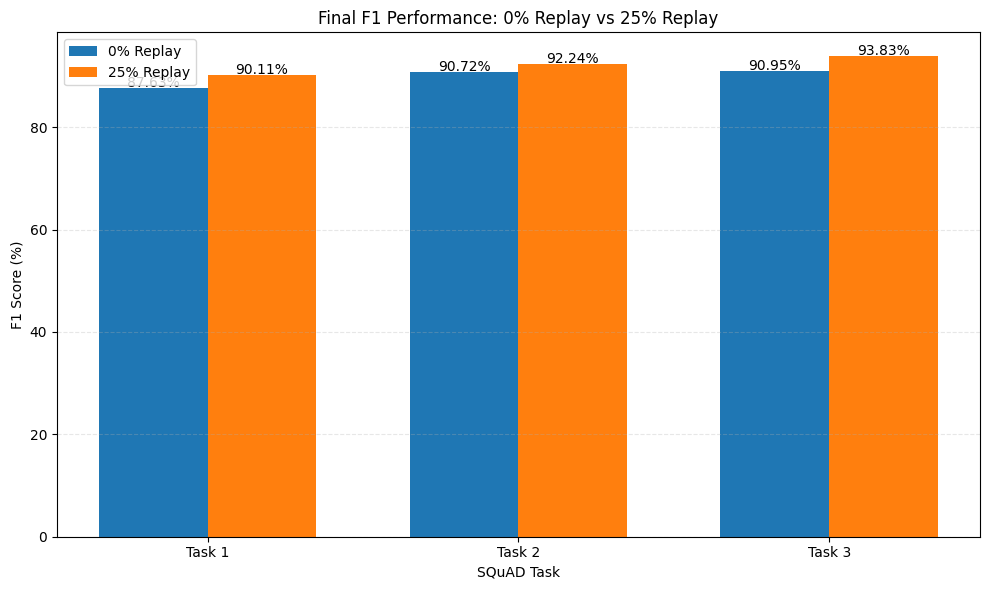

In [ ]:
# ============================================================
# CELL 72: F1 ACCURACY COMPARISON
# ============================================================
# This graph compares the final F1 score obtained by:
#   - 0% Replay (continual learning without replay)
#   - 25% Replay (continual learning with previous-task replay)
#
# The graph shows the performance on Task 1, Task 2 and Task 3.
# ============================================================

import matplotlib.pyplot as plt

# Task names
tasks = ["Task 1", "Task 2", "Task 3"]

# Final F1 scores obtained from our experiments
zero_replay = [87.63, 90.72, 90.95]
replay_25 = [90.11, 92.24, 93.83]

# Create positions for the tasks
x = range(len(tasks))

# Width of each bar
width = 0.35

# Create the figure
plt.figure(figsize=(10, 6))

# Plot 0% replay bars
plt.bar(
    [i - width / 2 for i in x],
    zero_replay,
    width=width,
    label="0% Replay"
)

# Plot 25% replay bars
plt.bar(
    [i + width / 2 for i in x],
    replay_25,
    width=width,
    label="25% Replay"
)

# Add the exact values above each bar
for i, value in enumerate(zero_replay):
    plt.text(
        i - width / 2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

for i, value in enumerate(replay_25):
    plt.text(
        i + width / 2,
        value + 0.2,
        f"{value:.2f}%",
        ha="center"
    )

# Add labels and title
plt.xlabel("SQuAD Task")
plt.ylabel("F1 Score (%)")
plt.title("Final F1 Performance: 0% Replay vs 25% Replay")

# Show task names on x-axis
plt.xticks(list(x), tasks)

# Add legend
plt.legend()

# Add a light grid for easier comparison
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Adjust layout
plt.tight_layout()

# Display the graph
plt.show()

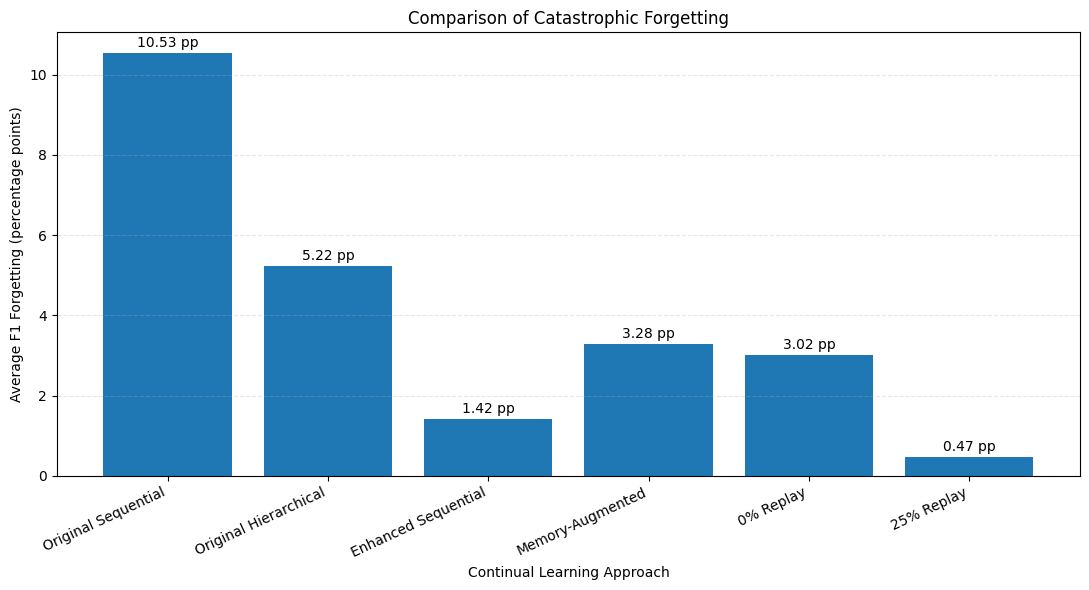

In [ ]:
# ============================================================
# CELL 73: CATASTROPHIC FORGETTING COMPARISON
# ============================================================
# This graph compares the average F1 forgetting of all the
# major approaches tested in our project.
#
# Lower forgetting is better.
# Therefore, the best method should have the smallest bar.
# ============================================================

import matplotlib.pyplot as plt

# Names of the approaches tested
methods = [
    "Original Sequential",
    "Original Hierarchical",
    "Enhanced Sequential",
    "Memory-Augmented",
    "0% Replay",
    "25% Replay"
]

# Average F1 forgetting in percentage points
forgetting = [
    10.53,
    5.22,
    1.42,
    3.28,
    3.02,
    0.47
]

# Create the graph
plt.figure(figsize=(11, 6))

# Create bars
bars = plt.bar(methods, forgetting)

# Add exact values above each bar
for bar, value in zip(bars, forgetting):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.15,
        f"{value:.2f} pp",
        ha="center"
    )

# Add labels and title
plt.xlabel("Continual Learning Approach")
plt.ylabel("Average F1 Forgetting (percentage points)")
plt.title("Comparison of Catastrophic Forgetting")

# Rotate method names so they are easy to read
plt.xticks(rotation=25, ha="right")

# Add horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Make the layout fit properly
plt.tight_layout()

# Display the graph
plt.show()

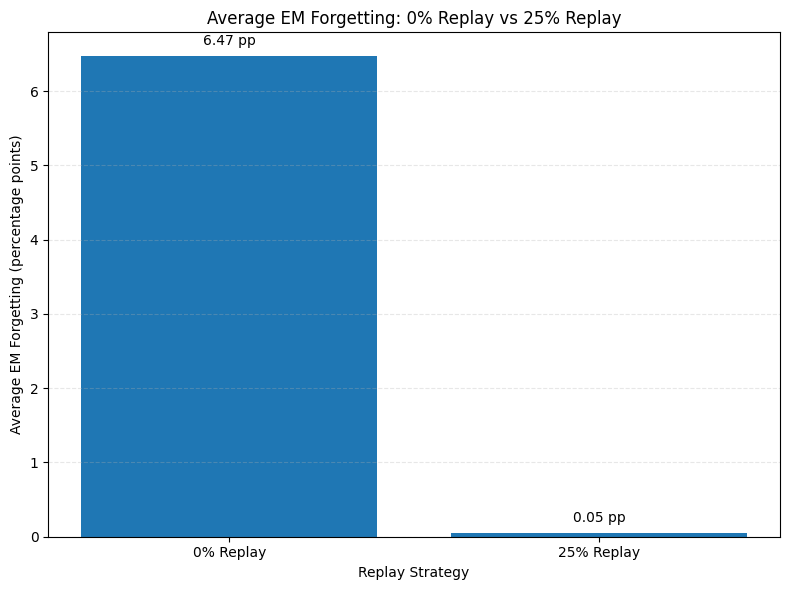

In [ ]:
# ============================================================
# CELL 74: EM FORGETTING COMPARISON
# ============================================================
# This graph compares the average Exact Match (EM) forgetting
# between the 0% replay control and the 25% replay approach.
#
# Lower forgetting is better.
# ============================================================

import matplotlib.pyplot as plt

# Two experimental conditions
methods = [
    "0% Replay",
    "25% Replay"
]

# Average EM forgetting obtained from our experiments
em_forgetting = [
    6.47,
    0.05
]

# Create the figure
plt.figure(figsize=(8, 6))

# Create the bars
bars = plt.bar(methods, em_forgetting)

# Add exact values above the bars
for bar, value in zip(bars, em_forgetting):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.15,
        f"{value:.2f} pp",
        ha="center"
    )

# Add labels and title
plt.xlabel("Replay Strategy")
plt.ylabel("Average EM Forgetting (percentage points)")
plt.title("Average EM Forgetting: 0% Replay vs 25% Replay")

# Add horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Adjust layout
plt.tight_layout()

# Display the graph
plt.show()

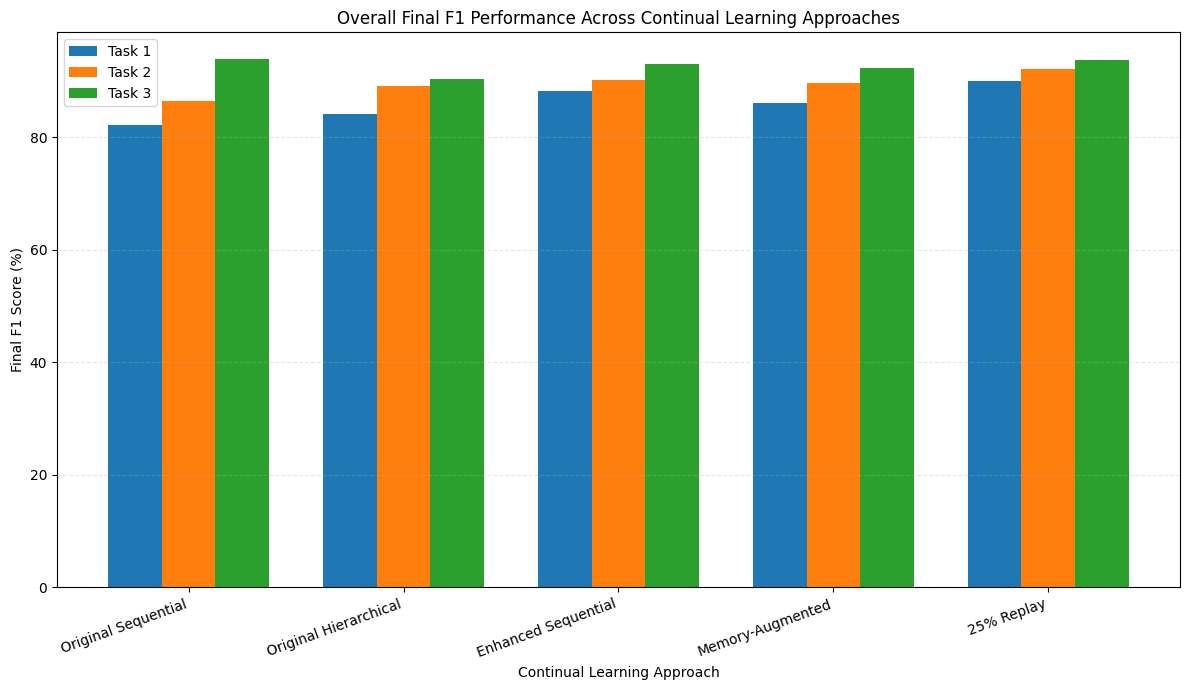

In [ ]:
# ============================================================
# CELL 75: OVERALL METHOD COMPARISON
# ============================================================
# This graph compares the final F1 performance of all major
# continual-learning approaches tested in the project.
#
# It allows us to see both:
#   - Task-wise performance
#   - Difference between the proposed approaches
# ============================================================

import matplotlib.pyplot as plt

# Names of the major approaches
methods = [
    "Original Sequential",
    "Original Hierarchical",
    "Enhanced Sequential",
    "Memory-Augmented",
    "25% Replay"
]

# Final Task 1 F1 scores
task1_f1 = [
    82.13,
    84.23,
    88.25,
    86.07,
    90.11
]

# Final Task 2 F1 scores
task2_f1 = [
    86.54,
    89.06,
    90.15,
    89.61,
    92.24
]

# Final Task 3 F1 scores
task3_f1 = [
    93.99,
    90.38,
    93.09,
    92.43,
    93.83
]

# Create positions for each method
x = range(len(methods))

# Width of each bar
width = 0.25

# Create the figure
plt.figure(figsize=(12, 7))

# Plot Task 1
plt.bar(
    [i - width for i in x],
    task1_f1,
    width=width,
    label="Task 1"
)

# Plot Task 2
plt.bar(
    x,
    task2_f1,
    width=width,
    label="Task 2"
)

# Plot Task 3
plt.bar(
    [i + width for i in x],
    task3_f1,
    width=width,
    label="Task 3"
)

# Add labels and title
plt.xlabel("Continual Learning Approach")
plt.ylabel("Final F1 Score (%)")
plt.title("Overall Final F1 Performance Across Continual Learning Approaches")

# Display approach names
plt.xticks(list(x), methods, rotation=20, ha="right")

# Add legend
plt.legend()

# Add horizontal grid
plt.grid(axis="y", linestyle="--", alpha=0.3)

# Adjust spacing
plt.tight_layout()

# Display the graph
plt.show()